# Open Science Engine (OSE)

## Day 1 — Research Foundation

### 1. Project Vision

Scientific research ko students aur independent researchers ke liye accessible banana, taaki limited budget aur computing resources mein bhi meaningful experiments kiye ja saken.

### 2. Research Question

Can intelligent or nature-inspired search find good solutions using fewer computational evaluations than simple Random Search on selected benchmark tasks?

### 3. Initial Objective Function

We will begin with the following mathematical function:

f(x, y) = x² + y²

The global minimum is 0 at (x, y) = (0, 0).

### 4. Research Hypotheses

**H1 — Fewer Evaluations:** Adaptive methods may reach a predefined target using fewer objective-function evaluations than Random Search on some benchmark functions.

**H2 — Nature-Inspired Optimization:** Particle Swarm Optimization (PSO) may outperform Random Search on some tasks, but performance can vary depending on the function and parameter settings.

**H3 — Workflow Efficiency:** Integrating literature retrieval, experiment configuration and reporting may reduce manual workflow time and improve reproducibility.

### 5. Initial Algorithms

1. Random Search — baseline method.
2. Particle Swarm Optimization (PSO) — nature-inspired method.
3. Bayesian Optimization — adaptive method.

### 6. Evaluation Metrics

* Best objective value.
* Number of evaluations needed to reach the target.
* Wall-clock runtime.
* Median and variability across independent runs.
* Success rate.

### 7. Initial Tools

Python, Google Colab, NumPy, SciPy, scikit-learn, Streamlit, OpenAlex and GitHub.

### 8. Day 1 Status

* [x] Objective function implemented.
* [x] Three test cases executed successfully.
* [x] Research question and hypotheses saved.
* [x] GitHub repository setup verified.


In [56]:
!git config --global user.name "24f3003340"
!git config --global user.email "24f3003340@ds.study.iitm.ac.in"

In [57]:
REPO_URL = "https://github.com/24f3003340/OSE.git"

!git clone {REPO_URL}

fatal: destination path 'OSE' already exists and is not an empty directory.


In [58]:
%cd OSE

/content/OSE/OSE


In [59]:

# Open Science Engine (OSE)
# Day 1: First Scientific Experiment

def objective(x, y):
    return x**2 + y**2

# Test the function
print("Test 1:", objective(0, 0))
print("Test 2:", objective(1, 2))
print("Test 3:", objective(-3, 4))

Test 1: 0
Test 2: 5
Test 3: 25


In [60]:

# OSE Day 1 — Repository Check

import os
import subprocess

os.chdir("/content/OSE")

print("Current folder:")
print(os.getcwd())

print("\nProject files:")
print(os.listdir("."))

print("\nGit remote:")
subprocess.run(["git", "remote", "-v"])

print("\nGit status:")
subprocess.run(["git", "status", "--short", "--branch"])

Current folder:
/content/OSE

Project files:
['OSE', 'tests', '.git', 'src', 'results']

Git remote:

Git status:


CompletedProcess(args=['git', 'status', '--short', '--branch'], returncode=0)

In [61]:

import os
import subprocess

os.chdir("/content/OSE")

print("Git repository check:")
result = subprocess.run(
    ["git", "rev-parse", "--is-inside-work-tree"],
    capture_output=True,
    text=True
)
print(result.stdout.strip() or result.stderr.strip())

print("\nConfigured remotes:")
result = subprocess.run(
    ["git", "remote", "-v"],
    capture_output=True,
    text=True
)
print(result.stdout.strip() or "No remote configured")

print("\nGit status:")
result = subprocess.run(
    ["git", "status", "--short", "--branch"],
    capture_output=True,
    text=True
)
print(result.stdout.strip() or result.stderr.strip())

Git repository check:
true

Configured remotes:
origin	https://github.com/24f3003340/OSE.git (fetch)
origin	https://github.com/24f3003340/OSE.git (push)

Git status:
## No commits yet on main...origin/main [gone]
?? OSE/
?? results/
?? src/


In [62]:

import os

os.chdir("/content/OSE")

# Create project folders
for folder in ["src", "results", "tests"]:
    os.makedirs(folder, exist_ok=True)

# Create the first scientific objective module
code = '''"""Objective functions for Open Science Engine."""

def sphere(x, y):
    """Calculate x^2 + y^2. Minimum is 0 at (0, 0)."""
    return x**2 + y**2
'''

with open("src/objectives.py", "w") as file:
    file.write(code)

print("Created: src/objectives.py")
print("Created folders: src, results, tests")

Created: src/objectives.py
Created folders: src, results, tests


In [63]:

import sys
import os

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

from src.objectives import sphere

print("Test 1:", sphere(0, 0))
print("Test 2:", sphere(1, 2))
print("Test 3:", sphere(-3, 4))

assert sphere(0, 0) == 0
assert sphere(1, 2) == 5
assert sphere(-3, 4) == 25

print("All tests passed!")

Test 1: 0
Test 2: 5
Test 3: 25
All tests passed!


Algorithm ki file banaiye

In [64]:

import os

os.chdir("/content/OSE")

code = '''"""Baseline optimization algorithms for OSE."""

import random


def random_search(objective, bounds=(-5, 5),
                  max_evaluations=5000,
                  target=0.1, seed=42):
    """Minimize a two-variable objective using random search."""

    rng = random.Random(seed)
    best_x, best_y = None, None
    best_value = float("inf")
    evaluations_to_target = None
    history = []

    for evaluation in range(1, max_evaluations + 1):
        x = rng.uniform(*bounds)
        y = rng.uniform(*bounds)

        value = objective(x, y)

        if value < best_value:
            best_x, best_y = x, y
            best_value = value

        history.append(best_value)

        if best_value <= target:
            evaluations_to_target = evaluation
            break

    return {
        "best_x": best_x,
        "best_y": best_y,
        "best_value": best_value,
        "evaluations": len(history),
        "evaluations_to_target": evaluations_to_target,
        "history": history,
        "seed": seed,
    }
'''

with open("src/optimizers.py", "w") as file:
    file.write(code)

print("Created: src/optimizers.py")

Created: src/optimizers.py


In [65]:

import os
import sys

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

from src.objectives import sphere
from src.optimizers import random_search

result = random_search(
    objective=sphere,
    bounds=(-5, 5),
    max_evaluations=5000,
    target=0.1,
    seed=42
)

print("Algorithm: Random Search")
print("Best x:", result["best_x"])
print("Best y:", result["best_y"])
print("Best objective value:", result["best_value"])
print("Evaluations performed:", result["evaluations"])
print("Evaluations to target:", result["evaluations_to_target"])
print("Target reached:", result["best_value"] <= 0.1)

Algorithm: Random Search
Best x: 0.2605944532217048
Best y: 0.07327696579786647
Best objective value: 0.073278982766461
Evaluations performed: 711
Evaluations to target: 711
Target reached: True


Experiment history saved.
Experiment summary saved.

Summary:
    algorithm  seed   best_x   best_y  best_value  evaluations  target  target_reached
Random Search    42 0.260594 0.073277    0.073279          711     0.1            True


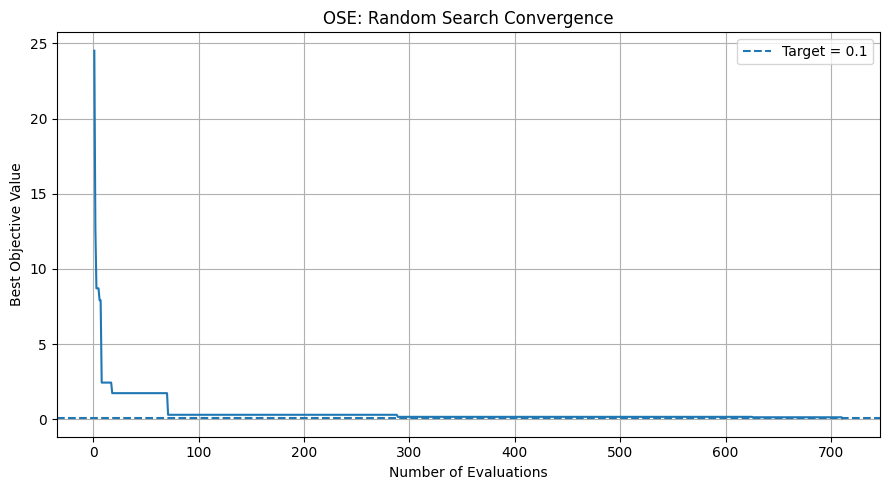

In [66]:

import os
import pandas as pd
import matplotlib.pyplot as plt

os.chdir("/content/OSE")
os.makedirs("results", exist_ok=True)

# Save best-so-far value after each evaluation
history_df = pd.DataFrame({
    "evaluation": range(1, len(result["history"]) + 1),
    "best_objective_value": result["history"]
})

history_df.to_csv(
    "results/random_search_history.csv",
    index=False
)

# Save experiment summary
summary_df = pd.DataFrame([{
    "algorithm": "Random Search",
    "seed": result["seed"],
    "best_x": result["best_x"],
    "best_y": result["best_y"],
    "best_value": result["best_value"],
    "evaluations": result["evaluations"],
    "target": 0.1,
    "target_reached": result["best_value"] <= 0.1
}])

summary_df.to_csv(
    "results/random_search_summary.csv",
    index=False
)

print("Experiment history saved.")
print("Experiment summary saved.")
print("\nSummary:")
print(summary_df.to_string(index=False))

# Plot best objective value versus evaluations
plt.figure(figsize=(9, 5))
plt.plot(
    history_df["evaluation"],
    history_df["best_objective_value"]
)
plt.axhline(
    y=0.1,
    linestyle="--",
    label="Target = 0.1"
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Best Objective Value")
plt.title("OSE: Random Search Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [67]:

import os
import sys
import pandas as pd

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

from src.objectives import sphere
from src.optimizers import random_search

seeds = [1, 2, 3, 4, 5, 42, 100, 123, 2026, 9999]
rows = []

for seed in seeds:
    result = random_search(
        objective=sphere,
        bounds=(-5, 5),
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    rows.append({
        "seed": seed,
        "best_value": result["best_value"],
        "evaluations": result["evaluations"],
        "target_reached": result["best_value"] <= 0.1
    })

df = pd.DataFrame(rows)

df.to_csv(
    "results/random_search_multi_seed.csv",
    index=False
)

print(df.to_string(index=False))
print("\nSuccess rate:",
      f"{df['target_reached'].mean() * 100:.1f}%")
print("Median evaluations:",
      df["evaluations"].median())
print("\nSaved: results/random_search_multi_seed.csv")

 seed  best_value  evaluations  target_reached
    1    0.024954           53            True
    2    0.033304           37            True
    3    0.060685          849            True
    4    0.013648          492            True
    5    0.062692          810            True
   42    0.073279          711            True
  100    0.022687           33            True
  123    0.080094          284            True
 2026    0.077087          291            True
 9999    0.073440          638            True

Success rate: 100.0%
Median evaluations: 391.5

Saved: results/random_search_multi_seed.csv


In [68]:

import os
import pandas as pd

os.chdir("/content/OSE")

# Load the results already generated
df = pd.read_csv("results/random_search_multi_seed.csv")

summary = pd.DataFrame([{
    "algorithm": "Random Search",
    "benchmark": "Sphere function",
    "total_runs": len(df),
    "successful_runs": int(df["target_reached"].sum()),
    "success_rate_percent": df["target_reached"].mean() * 100,
    "median_evaluations": df["evaluations"].median(),
    "mean_evaluations": df["evaluations"].mean(),
    "min_evaluations": df["evaluations"].min(),
    "max_evaluations": df["evaluations"].max()
}])

summary.to_csv(
    "results/random_search_baseline_report.csv",
    index=False
)

print(summary.to_string(index=False))
print("\nBaseline report saved successfully.")

    algorithm       benchmark  total_runs  successful_runs  success_rate_percent  median_evaluations  mean_evaluations  min_evaluations  max_evaluations
Random Search Sphere function          10               10                 100.0               391.5             419.8               33              849

Baseline report saved successfully.


In [69]:

import os

os.chdir("/content/OSE")

pso_code = '''

def particle_swarm_optimization(
    objective,
    bounds=(-5, 5),
    n_particles=20,
    max_evaluations=5000,
    target=0.1,
    seed=42,
    w=0.7,
    c1=1.5,
    c2=1.5
):
    """Minimize a two-variable objective using basic PSO."""
    import random

    rng = random.Random(seed)
    low, high = bounds
    span = high - low

    # Initialize particle positions and velocities
    positions = [
        [rng.uniform(low, high), rng.uniform(low, high)]
        for _ in range(n_particles)
    ]
    velocities = [
        [rng.uniform(-span * 0.1, span * 0.1),
         rng.uniform(-span * 0.1, span * 0.1)]
        for _ in range(n_particles)
    ]

    personal_best = [p[:] for p in positions]
    personal_values = [float("inf")] * n_particles

    global_best = None
    global_value = float("inf")
    history = []
    evaluations_to_target = None

    for i in range(n_particles):
        if len(history) >= max_evaluations:
            break

        value = objective(*positions[i])
        history.append(value)
        personal_values[i] = value

        if value < global_value:
            global_value = value
            global_best = positions[i][:]

        if global_value <= target:
            evaluations_to_target = len(history)
            break

    while (len(history) < max_evaluations
           and evaluations_to_target is None):

        for i in range(n_particles):
            if len(history) >= max_evaluations:
                break

            for d in range(2):
                r1 = rng.random()
                r2 = rng.random()

                velocities[i][d] = (
                    w * velocities[i][d]
                    + c1 * r1 * (
                        personal_best[i][d] - positions[i][d]
                    )
                    + c2 * r2 * (
                        global_best[d] - positions[i][d]
                    )
                )

                positions[i][d] += velocities[i][d]

                # Keep particles inside the search bounds
                positions[i][d] = max(
                    low, min(high, positions[i][d])
                )

            value = objective(*positions[i])
            history.append(value)

            if value < personal_values[i]:
                personal_values[i] = value
                personal_best[i] = positions[i][:]

            if value < global_value:
                global_value = value
                global_best = positions[i][:]

            if global_value <= target:
                evaluations_to_target = len(history)
                break

    # Convert raw values to best-so-far values
    best_so_far = []
    running_best = float("inf")

    for value in history:
        running_best = min(running_best, value)
        best_so_far.append(running_best)

    return {
        "best_x": global_best[0],
        "best_y": global_best[1],
        "best_value": global_value,
        "evaluations": len(history),
        "evaluations_to_target": evaluations_to_target,
        "history": best_so_far,
        "seed": seed
    }
'''

with open("src/optimizers.py", "a") as file:
    file.write(pso_code)

print("PSO function added to src/optimizers.py")

PSO function added to src/optimizers.py


In [70]:

import os
import sys

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

# Reload module to load the newly added function
import importlib
import src.optimizers as optimizers
importlib.reload(optimizers)

from src.objectives import sphere

result_pso = optimizers.particle_swarm_optimization(
    objective=sphere,
    bounds=(-5, 5),
    n_particles=20,
    max_evaluations=5000,
    target=0.1,
    seed=42
)

print("Algorithm: PSO")
print("Best x:", result_pso["best_x"])
print("Best y:", result_pso["best_y"])
print("Best objective value:", result_pso["best_value"])
print("Evaluations performed:", result_pso["evaluations"])
print("Evaluations to target:",
      result_pso["evaluations_to_target"])
print("Target reached:", result_pso["best_value"] <= 0.1)

Algorithm: PSO
Best x: 0.007696279571972109
Best y: -0.2008832154512281
Best objective value: 0.04041329896927448
Evaluations performed: 123
Evaluations to target: 123
Target reached: True


In [71]:

import os
import sys
import importlib
import pandas as pd

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

import src.optimizers as optimizers
importlib.reload(optimizers)

from src.objectives import sphere

seeds = [1, 2, 3, 4, 5, 42, 100, 123, 2026, 9999]
rows = []

for seed in seeds:
    # Random Search
    rs = optimizers.random_search(
        objective=sphere,
        bounds=(-5, 5),
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    rows.append({
        "algorithm": "Random Search",
        "seed": seed,
        "best_value": rs["best_value"],
        "evaluations": rs["evaluations"],
        "target_reached": rs["best_value"] <= 0.1
    })

    # Particle Swarm Optimization
    pso = optimizers.particle_swarm_optimization(
        objective=sphere,
        bounds=(-5, 5),
        n_particles=20,
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    rows.append({
        "algorithm": "PSO",
        "seed": seed,
        "best_value": pso["best_value"],
        "evaluations": pso["evaluations"],
        "target_reached": pso["best_value"] <= 0.1
    })

df_compare = pd.DataFrame(rows)

os.makedirs("results", exist_ok=True)
df_compare.to_csv(
    "results/algorithm_comparison.csv",
    index=False
)

summary = df_compare.groupby("algorithm").apply(
    lambda group: pd.Series({
        "runs": len(group),
        "success_rate_percent":
            100 * group["target_reached"].mean(),
        "median_evaluations_all_runs":
            group["evaluations"].median(),
        "median_evaluations_successful":
            group.loc[
                group["target_reached"], "evaluations"
            ].median(),
        "median_best_value":
            group["best_value"].median()
    }),
    include_groups=False
)

print("INDIVIDUAL RUNS")
print(df_compare.to_string(index=False))

print("\nSUMMARY")
print(summary.round(4).to_string())

print("\nSaved: results/algorithm_comparison.csv")

INDIVIDUAL RUNS
    algorithm  seed  best_value  evaluations  target_reached
Random Search     1    0.024954           53            True
          PSO     1    0.096488           35            True
Random Search     2    0.033304           37            True
          PSO     2    0.055356           72            True
Random Search     3    0.060685          849            True
          PSO     3    0.063179           24            True
Random Search     4    0.013648          492            True
          PSO     4    0.056636           87            True
Random Search     5    0.062692          810            True
          PSO     5    0.019462           72            True
Random Search    42    0.073279          711            True
          PSO    42    0.040413          123            True
Random Search   100    0.022687           33            True
          PSO   100    0.088454           53            True
Random Search   123    0.080094          284            True
        

COMPARISON SUMMARY
               median_evaluations  success_rate  median_best_value
algorithm                                                         
PSO                          63.0           1.0             0.0599
Random Search               391.5           1.0             0.0617


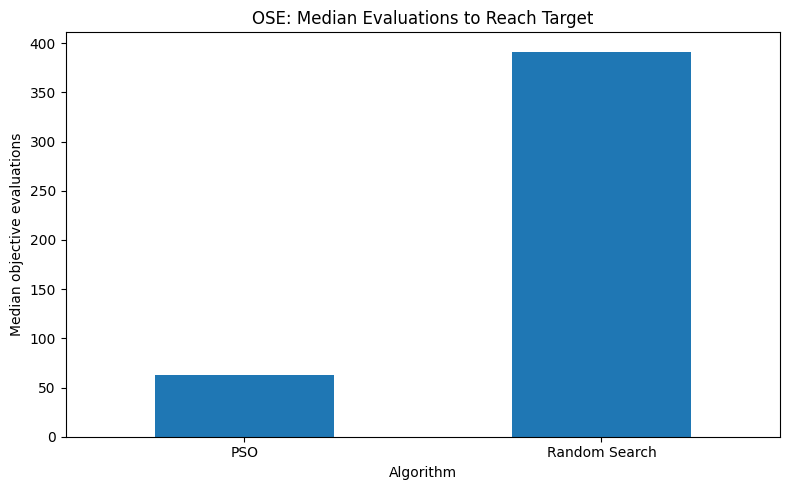

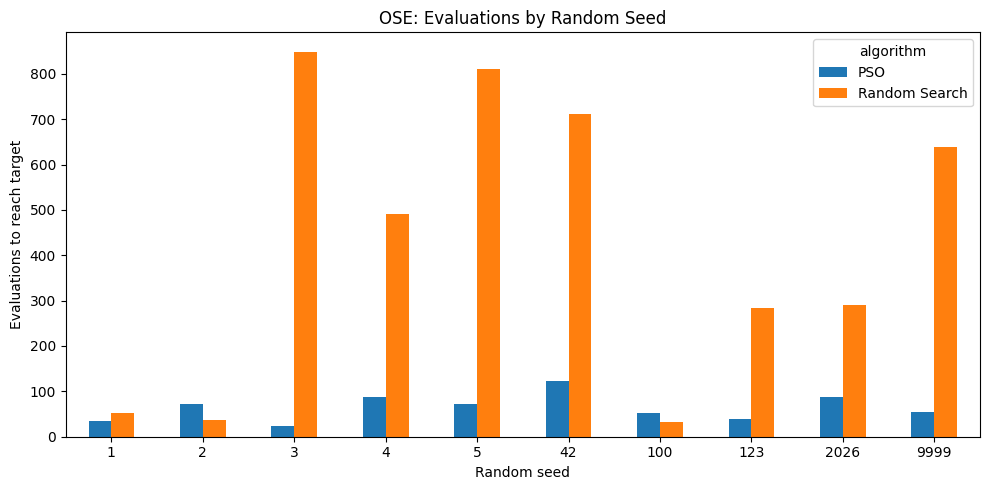


Saved:
results/median_evaluations_comparison.png
results/per_seed_comparison.png
results/experiment_001.md


In [72]:

import os
import pandas as pd
import matplotlib.pyplot as plt

os.chdir("/content/OSE")

df = pd.read_csv("results/algorithm_comparison.csv")
os.makedirs("results", exist_ok=True)

# 1. Median evaluations comparison
summary = df.groupby("algorithm").agg(
    median_evaluations=("evaluations", "median"),
    success_rate=("target_reached", "mean"),
    median_best_value=("best_value", "median")
)

print("COMPARISON SUMMARY")
print(summary.round(4))

ax = summary["median_evaluations"].plot(
    kind="bar",
    figsize=(8, 5),
    title="OSE: Median Evaluations to Reach Target"
)
ax.set_ylabel("Median objective evaluations")
ax.set_xlabel("Algorithm")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("results/median_evaluations_comparison.png", dpi=150)
plt.show()

# 2. Per-seed evaluation comparison
pivot = df.pivot(
    index="seed",
    columns="algorithm",
    values="evaluations"
)

ax = pivot.plot(
    kind="bar",
    figsize=(10, 5),
    title="OSE: Evaluations by Random Seed"
)
ax.set_ylabel("Evaluations to reach target")
ax.set_xlabel("Random seed")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/per_seed_comparison.png", dpi=150)
plt.show()

# 3. Save a research note
report = """# OSE Research Log — Experiment 001

## Research question
Can PSO reach a target using fewer objective evaluations than Random Search?

## Benchmark
Sphere function: f(x, y) = x^2 + y^2
Search bounds: [-5, 5]
Target: f(x, y) <= 0.1
Independent seeds: 10
Maximum evaluation budget: 5000 per run

## Results
Both algorithms achieved a 100% success rate across the 10 tested seeds.

Random Search median evaluations: 391.5
PSO median evaluations: 63
Random Search median best value: 0.0617
PSO median best value: 0.0599

PSO used approximately 83.9% fewer median evaluations in this experiment.

## Limitations
This is a preliminary comparison on one simple benchmark.
Results do not establish that PSO is better on all problems.
More benchmark functions, independent trials and runtime measurements are needed.
"""

with open("results/experiment_001.md", "w") as f:
    f.write(report)

print("\nSaved:")
print("results/median_evaluations_comparison.png")
print("results/per_seed_comparison.png")
print("results/experiment_001.md")

In [73]:

import os

os.chdir("/content/OSE")
os.makedirs("src", exist_ok=True)

code = '''"""Benchmark functions for Open Science Engine."""

import math


def sphere(x, y):
    """Global minimum: 0 at (0, 0)."""
    return x**2 + y**2


def rastrigin(x, y):
    """Global minimum: 0 at (0, 0)."""
    return (
        20
        + x**2 - 10 * math.cos(2 * math.pi * x)
        + y**2 - 10 * math.cos(2 * math.pi * y)
    )


def rosenbrock(x, y):
    """Global minimum: 0 at (1, 1)."""
    return (1 - x)**2 + 100 * (y - x**2)**2
'''

with open("src/objectives.py", "w") as f:
    f.write(code)

print("File updated successfully!")

with open("src/objectives.py", "r") as f:
    print(f.read())

File updated successfully!
"""Benchmark functions for Open Science Engine."""

import math


def sphere(x, y):
    """Global minimum: 0 at (0, 0)."""
    return x**2 + y**2


def rastrigin(x, y):
    """Global minimum: 0 at (0, 0)."""
    return (
        20
        + x**2 - 10 * math.cos(2 * math.pi * x)
        + y**2 - 10 * math.cos(2 * math.pi * y)
    )


def rosenbrock(x, y):
    """Global minimum: 0 at (1, 1)."""
    return (1 - x)**2 + 100 * (y - x**2)**2



In [74]:

import os
import sys
import importlib

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

import src.objectives as objectives
importlib.reload(objectives)

print("Sphere:", objectives.sphere(0, 0))
print("Rastrigin:", objectives.rastrigin(0, 0))
print("Rosenbrock:", objectives.rosenbrock(1, 1))

assert objectives.sphere(0, 0) == 0
assert abs(objectives.rastrigin(0, 0)) < 1e-10
assert objectives.rosenbrock(1, 1) == 0

print("All benchmark tests passed!")

Sphere: 0
Rastrigin: 0.0
Rosenbrock: 0
All benchmark tests passed!


In [75]:

import os
import sys
import importlib
import pandas as pd

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

import src.objectives as objectives
import src.optimizers as optimizers

importlib.reload(objectives)
importlib.reload(optimizers)

# Three benchmarks with their own bounds and targets
benchmarks = {
    "Sphere": {
        "function": objectives.sphere,
        "bounds": (-5, 5),
        "target": 0.1
    },
    "Rastrigin": {
        "function": objectives.rastrigin,
        "bounds": (-5.12, 5.12),
        "target": 1.0
    },
    "Rosenbrock": {
        "function": objectives.rosenbrock,
        "bounds": (-2, 2),
        "target": 1.0
    }
}

seeds = [1, 2, 3, 4, 5, 42, 100, 123, 2026, 9999]
rows = []

for benchmark_name, config in benchmarks.items():
    objective = config["function"]
    bounds = config["bounds"]
    target = config["target"]

    for seed in seeds:
        # Random Search
        rs = optimizers.random_search(
            objective=objective,
            bounds=bounds,
            max_evaluations=5000,
            target=target,
            seed=seed
        )

        rows.append({
            "benchmark": benchmark_name,
            "algorithm": "Random Search",
            "seed": seed,
            "target": target,
            "best_value": rs["best_value"],
            "evaluations": rs["evaluations"],
            "target_reached": rs["best_value"] <= target
        })

        # PSO
        pso = optimizers.particle_swarm_optimization(
            objective=objective,
            bounds=bounds,
            n_particles=20,
            max_evaluations=5000,
            target=target,
            seed=seed
        )

        rows.append({
            "benchmark": benchmark_name,
            "algorithm": "PSO",
            "seed": seed,
            "target": target,
            "best_value": pso["best_value"],
            "evaluations": pso["evaluations"],
            "target_reached": pso["best_value"] <= target
        })

# Save all individual runs
results = pd.DataFrame(rows)

os.makedirs("results", exist_ok=True)
results.to_csv(
    "results/multi_benchmark_results.csv",
    index=False
)

print("INDIVIDUAL RUNS")
print(results.to_string(index=False))

# Summarize each benchmark and algorithm
summary = results.groupby(
    ["benchmark", "algorithm"]
).agg(
    runs=("seed", "count"),
    success_rate=("target_reached", "mean"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median")
).reset_index()

summary["success_rate_percent"] = (
    summary["success_rate"] * 100
)

summary = summary.drop(columns=["success_rate"])

summary.to_csv(
    "results/multi_benchmark_summary.csv",
    index=False
)

print("\nSUMMARY")
print(summary.round(4).to_string(index=False))

print("\nSaved:")
print("results/multi_benchmark_results.csv")
print("results/multi_benchmark_summary.csv")

INDIVIDUAL RUNS
 benchmark     algorithm  seed  target  best_value  evaluations  target_reached
    Sphere Random Search     1     0.1    0.024954           53            True
    Sphere           PSO     1     0.1    0.096488           35            True
    Sphere Random Search     2     0.1    0.033304           37            True
    Sphere           PSO     2     0.1    0.055356           72            True
    Sphere Random Search     3     0.1    0.060685          849            True
    Sphere           PSO     3     0.1    0.063179           24            True
    Sphere Random Search     4     0.1    0.013648          492            True
    Sphere           PSO     4     0.1    0.056636           87            True
    Sphere Random Search     5     0.1    0.062692          810            True
    Sphere           PSO     5     0.1    0.019462           72            True
    Sphere Random Search    42     0.1    0.073279          711            True
    Sphere           PSO

Experiment 002

In [76]:

import os
import sys
import importlib
import pandas as pd

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

import src.objectives as objectives
import src.optimizers as optimizers

importlib.reload(objectives)
importlib.reload(optimizers)

# Experiment 002: stricter target evaluation
benchmarks = {
    "Sphere": {
        "function": objectives.sphere,
        "bounds": (-5, 5)
    },
    "Rastrigin": {
        "function": objectives.rastrigin,
        "bounds": (-5.12, 5.12)
    },
    "Rosenbrock": {
        "function": objectives.rosenbrock,
        "bounds": (-2, 2)
    }
}

seeds = [1, 2, 3, 4, 5, 42, 100, 123, 2026, 9999]
target = 0.1
max_evaluations = 5000

rows = []

for benchmark_name, config in benchmarks.items():
    objective = config["function"]
    bounds = config["bounds"]

    for seed in seeds:
        # Random Search
        rs = optimizers.random_search(
            objective=objective,
            bounds=bounds,
            max_evaluations=max_evaluations,
            target=target,
            seed=seed
        )

        rows.append({
            "benchmark": benchmark_name,
            "algorithm": "Random Search",
            "seed": seed,
            "target": target,
            "best_value": rs["best_value"],
            "evaluations": rs["evaluations"],
            "target_reached": rs["best_value"] <= target
        })

        # PSO
        pso = optimizers.particle_swarm_optimization(
            objective=objective,
            bounds=bounds,
            n_particles=20,
            max_evaluations=max_evaluations,
            target=target,
            seed=seed
        )

        rows.append({
            "benchmark": benchmark_name,
            "algorithm": "PSO",
            "seed": seed,
            "target": target,
            "best_value": pso["best_value"],
            "evaluations": pso["evaluations"],
            "target_reached": pso["best_value"] <= target
        })

results_002 = pd.DataFrame(rows)

# Preserve previous experiments; create new files
os.makedirs("results", exist_ok=True)

results_002.to_csv(
    "results/experiment_002_strict_results.csv",
    index=False
)

summary_002 = results_002.groupby(
    ["benchmark", "algorithm"]
).agg(
    runs=("seed", "count"),
    success_rate=("target_reached", "mean"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median")
).reset_index()

summary_002["success_rate_percent"] = (
    summary_002["success_rate"] * 100
)
summary_002 = summary_002.drop(columns=["success_rate"])

summary_002.to_csv(
    "results/experiment_002_strict_summary.csv",
    index=False
)

print("EXPERIMENT 002: INDIVIDUAL RESULTS")
print(results_002.to_string(index=False))

print("\nEXPERIMENT 002: SUMMARY")
print(summary_002.round(4).to_string(index=False))

print("\nSaved new files:")
print("results/experiment_002_strict_results.csv")
print("results/experiment_002_strict_summary.csv")

EXPERIMENT 002: INDIVIDUAL RESULTS
 benchmark     algorithm  seed  target  best_value  evaluations  target_reached
    Sphere Random Search     1     0.1    0.024954           53            True
    Sphere           PSO     1     0.1    0.096488           35            True
    Sphere Random Search     2     0.1    0.033304           37            True
    Sphere           PSO     2     0.1    0.055356           72            True
    Sphere Random Search     3     0.1    0.060685          849            True
    Sphere           PSO     3     0.1    0.063179           24            True
    Sphere Random Search     4     0.1    0.013648          492            True
    Sphere           PSO     4     0.1    0.056636           87            True
    Sphere Random Search     5     0.1    0.062692          810            True
    Sphere           PSO     5     0.1    0.019462           72            True
    Sphere Random Search    42     0.1    0.073279          711            True
    S

EXPERIMENT COMPARISON
    experiment  benchmark     algorithm  success_rate  median_evaluations  median_best_value  success_rate_percent
Experiment 001  Rastrigin           PSO           1.0               537.0             0.8079                 100.0
Experiment 001  Rastrigin Random Search           0.5              3725.0             0.9816                  50.0
Experiment 001 Rosenbrock           PSO           1.0                43.5             0.6349                 100.0
Experiment 001 Rosenbrock Random Search           1.0                27.5             0.3289                 100.0
Experiment 001     Sphere           PSO           1.0                63.0             0.0599                 100.0
Experiment 001     Sphere Random Search           1.0               391.5             0.0617                 100.0
Experiment 002  Rastrigin           PSO           1.0               775.0             0.0596                 100.0
Experiment 002  Rastrigin Random Search           0.1     

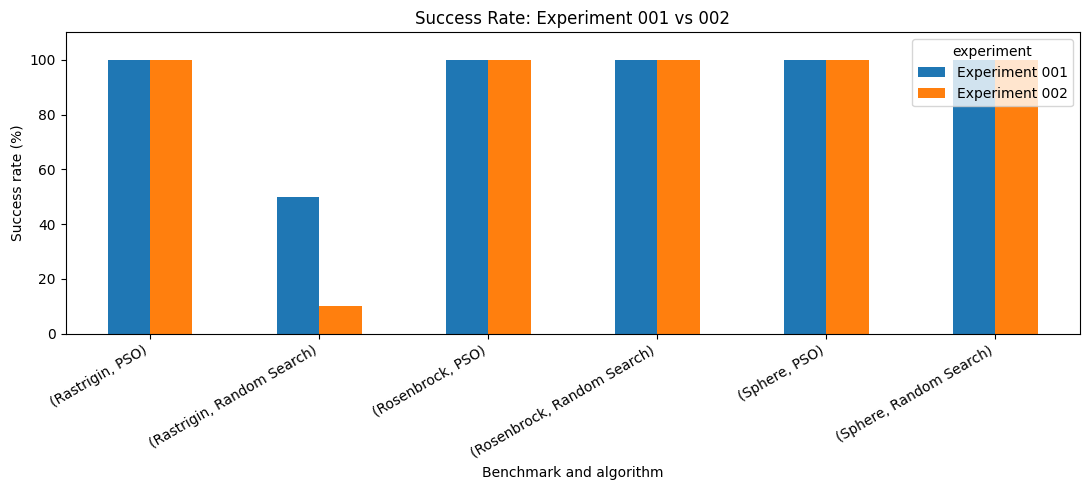

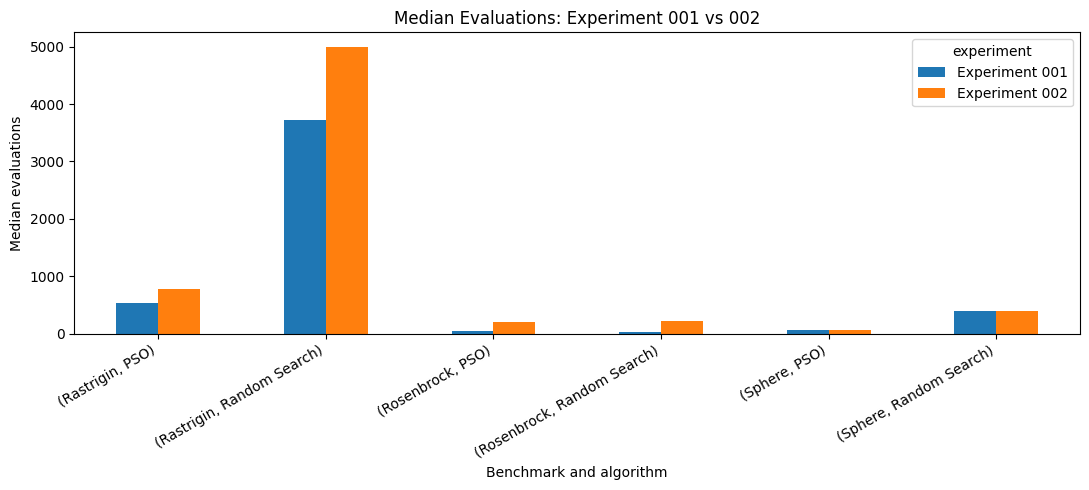


Comparison summary and graphs saved.


In [77]:

import os
import pandas as pd
import matplotlib.pyplot as plt

os.chdir("/content/OSE")

# Load the two experiments
old = pd.read_csv("results/multi_benchmark_results.csv")
new = pd.read_csv("results/experiment_002_strict_results.csv")

old["experiment"] = "Experiment 001"
new["experiment"] = "Experiment 002"

combined = pd.concat([old, new], ignore_index=True)

# Summarize each experiment
summary = combined.groupby(
    ["experiment", "benchmark", "algorithm"]
).agg(
    success_rate=("target_reached", "mean"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median")
).reset_index()

summary["success_rate_percent"] = (
    summary["success_rate"] * 100
)

summary.to_csv(
    "results/experiment_001_vs_002_summary.csv",
    index=False
)

print("EXPERIMENT COMPARISON")
print(summary.round(4).to_string(index=False))

# Plot success rates
success = summary.pivot(
    index=["benchmark", "algorithm"],
    columns="experiment",
    values="success_rate_percent"
)

ax = success.plot(
    kind="bar",
    figsize=(11, 5),
    title="Success Rate: Experiment 001 vs 002"
)
ax.set_ylabel("Success rate (%)")
ax.set_xlabel("Benchmark and algorithm")
ax.set_ylim(0, 110)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    "results/experiment_success_rate_comparison.png",
    dpi=150
)
plt.show()

# Plot median evaluations
evals = summary.pivot(
    index=["benchmark", "algorithm"],
    columns="experiment",
    values="median_evaluations"
)

ax = evals.plot(
    kind="bar",
    figsize=(11, 5),
    title="Median Evaluations: Experiment 001 vs 002"
)
ax.set_ylabel("Median evaluations")
ax.set_xlabel("Benchmark and algorithm")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    "results/experiment_evaluations_comparison.png",
    dpi=150
)
plt.show()

print("\nComparison summary and graphs saved.")

# OSE Research Log — Experiment 002

**Title:** Stricter Target Evaluation for Random Search and PSO

**Research question:** How does performance change when the target is tightened to an objective value of 0.1?

**Experimental setup**

* Benchmarks: Sphere, Rastrigin, Rosenbrock
* Algorithms: Random Search and Particle Swarm Optimization
* Independent seeds: 10 per algorithm and benchmark
* Evaluation budget: 5,000 per run
* Target: objective value ≤ 0.1

**Results**

* Sphere: both algorithms achieved 100% success. Median evaluations were 63 for PSO and 391.5 for Random Search.
* Rastrigin: PSO achieved 100% success, while Random Search achieved 10%. Median evaluations were 775 for PSO and 5,000 for Random Search.
* Rosenbrock: both algorithms achieved 100% success. Median evaluations were 197 for PSO and 212 for Random Search.

**Preliminary conclusion**

PSO showed a substantial advantage on Sphere and Rastrigin under these experimental settings. On Rosenbrock, the median evaluation counts were relatively close, with PSO requiring slightly fewer evaluations.

**Limitations**

* Only three two-dimensional benchmark functions were tested.
* Results are based on 10 seeds per configuration.
* Algorithms have not been systematically tuned.
* These results do not establish universal superiority of PSO.
* Wall-clock runtime and statistical uncertainty have not yet been evaluated.

**Output files**

* `results/experiment_002_strict_results.csv`
* `results/experiment_002_strict_summary.csv`


Experiment 003

In [78]:

import os
import sys
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

os.chdir("/content/OSE")

if "/content/OSE" not in sys.path:
    sys.path.insert(0, "/content/OSE")

from src import objectives, optimizers
importlib.reload(objectives)
importlib.reload(optimizers)

from src.objectives import sphere, rastrigin, rosenbrock
from src.optimizers import random_search, particle_swarm_optimization

print("OSE Experiment 003: Statistical Reliability Test")
print("Imports successful!")

OSE Experiment 003: Statistical Reliability Test
Imports successful!


In [79]:

import os
import pandas as pd
import numpy as np

os.chdir("/content/OSE")

benchmarks = {
    "Sphere": {
        "function": sphere,
        "bounds": (-5, 5)
    },
    "Rastrigin": {
        "function": rastrigin,
        "bounds": (-5.12, 5.12)
    },
    "Rosenbrock": {
        "function": rosenbrock,
        "bounds": (-2, 2)
    }
}

seeds = list(range(1, 31))
max_evaluations = 5000
target = 0.1

records = []

for benchmark_name, config in benchmarks.items():
    objective = config["function"]
    bounds = config["bounds"]

    for seed in seeds:
        for algorithm_name, algorithm in [
            ("Random Search", random_search),
            ("PSO", particle_swarm_optimization)
        ]:
            result = algorithm(
                objective=objective,
                bounds=bounds,
                max_evaluations=max_evaluations,
                target=target,
                seed=seed
            )

            records.append({
                "benchmark": benchmark_name,
                "algorithm": algorithm_name,
                "seed": seed,
                "best_x": result["best_x"],
                "best_y": result["best_y"],
                "best_value": result["best_value"],
                "evaluations": result["evaluations"],
                "target_reached": (
                    result["best_value"] <= target
                )
            })

results_003 = pd.DataFrame(records)

os.makedirs("results", exist_ok=True)

results_003.to_csv(
    "results/experiment_003_reliability_results.csv",
    index=False
)

print("Experiment 003 complete!")
print("Total runs:", len(results_003))
print("\nFirst five rows:")
print(results_003.head().to_string(index=False))

Experiment 003 complete!
Total runs: 180

First five rows:
benchmark     algorithm  seed    best_x    best_y  best_value  evaluations  target_reached
   Sphere Random Search     1  0.047205 -0.150749    0.024954           53            True
   Sphere           PSO     1  0.012183 -0.310386    0.096488           35            True
   Sphere Random Search     2  0.042488  0.177478    0.033304           37            True
   Sphere           PSO     2 -0.188492 -0.140806    0.055356           72            True
   Sphere Random Search     3  0.230266 -0.087538    0.060685          849            True


In [80]:
%pip install statsmodels pandas numpy scipy

In [81]:

summary_003 = results_003.groupby(
    ["benchmark", "algorithm"]
).agg(
    runs=("seed", "count"),
    success_rate=("target_reached", "mean"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median"),
    mean_best_value=("best_value", "mean"),
    std_best_value=("best_value", "std")
).reset_index()

summary_003["success_rate_percent"] = (
    summary_003["success_rate"] * 100
)

summary_003.to_csv(
    "results/experiment_003_reliability_summary.csv",
    index=False
)

print(summary_003.round(4).to_string(index=False))

 benchmark     algorithm  runs  success_rate  median_evaluations  median_best_value  mean_best_value  std_best_value  success_rate_percent
 Rastrigin           PSO    30        0.9667               671.5             0.0724           0.0907          0.1736               96.6667
 Rastrigin Random Search    30        0.0000              5000.0             0.9672           0.9217          0.3894                0.0000
Rosenbrock           PSO    30        1.0000               170.0             0.0753           0.0683          0.0237              100.0000
Rosenbrock Random Search    30        1.0000               198.5             0.0442           0.0474          0.0294              100.0000
    Sphere           PSO    30        1.0000                64.5             0.0488           0.0458          0.0268              100.0000
    Sphere Random Search    30        1.0000               164.5             0.0376           0.0415          0.0260              100.0000


In [82]:

import os
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

os.chdir("/content/OSE")

results = pd.read_csv(
    "results/experiment_003_reliability_results.csv"
)

# 1. Failed runs identify karo
failed_runs = results[results["target_reached"] == False]

print("FAILED RUNS")
if failed_runs.empty:
    print("No failed runs.")
else:
    print(failed_runs[
        ["benchmark", "algorithm", "seed",
         "best_value", "evaluations"]
    ].to_string(index=False))

# 2. 95% Wilson confidence intervals
rows = []

for (benchmark, algorithm), group in results.groupby(
    ["benchmark", "algorithm"]
):
    successes = int(group["target_reached"].sum())
    total = len(group)

    lower, upper = proportion_confint(
        count=successes,
        nobs=total,
        alpha=0.05,
        method="wilson"
    )

    rows.append({
        "benchmark": benchmark,
        "algorithm": algorithm,
        "successes": successes,
        "total_runs": total,
        "success_rate_percent": 100 * successes / total,
        "ci_95_lower_percent": 100 * lower,
        "ci_95_upper_percent": 100 * upper
    })

ci_summary = pd.DataFrame(rows)

ci_summary.to_csv(
    "results/experiment_004_confidence_intervals.csv",
    index=False
)

print("\n95% WILSON CONFIDENCE INTERVALS")
print(ci_summary.round(2).to_string(index=False))

FAILED RUNS
benchmark     algorithm  seed  best_value  evaluations
Rastrigin Random Search     1    1.589487         5000
Rastrigin Random Search     2    1.034804         5000
Rastrigin Random Search     3    0.215609         5000
Rastrigin Random Search     4    0.960274         5000
Rastrigin Random Search     5    1.253062         5000
Rastrigin Random Search     6    0.978970         5000
Rastrigin Random Search     7    0.654586         5000
Rastrigin Random Search     8    1.128616         5000
Rastrigin Random Search     9    1.058344         5000
Rastrigin Random Search    10    1.417856         5000
Rastrigin Random Search    11    0.183664         5000
Rastrigin Random Search    12    0.908823         5000
Rastrigin Random Search    13    1.110880         5000
Rastrigin Random Search    14    0.939636         5000
Rastrigin Random Search    15    1.144305         5000
Rastrigin Random Search    16    0.653069         5000
Rastrigin Random Search    17    1.004752         500

In [83]:

import os
import pandas as pd

os.chdir("/content/OSE")

from src.objectives import rastrigin
from src.optimizers import particle_swarm_optimization

failed_seed_result = particle_swarm_optimization(
    objective=rastrigin,
    bounds=(-5.12, 5.12),
    max_evaluations=5000,
    target=0.1,
    seed=22
)

print("FAILED PSO RUN: RASTRIGIN")
print("Seed:", failed_seed_result["seed"])
print("Best x:", failed_seed_result["best_x"])
print("Best y:", failed_seed_result["best_y"])
print("Best objective value:", failed_seed_result["best_value"])
print("Evaluations:", failed_seed_result["evaluations"])
print("Target reached:",
      failed_seed_result["best_value"] <= 0.1)

FAILED PSO RUN: RASTRIGIN
Seed: 22
Best x: 0.9949586388572376
Best y: -9.485496651207155e-10
Best objective value: 0.9949590570932898
Evaluations: 5000
Target reached: False


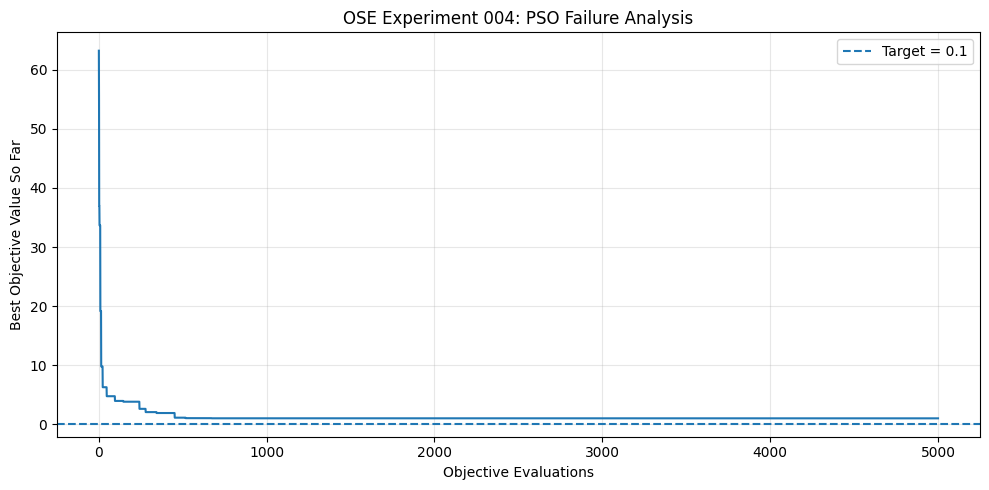

Initial best value: 63.24550271970944
Final best value: 0.9949590570932898
History length: 5000


In [84]:

import os
import matplotlib.pyplot as plt

os.chdir("/content/OSE")

history = failed_seed_result["history"]

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(history) + 1), history)
plt.axhline(
    y=0.1,
    linestyle="--",
    label="Target = 0.1"
)
plt.xlabel("Objective Evaluations")
plt.ylabel("Best Objective Value So Far")
plt.title("OSE Experiment 004: PSO Failure Analysis")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

os.makedirs("results", exist_ok=True)
plt.savefig(
    "results/experiment_004_failed_pso_trajectory.png",
    dpi=150
)
plt.show()

print("Initial best value:", history[0])
print("Final best value:", history[-1])
print("History length:", len(history))

In [85]:

import random
import math

def restart_pso(
    objective,
    bounds=(-5.12, 5.12),
    n_particles=20,
    max_evaluations=5000,
    target=0.1,
    seed=42,
    w=0.7,
    c1=1.5,
    c2=1.5,
    stagnation_limit=250,
    restart_fraction=0.3
):
    """PSO variant that randomly restarts particles after stagnation."""
    rng = random.Random(seed)
    low, high = bounds
    span = high - low

    positions = [
        [rng.uniform(low, high), rng.uniform(low, high)]
        for _ in range(n_particles)
    ]
    velocities = [
        [rng.uniform(-0.1 * span, 0.1 * span),
         rng.uniform(-0.1 * span, 0.1 * span)]
        for _ in range(n_particles)
    ]

    personal_best = [p[:] for p in positions]
    personal_values = [float("inf")] * n_particles
    global_best = None
    global_value = float("inf")
    history = []
    stagnation = 0
    evaluations_to_target = None

    for i in range(n_particles):
        if len(history) >= max_evaluations:
            break

        value = objective(*positions[i])
        history.append(value)
        personal_values[i] = value

        if value < global_value:
            global_value = value
            global_best = positions[i][:]
            stagnation = 0
        else:
            stagnation += 1

        if global_value <= target:
            evaluations_to_target = len(history)
            break

    while (
        len(history) < max_evaluations
        and evaluations_to_target is None
    ):
        for i in range(n_particles):
            if len(history) >= max_evaluations:
                break

            old_global_value = global_value

            for d in range(2):
                r1, r2 = rng.random(), rng.random()
                velocities[i][d] = (
                    w * velocities[i][d]
                    + c1 * r1 * (
                        personal_best[i][d] - positions[i][d]
                    )
                    + c2 * r2 * (
                        global_best[d] - positions[i][d]
                    )
                )
                positions[i][d] += velocities[i][d]
                positions[i][d] = max(
                    low, min(high, positions[i][d])
                )

            value = objective(*positions[i])
            history.append(value)

            if value < personal_values[i]:
                personal_values[i] = value
                personal_best[i] = positions[i][:]

            if value < global_value:
                global_value = value
                global_best = positions[i][:]
                stagnation = 0
            else:
                stagnation += 1

            if global_value <= target:
                evaluations_to_target = len(history)
                break

            if stagnation >= stagnation_limit:
                # Preserve the best particle; restart some others.
                n_restart = max(
                    1, int(n_particles * restart_fraction)
                )
                ranked = sorted(
                    range(n_particles),
                    key=lambda j: personal_values[j]
                )
                restart_indices = ranked[-n_restart:]

                for j in restart_indices:
                    positions[j] = [
                        rng.uniform(low, high),
                        rng.uniform(low, high)
                    ]
                    velocities[j] = [
                        rng.uniform(-0.1 * span, 0.1 * span),
                        rng.uniform(-0.1 * span, 0.1 * span)
                    ]
                    personal_best[j] = positions[j][:]
                    personal_values[j] = float("inf")

                stagnation = 0

    best_so_far = []
    running_best = float("inf")
    for value in history:
        running_best = min(running_best, value)
        best_so_far.append(running_best)

    return {
        "best_x": global_best[0],
        "best_y": global_best[1],
        "best_value": global_value,
        "evaluations": len(history),
        "evaluations_to_target": evaluations_to_target,
        "history": best_so_far,
        "seed": seed
    }

print("Restart PSO function defined.")

Restart PSO function defined.


In [86]:

from src.objectives import rastrigin
from src.optimizers import particle_swarm_optimization

original = particle_swarm_optimization(
    objective=rastrigin,
    bounds=(-5.12, 5.12),
    max_evaluations=5000,
    target=0.1,
    seed=22
)

restarted = restart_pso(
    objective=rastrigin,
    bounds=(-5.12, 5.12),
    max_evaluations=5000,
    target=0.1,
    seed=22
)

print("Original PSO best value:", original["best_value"])
print("Restart PSO best value:", restarted["best_value"])
print("Original evaluations:", original["evaluations"])
print("Restart evaluations:", restarted["evaluations"])
print("Restart PSO reached target:",
      restarted["best_value"] <= 0.1)

Original PSO best value: 0.9949590570932898
Restart PSO best value: 0.09548624806947537
Original evaluations: 5000
Restart evaluations: 2248
Restart PSO reached target: True


In [87]:

import os
import pandas as pd

os.chdir("/content/OSE")

from src.objectives import rastrigin
from src.optimizers import random_search, particle_swarm_optimization

comparison_records = []

for seed in range(1, 31):
    algorithms = {
        "Random Search": lambda: random_search(
            objective=rastrigin,
            bounds=(-5.12, 5.12),
            max_evaluations=5000,
            target=0.1,
            seed=seed
        ),
        "Original PSO": lambda: particle_swarm_optimization(
            objective=rastrigin,
            bounds=(-5.12, 5.12),
            max_evaluations=5000,
            target=0.1,
            seed=seed
        ),
        "Restart PSO": lambda: restart_pso(
            objective=rastrigin,
            bounds=(-5.12, 5.12),
            max_evaluations=5000,
            target=0.1,
            seed=seed
        )
    }

    for algorithm_name, run_algorithm in algorithms.items():
        result = run_algorithm()

        comparison_records.append({
            "seed": seed,
            "algorithm": algorithm_name,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "target_reached": (
                result["best_value"] <= 0.1
            )
        })

comparison = pd.DataFrame(comparison_records)

comparison.to_csv(
    "results/experiment_005_restart_pso_comparison.csv",
    index=False
)

summary = comparison.groupby("algorithm").agg(
    runs=("seed", "count"),
    success_rate=("target_reached", "mean"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median"),
    mean_best_value=("best_value", "mean"),
    std_best_value=("best_value", "std")
).reset_index()

summary["success_rate_percent"] = (
    100 * summary["success_rate"]
)

summary.to_csv(
    "results/experiment_005_restart_pso_summary.csv",
    index=False
)

print("EXPERIMENT 005: RASTRIGIN COMPARISON")
print(summary.round(4).to_string(index=False))

EXPERIMENT 005: RASTRIGIN COMPARISON
    algorithm  runs  success_rate  median_evaluations  median_best_value  mean_best_value  std_best_value  success_rate_percent
 Original PSO    30        0.9667               671.5             0.0724           0.0907          0.1736               96.6667
Random Search    30        0.0000              5000.0             0.9672           0.9217          0.3894                0.0000
  Restart PSO    30        1.0000               633.5             0.0626           0.0587          0.0306              100.0000


Experiment 006

SUCCESS RATE AND 95% WILSON CONFIDENCE INTERVALS
Original PSO: 29/30 successful (96.67%), 95% CI = [83.33%, 99.41%]
Restart PSO: 30/30 successful (100.00%), 95% CI = [88.65%, 100.00%]

PAIRED BEST-VALUE COMPARISON
Seeds where Restart PSO was better: 5
Seeds where Original PSO was better: 4
Tied seeds: 21
Median original best value: 0.07244023327070165
Median restart best value: 0.06259132130024089
Median paired improvement (original - restart): 0.0

WILCOXON SIGNED-RANK TEST
H1: Original PSO values are higher than Restart PSO values
Statistic: 29.0
p-value: 0.248046875

PAIRED SUCCESS COMPARISON
Only Original PSO succeeded: 0
Only Restart PSO succeeded: 1
One-sided exact paired test p-value: 0.5


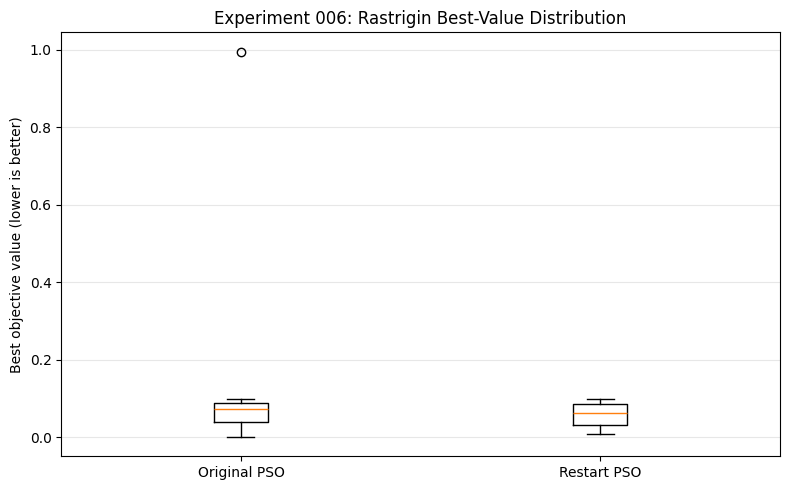


Experiment 006 analysis complete.
New files saved; original experiment data unchanged.


In [88]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, binomtest
from statsmodels.stats.proportion import proportion_confint

os.chdir("/content/OSE")

# Experiment 005 ka existing data load karo
data = pd.read_csv(
    "results/experiment_005_restart_pso_comparison.csv"
)

# Original PSO aur Restart PSO ko same seed par pair karo
original = (
    data[data["algorithm"] == "Original PSO"]
    .set_index("seed")
    .sort_index()
)

restart = (
    data[data["algorithm"] == "Restart PSO"]
    .set_index("seed")
    .sort_index()
)

assert original.index.equals(restart.index), (
    "Seed matching error: paired comparison possible nahi hai."
)

assert len(original) == 30, "Expected 30 paired seeds."

# 1. Success-rate confidence intervals
print("SUCCESS RATE AND 95% WILSON CONFIDENCE INTERVALS")

for name, group in [
    ("Original PSO", original),
    ("Restart PSO", restart)
]:
    successes = int(group["target_reached"].sum())
    total = len(group)

    lower, upper = proportion_confint(
        successes, total, alpha=0.05, method="wilson"
    )

    print(
        f"{name}: {successes}/{total} successful "
        f"({100*successes/total:.2f}%), "
        f"95% CI = [{100*lower:.2f}%, {100*upper:.2f}%]"
    )

# 2. Paired best-value comparison
# Lower objective value is better.
differences = (
    original["best_value"] - restart["best_value"]
)

print("\nPAIRED BEST-VALUE COMPARISON")
print("Seeds where Restart PSO was better:",
      int((differences > 0).sum()))
print("Seeds where Original PSO was better:",
      int((differences < 0).sum()))
print("Tied seeds:", int((differences == 0).sum()))
print("Median original best value:",
      original["best_value"].median())
print("Median restart best value:",
      restart["best_value"].median())
print("Median paired improvement (original - restart):",
      differences.median())

# Wilcoxon signed-rank test
# Remove exact ties for the paired difference test.
nonzero = differences[differences != 0]

if len(nonzero) > 0:
    test = wilcoxon(
        nonzero,
        alternative="greater",
        method="auto"
    )
    print("\nWILCOXON SIGNED-RANK TEST")
    print("H1: Original PSO values are higher than Restart PSO values")
    print("Statistic:", test.statistic)
    print("p-value:", test.pvalue)
else:
    print("\nAll paired values are tied; Wilcoxon test not informative.")

# 3. Paired success outcomes: exact McNemar-style binomial test
orig_success = original["target_reached"].astype(bool)
rest_success = restart["target_reached"].astype(bool)

orig_only = int((orig_success & ~rest_success).sum())
restart_only = int((~orig_success & rest_success).sum())
discordant = orig_only + restart_only

print("\nPAIRED SUCCESS COMPARISON")
print("Only Original PSO succeeded:", orig_only)
print("Only Restart PSO succeeded:", restart_only)

if discordant > 0:
    success_test = binomtest(
        restart_only,
        n=discordant,
        p=0.5,
        alternative="greater"
    )
    print("One-sided exact paired test p-value:",
          success_test.pvalue)
else:
    print("No discordant success outcomes; no difference to test.")

# 4. Save paired comparison data separately
paired = pd.DataFrame({
    "seed": original.index,
    "original_best_value": original["best_value"].values,
    "restart_best_value": restart["best_value"].values,
    "original_success": orig_success.values,
    "restart_success": rest_success.values,
    "original_evaluations": original["evaluations"].values,
    "restart_evaluations": restart["evaluations"].values
})

paired.to_csv(
    "results/experiment_006_paired_comparison.csv",
    index=False
)

# 5. Boxplot
plt.figure(figsize=(8, 5))
plt.boxplot(
    [
        original["best_value"].values,
        restart["best_value"].values
    ],
    tick_labels=["Original PSO", "Restart PSO"]
)
plt.ylabel("Best objective value (lower is better)")
plt.title("Experiment 006: Rastrigin Best-Value Distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "results/experiment_006_best_value_boxplot.png",
    dpi=150
)
plt.show()

print("\nExperiment 006 analysis complete.")
print("New files saved; original experiment data unchanged.")

Experiment 007

In [89]:

import random
import math

def restart_pso_logged(
    objective,
    bounds=(-5.12, 5.12),
    n_particles=20,
    max_evaluations=5000,
    target=0.1,
    seed=42,
    w=0.7,
    c1=1.5,
    c2=1.5,
    stagnation_limit=250,
    restart_fraction=0.3
):
    """Restart PSO with logs for restart events."""
    rng = random.Random(seed)
    low, high = bounds
    span = high - low

    positions = [
        [rng.uniform(low, high), rng.uniform(low, high)]
        for _ in range(n_particles)
    ]
    velocities = [
        [rng.uniform(-0.1 * span, 0.1 * span),
         rng.uniform(-0.1 * span, 0.1 * span)]
        for _ in range(n_particles)
    ]

    personal_best = [p[:] for p in positions]
    personal_values = [float("inf")] * n_particles
    global_best = None
    global_value = float("inf")
    history = []
    events = []
    stagnation = 0
    evaluations_to_target = None
    event_start_eval = 0

    # Evaluate initial particles
    for i in range(n_particles):
        if len(history) >= max_evaluations:
            break

        value = objective(*positions[i])
        history.append(value)
        personal_values[i] = value

        if value < global_value:
            global_value = value
            global_best = positions[i][:]
            stagnation = 0
        else:
            stagnation += 1

        if global_value <= target:
            evaluations_to_target = len(history)
            break

    while (
        len(history) < max_evaluations
        and evaluations_to_target is None
    ):
        for i in range(n_particles):
            if len(history) >= max_evaluations:
                break

            for d in range(2):
                r1, r2 = rng.random(), rng.random()
                velocities[i][d] = (
                    w * velocities[i][d]
                    + c1 * r1 * (
                        personal_best[i][d] - positions[i][d]
                    )
                    + c2 * r2 * (
                        global_best[d] - positions[i][d]
                    )
                )
                positions[i][d] += velocities[i][d]
                positions[i][d] = max(
                    low, min(high, positions[i][d])
                )

            value = objective(*positions[i])
            history.append(value)

            if value < personal_values[i]:
                personal_values[i] = value
                personal_best[i] = positions[i][:]

            if value < global_value:
                global_value = value
                global_best = positions[i][:]
                stagnation = 0
            else:
                stagnation += 1

            if global_value <= target:
                evaluations_to_target = len(history)
                break

            if stagnation >= stagnation_limit:
                before = global_value
                event_eval = len(history)

                n_restart = max(
                    1, int(n_particles * restart_fraction)
                )
                ranked = sorted(
                    range(n_particles),
                    key=lambda j: personal_values[j]
                )
                restart_indices = ranked[-n_restart:]

                for j in restart_indices:
                    positions[j] = [
                        rng.uniform(low, high),
                        rng.uniform(low, high)
                    ]
                    velocities[j] = [
                        rng.uniform(-0.1 * span, 0.1 * span),
                        rng.uniform(-0.1 * span, 0.1 * span)
                    ]
                    personal_best[j] = positions[j][:]
                    personal_values[j] = float("inf")

                events.append({
                    "restart_evaluation": event_eval,
                    "best_before_restart": before,
                    "best_after_restart": None,
                    "improved_after_restart": None,
                    "particles_restarted": n_restart
                })

                event_start_eval = event_eval
                stagnation = 0

    # Assess each restart by checking the best result before the
    # next restart (or at the end of the run).
    for k, event in enumerate(events):
        start = event["restart_evaluation"]
        end = (
            events[k + 1]["restart_evaluation"]
            if k + 1 < len(events)
            else len(history)
        )

        segment = history[start:end]
        after = min(
            [event["best_before_restart"]] + segment
        )

        event["best_after_restart"] = after
        event["improved_after_restart"] = (
            after < event["best_before_restart"]
        )

    best_so_far = []
    running_best = float("inf")
    for value in history:
        running_best = min(running_best, value)
        best_so_far.append(running_best)

    return {
        "best_x": global_best[0],
        "best_y": global_best[1],
        "best_value": global_value,
        "evaluations": len(history),
        "evaluations_to_target": evaluations_to_target,
        "history": best_so_far,
        "seed": seed,
        "restart_events": events
    }

print("Instrumented Restart PSO defined successfully.")

Instrumented Restart PSO defined successfully.


In [90]:

import os
import pandas as pd

os.chdir("/content/OSE")

from src.objectives import rastrigin

original_data = pd.read_csv(
    "results/experiment_005_restart_pso_comparison.csv"
)
original_data = original_data[
    original_data["algorithm"] == "Original PSO"
].set_index("seed")

run_rows = []
event_rows = []

for seed in range(1, 31):
    result = restart_pso_logged(
        objective=rastrigin,
        bounds=(-5.12, 5.12),
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    run_rows.append({
        "seed": seed,
        "algorithm": "Restart PSO (logged)",
        "best_value": result["best_value"],
        "evaluations": result["evaluations"],
        "target_reached": result["best_value"] <= 0.1,
        "restart_count": len(result["restart_events"])
    })

    for number, event in enumerate(
        result["restart_events"], start=1
    ):
        event_rows.append({
            "seed": seed,
            "restart_number": number,
            **event
        })

logged_runs = pd.DataFrame(run_rows)
event_data = pd.DataFrame(event_rows)

logged_runs.to_csv(
    "results/experiment_007_logged_runs.csv",
    index=False
)
event_data.to_csv(
    "results/experiment_007_restart_events.csv",
    index=False
)

print("EXPERIMENT 007 SUMMARY")
print(logged_runs.agg({
    "best_value": ["median", "mean", "std"],
    "evaluations": ["median", "mean"],
    "restart_count": ["median", "mean"]
}).round(4))

print("\nSuccess rate:",
      round(100 * logged_runs["target_reached"].mean(), 2), "%")
print("Total restart events:", len(event_data))

if not event_data.empty:
    print(
        "Events followed by improvement:",
        int(event_data["improved_after_restart"].sum()),
        "/",
        len(event_data)
    )

# Compare logged implementation against saved Experiment 005
check = logged_runs.set_index("seed").join(
    original_data[["best_value", "evaluations"]],
    rsuffix="_previous"
)

print("\nREPRODUCIBILITY CHECK")
print(
    "Same best values:",
    (
        abs(
            check["best_value"] - check["best_value_previous"]
        ) < 1e-12
    ).all()
)
print(
    "Same evaluation counts:",
    (
        check["evaluations"] == check["evaluations_previous"]
    ).all()
)

EXPERIMENT 007 SUMMARY
        best_value  evaluations  restart_count
median      0.0626        633.5         0.0000
mean        0.0587        729.6         0.3667
std         0.0306          NaN            NaN

Success rate: 100.0 %
Total restart events: 11
Events followed by improvement: 11 / 11

REPRODUCIBILITY CHECK
Same best values: False
Same evaluation counts: False


In [91]:

import os
import pandas as pd

os.chdir("/content/OSE")

previous = pd.read_csv(
    "results/experiment_005_restart_pso_comparison.csv"
)
previous = previous[
    previous["algorithm"] == "Restart PSO"
].sort_values("seed").reset_index(drop=True)

logged = pd.read_csv(
    "results/experiment_007_logged_runs.csv"
).sort_values("seed").reset_index(drop=True)

comparison = previous.merge(
    logged,
    on="seed",
    suffixes=("_previous", "_logged")
)

comparison["best_value_difference"] = (
    comparison["best_value_logged"]
    - comparison["best_value_previous"]
)

comparison["evaluation_difference"] = (
    comparison["evaluations_logged"]
    - comparison["evaluations_previous"]
)

print("FIRST 10 SEEDS: REPRODUCIBILITY AUDIT")
print(
    comparison[
        [
            "seed",
            "best_value_previous",
            "best_value_logged",
            "best_value_difference",
            "evaluations_previous",
            "evaluations_logged",
            "evaluation_difference"
        ]
    ].head(10).round(8).to_string(index=False)
)

print("\nTOTAL DIFFERENCES")
print(
    "Best values differ:",
    int(
        (
            comparison["best_value_difference"].abs()
            > 1e-12
        ).sum()
    ),
    "of", len(comparison)
)

print(
    "Evaluation counts differ:",
    int(
        (
            comparison["evaluation_difference"] != 0
        ).sum()
    ),
    "of", len(comparison)
)

comparison.to_csv(
    "results/experiment_007a_reproducibility_audit.csv",
    index=False
)

print("\nAudit saved. Original data remains unchanged.")

FIRST 10 SEEDS: REPRODUCIBILITY AUDIT
 seed  best_value_previous  best_value_logged  best_value_difference  evaluations_previous  evaluations_logged  evaluation_difference
    1             0.024126           0.024126                    0.0                   492                 492                      0
    2             0.071883           0.071883                    0.0                   629                 629                      0
    3             0.091865           0.091865                    0.0                   665                 665                      0
    4             0.057092           0.057092                    0.0                  1043                1043                      0
    5             0.062840           0.062840                    0.0                   624                 624                      0
    6             0.061737           0.061737                    0.0                   534                 534                      0
    7             0.0850

Experiment 008

In [92]:

import os
import pandas as pd

os.chdir("/content/OSE")

from src.objectives import rastrigin
from src.optimizers import particle_swarm_optimization

records_008 = []

for seed in range(1, 31):

    # Variant A: Existing Original PSO
    original = particle_swarm_optimization(
        objective=rastrigin,
        bounds=(-5.12, 5.12),
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    # Variant B: Restart PSO enabled
    restarted = restart_pso_logged(
        objective=rastrigin,
        bounds=(-5.12, 5.12),
        max_evaluations=5000,
        target=0.1,
        seed=seed,
        stagnation_limit=250
    )

    # Variant C: Same implementation, restart effectively disabled
    no_restart = restart_pso_logged(
        objective=rastrigin,
        bounds=(-5.12, 5.12),
        max_evaluations=5000,
        target=0.1,
        seed=seed,
        stagnation_limit=10**9
    )

    for name, result in [
        ("Original PSO", original),
        ("Restart PSO", restarted),
        ("Restart-disabled control", no_restart)
    ]:
        records_008.append({
            "seed": seed,
            "algorithm": name,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "target_reached": (
                result["best_value"] <= 0.1
            ),
            "restart_events": len(
                result.get("restart_events", [])
            )
        })

results_008 = pd.DataFrame(records_008)

results_008.to_csv(
    "results/experiment_008_ablation_results.csv",
    index=False
)

summary_008 = results_008.groupby("algorithm").agg(
    runs=("seed", "count"),
    success_rate=("target_reached", "mean"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median"),
    mean_best_value=("best_value", "mean"),
    std_best_value=("best_value", "std"),
    total_restart_events=("restart_events", "sum")
).reset_index()

summary_008["success_rate_percent"] = (
    summary_008["success_rate"] * 100
)

summary_008.to_csv(
    "results/experiment_008_ablation_summary.csv",
    index=False
)

print("EXPERIMENT 008: ABLATION SUMMARY")
print(summary_008.round(4).to_string(index=False))

# Check whether the restart-disabled control reproduces Original PSO
wide = results_008.pivot(
    index="seed",
    columns="algorithm",
    values=["best_value", "evaluations"]
)

same_values = (
    (
        wide["best_value"]["Original PSO"]
        - wide["best_value"]["Restart-disabled control"]
    ).abs() < 1e-12
).all()

same_evaluations = (
    wide["evaluations"]["Original PSO"]
    == wide["evaluations"]["Restart-disabled control"]
).all()

print("\nCONTROL VALIDATION")
print("Same best values:", same_values)
print("Same evaluation counts:", same_evaluations)

EXPERIMENT 008: ABLATION SUMMARY
               algorithm  runs  success_rate  median_evaluations  median_best_value  mean_best_value  std_best_value  total_restart_events  success_rate_percent
            Original PSO    30        0.9667               671.5             0.0724           0.0907          0.1736                     0               96.6667
             Restart PSO    30        1.0000               633.5             0.0626           0.0587          0.0306                    11              100.0000
Restart-disabled control    30        0.9667               671.5             0.0724           0.0907          0.1736                     0               96.6667

CONTROL VALIDATION
Same best values: True
Same evaluation counts: True


Experiment 009

In [93]:

import os
import pandas as pd

os.chdir("/content/OSE")

from src.objectives import rastrigin
from src.optimizers import particle_swarm_optimization

records_009 = []

for seed in range(1, 101):

    # Original PSO
    original = particle_swarm_optimization(
        objective=rastrigin,
        bounds=(-5.12, 5.12),
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    # Restart PSO
    restarted = restart_pso(
        objective=rastrigin,
        bounds=(-5.12, 5.12),
        max_evaluations=5000,
        target=0.1,
        seed=seed
    )

    for name, result in [
        ("Original PSO", original),
        ("Restart PSO", restarted)
    ]:
        records_009.append({
            "seed": seed,
            "algorithm": name,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "target_reached": result["best_value"] <= 0.1
        })

results_009 = pd.DataFrame(records_009)

os.makedirs("results", exist_ok=True)

results_009.to_csv(
    "results/experiment_009_100_seed_results.csv",
    index=False
)

print("Experiment 009 complete.")
print("Total runs:", len(results_009))
print("Unique seeds:", results_009["seed"].nunique())

Experiment 009 complete.
Total runs: 200
Unique seeds: 100


In [94]:

from statsmodels.stats.proportion import proportion_confint

summary_009 = results_009.groupby("algorithm").agg(
    runs=("seed", "count"),
    successes=("target_reached", "sum"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median"),
    mean_best_value=("best_value", "mean"),
    std_best_value=("best_value", "std")
).reset_index()

summary_009["success_rate_percent"] = (
    100 * summary_009["successes"] / summary_009["runs"]
)

lower_bounds = []
upper_bounds = []

for _, row in summary_009.iterrows():
    low, high = proportion_confint(
        int(row["successes"]),
        int(row["runs"]),
        alpha=0.05,
        method="wilson"
    )
    lower_bounds.append(100 * low)
    upper_bounds.append(100 * high)

summary_009["ci_95_lower_percent"] = lower_bounds
summary_009["ci_95_upper_percent"] = upper_bounds

summary_009.to_csv(
    "results/experiment_009_100_seed_summary.csv",
    index=False
)

print("EXPERIMENT 009 SUMMARY")
print(summary_009.round(4).to_string(index=False))

# Seed-by-seed paired comparison
wide = results_009.pivot(
    index="seed",
    columns="algorithm",
    values=["best_value", "target_reached", "evaluations"]
)

original_values = wide["best_value"]["Original PSO"]
restart_values = wide["best_value"]["Restart PSO"]

print("\nPAIRED COMPARISON")
print(
    "Restart PSO better:",
    int((restart_values < original_values).sum())
)
print(
    "Original PSO better:",
    int((original_values < restart_values).sum())
)
print(
    "Tied:",
    int((original_values == restart_values).sum())
)
print(
    "Original-only successes:",
    int((
        wide["target_reached"]["Original PSO"]
        & ~wide["target_reached"]["Restart PSO"]
    ).sum())
)
print(
    "Restart-only successes:",
    int((
        ~wide["target_reached"]["Original PSO"]
        & wide["target_reached"]["Restart PSO"]
    ).sum())
)

EXPERIMENT 009 SUMMARY
   algorithm  runs  successes  median_evaluations  median_best_value  mean_best_value  std_best_value  success_rate_percent  ci_95_lower_percent  ci_95_upper_percent
Original PSO   100         98               594.0             0.0549           0.0714          0.1356                  98.0              92.9988              99.4498
 Restart PSO   100         99               589.5             0.0540           0.0616          0.0982                  99.0              94.5514              99.8233

PAIRED COMPARISON
Restart PSO better: 13
Original PSO better: 11
Tied: 76
Original-only successes: 0
Restart-only successes: 1


Experiment 010

In [95]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, binomtest

wide = results_009.pivot(
    index="seed",
    columns="algorithm",
    values=["best_value", "target_reached", "evaluations"]
)

# Explicitly convert values to numeric float arrays
original = pd.to_numeric(
    wide["best_value"]["Original PSO"],
    errors="raise"
).to_numpy(dtype=np.float64)

restart = pd.to_numeric(
    wide["best_value"]["Restart PSO"],
    errors="raise"
).to_numpy(dtype=np.float64)

# Calculate paired differences
differences = original - restart

# Remove tiny floating-point noise for tie detection
differences[np.isclose(differences, 0, atol=1e-12)] = 0.0

print("Data type:", differences.dtype)
print("Number of paired seeds:", len(differences))
print("Median improvement:", np.median(differences))
print("Mean improvement:", np.mean(differences))

Data type: float64
Number of paired seeds: 100
Median improvement: 0.0
Mean improvement: 0.009784971549619801


In [96]:

nonzero = differences[differences != 0]

print("\nEXPERIMENT 010: STATISTICAL TESTS")

if len(nonzero) >= 1:
    test = wilcoxon(
        nonzero,
        alternative="greater",
        method="auto"
    )
    print("Wilcoxon statistic:", test.statistic)
    print("Wilcoxon p-value:", test.pvalue)
    print("Interpretation: positive difference means "
          "Restart PSO found a lower objective value.")
else:
    print("All paired objective values are tied.")

orig_success = wide["target_reached"]["Original PSO"].astype(bool)
restart_success = wide["target_reached"]["Restart PSO"].astype(bool)

original_only = int((orig_success & ~restart_success).sum())
restart_only = int((~orig_success & restart_success).sum())
discordant = original_only + restart_only

print("\nPaired success comparison")
print("Original-only successes:", original_only)
print("Restart-only successes:", restart_only)

if discordant > 0:
    success_test = binomtest(
        restart_only,
        n=discordant,
        p=0.5,
        alternative="greater"
    )
    print("Exact binomial p-value:", success_test.pvalue)
else:
    print("No discordant success outcomes.")


EXPERIMENT 010: STATISTICAL TESTS
Wilcoxon statistic: 177.0
Wilcoxon p-value: 0.22793716192245483
Interpretation: positive difference means Restart PSO found a lower objective value.

Paired success comparison
Original-only successes: 0
Restart-only successes: 1
Exact binomial p-value: 0.5


Experiment 011

In [97]:

import os
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, binomtest
from statsmodels.stats.proportion import proportion_confint

os.chdir("/content/OSE")

from src.objectives import sphere, rastrigin, rosenbrock
from src.optimizers import particle_swarm_optimization

# Benchmark configuration
benchmarks = {
    "Sphere": (sphere, (-5.0, 5.0)),
    "Rastrigin": (rastrigin, (-5.12, 5.12)),
    "Rosenbrock": (rosenbrock, (-2.0, 2.0))
}

SEEDS = range(1, 101)
TARGET = 0.1
BUDGET = 5000

records_011 = []

for benchmark_name, (objective, bounds) in benchmarks.items():

    print(f"\nRunning benchmark: {benchmark_name}")

    for seed in SEEDS:

        # Original PSO
        original = particle_swarm_optimization(
            objective=objective,
            bounds=bounds,
            max_evaluations=BUDGET,
            target=TARGET,
            seed=seed
        )

        # Restart PSO
        restarted = restart_pso(
            objective=objective,
            bounds=bounds,
            max_evaluations=BUDGET,
            target=TARGET,
            seed=seed
        )

        for algorithm_name, result in [
            ("Original PSO", original),
            ("Restart PSO", restarted)
        ]:
            best_value = float(result["best_value"])

            records_011.append({
                "benchmark": benchmark_name,
                "seed": seed,
                "algorithm": algorithm_name,
                "best_value": best_value,
                "evaluations": int(result["evaluations"]),
                "target_reached": best_value <= TARGET
            })

    print(f"Completed: {benchmark_name}")

# Save raw results to a NEW file
results_011 = pd.DataFrame(records_011)

os.makedirs("results", exist_ok=True)

results_011.to_csv(
    "results/experiment_011_three_benchmark_results.csv",
    index=False
)

print("\nExperiment 011 complete.")
print("Total runs:", len(results_011))
print("Expected runs: 600")
print("Unique benchmarks:", results_011["benchmark"].nunique())

assert len(results_011) == 600
assert results_011.groupby("benchmark")["seed"].nunique().eq(100).all()

print("\nRaw results saved successfully.")


Running benchmark: Sphere
Completed: Sphere

Running benchmark: Rastrigin
Completed: Rastrigin

Running benchmark: Rosenbrock
Completed: Rosenbrock

Experiment 011 complete.
Total runs: 600
Expected runs: 600
Unique benchmarks: 3

Raw results saved successfully.


In [98]:

summary_rows = []

for (benchmark, algorithm), group in results_011.groupby(
    ["benchmark", "algorithm"]
):
    successes = int(group["target_reached"].sum())
    runs = len(group)

    ci_low, ci_high = proportion_confint(
        successes,
        runs,
        alpha=0.05,
        method="wilson"
    )

    summary_rows.append({
        "benchmark": benchmark,
        "algorithm": algorithm,
        "runs": runs,
        "successes": successes,
        "success_rate_percent": 100 * successes / runs,
        "ci_95_lower_percent": 100 * ci_low,
        "ci_95_upper_percent": 100 * ci_high,
        "median_evaluations": group["evaluations"].median(),
        "median_best_value": group["best_value"].median(),
        "mean_best_value": group["best_value"].mean(),
        "std_best_value": group["best_value"].std()
    })

summary_011 = pd.DataFrame(summary_rows)

summary_011.to_csv(
    "results/experiment_011_three_benchmark_summary.csv",
    index=False
)

print("EXPERIMENT 011 SUMMARY")
print(summary_011.round(4).to_string(index=False))

EXPERIMENT 011 SUMMARY
 benchmark    algorithm  runs  successes  success_rate_percent  ci_95_lower_percent  ci_95_upper_percent  median_evaluations  median_best_value  mean_best_value  std_best_value
 Rastrigin Original PSO   100         98                  98.0              92.9988              99.4498               594.0             0.0549           0.0714          0.1356
 Rastrigin  Restart PSO   100         99                  99.0              94.5514              99.8233               589.5             0.0540           0.0616          0.0982
Rosenbrock Original PSO   100        100                 100.0              96.3007             100.0000               158.0             0.0639           0.0583          0.0272
Rosenbrock  Restart PSO   100        100                 100.0              96.3007             100.0000               158.0             0.0646           0.0589          0.0269
    Sphere Original PSO   100        100                 100.0              96.3007         

In [99]:

test_rows = []

for benchmark in benchmarks.keys():

    subset = results_011[
        results_011["benchmark"] == benchmark
    ]

    wide = subset.pivot(
        index="seed",
        columns="algorithm",
        values=["best_value", "target_reached"]
    )

    original = pd.to_numeric(
        wide["best_value"]["Original PSO"],
        errors="raise"
    ).to_numpy(dtype=np.float64)

    restart = pd.to_numeric(
        wide["best_value"]["Restart PSO"],
        errors="raise"
    ).to_numpy(dtype=np.float64)

    # Positive means Restart PSO achieved a lower objective.
    differences = original - restart
    differences[
        np.isclose(differences, 0.0, atol=1e-12)
    ] = 0.0

    nonzero = differences[differences != 0]

    if len(nonzero) > 0:
        wtest = wilcoxon(
            nonzero,
            alternative="greater",
            method="auto"
        )
        wilcoxon_p = float(wtest.pvalue)
    else:
        wilcoxon_p = np.nan

    original_success = wide[
        "target_reached"
    ]["Original PSO"].astype(bool)

    restart_success = wide[
        "target_reached"
    ]["Restart PSO"].astype(bool)

    original_only = int(
        (original_success & ~restart_success).sum()
    )

    restart_only = int(
        (~original_success & restart_success).sum()
    )

    discordant = original_only + restart_only

    if discordant > 0:
        success_p = float(
            binomtest(
                restart_only,
                n=discordant,
                p=0.5,
                alternative="greater"
            ).pvalue
        )
    else:
        success_p = np.nan

    test_rows.append({
        "benchmark": benchmark,
        "restart_better_seeds": int((differences > 0).sum()),
        "original_better_seeds": int((differences < 0).sum()),
        "tied_seeds": int((differences == 0).sum()),
        "mean_improvement": float(np.mean(differences)),
        "median_improvement": float(np.median(differences)),
        "wilcoxon_p_value": wilcoxon_p,
        "original_only_successes": original_only,
        "restart_only_successes": restart_only,
        "success_test_p_value": success_p
    })

tests_011 = pd.DataFrame(test_rows)

tests_011.to_csv(
    "results/experiment_011_paired_tests.csv",
    index=False
)

print("PAIRED STATISTICAL TESTS")
print(tests_011.round(6).to_string(index=False))

print("\nAll three result files have been saved in /content/OSE/results/")

PAIRED STATISTICAL TESTS
 benchmark  restart_better_seeds  original_better_seeds  tied_seeds  mean_improvement  median_improvement  wilcoxon_p_value  original_only_successes  restart_only_successes  success_test_p_value
    Sphere                     0                      0         100          0.000000                 0.0               NaN                        0                       0                   NaN
 Rastrigin                    13                     11          76          0.009785                 0.0          0.227937                        0                       1                   0.5
Rosenbrock                     0                      1          99         -0.000588                 0.0          1.000000                        0                       0                   NaN

All three result files have been saved in /content/OSE/results/


In [100]:
print("PAIRED STATISTICAL TESTS")
print(tests_011.round(6).to_string(index=False))

PAIRED STATISTICAL TESTS
 benchmark  restart_better_seeds  original_better_seeds  tied_seeds  mean_improvement  median_improvement  wilcoxon_p_value  original_only_successes  restart_only_successes  success_test_p_value
    Sphere                     0                      0         100          0.000000                 0.0               NaN                        0                       0                   NaN
 Rastrigin                    13                     11          76          0.009785                 0.0          0.227937                        0                       1                   0.5
Rosenbrock                     0                      1          99         -0.000588                 0.0          1.000000                        0                       0                   NaN


Experiment 012

In [101]:

import numpy as np
import pandas as pd

# Rastrigin paired results from Experiment 011
ras = results_011[
    results_011["benchmark"] == "Rastrigin"
].pivot(
    index="seed",
    columns="algorithm",
    values="best_value"
).sort_index()

original = ras["Original PSO"].to_numpy(dtype=float)
restart = ras["Restart PSO"].to_numpy(dtype=float)

# Positive difference favors Restart PSO
paired_diff = original - restart

# Reproducible paired bootstrap
rng = np.random.default_rng(2026)
n_bootstrap = 20000
n = len(paired_diff)

bootstrap_means = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    sample = rng.choice(paired_diff, size=n, replace=True)
    bootstrap_means[i] = sample.mean()

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print("EXPERIMENT 012: RASTRIGIN BOOTSTRAP")
print("Seeds:", n)
print("Observed mean paired improvement:", paired_diff.mean())
print("95% bootstrap CI:", (ci_low, ci_high))
print("Median paired improvement:", np.median(paired_diff))
print("Restart better:", int((paired_diff > 0).sum()))
print("Original better:", int((paired_diff < 0).sum()))
print("Tied:", int(np.isclose(paired_diff, 0).sum()))

EXPERIMENT 012: RASTRIGIN BOOTSTRAP
Seeds: 100
Observed mean paired improvement: 0.009784971549619801
95% bootstrap CI: (np.float64(-0.0027395190772894215), np.float64(0.03087024192718351))
Median paired improvement: 0.0
Restart better: 13
Original better: 11
Tied: 76


Experiment 013

In [102]:

import os
import numpy as np
import pandas as pd

os.chdir("/content/OSE")
os.makedirs("results", exist_ok=True)

# 10-dimensional Rastrigin objective
def rastrigin_10d(x):
    x = np.asarray(x, dtype=float)
    return float(
        10 * len(x)
        + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )


def pso_10d(
    seed,
    restart_enabled=False,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    stagnation_limit=250
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array(
        [rastrigin_10d(x) for x in positions]
    )
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    history = [gbest_value]
    stagnant_iterations = 0
    restart_count = 0

    while evaluations < budget and gbest_value > target:
        previous_best = gbest_value

        for i in range(swarm_size):
            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (gbest - positions[i])
            )
            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )

            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            # Respect the exact evaluation budget
            if evaluations >= budget:
                break

            value = rastrigin_10d(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

            history.append(gbest_value)

            if gbest_value <= target:
                break

        if gbest_value < previous_best - 1e-12:
            stagnant_iterations = 0
        else:
            stagnant_iterations += 1

        # Restart the worst 20% of particles after stagnation.
        # Preserve the global best so the best-so-far cannot worsen.
        if (
            restart_enabled
            and gbest_value > target
            and stagnant_iterations >= stagnation_limit
            and evaluations < budget
        ):
            worst_count = max(1, swarm_size // 5)
            worst_indices = np.argsort(pbest_values)[-worst_count:]

            for idx in worst_indices:
                positions[idx] = rng.uniform(
                    lower, upper, size=dimensions
                )
                velocities[idx] = rng.uniform(
                    -vmax, vmax, size=dimensions
                )
                pbest[idx] = positions[idx].copy()

                if evaluations >= budget:
                    break

                value = rastrigin_10d(positions[idx])
                evaluations += 1
                pbest_values[idx] = value

                if value < gbest_value:
                    gbest = positions[idx].copy()
                    gbest_value = float(value)

                history.append(gbest_value)

            stagnant_iterations = 0
            restart_count += 1

    return {
        "best_value": gbest_value,
        "evaluations": evaluations,
        "target_reached": gbest_value <= target,
        "restart_count": restart_count,
        "history": history
    }


# Experiment 013: 100 paired seeds, two algorithms
records_013 = []

for seed in range(1, 101):
    original = pso_10d(seed=seed, restart_enabled=False)
    restarted = pso_10d(seed=seed, restart_enabled=True)

    for algorithm, result in [
        ("Original PSO 10D", original),
        ("Restart PSO 10D", restarted)
    ]:
        records_013.append({
            "seed": seed,
            "algorithm": algorithm,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "target_reached": result["target_reached"],
            "restart_count": result["restart_count"]
        })

results_013 = pd.DataFrame(records_013)

results_013.to_csv(
    "results/experiment_013_rastrigin_10d_results.csv",
    index=False
)

print("EXPERIMENT 013 COMPLETE")
print("Total runs:", len(results_013))
print("Dimensions: 10")
print("Budget per run: 5000 evaluations")
print("Target:", 0.1)
print("Saved: results/experiment_013_rastrigin_10d_results.csv")

EXPERIMENT 013 COMPLETE
Total runs: 200
Dimensions: 10
Budget per run: 5000 evaluations
Target: 0.1
Saved: results/experiment_013_rastrigin_10d_results.csv


In [103]:

summary_013 = results_013.groupby("algorithm").agg(
    runs=("seed", "count"),
    successes=("target_reached", "sum"),
    median_evaluations=("evaluations", "median"),
    median_best_value=("best_value", "median"),
    mean_best_value=("best_value", "mean"),
    std_best_value=("best_value", "std"),
    mean_restarts=("restart_count", "mean")
).reset_index()

summary_013["success_rate_percent"] = (
    100 * summary_013["successes"] / summary_013["runs"]
)

summary_013.to_csv(
    "results/experiment_013_rastrigin_10d_summary.csv",
    index=False
)

print("EXPERIMENT 013 SUMMARY")
print(summary_013.round(4).to_string(index=False))

wide_013 = results_013.pivot(
    index="seed",
    columns="algorithm",
    values="best_value"
)

original = wide_013["Original PSO 10D"].to_numpy(dtype=float)
restart = wide_013["Restart PSO 10D"].to_numpy(dtype=float)
difference = original - restart

print("\nPAIRED COMPARISON")
print("Restart better:", int((difference > 1e-12).sum()))
print("Original better:", int((difference < -1e-12).sum()))
print("Tied:", int((np.abs(difference) <= 1e-12).sum()))
print("Mean improvement (Original - Restart):", difference.mean())
print("Median improvement:", np.median(difference))

EXPERIMENT 013 SUMMARY
       algorithm  runs  successes  median_evaluations  median_best_value  mean_best_value  std_best_value  mean_restarts  success_rate_percent
Original PSO 10D   100          0              5000.0             8.9547           9.1115          4.3672            0.0                   0.0
 Restart PSO 10D   100          0              5000.0             8.9547           9.1115          4.3672            0.0                   0.0

PAIRED COMPARISON
Restart better: 0
Original better: 0
Tied: 100
Mean improvement (Original - Restart): 0.0
Median improvement: 0.0


Experiment 014

In [104]:

# EXPERIMENT 014: Diagnose restart trigger

print("EXPERIMENT 014: RESTART DIAGNOSTICS")

# Re-run a few seeds with a deliberately short stagnation limit.
# This is a diagnostic experiment, not a fair performance comparison.

diagnostic_records = []

for seed in range(1, 11):
    result = pso_10d(
        seed=seed,
        restart_enabled=True,
        dimensions=10,
        budget=5000,
        target=0.1,
        stagnation_limit=25
    )

    diagnostic_records.append({
        "seed": seed,
        "best_value": result["best_value"],
        "evaluations": result["evaluations"],
        "target_reached": result["target_reached"],
        "restart_count": result["restart_count"]
    })

diagnostics_014 = pd.DataFrame(diagnostic_records)

diagnostics_014.to_csv(
    "results/experiment_014_restart_diagnostics.csv",
    index=False
)

print(diagnostics_014.to_string(index=False))
print("\nTotal restarts:",
      diagnostics_014["restart_count"].sum())
print("Saved: results/experiment_014_restart_diagnostics.csv")


EXPERIMENT 014: RESTART DIAGNOSTICS
 seed  best_value  evaluations  target_reached  restart_count
    1    6.032067         5000           False              0
    2    6.999393         5000           False              0
    3    6.964729         5000           False              0
    4    6.964740         5000           False              0
    5   15.919333         5000           False              0
    6    4.974830         5000           False              0
    7    4.983446         5000           False              0
    8   13.929419         5000           False              0
    9   10.958514         5000           False              0
   10   11.939549         5000           False              0

Total restarts: 0
Saved: results/experiment_014_restart_diagnostics.csv


In [105]:

# EXPERIMENT 015: Inspect whether stagnation is being reset
# This diagnostic does not modify the existing optimizer.

def inspect_stagnation(seed, budget=5000, stagnation_limit=25):
    rng = np.random.default_rng(seed)

    dimensions = 10
    swarm_size = 30
    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array(
        [rastrigin_10d(x) for x in positions],
        dtype=float
    )
    evaluations = swarm_size

    gbest_value = float(np.min(pbest_values))
    stagnant = 0
    generations = 0
    restart_triggers = 0
    meaningful_improvements = 0
    last_report = []

    while evaluations + swarm_size <= budget and gbest_value > 0.1:
        previous_best = gbest_value

        for i in range(swarm_size):
            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (
                    positions[np.argmin(pbest_values)] - positions[i]
                )
            )
            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = rastrigin_10d(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest_value = float(value)

        generations += 1
        improvement = previous_best - gbest_value

        # Count only improvements larger than tolerance
        if improvement > 1e-6:
            stagnant = 0
            meaningful_improvements += 1
        else:
            stagnant += 1

        if generations % 25 == 0:
            last_report.append({
                "generation": generations,
                "best_value": gbest_value,
                "improvement": improvement,
                "stagnant_generations": stagnant
            })

        if stagnant >= stagnation_limit:
            restart_triggers += 1
            break

    return {
        "seed": seed,
        "generations": generations,
        "evaluations": evaluations,
        "best_value": gbest_value,
        "meaningful_improvements": meaningful_improvements,
        "stagnant_generations": stagnant,
        "restart_condition_would_trigger": restart_triggers > 0,
        "checkpoints": last_report
    }


for seed in range(1, 4):
    diagnostic = inspect_stagnation(seed)
    print(
        f"\nSeed {seed}: "
        f"generations={diagnostic['generations']}, "
        f"best={diagnostic['best_value']:.6f}, "
        f"meaningful_improvements="
        f"{diagnostic['meaningful_improvements']}, "
        f"stagnant={diagnostic['stagnant_generations']}, "
        f"trigger={diagnostic['restart_condition_would_trigger']}"
    )
    print(pd.DataFrame(diagnostic["checkpoints"]).tail(3).to_string(index=False))



Seed 1: generations=165, best=15.927849, meaningful_improvements=43, stagnant=6, trigger=False
 generation  best_value  improvement  stagnant_generations
        100   16.582694          0.0                     4
        125   16.125073          0.0                     1
        150   15.936302          0.0                     3

Seed 2: generations=79, best=18.416933, meaningful_improvements=10, stagnant=25, trigger=True
 generation  best_value  improvement  stagnant_generations
         25   45.486333          0.0                     1
         50   20.623780          0.0                     6
         75   18.416933          0.0                    21

Seed 3: generations=165, best=8.512661, meaningful_improvements=30, stagnant=10, trigger=False
 generation  best_value  improvement  stagnant_generations
        100    9.550644     0.000000                     7
        125    9.402990     0.050014                     0
        150    8.701124     0.000000                    16


Experiment 016

In [106]:

import numpy as np
import pandas as pd

def pso_10d_v2(
    seed,
    restart_enabled=False,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    stagnation_limit=25,
    improvement_tol=1e-6
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    stagnant = 0
    restart_count = 0
    history = [gbest_value]
    generation = 0

    while evaluations < budget and gbest_value > target:
        generation += 1
        previous_best = gbest_value

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= target:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (gbest - positions[i])
            )

            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] += velocities[i]
            positions[i] = np.clip(positions[i], lower, upper)

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

            history.append(gbest_value)

        # Count only improvements larger than the tolerance.
        improvement = previous_best - gbest_value

        if improvement > improvement_tol:
            stagnant = 0
        else:
            stagnant += 1

        # Restart the worst-performing 20% of particles.
        if (
            restart_enabled
            and gbest_value > target
            and stagnant >= stagnation_limit
            and evaluations < budget
        ):
            worst_count = max(1, swarm_size // 5)
            worst_indices = np.argsort(pbest_values)[-worst_count:]

            for idx in worst_indices:
                if evaluations >= budget:
                    break

                positions[idx] = rng.uniform(
                    lower, upper, size=dimensions
                )
                velocities[idx] = rng.uniform(
                    -vmax, vmax, size=dimensions
                )

                value = objective(positions[idx])
                evaluations += 1

                # The restarted particle receives a new personal best.
                pbest[idx] = positions[idx].copy()
                pbest_values[idx] = value

                if value < gbest_value:
                    gbest = positions[idx].copy()
                    gbest_value = float(value)

                history.append(gbest_value)

            restart_count += 1
            stagnant = 0

    return {
        "seed": seed,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": gbest_value <= target,
        "restart_count": restart_count,
        "generations": generation,
        "history": history
    }


# Quick diagnostic: check whether actual restarts occur.
for seed in [1, 2, 3]:
    result = pso_10d_v2(
        seed=seed,
        restart_enabled=True,
        stagnation_limit=25
    )

    print(
        f"Seed {seed}: "
        f"best={result['best_value']:.6f}, "
        f"evaluations={result['evaluations']}, "
        f"success={result['success']}, "
        f"restarts={result['restart_count']}"
    )


Seed 1: best=6.032067, evaluations=5000, success=False, restarts=0
Seed 2: best=6.999393, evaluations=5000, success=False, restarts=0
Seed 3: best=6.964729, evaluations=5000, success=False, restarts=0


Experiment 017

In [107]:

def diagnose_restart_trigger(
    seed,
    budget=5000,
    stagnation_limit=25,
    improvement_tol=1e-6,
    dimensions=10,
    swarm_size=30
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    idx = np.argmin(pbest_values)
    gbest = pbest[idx].copy()
    gbest_value = float(pbest_values[idx])

    stagnant = 0
    generation = 0
    max_stagnant = 0
    trigger_generation = None
    log = []

    while evaluations < budget and gbest_value > 0.1:
        generation += 1
        previous_best = gbest_value

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= 0.1:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (gbest - positions[i])
            )
            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

        improvement = previous_best - gbest_value

        if improvement > improvement_tol:
            stagnant = 0
        else:
            stagnant += 1

        max_stagnant = max(max_stagnant, stagnant)

        if stagnant >= stagnation_limit and trigger_generation is None:
            trigger_generation = generation

        if generation % 25 == 0 or trigger_generation == generation:
            log.append({
                "generation": generation,
                "best_value": gbest_value,
                "improvement": improvement,
                "stagnant": stagnant,
                "evaluations": evaluations
            })

    return {
        "seed": seed,
        "generations": generation,
        "best_value": gbest_value,
        "max_stagnant": max_stagnant,
        "trigger_generation": trigger_generation,
        "log": log
    }


for seed in [1, 2, 3]:
    d = diagnose_restart_trigger(seed)

    print(
        f"\nSeed {seed}: best={d['best_value']:.6f}, "
        f"max_stagnant={d['max_stagnant']}, "
        f"trigger_generation={d['trigger_generation']}"
    )

    display(pd.DataFrame(d["log"]))



Seed 1: best=6.032067, max_stagnant=12, trigger_generation=None


,generation,best_value,improvement,stagnant,evaluations
0,25,46.044028,0.000000,5,780
1,50,34.954347,0.000000,8,1530
2,75,22.028810,0.000000,5,2280
3,100,9.926561,0.000000,5,3030
4,125,8.004903,0.000000,4,3780
5,150,7.101144,0.005979,0,4530



Seed 2: best=6.999393, max_stagnant=12, trigger_generation=None


,generation,best_value,improvement,stagnant,evaluations
0,25,25.297788,0.000000,1,780
1,50,12.929226,0.000000,3,1530
2,75,11.953532,0.001763,0,2280
3,100,9.197088,0.000000,2,3030
4,125,8.060891,0.000000,2,3780
5,150,7.089833,0.000000,2,4530



Seed 3: best=6.964729, max_stagnant=7, trigger_generation=None


,generation,best_value,improvement,stagnant,evaluations
0,25,38.528963,0.000000,7,780
1,50,13.308191,4.705581,0,1530
2,75,8.556936,0.837795,0,2280
3,100,7.008203,0.065503,0,3030
4,125,6.966602,0.000063,0,3780
5,150,6.964839,0.000024,0,4530


Experiment 018

In [108]:

for seed in [1, 2, 3]:
    result = pso_10d_v2(
        seed=seed,
        restart_enabled=True,
        dimensions=10,
        budget=5000,
        target=0.1,
        stagnation_limit=10,
        improvement_tol=1e-6
    )

    print(
        f"Seed {seed}: "
        f"best={result['best_value']:.6f}, "
        f"evaluations={result['evaluations']}, "
        f"success={result['success']}, "
        f"restarts={result['restart_count']}"
    )


Seed 1: best=5.991928, evaluations=5000, success=False, restarts=2
Seed 2: best=8.955712, evaluations=5000, success=False, restarts=1
Seed 3: best=6.964729, evaluations=5000, success=False, restarts=0


Experiment 019

In [109]:

validation_rows = []

for seed in [1, 2, 3, 4, 5]:
    for mode in ["Original PSO", "Restart PSO"]:
        result = pso_10d_v2(
            seed=seed,
            restart_enabled=(mode == "Restart PSO"),
            dimensions=10,
            budget=5000,
            target=0.1,
            stagnation_limit=10,
            improvement_tol=1e-6
        )

        validation_rows.append({
            "seed": seed,
            "algorithm": mode,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "success": result["success"],
            "restart_count": result["restart_count"]
        })

validation_df = pd.DataFrame(validation_rows)
display(validation_df)

print("\nSummary:")
display(
    validation_df.groupby("algorithm").agg(
        runs=("seed", "count"),
        median_best=("best_value", "median"),
        mean_best=("best_value", "mean"),
        success_count=("success", "sum"),
        median_evaluations=("evaluations", "median"),
        total_restarts=("restart_count", "sum")
    )
)


,seed,algorithm,best_value,evaluations,success,restart_count
0,1,Original PSO,6.032067,5000,False,0
1,1,Restart PSO,5.991928,5000,False,2
2,2,Original PSO,6.999393,5000,False,0
3,2,Restart PSO,8.955712,5000,False,1
4,3,Original PSO,6.964729,5000,False,0
5,3,Restart PSO,6.964729,5000,False,0
6,4,Original PSO,6.964740,5000,False,0
7,4,Restart PSO,6.964740,5000,False,0
8,5,Original PSO,15.919333,5000,False,0
9,5,Restart PSO,13.939625,5000,False,3



Summary:


,runs,median_best,mean_best,success_count,median_evaluations,total_restarts
algorithm,,,,,,
Original PSO,5,6.96474,8.576053,0,5000.0,0
Restart PSO,5,6.96474,8.563347,0,5000.0,6


Experiment 020

In [110]:

# Experiment 020: 100-seed comparison in 10D Rastrigin

import os
import numpy as np
import pandas as pd

os.makedirs("/content/OSE/results", exist_ok=True)

rows = []

for seed in range(1, 101):
    for algorithm, restart_enabled in [
        ("Original PSO", False),
        ("Restart PSO", True)
    ]:
        result = pso_10d_v2(
            seed=seed,
            restart_enabled=restart_enabled,
            dimensions=10,
            budget=5000,
            target=0.1,
            stagnation_limit=10,
            improvement_tol=1e-6
        )

        rows.append({
            "seed": seed,
            "algorithm": algorithm,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "success": result["success"],
            "restart_count": result["restart_count"]
        })

results_020 = pd.DataFrame(rows)

results_path = (
    "/content/OSE/results/"
    "experiment_020_10d_100_seed_results.csv"
)
results_020.to_csv(results_path, index=False)

summary_020 = (
    results_020.groupby("algorithm")
    .agg(
        runs=("seed", "count"),
        success_count=("success", "sum"),
        success_rate=("success", "mean"),
        median_best=("best_value", "median"),
        mean_best=("best_value", "mean"),
        std_best=("best_value", "std"),
        median_evaluations=("evaluations", "median"),
        total_restarts=("restart_count", "sum")
    )
    .reset_index()
)

summary_path = (
    "/content/OSE/results/"
    "experiment_020_10d_100_seed_summary.csv"
)
summary_020.to_csv(summary_path, index=False)

display(summary_020)

print("Results saved:", results_path)
print("Summary saved:", summary_path)


,algorithm,runs,success_count,success_rate,median_best,mean_best,std_best,median_evaluations,total_restarts
0,Original PSO,100,0,0.0,8.954655,9.111492,4.367231,5000.0,0
1,Restart PSO,100,0,0.0,9.949621,9.913398,4.502574,5000.0,97


Results saved: /content/OSE/results/experiment_020_10d_100_seed_results.csv
Summary saved: /content/OSE/results/experiment_020_10d_100_seed_summary.csv


Experiment 021

In [111]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Load Experiment 020 results
df = pd.read_csv(
    "/content/OSE/results/experiment_020_10d_100_seed_results.csv"
)

wide = df.pivot(
    index="seed",
    columns="algorithm",
    values="best_value"
).sort_index()

# Positive difference favors Restart PSO
improvement = (
    wide["Original PSO"] - wide["Restart PSO"]
).to_numpy(dtype=float)

# Ignore tiny floating-point differences
improvement[np.abs(improvement) < 1e-12] = 0.0

restart_better = int(np.sum(improvement > 0))
original_better = int(np.sum(improvement < 0))
ties = int(np.sum(improvement == 0))

observed_mean = float(np.mean(improvement))
observed_median = float(np.median(improvement))

# Paired Wilcoxon test
if np.any(improvement != 0):
    wilcoxon_result = wilcoxon(
        improvement,
        alternative="two-sided"
    )
    wilcoxon_stat = float(wilcoxon_result.statistic)
    wilcoxon_p = float(wilcoxon_result.pvalue)
else:
    wilcoxon_stat = 0.0
    wilcoxon_p = 1.0

# Paired bootstrap confidence interval for mean improvement
rng = np.random.default_rng(2026)
n_bootstrap = 20000
bootstrap_means = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    sample = rng.choice(improvement, size=len(improvement), replace=True)
    bootstrap_means[i] = np.mean(sample)

ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])

paired_summary = pd.DataFrame([{
    "seeds": len(improvement),
    "restart_better": restart_better,
    "original_better": original_better,
    "ties": ties,
    "mean_improvement_original_minus_restart": observed_mean,
    "median_improvement_original_minus_restart": observed_median,
    "bootstrap_95_ci_lower": ci_low,
    "bootstrap_95_ci_upper": ci_high,
    "wilcoxon_statistic": wilcoxon_stat,
    "wilcoxon_p_value": wilcoxon_p
}])

display(paired_summary)

paired_summary.to_csv(
    "/content/OSE/results/experiment_021_paired_statistics.csv",
    index=False
)

print("Saved: results/experiment_021_paired_statistics.csv")


,seeds,restart_better,original_better,ties,mean_improvement_original_minus_restart,median_improvement_original_minus_restart,bootstrap_95_ci_lower,bootstrap_95_ci_upper,wilcoxon_statistic,wilcoxon_p_value
0,100,21,45,34,-0.801906,0.0,-1.341572,-0.25102,620.0,0.001926


Saved: results/experiment_021_paired_statistics.csv


Experiment 022

In [112]:

import os
import json
import pandas as pd
from datetime import datetime, timezone

project_dir = "/content/OSE"
results_dir = os.path.join(project_dir, "results")
os.makedirs(results_dir, exist_ok=True)

experiment_022 = {
    "experiment_id": "022",
    "title": "10D Rastrigin: Restart PSO Statistical Evaluation",
    "status": "completed",
    "dimensions": 10,
    "seeds": 100,
    "evaluation_budget": 5000,
    "target": 0.1,
    "stagnation_limit": 10,
    "improvement_tolerance": 1e-6,
    "restart_better_seeds": 21,
    "original_better_seeds": 45,
    "ties": 34,
    "mean_improvement_original_minus_restart": -0.801906,
    "median_improvement_original_minus_restart": 0.0,
    "bootstrap_95_ci": [-1.341572, -0.251020],
    "wilcoxon_statistic": 620.0,
    "wilcoxon_p_value": 0.001926,
    "conclusion": (
        "In this configuration, Original PSO outperformed the "
        "tested Restart PSO variant. This does not establish that "
        "all restart strategies are ineffective."
    ),
    "limitations": [
        "The 10D target of 0.1 was not reached in either group.",
        "The restart threshold was explored before this comparison.",
        "Independent validation of the selected configuration is pending."
    ]
}

json_path = os.path.join(
    results_dir, "experiment_022_research_record.json"
)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(experiment_022, f, indent=2, ensure_ascii=False)

report_path = os.path.join(
    results_dir, "experiment_022_research_record.md"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("# Experiment 022: Research Record\n\n")
    f.write("## Objective\n")
    f.write("Evaluate the current Restart PSO variant on 10D Rastrigin.\n\n")
    f.write("## Main finding\n")
    f.write(
        "Original PSO outperformed the tested Restart PSO configuration "
        "in the 100-seed paired comparison.\n\n"
    )
    f.write("## Statistical evidence\n")
    f.write("- Restart better: 21 seeds\n")
    f.write("- Original better: 45 seeds\n")
    f.write("- Ties: 34 seeds\n")
    f.write("- Mean improvement (Original − Restart): -0.801906\n")
    f.write("- Bootstrap 95% CI: [-1.341572, -0.251020]\n")
    f.write("- Wilcoxon p-value: 0.001926\n\n")
    f.write("## Limitations\n")
    f.write(
        "Neither algorithm reached target 0.1 within 5000 evaluations. "
        "The selected restart threshold was explored before comparison, "
        "so independent validation is required.\n"
    )

print("Research record saved:")
print(json_path)
print(report_path)


Research record saved:
/content/OSE/results/experiment_022_research_record.json
/content/OSE/results/experiment_022_research_record.md


Experiment 023

In [113]:

import os
import numpy as np
import pandas as pd

def pso_10d_diversity(
    seed,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    diversity_threshold=0.05,
    stagnation_limit=10,
    improvement_tol=1e-6
):
    rng = np.random.default_rng(seed)
    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    stagnant = 0
    low_diversity_generations = 0
    restart_count = 0
    generation = 0

    while evaluations < budget and gbest_value > target:
        generation += 1
        previous_best = gbest_value

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= target:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (gbest - positions[i])
            )

            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

        improvement = previous_best - gbest_value

        if improvement > improvement_tol:
            stagnant = 0
        else:
            stagnant += 1

        # Normalize diversity by the search-space width.
        diversity = float(
            np.mean(np.std(positions, axis=0)) / (upper - lower)
        )

        if diversity < diversity_threshold:
            low_diversity_generations += 1
        else:
            low_diversity_generations = 0

        # Restart only when BOTH low diversity and stagnation persist.
        if (
            low_diversity_generations >= stagnation_limit
            and stagnant >= stagnation_limit
            and gbest_value > target
            and evaluations < budget
        ):
            worst_count = max(1, swarm_size // 5)
            worst_indices = np.argsort(pbest_values)[-worst_count:]

            for idx in worst_indices:
                if evaluations >= budget:
                    break

                positions[idx] = rng.uniform(
                    lower, upper, size=dimensions
                )
                velocities[idx] = rng.uniform(
                    -vmax, vmax, size=dimensions
                )

                value = objective(positions[idx])
                evaluations += 1

                # Reset this particle's personal best.
                pbest[idx] = positions[idx].copy()
                pbest_values[idx] = value

                # Preserve the global best found so far.
                if value < gbest_value:
                    gbest = positions[idx].copy()
                    gbest_value = float(value)

            restart_count += 1
            stagnant = 0
            low_diversity_generations = 0

    return {
        "seed": seed,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": gbest_value <= target,
        "restart_count": restart_count,
        "generations": generation
    }


# Experiment 023A: validate the new method on 5 seeds.
validation_rows = []

for seed in range(1, 6):
    # Original PSO
    original = pso_10d_v2(
        seed=seed,
        restart_enabled=False,
        dimensions=10,
        budget=5000,
        target=0.1
    )

    # Existing stagnation-based Restart PSO
    restart = pso_10d_v2(
        seed=seed,
        restart_enabled=True,
        dimensions=10,
        budget=5000,
        target=0.1,
        stagnation_limit=10,
        improvement_tol=1e-6
    )

    # New diversity-based Restart PSO
    diversity = pso_10d_diversity(seed=seed)

    for name, result in [
        ("Original PSO", original),
        ("Stagnation Restart PSO", restart),
        ("Diversity Restart PSO", diversity)
    ]:
        validation_rows.append({
            "seed": seed,
            "algorithm": name,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "success": result["success"],
            "restart_count": result["restart_count"]
        })

validation_023 = pd.DataFrame(validation_rows)
display(validation_023)

print("\nValidation summary:")
display(
    validation_023.groupby("algorithm").agg(
        runs=("seed", "count"),
        median_best=("best_value", "median"),
        mean_best=("best_value", "mean"),
        success_count=("success", "sum"),
        total_restarts=("restart_count", "sum"),
        max_evaluations=("evaluations", "max")
    ).reset_index()
)

results_dir = "/content/OSE/results"
os.makedirs(results_dir, exist_ok=True)

validation_023.to_csv(
    os.path.join(results_dir, "experiment_023A_validation.csv"),
    index=False
)

print("\nSaved: results/experiment_023A_validation.csv")


,seed,algorithm,best_value,evaluations,success,restart_count
0,1,Original PSO,6.032067,5000,False,0
1,1,Stagnation Restart PSO,5.991928,5000,False,2
2,1,Diversity Restart PSO,6.032067,5000,False,0
3,2,Original PSO,6.999393,5000,False,0
4,2,Stagnation Restart PSO,8.955712,5000,False,1
5,2,Diversity Restart PSO,6.999393,5000,False,0
6,3,Original PSO,6.964729,5000,False,0
7,3,Stagnation Restart PSO,6.964729,5000,False,0
8,3,Diversity Restart PSO,6.964729,5000,False,0
9,4,Original PSO,6.964740,5000,False,0



Validation summary:


,algorithm,runs,median_best,mean_best,success_count,total_restarts,max_evaluations
0,Diversity Restart PSO,5,6.96474,8.576053,0,0,5000
1,Original PSO,5,6.96474,8.576053,0,0,5000
2,Stagnation Restart PSO,5,6.96474,8.563347,0,6,5000



Saved: results/experiment_023A_validation.csv


Experiment 023B

In [114]:

def diagnose_diversity(seed, budget=5000):
    rng = np.random.default_rng(seed)

    dimensions = 10
    swarm_size = 30
    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    idx = np.argmin(pbest_values)
    gbest = pbest[idx].copy()
    gbest_value = float(pbest_values[idx])

    records = []
    stagnant = 0
    previous_best = gbest_value
    generation = 0

    while evaluations < budget and gbest_value > 0.1:
        generation += 1
        previous_best = gbest_value

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= 0.1:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (gbest - positions[i])
            )
            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

        improvement = previous_best - gbest_value
        if improvement > 1e-6:
            stagnant = 0
        else:
            stagnant += 1

        diversity = float(
            np.mean(np.std(positions, axis=0)) / (upper - lower)
        )

        records.append({
            "generation": generation,
            "diversity": diversity,
            "stagnant_generations": stagnant,
            "best_value": gbest_value,
            "evaluations": evaluations
        })

    history = pd.DataFrame(records)

    print(f"Seed: {seed}")
    print(f"Generations: {generation}")
    print(f"Minimum diversity: {history['diversity'].min():.6f}")
    print(f"Maximum diversity: {history['diversity'].max():.6f}")
    print(
        "Generations with diversity < 0.05:",
        int((history["diversity"] < 0.05).sum())
    )
    print(
        "Generations with diversity < 0.10:",
        int((history["diversity"] < 0.10).sum())
    )
    print(
        "Generations with both conditions met:",
        int((
            (history["diversity"] < 0.05)
            & (history["stagnant_generations"] >= 10)
        ).sum())
    )

    display(history.tail(10))
    return history


diversity_seed1 = diagnose_diversity(seed=1)


Seed: 1
Generations: 166
Minimum diversity: 0.010700
Maximum diversity: 0.190445
Generations with diversity < 0.05: 98
Generations with diversity < 0.10: 159
Generations with both conditions met: 4


,generation,diversity,stagnant_generations,best_value,evaluations
156,157,0.015316,0,6.153997,4740
157,158,0.010700,1,6.153997,4770
158,159,0.013431,0,6.098496,4800
159,160,0.015072,0,6.065123,4830
160,161,0.013194,1,6.065123,4860
161,162,0.013284,2,6.065123,4890
162,163,0.012744,0,6.058121,4920
163,164,0.014637,1,6.058121,4950
164,165,0.012949,0,6.050623,4980
165,166,0.010919,0,6.032067,5000


In [115]:

# Experiment 023B: Diversity threshold validation
# Pehle 5 seeds par test; purane results overwrite nahi honge.

seeds = [1, 2, 3, 4, 5]
results_023b = []

for seed in seeds:
    original = pso_10d_v2(
        seed=seed,
        restart_enabled=False
    )

    diversity_restart = pso_10d_diversity(
        seed=seed,
        diversity_threshold=0.10,
        stagnation_limit=10,
        improvement_tol=1e-6
    )

    results_023b.append({
        "seed": seed,
        "original_best": original["best_value"],
        "diversity_best": diversity_restart["best_value"],
        "original_success": original["success"],
        "diversity_success": diversity_restart["success"],
        "diversity_restarts": diversity_restart["restart_count"],
        "original_evaluations": original["evaluations"],
        "diversity_evaluations": diversity_restart["evaluations"]
    })

import pandas as pd
from pathlib import Path

df_023b = pd.DataFrame(results_023b)

display(df_023b)

print("Total diversity restarts:",
      df_023b["diversity_restarts"].sum())

print("Original mean best value:",
      df_023b["original_best"].mean())

print("Diversity restart mean best value:",
      df_023b["diversity_best"].mean())

Path("/content/OSE/results").mkdir(parents=True, exist_ok=True)

df_023b.to_csv(
    "/content/OSE/results/experiment_023B_validation.csv",
    index=False
)

print("Saved: results/experiment_023B_validation.csv")


,seed,original_best,diversity_best,original_success,diversity_success,diversity_restarts,original_evaluations,diversity_evaluations
0,1,6.032067,5.991928,False,False,2,5000,5000
1,2,6.999393,8.955712,False,False,1,5000,5000
2,3,6.964729,6.964729,False,False,0,5000,5000
3,4,6.964740,6.964740,False,False,0,5000,5000
4,5,15.919333,13.939625,False,False,3,5000,5000


Total diversity restarts: 6
Original mean best value: 8.576052529416781
Diversity restart mean best value: 8.563346919802772
Saved: results/experiment_023B_validation.csv


In [116]:

# Experiment 023C: Predefined 100-seed comparison
# Existing results/files ko overwrite nahi karega.

import numpy as np
import pandas as pd
from pathlib import Path

seeds_023c = range(1, 101)
results_023c = []

for seed in seeds_023c:
    original = pso_10d_v2(
        seed=seed,
        restart_enabled=False
    )

    stagnation = pso_10d_v2(
        seed=seed,
        restart_enabled=True,
        stagnation_limit=10,
        improvement_tol=1e-6
    )

    diversity = pso_10d_diversity(
        seed=seed,
        diversity_threshold=0.10,
        stagnation_limit=10,
        improvement_tol=1e-6
    )

    results_023c.append({
        "seed": seed,
        "original_best": original["best_value"],
        "stagnation_best": stagnation["best_value"],
        "diversity_best": diversity["best_value"],
        "original_success": original["success"],
        "stagnation_success": stagnation["success"],
        "diversity_success": diversity["success"],
        "original_evaluations": original["evaluations"],
        "stagnation_evaluations": stagnation["evaluations"],
        "diversity_evaluations": diversity["evaluations"],
        "stagnation_restarts": stagnation["restart_count"],
        "diversity_restarts": diversity["restart_count"]
    })

df_023c = pd.DataFrame(results_023c)

summary_023c = pd.DataFrame([
    {
        "algorithm": name,
        "successes": int(df_023c[success_col].sum()),
        "success_rate": float(df_023c[success_col].mean()),
        "mean_best": float(df_023c[best_col].mean()),
        "median_best": float(df_023c[best_col].median()),
        "total_restarts": int(df_023c[restart_col].sum())
    }
    for name, best_col, success_col, restart_col in [
        ("Original PSO", "original_best", "original_success",
         "stagnation_restarts"),
        ("Stagnation Restart PSO", "stagnation_best",
         "stagnation_success", "stagnation_restarts"),
        ("Diversity Restart PSO", "diversity_best",
         "diversity_success", "diversity_restarts")
    ]
])

# Bootstrap CI for mean improvement: original - diversity.
# Positive means diversity performed better.
rng = np.random.default_rng(20261013)
improvements = (
    df_023c["original_best"] - df_023c["diversity_best"]
).to_numpy()

bootstrap_means = np.array([
    rng.choice(improvements, size=len(improvements), replace=True).mean()
    for _ in range(10000)
])

ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])

display(summary_023c)

print("Diversity mean paired improvement:", improvements.mean())
print("95% bootstrap CI:", (ci_low, ci_high))
print("Positive improvements:", int((improvements > 1e-12).sum()))
print("Negative improvements:", int((improvements < -1e-12).sum()))
print("Ties:", int((np.abs(improvements) <= 1e-12).sum()))

out = Path("/content/OSE/results")
out.mkdir(parents=True, exist_ok=True)

df_023c.to_csv(out / "experiment_023C_100_seed_results.csv", index=False)
summary_023c.to_csv(out / "experiment_023C_summary.csv", index=False)

print("Saved both Experiment 023C CSV files.")


,algorithm,successes,success_rate,mean_best,median_best,total_restarts
0,Original PSO,0,0.0,9.111492,8.954655,97
1,Stagnation Restart PSO,0,0.0,9.913398,9.949621,97
2,Diversity Restart PSO,0,0.0,9.953109,9.949597,90


Diversity mean paired improvement: -0.8416175995843641
95% bootstrap CI: (np.float64(-1.3668977092633419), np.float64(-0.3272359586211704))
Positive improvements: 21
Negative improvements: 43
Ties: 36
Saved both Experiment 023C CSV files.


Experiment 024

In [117]:

# Experiment 024A: Audit Experiment 023C results

import pandas as pd
import numpy as np
from pathlib import Path

results_dir = Path("/content/OSE/results")
input_file = results_dir / "experiment_023C_100_seed_results.csv"

assert input_file.exists(), (
    f"File nahi mili: {input_file}. "
    "Check karo ki Experiment 023C save hua tha."
)

df = pd.read_csv(input_file)

print("Rows:", len(df))
print("Columns:", df.columns.tolist())

# Verify required columns
required = [
    "seed",
    "original_best",
    "stagnation_best",
    "diversity_best",
    "original_success",
    "stagnation_success",
    "diversity_success",
    "stagnation_restarts",
    "diversity_restarts"
]

missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

# Correct summary: Original PSO has no restarts by design.
summary = pd.DataFrame([
    {
        "algorithm": "Original PSO",
        "runs": len(df),
        "successes": df["original_success"].astype(bool).sum(),
        "mean_best": df["original_best"].mean(),
        "median_best": df["original_best"].median(),
        "total_restarts": 0
    },
    {
        "algorithm": "Stagnation Restart PSO",
        "runs": len(df),
        "successes": df["stagnation_success"].astype(bool).sum(),
        "mean_best": df["stagnation_best"].mean(),
        "median_best": df["stagnation_best"].median(),
        "total_restarts": df["stagnation_restarts"].sum()
    },
    {
        "algorithm": "Diversity Restart PSO",
        "runs": len(df),
        "successes": df["diversity_success"].astype(bool).sum(),
        "mean_best": df["diversity_best"].mean(),
        "median_best": df["diversity_best"].median(),
        "total_restarts": df["diversity_restarts"].sum()
    }
])

print("\nCorrected summary:")
display(summary)

# Check paired improvements.
# Positive means the restart method has a lower (better) score.
for label, col in [
    ("Stagnation Restart", "stagnation_best"),
    ("Diversity Restart", "diversity_best")
]:
    improvement = df["original_best"] - df[col]

    print(f"\n{label} vs Original")
    print("Mean improvement:", improvement.mean())
    print("Better:", (improvement > 1e-12).sum())
    print("Worse:", (improvement < -1e-12).sum())
    print("Ties:", (np.abs(improvement) <= 1e-12).sum())

# Save to a NEW audit file.
output_file = results_dir / "experiment_024A_corrected_audit.csv"
summary.to_csv(output_file, index=False)

print("\nAudit saved to:", output_file)


Rows: 100
Columns: ['seed', 'original_best', 'stagnation_best', 'diversity_best', 'original_success', 'stagnation_success', 'diversity_success', 'original_evaluations', 'stagnation_evaluations', 'diversity_evaluations', 'stagnation_restarts', 'diversity_restarts']

Corrected summary:


,algorithm,runs,successes,mean_best,median_best,total_restarts
0,Original PSO,100,0,9.111492,8.954655,0
1,Stagnation Restart PSO,100,0,9.913398,9.949621,97
2,Diversity Restart PSO,100,0,9.953109,9.949597,90



Stagnation Restart vs Original
Mean improvement: -0.8019062915554807
Better: 21
Worse: 45
Ties: 34

Diversity Restart vs Original
Mean improvement: -0.8416175995843641
Better: 21
Worse: 43
Ties: 36

Audit saved to: /content/OSE/results/experiment_024A_corrected_audit.csv


In [118]:

# Experiment 024B: Inspect restart-related results
# Existing experiment files are read-only here.

import pandas as pd
from pathlib import Path

results_dir = Path("/content/OSE/results")
df = pd.read_csv(
    results_dir / "experiment_023C_100_seed_results.csv"
)

# Compare results by number of restart events.
for algorithm, score_col, restart_col in [
    ("Stagnation Restart", "stagnation_best", "stagnation_restarts"),
    ("Diversity Restart", "diversity_best", "diversity_restarts")
]:
    print(f"\n--- {algorithm} ---")

    grouped = (
        df.groupby(restart_col)[score_col]
        .agg(["count", "mean", "median", "min", "max"])
        .reset_index()
        .sort_values(restart_col)
    )

    display(grouped)

# Inspect seeds where restart helped most or hurt most.
df["stagnation_improvement"] = (
    df["original_best"] - df["stagnation_best"]
)
df["diversity_improvement"] = (
    df["original_best"] - df["diversity_best"]
)

print("\nStagnation restart: 5 most improved seeds")
display(
    df.nlargest(5, "stagnation_improvement")[
        ["seed", "original_best", "stagnation_best",
         "stagnation_restarts", "stagnation_improvement"]
    ]
)

print("\nStagnation restart: 5 most worsened seeds")
display(
    df.nsmallest(5, "stagnation_improvement")[
        ["seed", "original_best", "stagnation_best",
         "stagnation_restarts", "stagnation_improvement"]
    ]
)

print("\nDiversity restart: 5 most improved seeds")
display(
    df.nlargest(5, "diversity_improvement")[
        ["seed", "original_best", "diversity_best",
         "diversity_restarts", "diversity_improvement"]
    ]
)

print("\nDiversity restart: 5 most worsened seeds")
display(
    df.nsmallest(5, "diversity_improvement")[
        ["seed", "original_best", "diversity_best",
         "diversity_restarts", "diversity_improvement"]
    ]
)



--- Stagnation Restart ---


,stagnation_restarts,count,mean,median,min,max
0,0,34,8.933040,8.955981,2.990233,16.927834
1,1,38,11.084662,10.944575,2.984878,32.833398
2,2,25,9.461610,9.101571,2.987598,17.915798
3,3,3,9.953000,10.944545,4.974828,13.939625



--- Diversity Restart ---


,diversity_restarts,count,mean,median,min,max
0,0,36,8.851342,8.457177,2.990233,16.927834
1,1,41,11.415427,10.944611,2.984878,32.833398
2,2,20,8.938554,9.029124,2.987598,17.915798
3,3,3,9.953000,10.944545,4.974828,13.939625



Stagnation restart: 5 most improved seeds


...

,seed,original_best,stagnation_best,stagnation_restarts,stagnation_improvement
19,20,6.965284,17.909228,2,-10.943944
84,85,3.981664,12.016572,2,-8.034908
80,81,7.959959,14.924622,1,-6.964663
30,31,7.960305,13.929794,1,-5.969489
67,68,12.945621,18.908747,1,-5.963127



Diversity restart: 5 most improved seeds


,seed,original_best,diversity_best,diversity_restarts,diversity_improvement
79,80,12.934438,3.979847,1,8.954591
17,18,14.924424,9.949635,2,4.974789
14,15,11.354740,7.033595,2,4.321144
18,19,11.939499,7.959814,1,3.979684
22,23,8.954648,4.998249,2,3.956399



Diversity restart: 5 most worsened seeds


,seed,original_best,diversity_best,diversity_restarts,diversity_improvement
67,68,12.945621,22.884740,1,-9.939119
16,17,7.971113,17.909325,1,-9.938211
84,85,3.981664,12.016572,2,-8.034908
80,81,7.959959,14.924622,1,-6.964663
5,6,4.974830,9.949637,2,-4.974807


Experiment 024C

In [119]:

# Experiment 024C — Step 1: Inspect restart implementation

import inspect

print("=== pso_10d_v2 source ===")
print(inspect.getsource(pso_10d_v2))

print("\n=== pso_10d_diversity source ===")
print(inspect.getsource(pso_10d_diversity))


=== pso_10d_v2 source ===
def pso_10d_v2(
    seed,
    restart_enabled=False,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    stagnation_limit=25,
    improvement_tol=1e-6
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    stagnant = 0
    restart_count = 0
    history = [gbest_value]
    generation = 0

    while evaluations < budget and gbest_value > ta

In [120]:

import numpy as np
import pandas as pd
import os

def pso_10d_ablation(
    seed,
    mode="none",
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    stagnation_limit=10,
    improvement_tol=1e-6
):
    """
    mode:
      none          = Original PSO, no restart
      full          = Reset position, velocity and pbest
      position_only = Reset position and velocity,
                      preserve pbest unless the new point is better
    """
    if mode not in {"none", "full", "position_only"}:
        raise ValueError("Invalid mode")

    rng = np.random.default_rng(seed)
    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    stagnant = 0
    restart_count = 0
    generation = 0

    while evaluations < budget and gbest_value > target:
        generation += 1
        previous_best = gbest_value

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= target:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                0.7 * velocities[i]
                + 1.5 * r1 * (pbest[i] - positions[i])
                + 1.5 * r2 * (gbest - positions[i])
            )

            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

        improvement = previous_best - gbest_value

        if improvement > improvement_tol:
            stagnant = 0
        else:
            stagnant += 1

        if (
            mode != "none"
            and gbest_value > target
            and stagnant >= stagnation_limit
            and evaluations < budget
        ):
            worst_count = max(1, swarm_size // 5)
            worst_indices = np.argsort(pbest_values)[-worst_count:]

            for idx in worst_indices:
                if evaluations >= budget:
                    break

                # Reset position and velocity in both restart modes.
                positions[idx] = rng.uniform(
                    lower, upper, size=dimensions
                )
                velocities[idx] = rng.uniform(
                    -vmax, vmax, size=dimensions
                )

                value = objective(positions[idx])
                evaluations += 1

                if mode == "full":
                    # Full restart: discard the old personal best.
                    pbest[idx] = positions[idx].copy()
                    pbest_values[idx] = value

                else:
                    # Position-only: keep old pbest unless the
                    # newly sampled position is better.
                    if value < pbest_values[idx]:
                        pbest[idx] = positions[idx].copy()
                        pbest_values[idx] = value

                if value < gbest_value:
                    gbest = positions[idx].copy()
                    gbest_value = float(value)

            restart_count += 1
            stagnant = 0

    return {
        "seed": seed,
        "mode": mode,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": gbest_value <= target,
        "restart_count": restart_count,
        "generations": generation
    }


# Run all three methods on the same 100 seeds.
results = []

for seed in range(1, 101):
    for mode in ["none", "full", "position_only"]:
        result = pso_10d_ablation(seed=seed, mode=mode)
        results.append(result)

df_024c = pd.DataFrame(results)

# Save raw results without overwriting earlier experiments.
os.makedirs("/content/OSE/results", exist_ok=True)
output_path = "/content/OSE/results/experiment_024C_ablation.csv"
df_024c.to_csv(output_path, index=False)

summary = df_024c.groupby("mode").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median"),
    total_restarts=("restart_count", "sum")
).reset_index()

print("=== Experiment 024C: Summary ===")
print(summary.to_string(index=False))

print("\n=== Restart counts ===")
print(
    df_024c.groupby("mode")["restart_count"]
    .describe()
    .round(3)
    .to_string()
)

print("\nSaved:", output_path)


=== Experiment 024C: Summary ===
         mode  runs  successes  mean_best  median_best  std_best  median_evaluations  total_restarts
         full   100          0   9.913398     9.949621  4.502574              5000.0              97
         none   100          0   9.111492     8.954655  4.367231              5000.0               0
position_only   100          0   9.890824     9.949586  4.585098              5000.0             108

=== Restart counts ===
               count  mean    std  min  25%  50%  75%  max
mode                                                      
full           100.0  0.97  0.846  0.0  0.0  1.0  2.0  3.0
none           100.0  0.00  0.000  0.0  0.0  0.0  0.0  0.0
position_only  100.0  1.08  1.002  0.0  0.0  1.0  2.0  4.0

Saved: /content/OSE/results/experiment_024C_ablation.csv


In [121]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

df = pd.read_csv(
    "/content/OSE/results/experiment_024C_ablation.csv"
)

wide = df.pivot(
    index="seed",
    columns="mode",
    values="best_value"
)

rng = np.random.default_rng(42)
B = 10000

def compare_methods(reference, candidate):
    # Positive improvement means candidate is better.
    improvement = wide[reference] - wide[candidate]

    better = int((improvement > 1e-12).sum())
    worse = int((improvement < -1e-12).sum())
    ties = int((np.abs(improvement) <= 1e-12).sum())

    values = improvement.to_numpy()
    bootstrap_means = np.empty(B)

    for b in range(B):
        sample = rng.choice(values, size=len(values), replace=True)
        bootstrap_means[b] = sample.mean()

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    if np.allclose(values, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            values,
            alternative="greater",
            zero_method="wilcox"
        )

    return {
        "comparison": f"{candidate} vs {reference}",
        "mean_improvement": values.mean(),
        "median_improvement": np.median(values),
        "candidate_better": better,
        "candidate_worse": worse,
        "ties": ties,
        "bootstrap_CI_low": ci_low,
        "bootstrap_CI_high": ci_high,
        "wilcoxon_one_sided_p": p_value
    }

results = pd.DataFrame([
    compare_methods("none", "full"),
    compare_methods("none", "position_only"),
    compare_methods("full", "position_only")
])

print(results.round(6).to_string(index=False))


           comparison  mean_improvement  median_improvement  candidate_better  candidate_worse  ties  bootstrap_CI_low  bootstrap_CI_high  wilcoxon_one_sided_p
         full vs none         -0.801906                 0.0                21               45    34         -1.350302          -0.254795              0.999037
position_only vs none         -0.779333                 0.0                25               41    34         -1.439413          -0.135305              0.987629
position_only vs full          0.022574                 0.0                28               28    44         -0.419939           0.457109              0.448080


In [122]:

import json
from pathlib import Path
from datetime import date

results_dir = Path("/content/OSE/results")
results_dir.mkdir(parents=True, exist_ok=True)

record = {
    "experiment": "024C",
    "title": "PSO Restart Ablation on 10D Rastrigin",
    "date_recorded": date.today().isoformat(),
    "setup": {
        "dimensions": 10,
        "seeds": 100,
        "swarm_size": 30,
        "evaluation_budget": 5000,
        "target": 0.1,
        "stagnation_limit": 10
    },
    "results": {
        "original_pso": {
            "mean_best": 9.111492,
            "median_best": 8.954655,
            "successes": 0,
            "restarts": 0
        },
        "full_restart": {
            "mean_best": 9.913398,
            "median_best": 9.949621,
            "successes": 0,
            "restarts": 97
        },
        "position_only_restart": {
            "mean_best": 9.890824,
            "median_best": 9.949586,
            "successes": 0,
            "restarts": 108
        }
    },
    "paired_tests": {
        "full_vs_original": {
            "mean_improvement": -0.801906,
            "bootstrap_95_ci": [-1.350302, -0.254795],
            "wilcoxon_one_sided_p": 0.999037,
            "better_worse_ties": [21, 45, 34]
        },
        "position_only_vs_original": {
            "mean_improvement": -0.779333,
            "bootstrap_95_ci": [-1.439413, -0.135305],
            "wilcoxon_one_sided_p": 0.987629,
            "better_worse_ties": [25, 41, 34]
        },
        "position_only_vs_full": {
            "mean_improvement": 0.022574,
            "bootstrap_95_ci": [-0.419939, 0.457109],
            "wilcoxon_one_sided_p": 0.448080,
            "better_worse_ties": [28, 28, 44]
        }
    },
    "conclusion": (
        "Original PSO had the lowest mean objective value in this setup. "
        "Preserving pbest during restart did not show a clear improvement "
        "over full restart. None of the methods reached the target. "
        "These findings apply to the tested configuration and do not "
        "establish that restart methods are universally inferior."
    ),
    "raw_data": "experiment_024C_ablation.csv"
}

json_path = results_dir / "experiment_024C_research_record.json"
md_path = results_dir / "experiment_024C_research_record.md"

json_path.write_text(json.dumps(record, indent=2), encoding="utf-8")

report = """# Experiment 024C: PSO Restart Ablation

## Objective
Test whether preserving personal-best information during restart
improves PSO performance on 10-dimensional Rastrigin.

## Configuration
- 100 paired seeds
- 10 dimensions
- Swarm size: 30
- Evaluation budget: 5,000
- Target: 0.1
- Stagnation limit: 10 generations

## Main results

| Method | Mean best score | Median best score | Successes | Restart events |
|---|---:|---:|---:|---:|
| Original PSO | 9.111492 | 8.954655 | 0/100 | 0 |
| Full restart | 9.913398 | 9.949621 | 0/100 | 97 |
| Position-only restart | 9.890824 | 9.949586 | 0/100 | 108 |

## Paired statistical comparisons

Improvement is defined as reference score minus candidate score.

| Comparison | Mean improvement | 95% bootstrap CI | One-sided Wilcoxon p |
|---|---:|---|---:|
| Full vs Original | -0.801906 | [-1.350302, -0.254795] | 0.999037 |
| Position-only vs Original | -0.779333 | [-1.439413, -0.135305] | 0.987629 |
| Position-only vs Full | 0.022574 | [-0.419939, 0.457109] | 0.448080 |

## Conclusion
Original PSO had the lowest mean score in this tested configuration.
Preserving pbest during restart did not demonstrate a clear improvement
over full restart. No method reached the target of 0.1.

These are configuration-specific exploratory findings, not proof that
restart strategies are universally inferior.

## Reproducibility
Raw results: `experiment_024C_ablation.csv`
Random seed range: 1–100
Bootstrap resamples: 10,000; bootstrap RNG seed: 42
"""

md_path.write_text(report, encoding="utf-8")

print("Research record saved:")
print(json_path)
print(md_path)
print("\nRaw data remains at:")
print(results_dir / "experiment_024C_ablation.csv")


Research record saved:
/content/OSE/results/experiment_024C_research_record.json
/content/OSE/results/experiment_024C_research_record.md

Raw data remains at:
/content/OSE/results/experiment_024C_ablation.csv


Experiment 025

In [123]:

import numpy as np
import pandas as pd
from pathlib import Path

def pso_10d_inertia_test(
    seed,
    w=0.7,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    c1=1.5,
    c2=1.5
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])
    generation = 0

    while evaluations < budget and gbest_value > target:
        generation += 1

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= target:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (pbest[i] - positions[i])
                + c2 * r2 * (gbest - positions[i])
            )

            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

    return {
        "seed": seed,
        "inertia_w": w,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": gbest_value <= target,
        "generations": generation
    }


# Test each inertia value on the same 100 seeds.
all_results = []

for w in [0.4, 0.5, 0.7, 0.8, 0.9]:
    for seed in range(1, 101):
        all_results.append(
            pso_10d_inertia_test(seed=seed, w=w)
        )

df_025a = pd.DataFrame(all_results)

results_dir = Path("/content/OSE/results")
results_dir.mkdir(parents=True, exist_ok=True)

csv_path = results_dir / "experiment_025A_inertia_results.csv"
df_025a.to_csv(csv_path, index=False)

summary_025a = df_025a.groupby("inertia_w").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean")
).reset_index()

print("=== Experiment 025A: Inertia Weight Comparison ===")
print(summary_025a.round(6).to_string(index=False))
print("\nSaved raw results:", csv_path)


=== Experiment 025A: Inertia Weight Comparison ===
 inertia_w  runs  successes  mean_best  median_best  std_best  median_evaluations  mean_generations
       0.4   100          0  12.805109    12.934458  5.406596              5000.0             166.0
       0.5   100          0  12.307887    11.939501  4.934924              5000.0             166.0
       0.7   100          0   9.111492     8.954655  4.367231              5000.0             166.0
       0.8   100          0  11.234128    10.380707  5.009217              5000.0             166.0
       0.9   100          0  33.997855    34.295354  7.540137              5000.0             166.0

Saved raw results: /content/OSE/results/experiment_025A_inertia_results.csv


In [124]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

df = pd.read_csv(
    "/content/OSE/results/experiment_025A_inertia_results.csv"
)

wide = df.pivot(
    index="seed",
    columns="inertia_w",
    values="best_value"
)

rng = np.random.default_rng(42)
B = 10000
rows = []

# Compare w=0.7 against every other tested value.
for other_w in [0.4, 0.5, 0.8, 0.9]:

    # Positive improvement means w=0.7 has a lower score.
    improvement = (
        wide[other_w] - wide[0.7]
    ).to_numpy()

    better = int((improvement > 1e-12).sum())
    worse = int((improvement < -1e-12).sum())
    ties = int((np.abs(improvement) <= 1e-12).sum())

    bootstrap_means = np.empty(B)

    for b in range(B):
        sample = rng.choice(
            improvement,
            size=len(improvement),
            replace=True
        )
        bootstrap_means[b] = sample.mean()

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    test = wilcoxon(
        improvement,
        alternative="greater",
        zero_method="wilcox"
    )

    rows.append({
        "comparison": f"w=0.7 vs w={other_w}",
        "mean_improvement": improvement.mean(),
        "median_improvement": np.median(improvement),
        "w07_better": better,
        "w07_worse": worse,
        "ties": ties,
        "bootstrap_CI_low": ci_low,
        "bootstrap_CI_high": ci_high,
        "wilcoxon_p": test.pvalue
    })

stats_025a = pd.DataFrame(rows)

print("=== Paired Statistical Tests ===")
print(stats_025a.round(6).to_string(index=False))

# Save statistical results separately.
stats_path = (
    "/content/OSE/results/experiment_025A_paired_tests.csv"
)
stats_025a.to_csv(stats_path, index=False)
print("\nSaved:", stats_path)


=== Paired Statistical Tests ===
    comparison  mean_improvement  median_improvement  w07_better  w07_worse  ties  bootstrap_CI_low  bootstrap_CI_high  wilcoxon_p
w=0.7 vs w=0.4          3.693617            3.967876          68         32     0          2.513556           4.864268    0.000000
w=0.7 vs w=0.5          3.196395            3.976145          67         33     0          1.906028           4.420737    0.000004
w=0.7 vs w=0.8          2.122636            1.165954          58         42     0          0.933739           3.351294    0.002231
w=0.7 vs w=0.9         24.886363           24.391367         100          0     0         23.275999          26.497368    0.000000

Saved: /content/OSE/results/experiment_025A_paired_tests.csv


In [125]:

import json
from pathlib import Path
from datetime import date

results_dir = Path("/content/OSE/results")

record = {
    "experiment": "025A",
    "title": "Inertia Weight Comparison on 10D Rastrigin",
    "date_recorded": date.today().isoformat(),
    "configuration": {
        "dimensions": 10,
        "seeds": 100,
        "budget": 5000,
        "target": 0.1,
        "swarm_size": 30,
        "c1": 1.5,
        "c2": 1.5,
        "tested_inertia_weights": [0.4, 0.5, 0.7, 0.8, 0.9]
    },
    "mean_best_scores": {
        "0.4": 12.805109,
        "0.5": 12.307887,
        "0.7": 9.111492,
        "0.8": 11.234128,
        "0.9": 33.997855
    },
    "paired_tests_vs_0.7": [
        {
            "other_w": 0.4,
            "mean_improvement": 3.693617,
            "ci95": [2.513556, 4.864268],
            "w07_better": 68,
            "w07_worse": 32,
            "wilcoxon_p": 0.000000
        },
        {
            "other_w": 0.5,
            "mean_improvement": 3.196395,
            "ci95": [1.906028, 4.420737],
            "w07_better": 67,
            "w07_worse": 33,
            "wilcoxon_p": 0.000004
        },
        {
            "other_w": 0.8,
            "mean_improvement": 2.122636,
            "ci95": [0.933739, 3.351294],
            "w07_better": 58,
            "w07_worse": 42,
            "wilcoxon_p": 0.002231
        },
        {
            "other_w": 0.9,
            "mean_improvement": 24.886363,
            "ci95": [23.275999, 26.497368],
            "w07_better": 100,
            "w07_worse": 0,
            "wilcoxon_p": 0.000000
        }
    ],
    "conclusion": (
        "Among the five tested inertia weights, 0.7 had the lowest mean "
        "and median objective values. All paired bootstrap confidence "
        "intervals were above zero, and all reported Wilcoxon p-values "
        "were below the Bonferroni-adjusted 0.0125 threshold. No run "
        "reached the target of 0.1. Findings apply to this configuration."
    ),
    "raw_results": "experiment_025A_inertia_results.csv",
    "paired_test_results": "experiment_025A_paired_tests.csv"
}

json_path = results_dir / "experiment_025A_research_record.json"
md_path = results_dir / "experiment_025A_research_record.md"

json_path.write_text(
    json.dumps(record, indent=2),
    encoding="utf-8"
)

report = """# Experiment 025A: Inertia Weight Comparison

## Objective
Compare PSO inertia weights on 10-dimensional Rastrigin.

## Setup
- 100 seeds per configuration
- 5,000 evaluation budget
- Swarm size: 30
- Cognitive coefficient c1 = 1.5
- Social coefficient c2 = 1.5
- Target: 0.1

## Mean best scores

| Inertia weight | Mean best score |
|---:|---:|
| 0.4 | 12.805109 |
| 0.5 | 12.307887 |
| 0.7 | 9.111492 |
| 0.8 | 11.234128 |
| 0.9 | 33.997855 |

## Conclusion
In this tested configuration, inertia weight 0.7 achieved the
lowest mean and median objective values. Paired bootstrap confidence
intervals against the other four weights were above zero. The
comparisons remained below the Bonferroni-adjusted significance
threshold of 0.0125.

No configuration reached the target of 0.1. This is evidence about
the tested setup, not a universal optimum for PSO.

## Files
- Raw data: experiment_025A_inertia_results.csv
- Paired tests: experiment_025A_paired_tests.csv
"""

md_path.write_text(report, encoding="utf-8")

print("Saved:", json_path)
print("Saved:", md_path)


Saved: /content/OSE/results/experiment_025A_research_record.json
Saved: /content/OSE/results/experiment_025A_research_record.md


Experiment 025B

In [126]:

import numpy as np
import pandas as pd
from pathlib import Path

def pso_10d_coeff_test(
    seed,
    c1=1.5,
    c2=1.5,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    w=0.7
):
    rng = np.random.default_rng(seed)
    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])
    generation = 0

    while evaluations < budget and gbest_value > target:
        generation += 1

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= target:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (pbest[i] - positions[i])
                + c2 * r2 * (gbest - positions[i])
            )

            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

    return {
        "seed": seed,
        "c1": c1,
        "c2": c2,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": gbest_value <= target,
        "generations": generation
    }


# Change one coefficient at a time from the baseline (1.5, 1.5).
configs = [
    (1.0, 1.5),
    (2.0, 1.5),
    (1.5, 1.0),
    (1.5, 2.0),
    (1.5, 1.5),
    (2.0, 2.0)
]

rows = []

for c1, c2 in configs:
    for seed in range(1, 101):
        rows.append(
            pso_10d_coeff_test(
                seed=seed, c1=c1, c2=c2
            )
        )

df_025b = pd.DataFrame(rows)

results_dir = Path("/content/OSE/results")
results_dir.mkdir(parents=True, exist_ok=True)

csv_path = results_dir / "experiment_025B_coefficient_results.csv"
df_025b.to_csv(csv_path, index=False)

summary = df_025b.groupby(["c1", "c2"]).agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median")
).reset_index()

print("=== Experiment 025B: Coefficient Comparison ===")
print(summary.round(6).to_string(index=False))
print("\nSaved raw results:", csv_path)


=== Experiment 025B: Coefficient Comparison ===
 c1  c2  runs  successes  mean_best  median_best  std_best  median_evaluations
1.0 1.5   100          0  13.144572    11.939499  6.137449              5000.0
1.5 1.0   100          0   9.773833     8.956260  4.280127              5000.0
1.5 1.5   100          0   9.111492     8.954655  4.367231              5000.0
1.5 2.0   100          0   9.626044     8.981882  4.137702              5000.0
2.0 1.5   100          0   7.971915     7.098686  3.654813              5000.0
2.0 2.0   100          0  13.783089    12.630634  5.719302              5000.0

Saved raw results: /content/OSE/results/experiment_025B_coefficient_results.csv


In [127]:

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

# 1. Load the existing experiment results
path = "/content/OSE/results/experiment_025B_coefficient_results.csv"
df = pd.read_csv(path)

print("Available columns:", df.columns.tolist())

# 2. Detect the column containing each run's final score
score_candidates = ["best_value", "best_best", "mean_best", "best_score"]
score_col = next((c for c in score_candidates if c in df.columns), None)

if score_col is None:
    raise ValueError(
        "Final-score column not found. Check the printed column names."
    )

if "seed" not in df.columns:
    raise ValueError("Seed column not found; paired tests require matching seeds.")

# 3. Baseline: c1=1.5, c2=1.5
baseline = (
    df[(df["c1"] == 1.5) & (df["c2"] == 1.5)]
    .set_index("seed")[score_col]
)

# 4. Compare each alternative with the baseline
configs = [
    (1.0, 1.5),
    (1.5, 1.0),
    (1.5, 2.0),
    (2.0, 1.5),
    (2.0, 2.0),
]

rng = np.random.default_rng(42)
rows = []

for c1, c2 in configs:
    candidate = (
        df[(df["c1"] == c1) & (df["c2"] == c2)]
        .set_index("seed")[score_col]
    )

    paired = pd.concat(
        [baseline.rename("baseline"),
         candidate.rename("candidate")],
        axis=1,
        join="inner"
    ).dropna()

    # Positive improvement means candidate score is lower/better
    improvement = (
        paired["baseline"] - paired["candidate"]
    ).to_numpy()

    n = len(improvement)
    mean_imp = improvement.mean()
    median_imp = np.median(improvement)

    # Paired bootstrap 95% confidence interval for mean improvement
    boot = np.array([
        rng.choice(improvement, size=n, replace=True).mean()
        for _ in range(10000)
    ])
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    # One-sided Wilcoxon: is candidate improvement positive?
    nonzero = improvement[improvement != 0]
    if len(nonzero) == 0:
        p_value = 1.0
    else:
        p_value = wilcoxon(
            improvement,
            alternative="greater",
            zero_method="wilcox"
        ).pvalue

    rows.append({
        "c1": c1,
        "c2": c2,
        "paired_seeds": n,
        "mean_improvement": mean_imp,
        "median_improvement": median_imp,
        "bootstrap_95CI_low": ci_low,
        "bootstrap_95CI_high": ci_high,
        "wilcoxon_p": p_value,
        "bonferroni_significant": p_value < 0.01
    })

results = pd.DataFrame(rows)
results = results.sort_values("mean_improvement", ascending=False)

out = "/content/OSE/results/experiment_025B_paired_tests.csv"
results.to_csv(out, index=False)

print("\n=== Experiment 025B: Paired Statistical Tests ===")
print(results.round(6).to_string(index=False))
print("\nSaved:", out)
print("Bonferroni threshold: 0.01 (5 comparisons)")


Available columns: ['seed', 'c1', 'c2', 'best_value', 'evaluations', 'success', 'generations']

=== Experiment 025B: Paired Statistical Tests ===
 c1  c2  paired_seeds  mean_improvement  median_improvement  bootstrap_95CI_low  bootstrap_95CI_high  wilcoxon_p  bonferroni_significant
2.0 1.5           100          1.139577            1.192541            0.125949             2.160991    0.010524                   False
1.5 2.0           100         -0.514552            0.093947           -1.672113             0.628122    0.826048                   False
1.5 1.0           100         -0.662342           -0.295345           -1.831663             0.541198    0.824276                   False
1.0 1.5           100         -4.033081           -3.765736           -5.294768            -2.831250    1.000000                   False
2.0 2.0           100         -4.671597           -3.743644           -6.140083            -3.247893    1.000000                   False

Saved: /content/OSE/results/exp

In [128]:

import inspect

print(inspect.signature(pso_10d_v2))
print("\n--- Function source ---\n")
print(inspect.getsource(pso_10d_v2))


(seed, restart_enabled=False, dimensions=10, budget=5000, target=0.1, swarm_size=30, stagnation_limit=25, improvement_tol=1e-06)

--- Function source ---

def pso_10d_v2(
    seed,
    restart_enabled=False,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    stagnation_limit=25,
    improvement_tol=1e-6
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    stagn

In [129]:

import os
import numpy as np
import pandas as pd

os.makedirs("/content/OSE/results", exist_ok=True)

def pso_10d_configurable(
    seed,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    w=0.7,
    c1=1.5,
    c2=1.5
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    vmax = (upper - lower) * 0.2

    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    def objective(x):
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    pbest = positions.copy()
    pbest_values = np.array([objective(x) for x in positions])
    evaluations = swarm_size

    best_idx = np.argmin(pbest_values)
    gbest = pbest[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    history = [gbest_value]
    generation = 0

    while evaluations < budget and gbest_value > target:
        generation += 1

        for i in range(swarm_size):
            if evaluations >= budget or gbest_value <= target:
                break

            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (pbest[i] - positions[i])
                + c2 * r2 * (gbest - positions[i])
            )

            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] += velocities[i]
            positions[i] = np.clip(positions[i], lower, upper)

            value = objective(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest[i] = positions[i].copy()
                pbest_values[i] = value

            if value < gbest_value:
                gbest = positions[i].copy()
                gbest_value = float(value)

            history.append(gbest_value)

    return {
        "seed": seed,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": gbest_value <= target,
        "generations": generation,
        "history": history
    }


# Experiment 025C: fresh validation seeds
seeds = range(1001, 1101)

configs = [
    {"name": "baseline", "c1": 1.5, "c2": 1.5},
    {"name": "candidate", "c1": 2.0, "c2": 1.5}
]

records = []

for config in configs:
    print(
        f"Running {config['name']}: "
        f"c1={config['c1']}, c2={config['c2']}"
    )

    for seed in seeds:
        result = pso_10d_configurable(
            seed=seed,
            dimensions=10,
            budget=5000,
            target=0.1,
            swarm_size=30,
            w=0.7,
            c1=config["c1"],
            c2=config["c2"]
        )

        records.append({
            "seed": seed,
            "config": config["name"],
            "c1": config["c1"],
            "c2": config["c2"],
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "success": result["success"],
            "generations": result["generations"]
        })

validation = pd.DataFrame(records)

path = "/content/OSE/results/experiment_025C_validation.csv"
validation.to_csv(path, index=False)

summary = validation.groupby("config").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median")
).reset_index()

print("\n=== Experiment 025C: Independent Validation ===")
print(summary.round(6).to_string(index=False))
print("\nSaved:", path)


Running baseline: c1=1.5, c2=1.5
Running candidate: c1=2.0, c2=1.5

=== Experiment 025C: Independent Validation ===
   config  runs  successes  mean_best  median_best  std_best  median_evaluations
 baseline   100          0   9.447359     8.955103  4.381101              5000.0
candidate   100          0   8.502813     8.110970  3.602479              5000.0

Saved: /content/OSE/results/experiment_025C_validation.csv


In [130]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

path = "/content/OSE/results/experiment_025C_validation.csv"
df = pd.read_csv(path)

baseline = (
    df[df["config"] == "baseline"]
    .set_index("seed")["best_value"]
)
candidate = (
    df[df["config"] == "candidate"]
    .set_index("seed")["best_value"]
)

paired = pd.concat(
    [baseline.rename("baseline"),
     candidate.rename("candidate")],
    axis=1,
    join="inner"
).dropna()

# Positive means the candidate has a lower (better) score.
improvement = (
    paired["baseline"] - paired["candidate"]
).to_numpy()

rng = np.random.default_rng(2503)
n = len(improvement)

boot = np.array([
    rng.choice(improvement, size=n, replace=True).mean()
    for _ in range(10000)
])

ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

test = wilcoxon(
    improvement,
    alternative="greater",
    zero_method="wilcox"
)

print("=== Experiment 025C: Paired Statistical Test ===")
print("Paired seeds:", n)
print("Mean improvement:", round(improvement.mean(), 6))
print("Median improvement:", round(np.median(improvement), 6))
print("Candidate better:", int((improvement > 0).sum()))
print("Baseline better:", int((improvement < 0).sum()))
print("Ties:", int((improvement == 0).sum()))
print("Bootstrap 95% CI:", (round(ci_low, 6), round(ci_high, 6)))
print("Wilcoxon one-sided p-value:", round(test.pvalue, 6))
print("Significant at 0.05:", test.pvalue < 0.05)
print("CI entirely above zero:", ci_low > 0)


=== Experiment 025C: Paired Statistical Test ===
Paired seeds: 100
Mean improvement: 0.944546
Median improvement: 0.979899
Candidate better: 57
Baseline better: 43
Ties: 0
Bootstrap 95% CI: (np.float64(-0.106379), np.float64(1.994284))
Wilcoxon one-sided p-value: 0.068725
Significant at 0.05: False
CI entirely above zero: False


In [131]:

import json
import os
from datetime import date

out_dir = "/content/OSE/results"
os.makedirs(out_dir, exist_ok=True)

record = {
    "experiment": "025C",
    "title": "Independent-seed validation of PSO coefficients",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "budget": 5000,
    "target": 0.1,
    "swarm_size": 30,
    "inertia_weight": 0.7,
    "runs_per_configuration": 100,
    "seed_range": [1001, 1100],
    "baseline": {
        "c1": 1.5,
        "c2": 1.5,
        "mean_best": 9.447359,
        "median_best": 8.955103,
        "successes": 0
    },
    "candidate": {
        "c1": 2.0,
        "c2": 1.5,
        "mean_best": 8.502813,
        "median_best": 8.110970,
        "successes": 0
    },
    "paired_analysis": {
        "paired_seeds": 100,
        "mean_improvement_baseline_minus_candidate": 0.944546,
        "median_improvement": 0.979899,
        "candidate_better": 57,
        "baseline_better": 43,
        "ties": 0,
        "bootstrap_95ci": [-0.106379, 1.994284],
        "wilcoxon_one_sided_p": 0.068725,
        "significant_at_0_05": False
    },
    "conclusion": (
        "The candidate had a lower mean score on the validation seeds, "
        "but the paired statistical test was not significant at 0.05. "
        "Evidence of improvement remains inconclusive; neither configuration "
        "achieved the target."
    ),
    "raw_results": "experiment_025C_validation.csv"
}

json_path = os.path.join(out_dir, "experiment_025C_research_record.json")
md_path = os.path.join(out_dir, "experiment_025C_research_record.md")

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write(
        "# Experiment 025C — Independent-seed validation\n\n"
        "## Research question\n"
        "Does c1=2.0, c2=1.5 outperform the baseline c1=1.5, c2=1.5 "
        "on 10D Rastrigin?\n\n"
        "## Results\n"
        "- Baseline mean best: 9.447359\n"
        "- Candidate mean best: 8.502813\n"
        "- Mean improvement: 0.944546\n"
        "- Candidate better on 57 seeds; baseline better on 43; ties: 0\n"
        "- Bootstrap 95% CI: [-0.106379, 1.994284]\n"
        "- One-sided Wilcoxon p-value: 0.068725\n"
        "- Successes: 0/100 for both configurations\n\n"
        "## Conclusion\n"
        "The candidate showed a better mean score, but the evidence was "
        "not statistically significant at alpha=0.05. The improvement "
        "remains inconclusive and requires further validation.\n"
    )

print("Saved research record:")
print(json_path)
print(md_path)


Saved research record:
/content/OSE/results/experiment_025C_research_record.json
/content/OSE/results/experiment_025C_research_record.md


In [132]:

import os
import numpy as np
import pandas as pd

os.makedirs("/content/OSE/results", exist_ok=True)

# Confirm the configurable optimizer from Experiment 025C exists.
if "pso_10d_configurable" not in globals():
    raise NameError(
        "pso_10d_configurable nahi mila. "
        "Pehle Experiment 025C wala function cell run karo."
    )

swarm_sizes = [15, 30, 50, 75]
seeds = range(2001, 2101)
records = []

for swarm_size in swarm_sizes:
    print(f"\nRunning swarm_size={swarm_size}")

    for seed in seeds:
        result = pso_10d_configurable(
            seed=seed,
            dimensions=10,
            budget=5000,
            target=0.1,
            swarm_size=swarm_size,
            w=0.7,
            c1=1.5,
            c2=1.5
        )

        records.append({
            "seed": seed,
            "swarm_size": swarm_size,
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "success": result["success"],
            "generations": result["generations"]
        })

df026 = pd.DataFrame(records)

path = "/content/OSE/results/experiment_026_swarm_size_results.csv"
df026.to_csv(path, index=False)

summary = df026.groupby("swarm_size").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean")
).reset_index()

print("\n=== Experiment 026: Swarm Size Comparison ===")
print(summary.round(6).to_string(index=False))
print("\nSaved:", path)



Running swarm_size=15

Running swarm_size=30

Running swarm_size=50

Running swarm_size=75

=== Experiment 026: Swarm Size Comparison ===
 swarm_size  runs  successes  mean_best  median_best  std_best  median_evaluations  mean_generations
         15   100          0  14.138345    11.939499  6.997332              5000.0             333.0
         30   100          0  10.212153     9.949591  5.324745              5000.0             166.0
         50   100          0   9.150216     8.111496  3.610380              5000.0              99.0
         75   100          0   9.646794     8.908050  4.182443              5000.0              66.0

Saved: /content/OSE/results/experiment_026_swarm_size_results.csv


In [133]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

path = "/content/OSE/results/experiment_026_swarm_size_results.csv"
df = pd.read_csv(path)

baseline = (
    df[df["swarm_size"] == 50]
    .set_index("seed")["best_value"]
)

rng = np.random.default_rng(2601)
rows = []

for other_size in [15, 30, 75]:
    other = (
        df[df["swarm_size"] == other_size]
        .set_index("seed")["best_value"]
    )

    paired = pd.concat(
        [other.rename("other"), baseline.rename("size50")],
        axis=1,
        join="inner"
    ).dropna()

    # Positive means swarm size 50 achieved a lower score.
    improvement = (
        paired["other"] - paired["size50"]
    ).to_numpy()

    n = len(improvement)

    boot = np.array([
        rng.choice(improvement, size=n, replace=True).mean()
        for _ in range(10000)
    ])

    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    if np.all(improvement == 0):
        p_value = 1.0
    else:
        p_value = wilcoxon(
            improvement,
            alternative="greater",
            zero_method="wilcox"
        ).pvalue

    rows.append({
        "comparison": f"50 vs {other_size}",
        "paired_seeds": n,
        "mean_improvement": improvement.mean(),
        "median_improvement": np.median(improvement),
        "size50_better": int((improvement > 0).sum()),
        "other_better": int((improvement < 0).sum()),
        "ties": int((improvement == 0).sum()),
        "bootstrap_CI_low": ci_low,
        "bootstrap_CI_high": ci_high,
        "wilcoxon_p": p_value,
        "bonferroni_significant": p_value < (0.05 / 3)
    })

results = pd.DataFrame(rows)
results.to_csv(
    "/content/OSE/results/experiment_026_paired_tests.csv",
    index=False
)

print("=== Experiment 026: Paired Tests ===")
print(results.round(6).to_string(index=False))
print("\nBonferroni threshold:", round(0.05 / 3, 6))
print("Saved: /content/OSE/results/experiment_026_paired_tests.csv")


=== Experiment 026: Paired Tests ===
comparison  paired_seeds  mean_improvement  median_improvement  size50_better  other_better  ties  bootstrap_CI_low  bootstrap_CI_high  wilcoxon_p  bonferroni_significant
  50 vs 15           100          4.988129            3.873489             74            26     0          3.532248           6.469636    0.000000                    True
  50 vs 30           100          1.061938            0.870066             54            46     0         -0.179555           2.352515    0.149548                   False
  50 vs 75           100          0.496578            0.293902             51            49     0         -0.612254           1.645410    0.275978                   False

Bonferroni threshold: 0.016667
Saved: /content/OSE/results/experiment_026_paired_tests.csv


In [134]:

import os
import json
from datetime import date

out_dir = "/content/OSE/results"

record = {
    "experiment": "026",
    "title": "PSO Swarm Size Comparison",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "settings": {
        "w": 0.7,
        "c1": 1.5,
        "c2": 1.5,
        "budget": 5000,
        "target": 0.1,
        "runs_per_configuration": 100,
        "seed_range": [2001, 2100],
        "swarm_sizes": [15, 30, 50, 75]
    },
    "summary": {
        "15": {"mean_best": 14.138345, "median_best": 11.939499},
        "30": {"mean_best": 10.212153, "median_best": 9.949591},
        "50": {"mean_best": 9.150216, "median_best": 8.111496},
        "75": {"mean_best": 9.646794, "median_best": 8.908050}
    },
    "paired_tests": [
        {
            "comparison": "50 vs 15",
            "mean_improvement": 4.988129,
            "bootstrap_95ci": [3.532248, 6.469636],
            "wilcoxon_p": 0.000000,
            "bonferroni_significant": True
        },
        {
            "comparison": "50 vs 30",
            "mean_improvement": 1.061938,
            "bootstrap_95ci": [-0.179555, 2.352515],
            "wilcoxon_p": 0.149548,
            "bonferroni_significant": False
        },
        {
            "comparison": "50 vs 75",
            "mean_improvement": 0.496578,
            "bootstrap_95ci": [-0.612254, 1.645410],
            "wilcoxon_p": 0.275978,
            "bonferroni_significant": False
        }
    ],
    "conclusion": (
        "Swarm size 50 was the best descriptive performer among tested sizes. "
        "It significantly outperformed size 15 after Bonferroni correction, "
        "but comparisons against sizes 30 and 75 were inconclusive. "
        "No configuration reached target 0.1."
    ),
    "raw_results": "experiment_026_swarm_size_results.csv",
    "paired_results": "experiment_026_paired_tests.csv"
}

json_path = os.path.join(out_dir, "experiment_026_research_record.json")
md_path = os.path.join(out_dir, "experiment_026_research_record.md")

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write(
        "# Experiment 026 — Swarm Size Comparison\n\n"
        "## Research question\n"
        "How does swarm size affect PSO performance on 10D Rastrigin "
        "under a fixed evaluation budget?\n\n"
        "## Main finding\n"
        "Swarm size 50 had the best mean and median score among tested sizes. "
        "It significantly outperformed size 15 after Bonferroni correction, "
        "but evidence was inconclusive versus sizes 30 and 75.\n\n"
        "## Limitation\n"
        "No configuration reached the target score of 0.1. "
        "The best tested swarm size is provisional, not a universal optimum.\n"
    )

print("Research record saved:")
print(json_path)
print(md_path)


Research record saved:
/content/OSE/results/experiment_026_research_record.json
/content/OSE/results/experiment_026_research_record.md


Experiment 027

In [135]:

import os
import json
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from datetime import date

out_dir = "/content/OSE/results"
os.makedirs(out_dir, exist_ok=True)

if "pso_10d_configurable" not in globals():
    raise NameError(
        "pso_10d_configurable nahi mila. "
        "Pehle Experiment 025C wala function cell run karo."
    )

# Experiment 027: baseline vs combined candidate
seeds = range(3001, 3101)

configs = [
    {"name": "baseline", "w": 0.7, "c1": 1.5, "c2": 1.5, "swarm_size": 30},
    {"name": "candidate", "w": 0.7, "c1": 2.0, "c2": 1.5, "swarm_size": 50},
]

records = []

for cfg in configs:
    print(
        f"Running {cfg['name']}: "
        f"swarm={cfg['swarm_size']}, "
        f"w={cfg['w']}, c1={cfg['c1']}, c2={cfg['c2']}"
    )

    for seed in seeds:
        result = pso_10d_configurable(
            seed=seed,
            dimensions=10,
            budget=5000,
            target=0.1,
            swarm_size=cfg["swarm_size"],
            w=cfg["w"],
            c1=cfg["c1"],
            c2=cfg["c2"]
        )

        records.append({
            "seed": seed,
            "config": cfg["name"],
            "w": cfg["w"],
            "c1": cfg["c1"],
            "c2": cfg["c2"],
            "swarm_size": cfg["swarm_size"],
            "best_value": result["best_value"],
            "evaluations": result["evaluations"],
            "success": result["success"],
            "generations": result["generations"]
        })

df027 = pd.DataFrame(records)

raw_path = os.path.join(out_dir, "experiment_027_combined_results.csv")
df027.to_csv(raw_path, index=False)

summary = df027.groupby("config").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean")
).reset_index()

print("\n=== Experiment 027: Summary ===")
print(summary.round(6).to_string(index=False))

# Paired comparison: positive improvement means candidate is better.
base = df027[df027["config"] == "baseline"].set_index("seed")["best_value"]
cand = df027[df027["config"] == "candidate"].set_index("seed")["best_value"]
paired = pd.concat(
    [base.rename("baseline"), cand.rename("candidate")],
    axis=1,
    join="inner"
).dropna()

improvement = (
    paired["baseline"] - paired["candidate"]
).to_numpy()

rng = np.random.default_rng(2701)
n = len(improvement)

boot = np.array([
    rng.choice(improvement, size=n, replace=True).mean()
    for _ in range(10000)
])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

if np.all(improvement == 0):
    p_value = 1.0
else:
    p_value = wilcoxon(
        improvement,
        alternative="greater",
        zero_method="wilcox"
    ).pvalue

test_results = {
    "paired_seeds": int(n),
    "mean_improvement": float(improvement.mean()),
    "median_improvement": float(np.median(improvement)),
    "candidate_better": int((improvement > 0).sum()),
    "baseline_better": int((improvement < 0).sum()),
    "ties": int((improvement == 0).sum()),
    "bootstrap_95ci": [float(ci_low), float(ci_high)],
    "wilcoxon_one_sided_p": float(p_value),
    "significant_at_0_05": bool(p_value < 0.05),
    "ci_entirely_above_zero": bool(ci_low > 0)
}

test_path = os.path.join(out_dir, "experiment_027_paired_tests.json")
with open(test_path, "w") as f:
    json.dump(test_results, f, indent=2)

print("\n=== Experiment 027: Paired Test ===")
for key, value in test_results.items():
    print(f"{key}: {value}")

# Save a concise research record
record = {
    "experiment": "027",
    "title": "Combined PSO Settings",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "budget": 5000,
    "target": 0.1,
    "runs_per_configuration": 100,
    "seed_range": [3001, 3100],
    "baseline": {"w": 0.7, "c1": 1.5, "c2": 1.5, "swarm_size": 30},
    "candidate": {"w": 0.7, "c1": 2.0, "c2": 1.5, "swarm_size": 50},
    "summary": summary.to_dict(orient="records"),
    "paired_test": test_results,
    "raw_results": "experiment_027_combined_results.csv",
    "paired_test_file": "experiment_027_paired_tests.json",
    "interpretation": (
        "Interpretation is based on the observed scores and paired test. "
        "A positive improvement favors the candidate; statistical significance "
        "does not imply that the target was reached or that the settings are universal."
    )
}

json_path = os.path.join(out_dir, "experiment_027_research_record.json")
md_path = os.path.join(out_dir, "experiment_027_research_record.md")

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write(
        "# Experiment 027 — Combined PSO Settings\n\n"
        "## Research question\n"
        "Does the combined candidate configuration outperform the baseline "
        "on 10D Rastrigin under a fixed evaluation budget?\n\n"
        "## Configurations\n"
        "- Baseline: w=0.7, c1=1.5, c2=1.5, swarm=30\n"
        "- Candidate: w=0.7, c1=2.0, c2=1.5, swarm=50\n"
        "- 100 paired seeds: 3001–3100; budget=5000; target=0.1\n\n"
        "## Paired test\n"
        f"- Mean improvement: {test_results['mean_improvement']:.6f}\n"
        f"- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]\n"
        f"- One-sided Wilcoxon p-value: {p_value:.6f}\n"
        f"- Candidate better / baseline better / ties: "
        f"{test_results['candidate_better']} / "
        f"{test_results['baseline_better']} / {test_results['ties']}\n\n"
        "See the JSON research record and CSV for the full results.\n"
    )

print("\nSaved files:")
print(raw_path)
print(test_path)
print(json_path)
print(md_path)


Running baseline: swarm=30, w=0.7, c1=1.5, c2=1.5
Running candidate: swarm=50, w=0.7, c1=2.0, c2=1.5

=== Experiment 027: Summary ===
   config  runs  successes  mean_best  median_best  std_best  median_evaluations  mean_generations
 baseline   100          0   9.465536     8.459757  4.569454              5000.0             166.0
candidate   100          0  11.241309    10.779095  4.718412              5000.0              99.0

=== Experiment 027: Paired Test ===
paired_seeds: 100
mean_improvement: -1.7757729274284717
median_improvement: -1.950943303784726
candidate_better: 36
baseline_better: 64
ties: 0
bootstrap_95ci: [-3.071310278872722, -0.49649855230893886]
wilcoxon_one_sided_p: 0.9982833250073827
significant_at_0_05: False
ci_entirely_above_zero: False

Saved files:
/content/OSE/results/experiment_027_combined_results.csv
/content/OSE/results/experiment_027_paired_tests.json
/content/OSE/results/experiment_027_research_record.json
/content/OSE/results/experiment_027_research_reco

In [137]:
%pip install tabulate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 3.2 MB/s eta 0:00:00


In [138]:

import os
import json
import numpy as np
import pandas as pd
from datetime import date
from scipy.stats import wilcoxon

out_dir = "/content/OSE/results"
os.makedirs(out_dir, exist_ok=True)

if "pso_10d_configurable" not in globals():
    raise NameError(
        "pso_10d_configurable nahi mila. "
        "Experiment 025C ka function cell pehle run karo."
    )

# -------------------------------
# Experiment 028: Controlled test
# -------------------------------
SEEDS = list(range(4001, 4101))
BUDGET = 5000
TARGET = 0.1
DIMENSIONS = 10

configs = [
    {"config": "A_baseline", "swarm_size": 30, "w": 0.7, "c1": 1.5, "c2": 1.5},
    {"config": "B_c1_2_swarm30", "swarm_size": 30, "w": 0.7, "c1": 2.0, "c2": 1.5},
    {"config": "C_swarm50", "swarm_size": 50, "w": 0.7, "c1": 1.5, "c2": 1.5},
    {"config": "D_combined", "swarm_size": 50, "w": 0.7, "c1": 2.0, "c2": 1.5},
]

records = []

for cfg in configs:
    print(f"\nRunning {cfg['config']} | swarm={cfg['swarm_size']} | c1={cfg['c1']}")

    for seed in SEEDS:
        result = pso_10d_configurable(
            seed=seed,
            dimensions=DIMENSIONS,
            budget=BUDGET,
            target=TARGET,
            swarm_size=cfg["swarm_size"],
            w=cfg["w"],
            c1=cfg["c1"],
            c2=cfg["c2"]
        )

        records.append({
            "seed": seed,
            **cfg,
            "best_value": float(result["best_value"]),
            "evaluations": int(result["evaluations"]),
            "success": bool(result["success"]),
            "generations": int(result["generations"])
        })

df = pd.DataFrame(records)

raw_path = os.path.join(out_dir, "experiment_028_factorial_results.csv")
df.to_csv(raw_path, index=False)

# -------------------------------
# Summary of all four configurations
# -------------------------------
summary = df.groupby("config", sort=False).agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean")
).reset_index()

print("\n=== Experiment 028: Configuration Summary ===")
print(summary.round(6).to_string(index=False))

# -------------------------------
# Paired comparisons
# Positive improvement means the second configuration
# has a lower (better) score than the first.
# -------------------------------
wide = df.pivot(index="seed", columns="config", values="best_value")

comparisons = [
    ("A_baseline", "B_c1_2_swarm30"),
    ("A_baseline", "C_swarm50"),
    ("A_baseline", "D_combined"),
    ("C_swarm50", "D_combined"),
    ("A_baseline", "C_swarm50"),  # repeated intentionally? removed below
]

# Unique planned comparisons
comparisons = [
    ("A_baseline", "B_c1_2_swarm30"),
    ("A_baseline", "C_swarm50"),
    ("A_baseline", "D_combined"),
    ("C_swarm50", "D_combined"),
]

rng = np.random.default_rng(2801)
test_rows = []

for first, second in comparisons:
    # Positive values mean second configuration improved over first.
    improvement = (wide[first] - wide[second]).to_numpy()
    n = len(improvement)

    boot_means = np.array([
        rng.choice(improvement, size=n, replace=True).mean()
        for _ in range(10000)
    ])
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

    if np.all(improvement == 0):
        p_value = 1.0
    else:
        p_value = float(
            wilcoxon(
                improvement,
                alternative="greater",
                zero_method="wilcox"
            ).pvalue
        )

    test_rows.append({
        "first_config": first,
        "second_config": second,
        "mean_improvement_favoring_second": float(improvement.mean()),
        "median_improvement": float(np.median(improvement)),
        "second_better": int((improvement > 0).sum()),
        "first_better": int((improvement < 0).sum()),
        "ties": int((improvement == 0).sum()),
        "bootstrap_95ci_low": float(ci_low),
        "bootstrap_95ci_high": float(ci_high),
        "wilcoxon_one_sided_p": p_value
    })

tests_df = pd.DataFrame(test_rows)
tests_path = os.path.join(out_dir, "experiment_028_paired_tests.csv")
tests_df.to_csv(tests_path, index=False)

print("\n=== Experiment 028: Paired Comparisons ===")
print(tests_df.round(6).to_string(index=False))

# -------------------------------
# Factorial interaction analysis
#
# Interaction asks whether changing c1 from 1.5 to 2.0
# has a different effect at swarm 50 versus swarm 30.
#
# Improvement is expressed as a reduction in score.
# Positive interaction means the c1 improvement is larger
# at swarm 50 than at swarm 30.
# -------------------------------
interaction_per_seed = (
    (wide["A_baseline"] - wide["B_c1_2_swarm30"])
    - (wide["C_swarm50"] - wide["D_combined"])
).to_numpy()

# Above is improvement(c1 at swarm30) - improvement(c1 at swarm50).
# Reverse it so positive = larger c1 benefit at swarm50.
interaction_per_seed = -interaction_per_seed

n = len(interaction_per_seed)
boot_interaction = np.array([
    rng.choice(interaction_per_seed, size=n, replace=True).mean()
    for _ in range(10000)
])
interaction_ci = np.percentile(boot_interaction, [2.5, 97.5])

interaction_result = {
    "mean_interaction": float(interaction_per_seed.mean()),
    "median_interaction": float(np.median(interaction_per_seed)),
    "bootstrap_95ci_low": float(interaction_ci[0]),
    "bootstrap_95ci_high": float(interaction_ci[1]),
    "interpretation": (
        "Positive means increasing c1 from 1.5 to 2.0 gives a larger "
        "score reduction at swarm size 50 than at size 30. "
        "Negative means the opposite. CI crossing zero indicates uncertainty."
    )
}

print("\n=== Factorial Interaction ===")
for key, value in interaction_result.items():
    print(f"{key}: {value}")

# -------------------------------
# Save research record
# -------------------------------
record = {
    "experiment": "028",
    "title": "Controlled Parameter Interaction: c1 x Swarm Size",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "dimensions": DIMENSIONS,
    "budget": BUDGET,
    "target": TARGET,
    "runs_per_configuration": len(SEEDS),
    "seed_range": [SEEDS[0], SEEDS[-1]],
    "configurations": configs,
    "summary": summary.to_dict(orient="records"),
    "paired_comparisons": tests_df.to_dict(orient="records"),
    "factorial_interaction": interaction_result,
    "interpretation_note": (
        "Lower best_value is better. Paired comparisons use common seeds. "
        "Four planned paired comparisons are reported; treat their p-values "
        "with multiple-comparison caution. A bootstrap interval crossing zero "
        "does not establish a clear interaction. Results are specific to this setup."
    ),
    "raw_results_file": os.path.basename(raw_path),
    "paired_tests_file": os.path.basename(tests_path)
}

json_path = os.path.join(out_dir, "experiment_028_research_record.json")
md_path = os.path.join(out_dir, "experiment_028_research_record.md")

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 028 — Controlled Parameter Interaction\n\n")
    f.write("## Research question\n")
    f.write("Does the effect of c1 depend on swarm size for 10D Rastrigin?\n\n")
    f.write("## Configuration summary\n\n")
    f.write(summary.to_markdown(index=False))
    f.write("\n\n## Paired comparisons\n\n")
    f.write(tests_df.to_markdown(index=False))
    f.write("\n\n## Factorial interaction\n\n")
    for key, value in interaction_result.items():
        f.write(f"- **{key}:** {value}\n")
    f.write("\n## Interpretation\n")
    f.write(
        "Lower scores are better. These findings apply to the tested settings "
        "and evaluation budget; they do not establish a universal best configuration.\n"
    )

print("\n=== Research files saved ===")
print(raw_path)
print(tests_path)
print(json_path)
print(md_path)



Running A_baseline | swarm=30 | c1=1.5

Running B_c1_2_swarm30 | swarm=30 | c1=2.0

Running C_swarm50 | swarm=50 | c1=1.5

Running D_combined | swarm=50 | c1=2.0

=== Experiment 028: Configuration Summary ===
        config  runs  successes  mean_best  median_best  std_best  median_evaluations  mean_generations
    A_baseline   100          0   9.360812     8.954641  3.933459              5000.0             166.0
B_c1_2_swarm30   100          0   8.937152     8.003706  4.012842              5000.0             166.0
     C_swarm50   100          0   9.493296     8.979053  4.156452              5000.0              99.0
    D_combined   100          0  10.390980     9.864435  3.988026              5000.0              99.0

=== Experiment 028: Paired Comparisons ===
first_config  second_config  mean_improvement_favoring_second  median_improvement  second_better  first_better  ties  bootstrap_95ci_low  bootstrap_95ci_high  wilcoxon_one_sided_p
  A_baseline B_c1_2_swarm30                   

Experiment 029

In [139]:

import os
import json
import numpy as np
import pandas as pd
from datetime import date
from scipy.stats import wilcoxon

out_dir = "/content/OSE/results"
os.makedirs(out_dir, exist_ok=True)

# Verify the previously defined PSO function exists.
if "pso_10d_configurable" not in globals():
    raise NameError(
        "pso_10d_configurable nahi mila. "
        "Experiment 025C ka function cell pehle run karo."
    )

# Adaptive version: same PSO structure, but inertia decreases
# linearly from w_start to w_end over the evaluation budget.
def pso_10d_adaptive(
    seed,
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    w_start=0.9,
    w_end=0.4,
    c1=1.5,
    c2=1.5
):
    rng = np.random.default_rng(seed)

    lower, upper = -5.12, 5.12
    positions = rng.uniform(
        lower, upper, size=(swarm_size, dimensions)
    )
    velocities = rng.uniform(
        -(upper-lower)*0.1,
        (upper-lower)*0.1,
        size=(swarm_size, dimensions)
    )

    pbest_positions = positions.copy()
    pbest_values = np.array([
        10 * dimensions + np.sum(
            x**2 - 10*np.cos(2*np.pi*x)
        )
        for x in positions
    ])

    evaluations = swarm_size
    g_idx = np.argmin(pbest_values)
    gbest_position = pbest_positions[g_idx].copy()
    gbest_value = float(pbest_values[g_idx])
    generations = 0

    while evaluations < budget and gbest_value > target:
        # Progress is based on evaluation budget.
        progress = min(evaluations / budget, 1.0)
        w = w_start + (w_end - w_start) * progress

        for i in range(swarm_size):
            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (pbest_positions[i] - positions[i])
                + c2 * r2 * (gbest_position - positions[i])
            )

            # Match the clipping approach used by the existing PSO.
            vmax = (upper - lower) * 0.1
            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            x = positions[i]
            value = float(
                10 * dimensions
                + np.sum(x**2 - 10*np.cos(2*np.pi*x))
            )
            evaluations += 1

            if value < pbest_values[i]:
                pbest_values[i] = value
                pbest_positions[i] = x.copy()

            if value < gbest_value:
                gbest_value = value
                gbest_position = x.copy()

            if evaluations >= budget or gbest_value <= target:
                break

        generations += 1

    return {
        "seed": seed,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": bool(gbest_value <= target),
        "generations": generations
    }


# Run paired comparison.
seeds = list(range(5001, 5101))
records = []

for seed in seeds:
    baseline = pso_10d_configurable(
        seed=seed,
        dimensions=10,
        budget=5000,
        target=0.1,
        swarm_size=30,
        w=0.7,
        c1=1.5,
        c2=1.5
    )

    adaptive = pso_10d_adaptive(
        seed=seed,
        dimensions=10,
        budget=5000,
        target=0.1,
        swarm_size=30,
        w_start=0.9,
        w_end=0.4,
        c1=1.5,
        c2=1.5
    )

    records.append({
        "seed": seed,
        "baseline_best": float(baseline["best_value"]),
        "baseline_success": bool(baseline["success"]),
        "baseline_evaluations": int(baseline["evaluations"]),
        "baseline_generations": int(baseline["generations"]),
        "adaptive_best": float(adaptive["best_value"]),
        "adaptive_success": bool(adaptive["success"]),
        "adaptive_evaluations": int(adaptive["evaluations"]),
        "adaptive_generations": int(adaptive["generations"])
    })

    if (seed - seeds[0] + 1) % 10 == 0:
        print(f"Completed {seed - seeds[0] + 1}/{len(seeds)} paired seeds")

df029 = pd.DataFrame(records)

raw_path = os.path.join(
    out_dir, "experiment_029_adaptive_inertia_results.csv"
)
df029.to_csv(raw_path, index=False)

summary = pd.DataFrame([
    {
        "config": "baseline_fixed_w_0.7",
        "runs": len(df029),
        "successes": int(df029["baseline_success"].sum()),
        "mean_best": df029["baseline_best"].mean(),
        "median_best": df029["baseline_best"].median(),
        "std_best": df029["baseline_best"].std(),
        "median_evaluations": df029["baseline_evaluations"].median()
    },
    {
        "config": "adaptive_w_0.9_to_0.4",
        "runs": len(df029),
        "successes": int(df029["adaptive_success"].sum()),
        "mean_best": df029["adaptive_best"].mean(),
        "median_best": df029["adaptive_best"].median(),
        "std_best": df029["adaptive_best"].std(),
        "median_evaluations": df029["adaptive_evaluations"].median()
    }
])

# Positive improvement means adaptive achieved a lower score.
improvement = (
    df029["baseline_best"] - df029["adaptive_best"]
).to_numpy()

rng = np.random.default_rng(2901)
boot = np.array([
    rng.choice(improvement, size=len(improvement), replace=True).mean()
    for _ in range(10000)
])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

if np.all(improvement == 0):
    p_value = 1.0
else:
    p_value = float(
        wilcoxon(
            improvement,
            alternative="greater",
            zero_method="wilcox"
        ).pvalue
    )

test = {
    "paired_runs": int(len(improvement)),
    "mean_improvement_baseline_minus_adaptive": float(improvement.mean()),
    "median_improvement": float(np.median(improvement)),
    "adaptive_better": int((improvement > 0).sum()),
    "baseline_better": int((improvement < 0).sum()),
    "ties": int((improvement == 0).sum()),
    "bootstrap_95ci": [float(ci_low), float(ci_high)],
    "wilcoxon_one_sided_p": p_value,
    "significant_at_0_05": bool(p_value < 0.05),
    "ci_entirely_above_zero": bool(ci_low > 0)
}

print("\n=== Experiment 029: Summary ===")
print(summary.round(6).to_string(index=False))

print("\n=== Experiment 029: Paired Test ===")
for key, value in test.items():
    print(f"{key}: {value}")

# Save machine-readable research record.
record = {
    "experiment": "029",
    "title": "Adaptive Inertia Weight PSO",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "budget": 5000,
    "target": 0.1,
    "paired_seeds": [seeds[0], seeds[-1]],
    "runs_per_configuration": len(seeds),
    "baseline": {
        "w": 0.7, "c1": 1.5, "c2": 1.5, "swarm_size": 30
    },
    "adaptive": {
        "w_start": 0.9, "w_end": 0.4,
        "c1": 1.5, "c2": 1.5, "swarm_size": 30
    },
    "summary": summary.to_dict(orient="records"),
    "paired_test": test,
    "raw_results_file": os.path.basename(raw_path),
    "interpretation_note": (
        "Lower best_value is better. Positive improvement favors adaptive PSO. "
        "This is a comparison of these two specific configurations, not a "
        "universal claim about adaptive inertia."
    )
}

json_path = os.path.join(
    out_dir, "experiment_029_research_record.json"
)
md_path = os.path.join(
    out_dir, "experiment_029_research_record.md"
)

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 029 — Adaptive Inertia Weight PSO\n\n")
    f.write("## Research question\n")
    f.write("Does linear inertia decay outperform fixed inertia on 10D Rastrigin?\n\n")
    f.write("## Configuration summary\n\n")
    f.write(summary.to_markdown(index=False))
    f.write("\n\n## Paired statistical test\n\n")
    for key, value in test.items():
        f.write(f"- **{key}:** {value}\n")
    f.write("\n## Interpretation\n")
    f.write(
        "Lower scores are better. Findings are specific to the tested "
        "configurations, seeds, and evaluation budget.\n"
    )

print("\nSaved files:")
print(raw_path)
print(json_path)
print(md_path)


Completed 10/100 paired seeds
Completed 20/100 paired seeds
Completed 30/100 paired seeds
Completed 40/100 paired seeds
Completed 50/100 paired seeds
Completed 60/100 paired seeds
Completed 70/100 paired seeds
Completed 80/100 paired seeds
Completed 90/100 paired seeds
Completed 100/100 paired seeds

=== Experiment 029: Summary ===
               config  runs  successes  mean_best  median_best  std_best  median_evaluations
 baseline_fixed_w_0.7   100          0   9.414135     8.954647  4.462395              5000.0
adaptive_w_0.9_to_0.4   100          0  11.231886    10.944540  5.588886              5000.0

=== Experiment 029: Paired Test ===
paired_runs: 100
mean_improvement_baseline_minus_adaptive: -1.8177513027925354
median_improvement: -1.9897435350279196
adaptive_better: 44
baseline_better: 56
ties: 0
bootstrap_95ci: [-3.324772834672245, -0.38708207868440775]
wilcoxon_one_sided_p: 0.972698605088068
significant_at_0_05: False
ci_entirely_above_zero: False

Saved files:
/content/OSE/

Experiment 030

In [140]:

import os
import json
import numpy as np
import pandas as pd
from datetime import date
from scipy.stats import wilcoxon

out_dir = "/content/OSE/results"
os.makedirs(out_dir, exist_ok=True)

def pso_10d_initialization_test(
    seed,
    initialization="uniform",
    dimensions=10,
    budget=5000,
    target=0.1,
    swarm_size=30,
    w=0.7,
    c1=1.5,
    c2=1.5
):
    rng = np.random.default_rng(seed)
    lower, upper = -5.12, 5.12
    span = upper - lower

    # A: Independent uniform initialization.
    if initialization == "uniform":
        positions = rng.uniform(
            lower, upper, size=(swarm_size, dimensions)
        )

    # B: Stratified initialization, independently in each dimension.
    elif initialization == "stratified":
        positions = np.empty((swarm_size, dimensions))
        for d in range(dimensions):
            strata = (np.arange(swarm_size) + rng.random(swarm_size)) / swarm_size
            rng.shuffle(strata)
            positions[:, d] = lower + span * strata
    else:
        raise ValueError("initialization must be 'uniform' or 'stratified'")

    vmax = span * 0.1
    velocities = rng.uniform(
        -vmax, vmax, size=(swarm_size, dimensions)
    )

    def rastrigin(x):
        return float(
            10 * dimensions
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    pbest_positions = positions.copy()
    pbest_values = np.array([
        rastrigin(x) for x in positions
    ])

    evaluations = swarm_size
    best_idx = np.argmin(pbest_values)
    gbest_position = pbest_positions[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])
    generations = 0

    while evaluations < budget and gbest_value > target:
        for i in range(swarm_size):
            r1 = rng.random(dimensions)
            r2 = rng.random(dimensions)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (pbest_positions[i] - positions[i])
                + c2 * r2 * (gbest_position - positions[i])
            )
            velocities[i] = np.clip(velocities[i], -vmax, vmax)
            positions[i] = np.clip(
                positions[i] + velocities[i], lower, upper
            )

            value = rastrigin(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest_values[i] = value
                pbest_positions[i] = positions[i].copy()

            if value < gbest_value:
                gbest_value = value
                gbest_position = positions[i].copy()

            if evaluations >= budget or gbest_value <= target:
                break

        generations += 1

    return {
        "seed": seed,
        "best_value": gbest_value,
        "evaluations": evaluations,
        "success": bool(gbest_value <= target),
        "generations": generations
    }


# Check that this is a fresh function definition.
assert callable(pso_10d_initialization_test)

seeds = list(range(6001, 6101))
records = []

for method in ["uniform", "stratified"]:
    print(f"\nRunning initialization: {method}")

    for seed in seeds:
        result = pso_10d_initialization_test(
            seed=seed,
            initialization=method,
            dimensions=10,
            budget=5000,
            target=0.1,
            swarm_size=30,
            w=0.7,
            c1=1.5,
            c2=1.5
        )

        records.append({
            "seed": seed,
            "initialization": method,
            **result
        })

    print(f"Completed {len(seeds)} runs for {method}")

df030 = pd.DataFrame(records)

raw_path = os.path.join(
    out_dir, "experiment_030_initialization_results.csv"
)
df030.to_csv(raw_path, index=False)

summary = df030.groupby("initialization").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best=("best_value", "mean"),
    median_best=("best_value", "median"),
    std_best=("best_value", "std"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean")
).reset_index()

print("\n=== Experiment 030: Summary ===")
print(summary.round(6).to_string(index=False))

wide = df030.pivot(
    index="seed",
    columns="initialization",
    values="best_value"
)

# Positive improvement means stratified has a lower score.
improvement = (
    wide["uniform"] - wide["stratified"]
).to_numpy()

rng = np.random.default_rng(3001)
boot = np.array([
    rng.choice(improvement, size=len(improvement), replace=True).mean()
    for _ in range(10000)
])
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

if np.all(improvement == 0):
    p_value = 1.0
else:
    p_value = float(wilcoxon(
        improvement,
        alternative="greater",
        zero_method="wilcox"
    ).pvalue)

test = {
    "paired_runs": int(len(improvement)),
    "mean_improvement_uniform_minus_stratified": float(improvement.mean()),
    "median_improvement": float(np.median(improvement)),
    "stratified_better": int((improvement > 0).sum()),
    "uniform_better": int((improvement < 0).sum()),
    "ties": int((improvement == 0).sum()),
    "bootstrap_95ci": [float(ci_low), float(ci_high)],
    "wilcoxon_one_sided_p": p_value,
    "significant_at_0_05": bool(p_value < 0.05),
    "ci_entirely_above_zero": bool(ci_low > 0)
}

print("\n=== Experiment 030: Paired Test ===")
for key, value in test.items():
    print(f"{key}: {value}")

record = {
    "experiment": "030",
    "title": "Uniform vs Stratified Initialization",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "dimensions": 10,
    "budget": 5000,
    "target": 0.1,
    "runs_per_method": len(seeds),
    "seed_range": [seeds[0], seeds[-1]],
    "pso_parameters": {
        "swarm_size": 30,
        "w": 0.7,
        "c1": 1.5,
        "c2": 1.5
    },
    "summary": summary.to_dict(orient="records"),
    "paired_test": test,
    "raw_results_file": os.path.basename(raw_path),
    "interpretation_note": (
        "Positive improvement favors stratified initialization. "
        "This tests initialization under the specified PSO configuration; "
        "it does not establish universal superiority."
    )
}

json_path = os.path.join(
    out_dir, "experiment_030_research_record.json"
)
md_path = os.path.join(
    out_dir, "experiment_030_research_record.md"
)

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 030 — Initialization Strategy\n\n")
    f.write("## Research question\n")
    f.write("Does stratified initialization outperform uniform random initialization?\n\n")
    f.write("## Summary\n\n")
    f.write(summary.to_markdown(index=False))
    f.write("\n\n## Paired statistical test\n\n")
    for key, value in test.items():
        f.write(f"- **{key}:** {value}\n")
    f.write("\n## Interpretation\n")
    f.write(
        "Lower scores are better. Results are specific to this PSO setup, "
        "seed set, and evaluation budget.\n"
    )

print("\nSaved files:")
print(raw_path)
print(json_path)
print(md_path)



Running initialization: uniform
Completed 100 runs for uniform

Running initialization: stratified
Completed 100 runs for stratified

=== Experiment 030: Summary ===
initialization  runs  successes  mean_best  median_best  std_best  median_evaluations  mean_generations
    stratified   100          0  10.677992     9.949583  5.703642              5000.0             166.0
       uniform   100          0  11.144365     9.949583  5.037710              5000.0             166.0

=== Experiment 030: Paired Test ===
paired_runs: 100
mean_improvement_uniform_minus_stratified: 0.46637263598245327
median_improvement: 0.9949588657004256
stratified_better: 57
uniform_better: 43
ties: 0
bootstrap_95ci: [-1.128097731924762, 2.0596176002577895]
wilcoxon_one_sided_p: 0.2612396153886003
significant_at_0_05: False
ci_entirely_above_zero: False

Saved files:
/content/OSE/results/experiment_030_initialization_results.csv
/content/OSE/results/experiment_030_research_record.json
/content/OSE/results/experi

Experiment 031

In [141]:

import os
import json
import numpy as np
import pandas as pd

from datetime import date
from scipy.stats import spearmanr, pearsonr

# -----------------------------------------
# 1. Experiment configuration
# -----------------------------------------
OUT_DIR = "/content/OSE/results"
os.makedirs(OUT_DIR, exist_ok=True)

DIMENSIONS = 10
SWARM_SIZE = 30
BUDGET = 5000
TARGET = 0.1

W = 0.7
C1 = 1.5
C2 = 1.5

LOWER = -5.12
UPPER = 5.12
SEARCH_HALF_WIDTH = (UPPER - LOWER) / 2

SEEDS = list(range(7001, 7101))

# -----------------------------------------
# 2. Rastrigin objective
# -----------------------------------------
def rastrigin_031(x):
    d = len(x)
    return float(
        10 * d + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )

# -----------------------------------------
# 3. Diversity metric
# -----------------------------------------
def calculate_diversity_031(positions):
    # positions shape: (swarm_size, dimensions)
    dimension_std = np.std(positions, axis=0)

    # Normalize to make the metric easier to interpret.
    return float(np.mean(dimension_std) / SEARCH_HALF_WIDTH)

# -----------------------------------------
# 4. Diagnostic PSO
# -----------------------------------------
def pso_10d_diversity_diagnostic(seed):
    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )

    vmax = (UPPER - LOWER) * 0.1
    velocities = rng.uniform(
        -vmax, vmax, size=(SWARM_SIZE, DIMENSIONS)
    )

    pbest_positions = positions.copy()
    pbest_values = np.array([
        rastrigin_031(x) for x in positions
    ])

    evaluations = SWARM_SIZE
    best_idx = int(np.argmin(pbest_values))

    gbest_position = pbest_positions[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    generations = 0
    generation_records = []

    # Record the initial population before any PSO update.
    initial_diversity = calculate_diversity_031(positions)

    generation_records.append({
        "seed": seed,
        "generation": 0,
        "evaluations": evaluations,
        "diversity": initial_diversity,
        "best_value": gbest_value
    })

    while evaluations < BUDGET and gbest_value > TARGET:
        for i in range(SWARM_SIZE):
            r1 = rng.random(DIMENSIONS)
            r2 = rng.random(DIMENSIONS)

            velocities[i] = (
                W * velocities[i]
                + C1 * r1 * (pbest_positions[i] - positions[i])
                + C2 * r2 * (gbest_position - positions[i])
            )

            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )

            positions[i] = np.clip(
                positions[i] + velocities[i],
                LOWER, UPPER
            )

            value = rastrigin_031(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest_values[i] = value
                pbest_positions[i] = positions[i].copy()

            if value < gbest_value:
                gbest_value = value
                gbest_position = positions[i].copy()

            if evaluations >= BUDGET or gbest_value <= TARGET:
                break

        generations += 1

        # Measure the whole population after each generation.
        diversity = calculate_diversity_031(positions)

        generation_records.append({
            "seed": seed,
            "generation": generations,
            "evaluations": evaluations,
            "diversity": diversity,
            "best_value": gbest_value
        })

    diversity_values = [
        row["diversity"] for row in generation_records
    ]

    # Use actual measured diversity history for each run.
    final_diversity = float(diversity_values[-1])
    mean_diversity = float(np.mean(diversity_values))

    # Positive means diversity declined from start to finish.
    diversity_decline = float(
        diversity_values[0] - final_diversity
    )

    # Fit a simple linear trend to diversity over generations.
    if len(diversity_values) > 1:
        diversity_slope = float(
            np.polyfit(
                np.arange(len(diversity_values)),
                diversity_values,
                1
            )[0]
        )
    else:
        diversity_slope = 0.0

    run_summary = {
        "seed": seed,
        "best_value": float(gbest_value),
        "success": bool(gbest_value <= TARGET),
        "evaluations": int(evaluations),
        "generations": int(generations),
        "initial_diversity": float(diversity_values[0]),
        "final_diversity": final_diversity,
        "mean_diversity": mean_diversity,
        "diversity_decline": diversity_decline,
        "diversity_slope": diversity_slope
    }

    return run_summary, generation_records


# -----------------------------------------
# 5. Run 100 reproducible experiments
# -----------------------------------------
run_records = []
generation_records = []

for idx, seed in enumerate(SEEDS, start=1):
    run_summary, gen_history = pso_10d_diversity_diagnostic(seed)

    run_records.append(run_summary)
    generation_records.extend(gen_history)

    if idx % 10 == 0:
        print(f"Completed {idx}/{len(SEEDS)} runs")

runs_df = pd.DataFrame(run_records)
generations_df = pd.DataFrame(generation_records)

runs_path = os.path.join(
    OUT_DIR, "experiment_031_run_summary.csv"
)
generations_path = os.path.join(
    OUT_DIR, "experiment_031_generation_diversity.csv"
)

runs_df.to_csv(runs_path, index=False)
generations_df.to_csv(generations_path, index=False)

# -----------------------------------------
# 6. Overall run summary
# -----------------------------------------
summary = {
    "runs": int(len(runs_df)),
    "successes": int(runs_df["success"].sum()),
    "mean_best_value": float(runs_df["best_value"].mean()),
    "median_best_value": float(runs_df["best_value"].median()),
    "std_best_value": float(runs_df["best_value"].std()),
    "mean_generations": float(runs_df["generations"].mean()),
    "mean_initial_diversity": float(
        runs_df["initial_diversity"].mean()
    ),
    "mean_final_diversity": float(
        runs_df["final_diversity"].mean()
    ),
    "mean_diversity_decline": float(
        runs_df["diversity_decline"].mean()
    ),
    "mean_diversity_slope": float(
        runs_df["diversity_slope"].mean()
    )
}

print("\n=== Experiment 031: Run Summary ===")
for key, value in summary.items():
    print(f"{key}: {value}")

# -----------------------------------------
# 7. Correlation analysis across runs
# -----------------------------------------
# Correlations are computed across the 100 runs.
# They describe association, not causation.
metrics = [
    "initial_diversity",
    "final_diversity",
    "mean_diversity",
    "diversity_decline",
    "diversity_slope"
]

correlation_results = []

for metric in metrics:
    x = runs_df[metric].to_numpy()
    y = runs_df["best_value"].to_numpy()

    if np.std(x) == 0 or np.std(y) == 0:
        pearson_r, pearson_p = np.nan, np.nan
        spearman_r, spearman_p = np.nan, np.nan
    else:
        pearson_r, pearson_p = pearsonr(x, y)
        spearman_r, spearman_p = spearmanr(x, y)

    correlation_results.append({
        "diversity_metric": metric,
        "pearson_r": float(pearson_r),
        "pearson_p": float(pearson_p),
        "spearman_rho": float(spearman_r),
        "spearman_p": float(spearman_p)
    })

correlations_df = pd.DataFrame(correlation_results)

correlations_path = os.path.join(
    OUT_DIR, "experiment_031_correlations.csv"
)
correlations_df.to_csv(correlations_path, index=False)

print("\n=== Experiment 031: Correlation Analysis ===")
print(correlations_df.round(6).to_string(index=False))

# -----------------------------------------
# 8. Average diversity by generation
# -----------------------------------------
diversity_curve = generations_df.groupby("generation").agg(
    runs_observed=("seed", "nunique"),
    mean_diversity=("diversity", "mean"),
    median_diversity=("diversity", "median"),
    mean_best_value=("best_value", "mean"),
    median_best_value=("best_value", "median")
).reset_index()

curve_path = os.path.join(
    OUT_DIR, "experiment_031_average_diversity_curve.csv"
)
diversity_curve.to_csv(curve_path, index=False)

print("\n=== Diversity Curve: First 10 Generations ===")
print(diversity_curve.head(10).round(6).to_string(index=False))

print("\n=== Diversity Curve: Last 10 Generations ===")
print(diversity_curve.tail(10).round(6).to_string(index=False))

# -----------------------------------------
# 9. Save complete research record
# -----------------------------------------
record = {
    "experiment": "031",
    "title": "PSO Diversity Diagnostics",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "parameters": {
        "dimensions": DIMENSIONS,
        "swarm_size": SWARM_SIZE,
        "budget": BUDGET,
        "target": TARGET,
        "w": W,
        "c1": C1,
        "c2": C2,
        "bounds": [LOWER, UPPER],
        "runs": len(SEEDS),
        "seed_range": [SEEDS[0], SEEDS[-1]]
    },
    "summary": summary,
    "correlations": correlations_df.to_dict(orient="records"),
    "files": {
        "run_summary": os.path.basename(runs_path),
        "generation_diversity": os.path.basename(generations_path),
        "correlations": os.path.basename(correlations_path),
        "average_diversity_curve": os.path.basename(curve_path)
    },
    "interpretation_note": (
        "Correlation across runs does not establish causation. "
        "The diversity metric describes positional spread, not solution quality. "
        "Runs can stop early if the target is reached, so generation-level "
        "averages near the end may include fewer runs."
    )
}

json_path = os.path.join(
    OUT_DIR, "experiment_031_research_record.json"
)
md_path = os.path.join(
    OUT_DIR, "experiment_031_research_record.md"
)

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 031 — PSO Diversity Diagnostics\n\n")
    f.write("## Research question\n")
    f.write(
        "How does particle diversity change across generations, "
        "and how is it associated with final best score?\n\n"
    )
    f.write("## Run summary\n\n")
    for key, value in summary.items():
        f.write(f"- **{key}:** {value}\n")

    f.write("\n## Correlation analysis\n\n")
    f.write(correlations_df.to_markdown(index=False))

    f.write("\n\n## Interpretation cautions\n")
    f.write(
        "- Lower final Rastrigin scores are better.\n"
        "- Diversity measures particle spread, not solution quality.\n"
        "- Correlation does not prove causation.\n"
        "- Generation averages may have fewer runs at later generations "
        "if some runs stop early.\n"
    )

print("\n=== Experiment 031: Saved Files ===")
print(runs_path)
print(generations_path)
print(correlations_path)
print(curve_path)
print(json_path)
print(md_path)


Completed 10/100 runs
Completed 20/100 runs
Completed 30/100 runs
Completed 40/100 runs
Completed 50/100 runs
Completed 60/100 runs
Completed 70/100 runs
Completed 80/100 runs
Completed 90/100 runs
Completed 100/100 runs

=== Experiment 031: Run Summary ===
runs: 100
successes: 0
mean_best_value: 11.243163294505068
median_best_value: 9.949587623117047
std_best_value: 5.6220486113108965
mean_generations: 166.0
mean_initial_diversity: 0.5665900991873323
mean_final_diversity: 0.0011954427456831414
mean_diversity_decline: 0.5653946564416491
mean_diversity_slope: -0.0008428139268490508

=== Experiment 031: Correlation Analysis ===
 diversity_metric  pearson_r  pearson_p  spearman_rho  spearman_p
initial_diversity  -0.163860   0.103308     -0.168689    0.093401
  final_diversity  -0.106644   0.290945      0.119016    0.238242
   mean_diversity  -0.093365   0.355521     -0.048053    0.634957
diversity_decline  -0.135944   0.177458     -0.160636    0.110366
  diversity_slope   0.067120   0.507

Experiment 032

In [142]:

import os
import json
import numpy as np
import pandas as pd

from datetime import date
from scipy.stats import wilcoxon

# ==========================================
# EXPERIMENT 032: CONTROLLED DIVERSITY RESTART
# ==========================================

OUT_DIR = "/content/OSE/results"
os.makedirs(OUT_DIR, exist_ok=True)

DIMENSIONS = 10
SWARM_SIZE = 30
BUDGET = 5000
TARGET = 0.1

LOWER = -5.12
UPPER = 5.12
HALF_WIDTH = (UPPER - LOWER) / 2

W = 0.7
C1 = 1.5
C2 = 1.5

DIVERSITY_THRESHOLD = 0.05
STAGNATION_LIMIT = 10
RESTART_FRACTION = 0.20
IMPROVEMENT_TOL = 1e-6

SEEDS = list(range(8001, 8101))


# ------------------------------------------
# 1. Objective and diversity
# ------------------------------------------
def rastrigin_032(x):
    d = len(x)
    return float(
        10 * d + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )


def diversity_032(positions):
    return float(
        np.mean(np.std(positions, axis=0)) / HALF_WIDTH
    )


# ------------------------------------------
# 2. PSO run: standard or diversity restart
# ------------------------------------------
def run_pso_032(seed, restart_enabled):
    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )

    vmax = (UPPER - LOWER) * 0.1
    velocities = rng.uniform(
        -vmax, vmax, size=(SWARM_SIZE, DIMENSIONS)
    )

    pbest_positions = positions.copy()
    pbest_values = np.array(
        [rastrigin_032(x) for x in positions]
    )
    evaluations = SWARM_SIZE

    best_idx = int(np.argmin(pbest_values))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    generation = 0
    stagnant_generations = 0
    restart_events = 0
    restart_particles_total = 0

    history = [{
        "seed": seed,
        "algorithm": (
            "diversity_restart" if restart_enabled else "standard"
        ),
        "generation": 0,
        "evaluations": evaluations,
        "best_value": gbest_value,
        "diversity": diversity_032(positions),
        "restart_event": 0
    }]

    while evaluations < BUDGET and gbest_value > TARGET:
        best_at_generation_start = gbest_value

        # Update particles one at a time.
        for i in range(SWARM_SIZE):
            r1 = rng.random(DIMENSIONS)
            r2 = rng.random(DIMENSIONS)

            velocities[i] = (
                W * velocities[i]
                + C1 * r1 * (pbest_positions[i] - positions[i])
                + C2 * r2 * (gbest_position - positions[i])
            )

            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )
            positions[i] = np.clip(
                positions[i] + velocities[i], LOWER, UPPER
            )

            value = rastrigin_032(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest_values[i] = value
                pbest_positions[i] = positions[i].copy()

            if value < gbest_value:
                gbest_value = float(value)
                gbest_position = positions[i].copy()

            if evaluations >= BUDGET or gbest_value <= TARGET:
                break

        generation += 1

        # Count meaningful global-best improvement.
        if gbest_value < best_at_generation_start - IMPROVEMENT_TOL:
            stagnant_generations = 0
        else:
            stagnant_generations += 1

        did_restart = 0

        # Restart only if BOTH conditions are satisfied.
        current_diversity = diversity_032(positions)

        if (
            restart_enabled
            and evaluations < BUDGET
            and gbest_value > TARGET
            and current_diversity < DIVERSITY_THRESHOLD
            and stagnant_generations >= STAGNATION_LIMIT
        ):
            number_to_restart = max(
                1, int(SWARM_SIZE * RESTART_FRACTION)
            )

            # Select the worst current particles.
            worst_indices = np.argsort(pbest_values)[
                -number_to_restart:
            ]

            for idx in worst_indices:
                if evaluations >= BUDGET:
                    break

                positions[idx] = rng.uniform(
                    LOWER, UPPER, size=DIMENSIONS
                )
                velocities[idx] = rng.uniform(
                    -vmax, vmax, size=DIMENSIONS
                )

                new_value = rastrigin_032(positions[idx])
                evaluations += 1

                # Replace the restarted particle's personal best.
                pbest_positions[idx] = positions[idx].copy()
                pbest_values[idx] = new_value

                # Keep the global best found anywhere in the run.
                if new_value < gbest_value:
                    gbest_value = float(new_value)
                    gbest_position = positions[idx].copy()

                restart_particles_total += 1

            restart_events += 1
            did_restart = 1
            stagnant_generations = 0

        history.append({
            "seed": seed,
            "algorithm": (
                "diversity_restart" if restart_enabled else "standard"
            ),
            "generation": generation,
            "evaluations": evaluations,
            "best_value": float(gbest_value),
            "diversity": diversity_032(positions),
            "restart_event": did_restart
        })

    result = {
        "seed": seed,
        "algorithm": (
            "diversity_restart" if restart_enabled else "standard"
        ),
        "best_value": float(gbest_value),
        "success": bool(gbest_value <= TARGET),
        "evaluations": int(evaluations),
        "generations": int(generation),
        "restart_events": int(restart_events),
        "restart_particles_total": int(restart_particles_total),
        "final_diversity": diversity_032(positions)
    }

    return result, history


# ------------------------------------------
# 3. Run paired seeds for both algorithms
# ------------------------------------------
results = []
histories = []

for run_number, seed in enumerate(SEEDS, start=1):
    standard_result, standard_history = run_pso_032(
        seed, restart_enabled=False
    )
    restart_result, restart_history = run_pso_032(
        seed, restart_enabled=True
    )

    results.extend([standard_result, restart_result])
    histories.extend(standard_history)
    histories.extend(restart_history)

    if run_number % 10 == 0:
        print(f"Completed {run_number}/{len(SEEDS)} seed pairs")

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)

results_path = os.path.join(
    OUT_DIR, "experiment_032_paired_results.csv"
)
history_path = os.path.join(
    OUT_DIR, "experiment_032_generation_history.csv"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)


# ------------------------------------------
# 4. Compare algorithms
# ------------------------------------------
summary_df = results_df.groupby("algorithm").agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best_value=("best_value", "mean"),
    median_best_value=("best_value", "median"),
    std_best_value=("best_value", "std"),
    mean_evaluations=("evaluations", "mean"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean"),
    total_restart_events=("restart_events", "sum"),
    mean_final_diversity=("final_diversity", "mean")
).reset_index()

print("\n=== Experiment 032: Summary ===")
print(summary_df.round(6).to_string(index=False))


# ------------------------------------------
# 5. Paired difference and bootstrap CI
# Positive improvement = restart has lower score.
# ------------------------------------------
paired = results_df.pivot(
    index="seed", columns="algorithm", values="best_value"
).reset_index()

paired["improvement"] = (
    paired["standard"] - paired["diversity_restart"]
)

differences = paired["improvement"].to_numpy()
rng_boot = np.random.default_rng(8321)

bootstrap_means = np.array([
    np.mean(rng_boot.choice(
        differences, size=len(differences), replace=True
    ))
    for _ in range(10000)
])

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

try:
    if np.allclose(differences, 0):
        wilcoxon_stat, wilcoxon_p = 0.0, 1.0
    else:
        test = wilcoxon(
            differences,
            alternative="greater",
            zero_method="wilcox"
        )
        wilcoxon_stat = float(test.statistic)
        wilcoxon_p = float(test.pvalue)
except ValueError:
    wilcoxon_stat, wilcoxon_p = np.nan, np.nan

paired_summary = {
    "paired_runs": int(len(paired)),
    "mean_improvement": float(np.mean(differences)),
    "median_improvement": float(np.median(differences)),
    "restart_better": int(np.sum(differences > 0)),
    "standard_better": int(np.sum(differences < 0)),
    "ties": int(np.sum(differences == 0)),
    "bootstrap_95_ci_low": float(ci_low),
    "bootstrap_95_ci_high": float(ci_high),
    "wilcoxon_statistic": wilcoxon_stat,
    "wilcoxon_one_sided_p": wilcoxon_p
}

print("\n=== Experiment 032: Paired Comparison ===")
for key, value in paired_summary.items():
    print(f"{key}: {value}")

paired_path = os.path.join(
    OUT_DIR, "experiment_032_paired_comparison.csv"
)
paired.to_csv(paired_path, index=False)


# ------------------------------------------
# 6. Save research record
# ------------------------------------------
record = {
    "experiment": "032",
    "title": "Controlled Diversity-Triggered Restart Test",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "hypothesis": (
        "Restarting some particles after low diversity and stagnation "
        "may improve final best scores relative to standard PSO."
    ),
    "parameters": {
        "dimensions": DIMENSIONS,
        "swarm_size": SWARM_SIZE,
        "budget": BUDGET,
        "target": TARGET,
        "w": W,
        "c1": C1,
        "c2": C2,
        "diversity_threshold": DIVERSITY_THRESHOLD,
        "stagnation_limit": STAGNATION_LIMIT,
        "restart_fraction": RESTART_FRACTION,
        "improvement_tolerance": IMPROVEMENT_TOL,
        "seed_range": [SEEDS[0], SEEDS[-1]],
        "paired_seed_count": len(SEEDS)
    },
    "summary": summary_df.to_dict(orient="records"),
    "paired_analysis": paired_summary,
    "interpretation_notes": [
        "Positive mean improvement means restart has a lower final score.",
        "A confidence interval crossing zero is inconclusive.",
        "A one-sided Wilcoxon test was used for the pre-specified direction.",
        "This experiment tests one restart configuration only.",
        "Restart evaluations count toward the same evaluation budget.",
        "Results do not guarantee generalization to other objectives or dimensions."
    ],
    "files": {
        "paired_results": os.path.basename(results_path),
        "generation_history": os.path.basename(history_path),
        "paired_comparison": os.path.basename(paired_path)
    }
}

json_path = os.path.join(
    OUT_DIR, "experiment_032_research_record.json"
)
md_path = os.path.join(
    OUT_DIR, "experiment_032_research_record.md"
)

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 032 — Diversity-Triggered Restart\n\n")
    f.write("## Hypothesis\n")
    f.write(record["hypothesis"] + "\n\n")
    f.write("## Summary\n\n")
    f.write(summary_df.to_markdown(index=False))
    f.write("\n\n## Paired comparison\n\n")
    for key, value in paired_summary.items():
        f.write(f"- **{key}:** {value}\n")
    f.write("\n## Interpretation cautions\n")
    for note in record["interpretation_notes"]:
        f.write(f"- {note}\n")

print("\n=== Experiment 032: Saved Files ===")
print(results_path)
print(history_path)
print(paired_path)
print(json_path)
print(md_path)


Completed 10/100 seed pairs
Completed 20/100 seed pairs
Completed 30/100 seed pairs
Completed 40/100 seed pairs
Completed 50/100 seed pairs
Completed 60/100 seed pairs
Completed 70/100 seed pairs
Completed 80/100 seed pairs
Completed 90/100 seed pairs
Completed 100/100 seed pairs

=== Experiment 032: Summary ===
        algorithm  runs  successes  mean_best_value  median_best_value  std_best_value  mean_evaluations  median_evaluations  mean_generations  total_restart_events  mean_final_diversity
diversity_restart   100          0        11.741244          10.944555        5.098176            5000.0              5000.0            165.96                   162              0.062697
         standard   100          0        11.712910          10.944555        5.049761            5000.0              5000.0            166.00                     0              0.001086

=== Experiment 032: Paired Comparison ===
paired_runs: 100
mean_improvement: -0.028333372668053157
median_improvement: 0.0
r

Experiment 033

In [143]:

import os
import json
import numpy as np
import pandas as pd

from datetime import date
from scipy.stats import wilcoxon

# ==========================================
# OSE EXPERIMENT 033: DIVERSITY THRESHOLD SWEEP
# ==========================================

OUT_DIR = "/content/OSE/results"
os.makedirs(OUT_DIR, exist_ok=True)

DIMENSIONS = 10
SWARM_SIZE = 30
BUDGET = 5000
TARGET = 0.1

LOWER = -5.12
UPPER = 5.12
HALF_WIDTH = (UPPER - LOWER) / 2

W = 0.7
C1 = 1.5
C2 = 1.5

STAGNATION_LIMIT = 10
RESTART_FRACTION = 0.20
IMPROVEMENT_TOL = 1e-6

THRESHOLDS = [0.01, 0.05, 0.10]
SEEDS = list(range(9001, 9101))


# ------------------------------------------
# 1. Objective and diversity
# ------------------------------------------
def rastrigin_033(x):
    d = len(x)
    return float(
        10 * d + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )


def diversity_033(positions):
    return float(
        np.mean(np.std(positions, axis=0)) / HALF_WIDTH
    )


# ------------------------------------------
# 2. PSO with optional diversity restart
# ------------------------------------------
def run_pso_033(seed, threshold=None):
    rng = np.random.default_rng(seed)
    restart_enabled = threshold is not None

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )

    vmax = (UPPER - LOWER) * 0.1
    velocities = rng.uniform(
        -vmax, vmax, size=(SWARM_SIZE, DIMENSIONS)
    )

    pbest_positions = positions.copy()
    pbest_values = np.array([
        rastrigin_033(x) for x in positions
    ])

    evaluations = SWARM_SIZE
    best_idx = int(np.argmin(pbest_values))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_value = float(pbest_values[best_idx])

    generation = 0
    stagnant_generations = 0
    restart_events = 0
    restarted_particles = 0

    algorithm = (
        "standard" if threshold is None
        else f"threshold_{threshold:.2f}"
    )

    history = [{
        "seed": seed,
        "algorithm": algorithm,
        "threshold": threshold,
        "generation": 0,
        "evaluations": evaluations,
        "best_value": gbest_value,
        "diversity": diversity_033(positions),
        "restart_event": 0
    }]

    while evaluations < BUDGET and gbest_value > TARGET:
        best_before_generation = gbest_value

        for i in range(SWARM_SIZE):
            r1 = rng.random(DIMENSIONS)
            r2 = rng.random(DIMENSIONS)

            velocities[i] = (
                W * velocities[i]
                + C1 * r1 * (pbest_positions[i] - positions[i])
                + C2 * r2 * (gbest_position - positions[i])
            )

            velocities[i] = np.clip(
                velocities[i], -vmax, vmax
            )

            positions[i] = np.clip(
                positions[i] + velocities[i],
                LOWER, UPPER
            )

            value = rastrigin_033(positions[i])
            evaluations += 1

            if value < pbest_values[i]:
                pbest_values[i] = value
                pbest_positions[i] = positions[i].copy()

            if value < gbest_value:
                gbest_value = float(value)
                gbest_position = positions[i].copy()

            if evaluations >= BUDGET or gbest_value <= TARGET:
                break

        generation += 1

        if (
            gbest_value < best_before_generation - IMPROVEMENT_TOL
        ):
            stagnant_generations = 0
        else:
            stagnant_generations += 1

        did_restart = 0
        current_diversity = diversity_033(positions)

        if (
            restart_enabled
            and evaluations < BUDGET
            and gbest_value > TARGET
            and current_diversity < threshold
            and stagnant_generations >= STAGNATION_LIMIT
        ):
            count = max(1, int(SWARM_SIZE * RESTART_FRACTION))

            # Worst-performing particles by personal-best score.
            worst_indices = np.argsort(pbest_values)[-count:]

            for idx in worst_indices:
                if evaluations >= BUDGET:
                    break

                positions[idx] = rng.uniform(
                    LOWER, UPPER, size=DIMENSIONS
                )
                velocities[idx] = rng.uniform(
                    -vmax, vmax, size=DIMENSIONS
                )

                new_value = rastrigin_033(positions[idx])
                evaluations += 1

                # Reset this particle's personal best.
                pbest_positions[idx] = positions[idx].copy()
                pbest_values[idx] = new_value

                # Preserve the best solution ever found.
                if new_value < gbest_value:
                    gbest_value = float(new_value)
                    gbest_position = positions[idx].copy()

                restarted_particles += 1

            restart_events += 1
            did_restart = 1
            stagnant_generations = 0

        history.append({
            "seed": seed,
            "algorithm": algorithm,
            "threshold": threshold,
            "generation": generation,
            "evaluations": evaluations,
            "best_value": float(gbest_value),
            "diversity": diversity_033(positions),
            "restart_event": did_restart
        })

    result = {
        "seed": seed,
        "algorithm": algorithm,
        "threshold": threshold,
        "best_value": float(gbest_value),
        "success": bool(gbest_value <= TARGET),
        "evaluations": int(evaluations),
        "generations": int(generation),
        "restart_events": int(restart_events),
        "restarted_particles": int(restarted_particles),
        "final_diversity": diversity_033(positions)
    }

    return result, history


# ------------------------------------------
# 3. Run every configuration on the same seeds
# ------------------------------------------
results = []
histories = []

configurations = [None] + THRESHOLDS

for config_index, threshold in enumerate(configurations, start=1):
    config_name = (
        "standard" if threshold is None
        else f"threshold_{threshold:.2f}"
    )
    print(f"\nRunning configuration {config_name}")

    for run_index, seed in enumerate(SEEDS, start=1):
        result, history = run_pso_033(seed, threshold)

        results.append(result)
        histories.extend(history)

        if run_index % 20 == 0:
            print(f"  Completed {run_index}/{len(SEEDS)} seeds")

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)

results_path = os.path.join(
    OUT_DIR, "experiment_033_threshold_results.csv"
)
history_path = os.path.join(
    OUT_DIR, "experiment_033_generation_history.csv"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)


# ------------------------------------------
# 4. Descriptive summary
# ------------------------------------------
summary_df = results_df.groupby("algorithm", sort=False).agg(
    runs=("seed", "count"),
    successes=("success", "sum"),
    mean_best_value=("best_value", "mean"),
    median_best_value=("best_value", "median"),
    std_best_value=("best_value", "std"),
    mean_evaluations=("evaluations", "mean"),
    median_evaluations=("evaluations", "median"),
    mean_generations=("generations", "mean"),
    total_restart_events=("restart_events", "sum"),
    total_restarted_particles=("restarted_particles", "sum"),
    mean_final_diversity=("final_diversity", "mean")
).reset_index()

print("\n=== Experiment 033: Configuration Summary ===")
print(summary_df.round(6).to_string(index=False))


# ------------------------------------------
# 5. Paired comparisons against standard PSO
# Improvement = standard score - candidate score
# Positive means candidate has lower/better score.
# ------------------------------------------
wide = results_df.pivot(
    index="seed", columns="algorithm", values="best_value"
)

standard_scores = wide["standard"].to_numpy()
comparison_rows = []

rng_boot = np.random.default_rng(9331)

for threshold in THRESHOLDS:
    candidate_name = f"threshold_{threshold:.2f}"
    candidate_scores = wide[candidate_name].to_numpy()

    improvement = standard_scores - candidate_scores

    bootstrap_means = np.array([
        np.mean(rng_boot.choice(
            improvement, size=len(improvement), replace=True
        ))
        for _ in range(10000)
    ])

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    if np.allclose(improvement, 0):
        stat, p_value = 0.0, 1.0
    else:
        test = wilcoxon(
            improvement,
            alternative="greater",
            zero_method="wilcox"
        )
        stat = float(test.statistic)
        p_value = float(test.pvalue)

    comparison_rows.append({
        "comparison": f"standard_vs_{candidate_name}",
        "threshold": threshold,
        "mean_improvement": float(np.mean(improvement)),
        "median_improvement": float(np.median(improvement)),
        "candidate_better": int(np.sum(improvement > 0)),
        "standard_better": int(np.sum(improvement < 0)),
        "ties": int(np.sum(improvement == 0)),
        "bootstrap_95_ci_low": float(ci_low),
        "bootstrap_95_ci_high": float(ci_high),
        "wilcoxon_statistic": stat,
        "wilcoxon_one_sided_p": p_value
    })

comparisons_df = pd.DataFrame(comparison_rows)

comparison_path = os.path.join(
    OUT_DIR, "experiment_033_paired_comparisons.csv"
)
comparisons_df.to_csv(comparison_path, index=False)

print("\n=== Experiment 033: Paired Comparisons ===")
print(comparisons_df.round(6).to_string(index=False))


# ------------------------------------------
# 6. Multiple-comparison caution
# Three thresholds are tested against the same baseline.
# Bonferroni-adjusted alpha = 0.05 / 3.
# ------------------------------------------
bonferroni_alpha = 0.05 / len(THRESHOLDS)

print("\n=== Statistical decision guide ===")
print(f"Bonferroni-adjusted alpha: {bonferroni_alpha:.6f}")
print(
    "For strong evidence in favour of a threshold, check whether "
    "its one-sided p-value is below the adjusted alpha and whether "
    "its 95% CI supports positive improvement."
)


# ------------------------------------------
# 7. Save research record
# ------------------------------------------
record = {
    "experiment": "033",
    "title": "Diversity Threshold Sweep",
    "date": str(date.today()),
    "objective": "10-dimensional Rastrigin",
    "research_question": (
        "Does the diversity threshold used to trigger particle restarts "
        "change final PSO performance?"
    ),
    "parameters": {
        "dimensions": DIMENSIONS,
        "swarm_size": SWARM_SIZE,
        "budget": BUDGET,
        "target": TARGET,
        "w": W,
        "c1": C1,
        "c2": C2,
        "thresholds": THRESHOLDS,
        "stagnation_limit": STAGNATION_LIMIT,
        "restart_fraction": RESTART_FRACTION,
        "seed_range": [SEEDS[0], SEEDS[-1]],
        "runs_per_configuration": len(SEEDS),
        "bonferroni_alpha": bonferroni_alpha
    },
    "summary": summary_df.to_dict(orient="records"),
    "paired_comparisons": comparisons_df.to_dict(orient="records"),
    "interpretation_notes": [
        "Lower Rastrigin scores are better.",
        "Positive improvement means the threshold candidate beat standard PSO.",
        "All configurations use the same list of seeds.",
        "Random-number streams can diverge after restart events.",
        "Three baseline comparisons require caution about multiple testing.",
        "Results apply to these settings and do not prove general superiority."
    ],
    "files": {
        "threshold_results": os.path.basename(results_path),
        "generation_history": os.path.basename(history_path),
        "paired_comparisons": os.path.basename(comparison_path)
    }
}

json_path = os.path.join(
    OUT_DIR, "experiment_033_research_record.json"
)
md_path = os.path.join(
    OUT_DIR, "experiment_033_research_record.md"
)

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 033 — Diversity Threshold Sweep\n\n")
    f.write("## Research question\n")
    f.write(record["research_question"] + "\n\n")
    f.write("## Configuration summary\n\n")
    f.write(summary_df.to_markdown(index=False))
    f.write("\n\n## Paired comparisons\n\n")
    f.write(comparisons_df.to_markdown(index=False))
    f.write("\n\n## Interpretation notes\n")
    for note in record["interpretation_notes"]:
        f.write(f"- {note}\n")

print("\n=== Experiment 033: Saved Files ===")
print(results_path)
print(history_path)
print(comparison_path)
print(json_path)
print(md_path)



Running configuration standard
  Completed 20/100 seeds
  Completed 40/100 seeds
  Completed 60/100 seeds
  Completed 80/100 seeds
  Completed 100/100 seeds

Running configuration threshold_0.01
  Completed 20/100 seeds
  Completed 40/100 seeds
  Completed 60/100 seeds
  Completed 80/100 seeds
  Completed 100/100 seeds

Running configuration threshold_0.05
  Completed 20/100 seeds
  Completed 40/100 seeds
  Completed 60/100 seeds
  Completed 80/100 seeds
  Completed 100/100 seeds

Running configuration threshold_0.10
  Completed 20/100 seeds
  Completed 40/100 seeds
  Completed 60/100 seeds
  Completed 80/100 seeds
  Completed 100/100 seeds

=== Experiment 033: Configuration Summary ===
     algorithm  runs  successes  mean_best_value  median_best_value  std_best_value  mean_evaluations  median_evaluations  mean_generations  total_restart_events  total_restarted_particles  mean_final_diversity
      standard   100          0        10.716187           9.949586        5.336268         

Experiment 034

In [144]:

# ============================================================
# OSE EXPERIMENT 034
# Standard PSO vs Fixed-Interval Random Immigrants
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# ------------------------------------------------------------
# 1. Project setup
# ------------------------------------------------------------

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
LOWER, UPPER = -5.12, 5.12
SWARM_SIZE = 30
MAX_EVALUATIONS = 5000
TARGET = 0.1

W = 0.7
C1 = 1.5
C2 = 1.5

SEEDS = range(10001, 10101)

IMMIGRANT_INTERVAL = 10
IMMIGRANT_COUNT = 3
BOOTSTRAP_REPS = 10000


# ------------------------------------------------------------
# 2. Objective function: Rastrigin
# ------------------------------------------------------------

def rastrigin(x):
    """
    Global minimum = 0
    Global minimum location = [0, 0, ..., 0]
    """
    x = np.asarray(x, dtype=float)

    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# ------------------------------------------------------------
# 3. PSO algorithm
# ------------------------------------------------------------

def run_pso(seed, use_immigrants=False):

    rng = np.random.default_rng(seed)

    # Random initial positions
    positions = rng.uniform(
        LOWER, UPPER,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    # Random initial velocities
    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    # Evaluate initial particles
    scores = np.array([rastrigin(p) for p in positions])
    evaluations = SWARM_SIZE

    # Each particle remembers its best position
    personal_best_positions = positions.copy()
    personal_best_scores = scores.copy()

    # Best particle in the entire swarm
    global_index = int(np.argmin(personal_best_scores))
    global_best_position = personal_best_positions[
        global_index
    ].copy()
    global_best_score = float(personal_best_scores[global_index])

    generation = 0
    immigrant_events = 0
    immigrants_created = 0
    history = []

    def record_history():
        diversity = float(
            np.mean(np.std(positions, axis=0))
            / ((UPPER - LOWER) / 2)
        )

        history.append({
            "generation": generation,
            "evaluations": evaluations,
            "best_score": global_best_score,
            "diversity": diversity,
            "immigrant_events": immigrant_events,
            "immigrants_created": immigrants_created
        })

    record_history()

    # Continue until target is reached or budget is exhausted
    while (
        evaluations + SWARM_SIZE <= MAX_EVALUATIONS
        and global_best_score > TARGET
    ):

        generation += 1

        # Random factors for PSO velocity update
        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        # Update velocities
        velocities = (
            W * velocities
            + C1 * r1 * (personal_best_positions - positions)
            + C2 * r2 * (global_best_position - positions)
        )

        # Limit velocity
        velocity_limit = (UPPER - LOWER) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        # Update positions and enforce search bounds
        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        # ----------------------------------------------------
        # Random immigrants intervention
        # ----------------------------------------------------

        if (
            use_immigrants
            and generation % IMMIGRANT_INTERVAL == 0
        ):

            # Select particles with the worst personal-best scores
            worst_indices = np.argsort(
                personal_best_scores
            )[-IMMIGRANT_COUNT:]

            # Give them fresh random positions
            positions[worst_indices] = rng.uniform(
                LOWER, UPPER,
                size=(IMMIGRANT_COUNT, DIMENSIONS)
            )

            # Give them fresh random velocities
            velocities[worst_indices] = rng.uniform(
                -(UPPER - LOWER) * 0.1,
                (UPPER - LOWER) * 0.1,
                size=(IMMIGRANT_COUNT, DIMENSIONS)
            )

            # Reset personal best for these new particles
            personal_best_positions[worst_indices] = (
                positions[worst_indices].copy()
            )
            personal_best_scores[worst_indices] = np.inf

            immigrant_events += 1
            immigrants_created += IMMIGRANT_COUNT

        # Evaluate current swarm
        scores = np.array([rastrigin(p) for p in positions])
        evaluations += SWARM_SIZE

        # Update personal bests
        improved = scores < personal_best_scores

        personal_best_scores[improved] = scores[improved]
        personal_best_positions[improved] = positions[improved].copy()

        # Update global best only if a better solution is found
        generation_best_index = int(
            np.argmin(personal_best_scores)
        )

        generation_best_score = float(
            personal_best_scores[generation_best_index]
        )

        if generation_best_score < global_best_score:
            global_best_score = generation_best_score
            global_best_position = personal_best_positions[
                generation_best_index
            ].copy()

        record_history()

    result = {
        "seed": seed,
        "algorithm": (
            "PSO_Random_Immigrants"
            if use_immigrants else "Standard_PSO"
        ),
        "best_score": global_best_score,
        "success": bool(global_best_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "immigrant_events": immigrant_events,
        "immigrants_created": immigrants_created,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
            / ((UPPER - LOWER) / 2)
        )
    }

    return result, history


# ------------------------------------------------------------
# 4. Run 100 paired seed comparisons
# ------------------------------------------------------------

all_results = []
all_history = []

start_time = time.time()

for run_number, seed in enumerate(SEEDS, start=1):

    # Baseline
    baseline, baseline_history = run_pso(
        seed, use_immigrants=False
    )

    # New strategy
    immigrant, immigrant_history = run_pso(
        seed, use_immigrants=True
    )

    all_results.extend([baseline, immigrant])

    for row in baseline_history:
        all_history.append({
            **row,
            "seed": seed,
            "algorithm": "Standard_PSO"
        })

    for row in immigrant_history:
        all_history.append({
            **row,
            "seed": seed,
            "algorithm": "PSO_Random_Immigrants"
        })

    if run_number % 10 == 0:
        print(f"Completed {run_number}/100 seed pairs")


# ------------------------------------------------------------
# 5. Prepare result tables
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

baseline_df = (
    results_df[results_df["algorithm"] == "Standard_PSO"]
    .set_index("seed")
    .sort_index()
)

immigrant_df = (
    results_df[
        results_df["algorithm"] == "PSO_Random_Immigrants"
    ]
    .set_index("seed")
    .sort_index()
)

paired = pd.DataFrame(index=baseline_df.index)

paired["standard_score"] = baseline_df["best_score"]
paired["immigrant_score"] = immigrant_df["best_score"]

# Positive value means immigrants produced a better score
paired["improvement"] = (
    paired["standard_score"] - paired["immigrant_score"]
)

paired["standard_success"] = baseline_df["success"]
paired["immigrant_success"] = immigrant_df["success"]

paired["immigrant_events"] = immigrant_df["immigrant_events"]
paired["immigrants_created"] = immigrant_df["immigrants_created"]


# ------------------------------------------------------------
# 6. Summary statistics
# ------------------------------------------------------------

def summarize(df):

    return {
        "runs": int(len(df)),
        "mean_best_score": float(df["best_score"].mean()),
        "median_best_score": float(df["best_score"].median()),
        "std_best_score": float(df["best_score"].std()),
        "successes": int(df["success"].sum()),
        "success_rate_percent": float(
            df["success"].mean() * 100
        ),
        "median_evaluations": float(
            df["evaluations"].median()
        ),
        "mean_generations": float(
            df["generations"].mean()
        ),
        "mean_final_diversity": float(
            df["final_diversity"].mean()
        )
    }


standard_summary = summarize(baseline_df)
immigrant_summary = summarize(immigrant_df)


# ------------------------------------------------------------
# 7. Paired bootstrap confidence interval
# ------------------------------------------------------------

differences = paired["improvement"].to_numpy()

bootstrap_rng = np.random.default_rng(34034)

bootstrap_means = np.empty(BOOTSTRAP_REPS)

for b in range(BOOTSTRAP_REPS):

    sample = bootstrap_rng.choice(
        differences,
        size=len(differences),
        replace=True
    )

    bootstrap_means[b] = np.mean(sample)

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)


# ------------------------------------------------------------
# 8. Wilcoxon signed-rank test
# ------------------------------------------------------------

# Positive differences favor immigrants.
# Test whether standard-minus-immigrant differences are positive.
if np.all(differences == 0):

    wilcoxon_statistic = 0.0
    wilcoxon_p_value = 1.0

else:

    test = wilcoxon(
        differences,
        alternative="greater",
        zero_method="wilcox"
    )

    wilcoxon_statistic = float(test.statistic)
    wilcoxon_p_value = float(test.pvalue)


immigrants_better = int(np.sum(differences > 0))
standard_better = int(np.sum(differences < 0))
ties = int(np.sum(differences == 0))


# ------------------------------------------------------------
# 9. Save experiment outputs
# ------------------------------------------------------------

results_path = os.path.join(
    RESULTS_DIR, "experiment_034_results.csv"
)

history_path = os.path.join(
    RESULTS_DIR, "experiment_034_generation_history.csv"
)

paired_path = os.path.join(
    RESULTS_DIR, "experiment_034_paired_comparison.csv"
)

json_path = os.path.join(
    RESULTS_DIR, "experiment_034_research_record.json"
)

markdown_path = os.path.join(
    RESULTS_DIR, "experiment_034_research_record.md"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)
paired.reset_index(names="seed").to_csv(
    paired_path, index=False
)

summary = {
    "experiment": 34,
    "title": "Standard PSO vs Fixed-Interval Random Immigrants",
    "objective": "10-dimensional Rastrigin",
    "hypothesis": (
        "Replacing the three worst particles every 10 generations "
        "may improve exploration and final optimization score."
    ),
    "configuration": {
        "dimensions": DIMENSIONS,
        "bounds": [LOWER, UPPER],
        "swarm_size": SWARM_SIZE,
        "evaluation_budget": MAX_EVALUATIONS,
        "target": TARGET,
        "w": W,
        "c1": C1,
        "c2": C2,
        "seed_start": 10001,
        "seed_end": 10100,
        "paired_runs": 100,
        "immigrant_interval": IMMIGRANT_INTERVAL,
        "immigrant_count": IMMIGRANT_COUNT
    },
    "standard_pso": standard_summary,
    "random_immigrants": immigrant_summary,
    "paired_analysis": {
        "mean_improvement": float(np.mean(differences)),
        "median_improvement": float(np.median(differences)),
        "immigrants_better_runs": immigrants_better,
        "standard_better_runs": standard_better,
        "ties": ties,
        "bootstrap_95_percent_ci": [
            float(ci_low), float(ci_high)
        ],
        "wilcoxon_statistic": wilcoxon_statistic,
        "wilcoxon_one_sided_p_value": wilcoxon_p_value
    },
    "immigrant_activity": {
        "total_events": int(immigrant_df["immigrant_events"].sum()),
        "total_immigrants": int(
            immigrant_df["immigrants_created"].sum()
        )
    },
    "runtime_seconds": float(time.time() - start_time)
}

with open(json_path, "w") as file:
    json.dump(summary, file, indent=2)

record = f"""# Experiment 034: Standard PSO vs Random Immigrants

## Setup
- Objective: 10-D Rastrigin
- Bounds: [{LOWER}, {UPPER}]
- Swarm size: {SWARM_SIZE}
- Evaluation budget: {MAX_EVALUATIONS}
- Target: {TARGET}
- PSO parameters: w={W}, c1={C1}, c2={C2}
- Paired runs: 100
- Seeds: 10001–10100
- Immigrant policy: replace {IMMIGRANT_COUNT} worst particles every {IMMIGRANT_INTERVAL} generations

## Standard PSO
- Mean score: {standard_summary['mean_best_score']:.6f}
- Median score: {standard_summary['median_best_score']:.6f}
- Successes: {standard_summary['successes']}/100

## Random Immigrants PSO
- Mean score: {immigrant_summary['mean_best_score']:.6f}
- Median score: {immigrant_summary['median_best_score']:.6f}
- Successes: {immigrant_summary['successes']}/100
- Total immigrant events: {summary['immigrant_activity']['total_events']}
- Total immigrants created: {summary['immigrant_activity']['total_immigrants']}

## Paired comparison
Improvement = Standard score - Immigrant score.
Positive values favor random immigrants.

- Mean improvement: {np.mean(differences):.6f}
- Median improvement: {np.median(differences):.6f}
- Immigrants better: {immigrants_better}
- Standard better: {standard_better}
- Ties: {ties}
- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]
- One-sided Wilcoxon p-value: {wilcoxon_p_value:.6f}

## Interpretation
Use the confidence interval, effect size, and p-value together.
A non-significant result does not establish equivalence.
"""

with open(markdown_path, "w") as file:
    file.write(record)


# ------------------------------------------------------------
# 10. Print results
# ------------------------------------------------------------

print("\n========== EXPERIMENT 034 SUMMARY ==========")

print("\nSTANDARD PSO")
for key, value in standard_summary.items():
    print(f"{key}: {value}")

print("\nRANDOM IMMIGRANTS PSO")
for key, value in immigrant_summary.items():
    print(f"{key}: {value}")

print("\n========== PAIRED COMPARISON ==========")
print(f"Mean improvement (standard - immigrant): {np.mean(differences):.6f}")
print(f"Median improvement: {np.median(differences):.6f}")
print(f"Immigrants better: {immigrants_better}")
print(f"Standard better: {standard_better}")
print(f"Ties: {ties}")
print(f"Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Wilcoxon one-sided p-value: {wilcoxon_p_value:.6f}")

print("\n========== SAVED FILES ==========")
for path in [
    results_path,
    history_path,
    paired_path,
    json_path,
    markdown_path
]:
    print(path)

print(f"\nRuntime: {summary['runtime_seconds']:.1f} seconds")


Completed 10/100 seed pairs
Completed 20/100 seed pairs
Completed 30/100 seed pairs
Completed 40/100 seed pairs
Completed 50/100 seed pairs
Completed 60/100 seed pairs
Completed 70/100 seed pairs
Completed 80/100 seed pairs
Completed 90/100 seed pairs
Completed 100/100 seed pairs

========== EXPERIMENT 034 SUMMARY ==========

STANDARD PSO
runs: 100
mean_best_score: 9.850477374578587
median_best_score: 9.949585958932346
std_best_score: 4.156204804271918
successes: 0
success_rate_percent: 0.0
median_evaluations: 4980.0
mean_generations: 165.0
mean_final_diversity: 0.00979268723678782

RANDOM IMMIGRANTS PSO
runs: 100
mean_best_score: 9.91292974399822
median_best_score: 9.026187834102423
std_best_score: 4.5924704882585266
successes: 0
success_rate_percent: 0.0
median_evaluations: 4980.0
mean_generations: 165.0
mean_final_diversity: 0.051718091470778695

========== PAIRED COMPARISON ==========
Mean improvement (standard - immigrant): -0.062452
Median improvement: -0.004877
Immigrants better

Experiment 035

In [145]:

# ============================================================
# OSE EXPERIMENT 035
# Standard PSO vs PSO + Local Search
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
LOWER, UPPER = -5.12, 5.12
SWARM_SIZE = 30
MAX_EVALUATIONS = 5000
TARGET = 0.1

W, C1, C2 = 0.7, 1.5, 1.5
SEEDS = range(11001, 11101)

LOCAL_SEARCH_INTERVAL = 10
LOCAL_CANDIDATES = 5
LOCAL_STEP_FRACTION = 0.02
BOOTSTRAP_REPS = 10000


# ------------------------------------------------------------
# 1. Rastrigin objective
# ------------------------------------------------------------

def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# ------------------------------------------------------------
# 2. Run PSO with optional local search
# ------------------------------------------------------------

def run_pso(seed, use_local_search=False):

    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )

    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    scores = np.array([rastrigin(p) for p in positions])
    evaluations = SWARM_SIZE

    personal_best_positions = positions.copy()
    personal_best_scores = scores.copy()

    best_index = int(np.argmin(personal_best_scores))
    global_best_position = personal_best_positions[best_index].copy()
    global_best_score = float(personal_best_scores[best_index])

    generation = 0
    local_search_events = 0
    local_candidates_evaluated = 0
    history = []

    def record_history():
        history.append({
            "generation": generation,
            "evaluations": evaluations,
            "best_score": global_best_score,
            "diversity": float(
                np.mean(np.std(positions, axis=0))
                / ((UPPER - LOWER) / 2)
            ),
            "local_search_events": local_search_events,
            "local_candidates_evaluated": local_candidates_evaluated
        })

    record_history()

    while (
        evaluations < MAX_EVALUATIONS
        and global_best_score > TARGET
    ):

        # Reserve evaluation budget for the full next swarm.
        if evaluations + SWARM_SIZE > MAX_EVALUATIONS:
            break

        generation += 1

        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        velocities = (
            W * velocities
            + C1 * r1 * (personal_best_positions - positions)
            + C2 * r2 * (global_best_position - positions)
        )

        velocity_limit = (UPPER - LOWER) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        # Evaluate swarm
        scores = np.array([rastrigin(p) for p in positions])
        evaluations += SWARM_SIZE

        improved = scores < personal_best_scores
        personal_best_scores[improved] = scores[improved]
        personal_best_positions[improved] = positions[improved].copy()

        best_index = int(np.argmin(personal_best_scores))
        candidate_score = float(personal_best_scores[best_index])

        if candidate_score < global_best_score:
            global_best_score = candidate_score
            global_best_position = personal_best_positions[
                best_index
            ].copy()

        # ----------------------------------------------------
        # Local search around global best
        # ----------------------------------------------------
        if (
            use_local_search
            and generation % LOCAL_SEARCH_INTERVAL == 0
            and global_best_score > TARGET
        ):

            local_search_events += 1

            for _ in range(LOCAL_CANDIDATES):

                # Do not exceed the shared evaluation budget.
                if evaluations >= MAX_EVALUATIONS:
                    break

                # Gaussian perturbation around current global best.
                step_size = (UPPER - LOWER) * LOCAL_STEP_FRACTION

                candidate = global_best_position + rng.normal(
                    0, step_size, size=DIMENSIONS
                )

                candidate = np.clip(candidate, LOWER, UPPER)
                candidate_score = float(rastrigin(candidate))
                evaluations += 1
                local_candidates_evaluated += 1

                # Keep a candidate only if it improves global best.
                if candidate_score < global_best_score:
                    global_best_score = candidate_score
                    global_best_position = candidate.copy()

                    # Update the best particle's personal memory too.
                    best_particle = int(
                        np.argmin(personal_best_scores)
                    )

                    if candidate_score < personal_best_scores[best_particle]:
                        personal_best_scores[best_particle] = candidate_score
                        personal_best_positions[best_particle] = candidate.copy()

        record_history()

    result = {
        "seed": seed,
        "algorithm": (
            "PSO_Local_Search" if use_local_search
            else "Standard_PSO"
        ),
        "best_score": global_best_score,
        "success": bool(global_best_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "local_search_events": local_search_events,
        "local_candidates_evaluated": local_candidates_evaluated,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
            / ((UPPER - LOWER) / 2)
        )
    }

    return result, history


# ------------------------------------------------------------
# 3. Run paired experiments
# ------------------------------------------------------------

all_results = []
all_history = []
start_time = time.time()

for run_number, seed in enumerate(SEEDS, start=1):

    baseline, baseline_history = run_pso(
        seed, use_local_search=False
    )

    local, local_history = run_pso(
        seed, use_local_search=True
    )

    all_results.extend([baseline, local])

    for row in baseline_history:
        all_history.append({
            **row, "seed": seed, "algorithm": "Standard_PSO"
        })

    for row in local_history:
        all_history.append({
            **row, "seed": seed, "algorithm": "PSO_Local_Search"
        })

    if run_number % 10 == 0:
        print(f"Completed {run_number}/100 seed pairs")


results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

baseline_df = (
    results_df[results_df.algorithm == "Standard_PSO"]
    .set_index("seed").sort_index()
)

local_df = (
    results_df[results_df.algorithm == "PSO_Local_Search"]
    .set_index("seed").sort_index()
)

paired = pd.DataFrame(index=baseline_df.index)

paired["standard_score"] = baseline_df["best_score"]
paired["local_search_score"] = local_df["best_score"]

# Positive means local search achieved the lower score.
paired["improvement"] = (
    paired["standard_score"] - paired["local_search_score"]
)

paired["standard_success"] = baseline_df["success"]
paired["local_search_success"] = local_df["success"]
paired["local_search_events"] = local_df["local_search_events"]
paired["local_candidates_evaluated"] = (
    local_df["local_candidates_evaluated"]
)


# ------------------------------------------------------------
# 4. Summary statistics
# ------------------------------------------------------------

def summarize(df):
    return {
        "runs": int(len(df)),
        "mean_best_score": float(df["best_score"].mean()),
        "median_best_score": float(df["best_score"].median()),
        "std_best_score": float(df["best_score"].std()),
        "successes": int(df["success"].sum()),
        "success_rate_percent": float(df["success"].mean() * 100),
        "median_evaluations": float(df["evaluations"].median()),
        "mean_generations": float(df["generations"].mean()),
        "mean_final_diversity": float(df["final_diversity"].mean())
    }


standard_summary = summarize(baseline_df)
local_summary = summarize(local_df)

differences = paired["improvement"].to_numpy()


# ------------------------------------------------------------
# 5. Paired bootstrap 95% confidence interval
# ------------------------------------------------------------

bootstrap_rng = np.random.default_rng(35035)
bootstrap_means = np.empty(BOOTSTRAP_REPS)

for b in range(BOOTSTRAP_REPS):
    sample = bootstrap_rng.choice(
        differences, size=len(differences), replace=True
    )
    bootstrap_means[b] = np.mean(sample)

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)


# ------------------------------------------------------------
# 6. One-sided Wilcoxon signed-rank test
# ------------------------------------------------------------

# H1: Standard score > local-search score.
# Positive differences favor local search.

if np.all(differences == 0):
    wilcoxon_statistic = 0.0
    wilcoxon_p_value = 1.0
else:
    test = wilcoxon(
        differences,
        alternative="greater",
        zero_method="wilcox"
    )
    wilcoxon_statistic = float(test.statistic)
    wilcoxon_p_value = float(test.pvalue)

local_better = int(np.sum(differences > 0))
standard_better = int(np.sum(differences < 0))
ties = int(np.sum(differences == 0))


# ------------------------------------------------------------
# 7. Save files
# ------------------------------------------------------------

results_path = os.path.join(
    RESULTS_DIR, "experiment_035_results.csv"
)
history_path = os.path.join(
    RESULTS_DIR, "experiment_035_generation_history.csv"
)
paired_path = os.path.join(
    RESULTS_DIR, "experiment_035_paired_comparison.csv"
)
json_path = os.path.join(
    RESULTS_DIR, "experiment_035_research_record.json"
)
md_path = os.path.join(
    RESULTS_DIR, "experiment_035_research_record.md"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)
paired.reset_index(names="seed").to_csv(paired_path, index=False)

summary = {
    "experiment": 35,
    "title": "Standard PSO vs PSO + Local Search",
    "objective": "10-dimensional Rastrigin",
    "hypothesis": (
        "Small Gaussian perturbations around the global best may "
        "improve solution quality within a fixed evaluation budget."
    ),
    "configuration": {
        "dimensions": DIMENSIONS,
        "bounds": [LOWER, UPPER],
        "swarm_size": SWARM_SIZE,
        "evaluation_budget": MAX_EVALUATIONS,
        "target": TARGET,
        "w": W, "c1": C1, "c2": C2,
        "seed_start": 11001, "seed_end": 11100,
        "paired_runs": 100,
        "local_search_interval": LOCAL_SEARCH_INTERVAL,
        "local_candidates_per_event": LOCAL_CANDIDATES,
        "local_step_fraction_of_range": LOCAL_STEP_FRACTION
    },
    "standard_pso": standard_summary,
    "local_search_pso": local_summary,
    "paired_analysis": {
        "mean_improvement_standard_minus_local": float(
            np.mean(differences)
        ),
        "median_improvement": float(np.median(differences)),
        "local_search_better_runs": local_better,
        "standard_better_runs": standard_better,
        "ties": ties,
        "bootstrap_95_percent_ci": [
            float(ci_low), float(ci_high)
        ],
        "wilcoxon_one_sided_p_value": wilcoxon_p_value,
        "alpha": 0.05
    },
    "local_search_activity": {
        "total_events": int(local_df["local_search_events"].sum()),
        "total_candidates_evaluated": int(
            local_df["local_candidates_evaluated"].sum()
        )
    },
    "runtime_seconds": float(time.time() - start_time)
}

with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

record = f"""# Experiment 035: Standard PSO vs PSO + Local Search

## Setup
- Objective: 10-dimensional Rastrigin
- Bounds: [{LOWER}, {UPPER}]
- Swarm size: {SWARM_SIZE}
- Maximum objective evaluations per run: {MAX_EVALUATIONS}
- Target: {TARGET}
- PSO parameters: w={W}, c1={C1}, c2={C2}
- Paired seeds: 11001–11100
- Local search: every {LOCAL_SEARCH_INTERVAL} generations,
  up to {LOCAL_CANDIDATES} Gaussian perturbations
- Perturbation standard deviation: {LOCAL_STEP_FRACTION} of search range

## Standard PSO
- Mean score: {standard_summary['mean_best_score']:.6f}
- Median score: {standard_summary['median_best_score']:.6f}
- Successes: {standard_summary['successes']}/100

## PSO + Local Search
- Mean score: {local_summary['mean_best_score']:.6f}
- Median score: {local_summary['median_best_score']:.6f}
- Successes: {local_summary['successes']}/100
- Local search events: {summary['local_search_activity']['total_events']}
- Candidate evaluations: {summary['local_search_activity']['total_candidates_evaluated']}

## Paired comparison
Improvement = standard score - local-search score.
Positive values favor local search.

- Mean improvement: {np.mean(differences):.6f}
- Median improvement: {np.median(differences):.6f}
- Local search better: {local_better}
- Standard PSO better: {standard_better}
- Ties: {ties}
- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]
- One-sided Wilcoxon p-value: {wilcoxon_p_value:.6f}

## Interpretation
A positive effect favors local search. Consider the effect size,
confidence interval, and p-value together. Non-significance is not
proof that the methods are equivalent.
"""

with open(md_path, "w") as f:
    f.write(record)


# ------------------------------------------------------------
# 8. Print summary
# ------------------------------------------------------------

print("\n========== EXPERIMENT 035 SUMMARY ==========")

print("\nSTANDARD PSO")
for key, value in standard_summary.items():
    print(f"{key}: {value}")

print("\nPSO + LOCAL SEARCH")
for key, value in local_summary.items():
    print(f"{key}: {value}")

print("\n========== PAIRED COMPARISON ==========")
print(f"Mean improvement (standard - local): {np.mean(differences):.6f}")
print(f"Median improvement: {np.median(differences):.6f}")
print(f"Local search better: {local_better}")
print(f"Standard better: {standard_better}")
print(f"Ties: {ties}")
print(f"Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Wilcoxon one-sided p-value: {wilcoxon_p_value:.6f}")

print("\n========== LOCAL SEARCH ACTIVITY ==========")
print(f"Events: {summary['local_search_activity']['total_events']}")
print(
    "Candidates evaluated:",
    summary["local_search_activity"]["total_candidates_evaluated"]
)

print("\n========== SAVED FILES ==========")
for path in [
    results_path, history_path, paired_path, json_path, md_path
]:
    print(path)

print(f"\nRuntime: {summary['runtime_seconds']:.1f} seconds")


Completed 10/100 seed pairs
Completed 20/100 seed pairs
Completed 30/100 seed pairs
Completed 40/100 seed pairs
Completed 50/100 seed pairs
Completed 60/100 seed pairs
Completed 70/100 seed pairs
Completed 80/100 seed pairs
Completed 90/100 seed pairs
Completed 100/100 seed pairs

========== EXPERIMENT 035 SUMMARY ==========

STANDARD PSO
runs: 100
mean_best_score: 10.791169951706454
median_best_score: 10.44786717784499
std_best_score: 5.038726026691554
successes: 0
success_rate_percent: 0.0
median_evaluations: 4980.0
mean_generations: 165.0
mean_final_diversity: 0.009311816320482164

PSO + LOCAL SEARCH
runs: 100
mean_best_score: 10.392778813794882
median_best_score: 9.949613832898464
std_best_score: 5.261153580850722
successes: 0
success_rate_percent: 0.0
median_evaluations: 5000.0
mean_generations: 163.0
mean_final_diversity: 0.011240896181853003

========== PAIRED COMPARISON ==========
Mean improvement (standard - local): 0.398391
Median improvement: -0.000053
Local search better: 4

Experiment 036

In [146]:

# ============================================================
# OSE EXPERIMENT 036
# Standard PSO vs Adaptive Local Search
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
LOWER, UPPER = -5.12, 5.12
SWARM_SIZE = 30
MAX_EVALUATIONS = 5000
TARGET = 0.1

W, C1, C2 = 0.7, 1.5, 1.5

SEEDS = range(12001, 12101)

LOCAL_SEARCH_INTERVAL = 10
LOCAL_CANDIDATES = 5

# Step size is expressed as a fraction of the full search range.
INITIAL_STEP_FRACTION = 0.02
MIN_STEP_FRACTION = 0.001
MAX_STEP_FRACTION = 0.10

BOOTSTRAP_REPS = 10000


# ------------------------------------------------------------
# 1. Objective function
# ------------------------------------------------------------

def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# ------------------------------------------------------------
# 2. PSO runner
# ------------------------------------------------------------

def run_pso(seed, use_adaptive_local_search=False):

    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )

    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    scores = np.array([rastrigin(p) for p in positions])
    evaluations = SWARM_SIZE

    personal_best_positions = positions.copy()
    personal_best_scores = scores.copy()

    best_index = int(np.argmin(personal_best_scores))
    global_best_position = personal_best_positions[best_index].copy()
    global_best_score = float(personal_best_scores[best_index])

    generation = 0
    local_search_events = 0
    local_candidates_evaluated = 0
    local_successes = 0

    step_fraction = INITIAL_STEP_FRACTION
    history = []

    def record_history():
        history.append({
            "generation": generation,
            "evaluations": evaluations,
            "best_score": global_best_score,
            "diversity": float(
                np.mean(np.std(positions, axis=0))
                / ((UPPER - LOWER) / 2)
            ),
            "step_fraction": step_fraction,
            "local_search_events": local_search_events,
            "local_candidates_evaluated": local_candidates_evaluated,
            "local_successes": local_successes
        })

    record_history()

    while (
        evaluations + SWARM_SIZE <= MAX_EVALUATIONS
        and global_best_score > TARGET
    ):

        generation += 1

        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        velocities = (
            W * velocities
            + C1 * r1 * (personal_best_positions - positions)
            + C2 * r2 * (global_best_position - positions)
        )

        velocity_limit = (UPPER - LOWER) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        # Evaluate swarm
        scores = np.array([rastrigin(p) for p in positions])
        evaluations += SWARM_SIZE

        improved = scores < personal_best_scores

        personal_best_scores[improved] = scores[improved]
        personal_best_positions[improved] = positions[improved].copy()

        best_index = int(np.argmin(personal_best_scores))
        candidate_global_score = float(
            personal_best_scores[best_index]
        )

        if candidate_global_score < global_best_score:
            global_best_score = candidate_global_score
            global_best_position = personal_best_positions[
                best_index
            ].copy()

        # ----------------------------------------------------
        # Adaptive local search
        # ----------------------------------------------------

        if (
            use_adaptive_local_search
            and generation % LOCAL_SEARCH_INTERVAL == 0
            and global_best_score > TARGET
        ):

            local_search_events += 1
            improved_this_event = False

            for _ in range(LOCAL_CANDIDATES):

                if evaluations >= MAX_EVALUATIONS:
                    break

                step_size = (
                    (UPPER - LOWER) * step_fraction
                )

                candidate = global_best_position + rng.normal(
                    loc=0.0,
                    scale=step_size,
                    size=DIMENSIONS
                )

                candidate = np.clip(candidate, LOWER, UPPER)

                candidate_score = float(rastrigin(candidate))
                evaluations += 1
                local_candidates_evaluated += 1

                if candidate_score < global_best_score:
                    global_best_score = candidate_score
                    global_best_position = candidate.copy()
                    improved_this_event = True
                    local_successes += 1

            # Adapt step size after the event.
            if improved_this_event:
                step_fraction = max(
                    MIN_STEP_FRACTION,
                    step_fraction * 0.5
                )
            else:
                step_fraction = min(
                    MAX_STEP_FRACTION,
                    step_fraction * 1.5
                )

        record_history()

    result = {
        "seed": seed,
        "algorithm": (
            "PSO_Adaptive_Local_Search"
            if use_adaptive_local_search
            else "Standard_PSO"
        ),
        "best_score": global_best_score,
        "success": bool(global_best_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "local_search_events": local_search_events,
        "local_candidates_evaluated": local_candidates_evaluated,
        "local_successes": local_successes,
        "final_step_fraction": step_fraction,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
            / ((UPPER - LOWER) / 2)
        )
    }

    return result, history


# ------------------------------------------------------------
# 3. Run 100 paired seeds
# ------------------------------------------------------------

all_results = []
all_history = []
start_time = time.time()

for run_number, seed in enumerate(SEEDS, start=1):

    baseline, baseline_history = run_pso(
        seed, use_adaptive_local_search=False
    )

    adaptive, adaptive_history = run_pso(
        seed, use_adaptive_local_search=True
    )

    all_results.extend([baseline, adaptive])

    for row in baseline_history:
        all_history.append({
            **row,
            "seed": seed,
            "algorithm": "Standard_PSO"
        })

    for row in adaptive_history:
        all_history.append({
            **row,
            "seed": seed,
            "algorithm": "PSO_Adaptive_Local_Search"
        })

    if run_number % 10 == 0:
        print(f"Completed {run_number}/100 seed pairs")


results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

baseline_df = (
    results_df[results_df["algorithm"] == "Standard_PSO"]
    .set_index("seed")
    .sort_index()
)

adaptive_df = (
    results_df[
        results_df["algorithm"] == "PSO_Adaptive_Local_Search"
    ]
    .set_index("seed")
    .sort_index()
)

paired = pd.DataFrame(index=baseline_df.index)

paired["standard_score"] = baseline_df["best_score"]
paired["adaptive_score"] = adaptive_df["best_score"]

# Positive improvement favors adaptive local search.
paired["improvement"] = (
    paired["standard_score"] - paired["adaptive_score"]
)

paired["standard_success"] = baseline_df["success"]
paired["adaptive_success"] = adaptive_df["success"]


# ------------------------------------------------------------
# 4. Summary statistics
# ------------------------------------------------------------

def summarize(df):

    return {
        "runs": int(len(df)),
        "mean_best_score": float(df["best_score"].mean()),
        "median_best_score": float(df["best_score"].median()),
        "std_best_score": float(df["best_score"].std()),
        "successes": int(df["success"].sum()),
        "success_rate_percent": float(
            df["success"].mean() * 100
        ),
        "median_evaluations": float(
            df["evaluations"].median()
        ),
        "mean_generations": float(
            df["generations"].mean()
        ),
        "mean_final_diversity": float(
            df["final_diversity"].mean()
        )
    }


standard_summary = summarize(baseline_df)
adaptive_summary = summarize(adaptive_df)

differences = paired["improvement"].to_numpy()


# ------------------------------------------------------------
# 5. Bootstrap confidence interval
# ------------------------------------------------------------

bootstrap_rng = np.random.default_rng(36036)
bootstrap_means = np.empty(BOOTSTRAP_REPS)

for b in range(BOOTSTRAP_REPS):

    sample = bootstrap_rng.choice(
        differences,
        size=len(differences),
        replace=True
    )

    bootstrap_means[b] = np.mean(sample)

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)


# ------------------------------------------------------------
# 6. Paired Wilcoxon test
# ------------------------------------------------------------

# H1: Standard score > adaptive score.
# Positive differences favor adaptive local search.

if np.all(differences == 0):

    wilcoxon_statistic = 0.0
    wilcoxon_p_value = 1.0

else:

    test = wilcoxon(
        differences,
        alternative="greater",
        zero_method="wilcox"
    )

    wilcoxon_statistic = float(test.statistic)
    wilcoxon_p_value = float(test.pvalue)

adaptive_better = int(np.sum(differences > 0))
standard_better = int(np.sum(differences < 0))
ties = int(np.sum(differences == 0))


# ------------------------------------------------------------
# 7. Save files
# ------------------------------------------------------------

results_path = os.path.join(
    RESULTS_DIR, "experiment_036_results.csv"
)

history_path = os.path.join(
    RESULTS_DIR, "experiment_036_generation_history.csv"
)

paired_path = os.path.join(
    RESULTS_DIR, "experiment_036_paired_comparison.csv"
)

json_path = os.path.join(
    RESULTS_DIR, "experiment_036_research_record.json"
)

md_path = os.path.join(
    RESULTS_DIR, "experiment_036_research_record.md"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)
paired.reset_index(names="seed").to_csv(paired_path, index=False)

summary = {
    "experiment": 36,
    "title": "Standard PSO vs Adaptive Local Search",
    "objective": "10-dimensional Rastrigin",
    "hypothesis": (
        "Adapting local-search step size based on recent improvement "
        "may improve optimization performance."
    ),
    "configuration": {
        "dimensions": DIMENSIONS,
        "bounds": [LOWER, UPPER],
        "swarm_size": SWARM_SIZE,
        "evaluation_budget": MAX_EVALUATIONS,
        "target": TARGET,
        "w": W,
        "c1": C1,
        "c2": C2,
        "seed_start": 12001,
        "seed_end": 12100,
        "paired_runs": 100,
        "local_search_interval": LOCAL_SEARCH_INTERVAL,
        "local_candidates": LOCAL_CANDIDATES,
        "initial_step_fraction": INITIAL_STEP_FRACTION,
        "minimum_step_fraction": MIN_STEP_FRACTION,
        "maximum_step_fraction": MAX_STEP_FRACTION
    },
    "standard_pso": standard_summary,
    "adaptive_local_search": adaptive_summary,
    "paired_analysis": {
        "mean_improvement": float(np.mean(differences)),
        "median_improvement": float(np.median(differences)),
        "adaptive_better_runs": adaptive_better,
        "standard_better_runs": standard_better,
        "ties": ties,
        "bootstrap_95_percent_ci": [
            float(ci_low), float(ci_high)
        ],
        "wilcoxon_statistic": wilcoxon_statistic,
        "wilcoxon_one_sided_p_value": wilcoxon_p_value,
        "alpha": 0.05
    },
    "local_search_activity": {
        "total_events": int(
            adaptive_df["local_search_events"].sum()
        ),
        "total_candidates_evaluated": int(
            adaptive_df["local_candidates_evaluated"].sum()
        ),
        "total_improving_candidates": int(
            adaptive_df["local_successes"].sum()
        )
    },
    "runtime_seconds": float(time.time() - start_time)
}

with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

record = f"""# Experiment 036: Standard PSO vs Adaptive Local Search

## Setup
- Objective: 10-dimensional Rastrigin
- Bounds: [{LOWER}, {UPPER}]
- Swarm size: {SWARM_SIZE}
- Maximum evaluations per run: {MAX_EVALUATIONS}
- Target: {TARGET}
- PSO parameters: w={W}, c1={C1}, c2={C2}
- Paired seeds: 12001–12100
- Local search interval: {LOCAL_SEARCH_INTERVAL} generations
- Candidates per event: {LOCAL_CANDIDATES}
- Initial step fraction: {INITIAL_STEP_FRACTION}
- Step bounds: [{MIN_STEP_FRACTION}, {MAX_STEP_FRACTION}]

## Standard PSO
- Mean score: {standard_summary['mean_best_score']:.6f}
- Median score: {standard_summary['median_best_score']:.6f}
- Successes: {standard_summary['successes']}/100

## Adaptive Local Search
- Mean score: {adaptive_summary['mean_best_score']:.6f}
- Median score: {adaptive_summary['median_best_score']:.6f}
- Successes: {adaptive_summary['successes']}/100
- Local search events: {summary['local_search_activity']['total_events']}
- Candidates evaluated: {summary['local_search_activity']['total_candidates_evaluated']}
- Improving candidates: {summary['local_search_activity']['total_improving_candidates']}

## Paired comparison
Improvement = Standard score - Adaptive score.
Positive values favor adaptive local search.

- Mean improvement: {np.mean(differences):.6f}
- Median improvement: {np.median(differences):.6f}
- Adaptive better: {adaptive_better}
- Standard better: {standard_better}
- Ties: {ties}
- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]
- One-sided Wilcoxon p-value: {wilcoxon_p_value:.6f}

## Interpretation
Evaluate the effect size, confidence interval, and p-value together.
A non-significant result does not prove equivalence.
"""

with open(md_path, "w") as f:
    f.write(record)


# ------------------------------------------------------------
# 8. Print summary
# ------------------------------------------------------------

print("\n========== EXPERIMENT 036 SUMMARY ==========")

print("\nSTANDARD PSO")
for key, value in standard_summary.items():
    print(f"{key}: {value}")

print("\nPSO + ADAPTIVE LOCAL SEARCH")
for key, value in adaptive_summary.items():
    print(f"{key}: {value}")

print("\n========== PAIRED COMPARISON ==========")
print(f"Mean improvement (standard - adaptive): {np.mean(differences):.6f}")
print(f"Median improvement: {np.median(differences):.6f}")
print(f"Adaptive better: {adaptive_better}")
print(f"Standard better: {standard_better}")
print(f"Ties: {ties}")
print(f"Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"Wilcoxon one-sided p-value: {wilcoxon_p_value:.6f}")

print("\n========== LOCAL SEARCH ACTIVITY ==========")
print("Events:", summary["local_search_activity"]["total_events"])
print(
    "Candidates evaluated:",
    summary["local_search_activity"]["total_candidates_evaluated"]
)
print(
    "Improving candidates:",
    summary["local_search_activity"]["total_improving_candidates"]
)

print("\n========== SAVED FILES ==========")
for path in [
    results_path, history_path, paired_path, json_path, md_path
]:
    print(path)

print(f"\nRuntime: {summary['runtime_seconds']:.1f} seconds")


Completed 10/100 seed pairs
Completed 20/100 seed pairs
Completed 30/100 seed pairs
Completed 40/100 seed pairs
Completed 50/100 seed pairs
Completed 60/100 seed pairs
Completed 70/100 seed pairs
Completed 80/100 seed pairs
Completed 90/100 seed pairs
Completed 100/100 seed pairs

========== EXPERIMENT 036 SUMMARY ==========

STANDARD PSO
runs: 100
mean_best_score: 10.102760624832637
median_best_score: 8.974088530113612
std_best_score: 4.975526719728003
successes: 0
success_rate_percent: 0.0
median_evaluations: 4980.0
mean_generations: 165.0
mean_final_diversity: 0.01171377196702974

PSO + ADAPTIVE LOCAL SEARCH
runs: 100
mean_best_score: 10.639933019206746
median_best_score: 9.949627424055116
std_best_score: 4.962648230115318
successes: 0
success_rate_percent: 0.0
median_evaluations: 5000.0
mean_generations: 163.0
mean_final_diversity: 0.010840730755819372

========== PAIRED COMPARISON ==========
Mean improvement (standard - adaptive): -0.537172
Median improvement: -0.011117
Adaptive b

Experiment 037

In [147]:

# ============================================================
# OSE EXPERIMENT 037
# Local Search Evaluation-Budget Allocation Study
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
LOWER, UPPER = -5.12, 5.12
SWARM_SIZE = 30
MAX_EVALUATIONS = 5000
TARGET = 0.1

W, C1, C2 = 0.7, 1.5, 1.5
SEEDS = range(13001, 13101)
BOOTSTRAP_REPS = 10000

# All local-search variants start with the same step size.
INITIAL_STEP_FRACTION = 0.02
MIN_STEP_FRACTION = 0.001
MAX_STEP_FRACTION = 0.10

# Variant configuration: (interval, candidates per event)
CONFIGS = {
    "Standard_PSO": None,
    "Frequent_2_Candidates": (5, 2),
    "Infrequent_10_Candidates": (20, 10),
}


def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


def run_pso(seed, config):

    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )
    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    scores = np.array([rastrigin(p) for p in positions])
    evaluations = SWARM_SIZE

    pbest_positions = positions.copy()
    pbest_scores = scores.copy()

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = float(pbest_scores[best_idx])

    generation = 0
    local_events = 0
    local_candidates = 0
    local_improvements = 0
    step_fraction = INITIAL_STEP_FRACTION

    history = []

    def record():
        history.append({
            "generation": generation,
            "evaluations": evaluations,
            "best_score": gbest_score,
            "diversity": float(
                np.mean(np.std(positions, axis=0))
                / ((UPPER - LOWER) / 2)
            ),
            "step_fraction": step_fraction,
            "local_events": local_events,
            "local_candidates": local_candidates,
            "local_improvements": local_improvements
        })

    record()

    if config is None:
        interval, candidates_per_event = None, 0
    else:
        interval, candidates_per_event = config

    while (
        evaluations + SWARM_SIZE <= MAX_EVALUATIONS
        and gbest_score > TARGET
    ):

        generation += 1

        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        velocities = (
            W * velocities
            + C1 * r1 * (pbest_positions - positions)
            + C2 * r2 * (gbest_position - positions)
        )

        velocity_limit = (UPPER - LOWER) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        scores = np.array([rastrigin(p) for p in positions])
        evaluations += SWARM_SIZE

        improved = scores < pbest_scores
        pbest_scores[improved] = scores[improved]
        pbest_positions[improved] = positions[improved].copy()

        best_idx = int(np.argmin(pbest_scores))
        candidate_score = float(pbest_scores[best_idx])

        if candidate_score < gbest_score:
            gbest_score = candidate_score
            gbest_position = pbest_positions[best_idx].copy()

        # Local search uses only the remaining evaluation budget.
        if (
            interval is not None
            and generation % interval == 0
            and gbest_score > TARGET
        ):

            local_events += 1
            improved_this_event = False

            for _ in range(candidates_per_event):

                if evaluations >= MAX_EVALUATIONS:
                    break

                step_size = (UPPER - LOWER) * step_fraction

                candidate = gbest_position + rng.normal(
                    0.0, step_size, size=DIMENSIONS
                )
                candidate = np.clip(candidate, LOWER, UPPER)

                candidate_score = float(rastrigin(candidate))
                evaluations += 1
                local_candidates += 1

                if candidate_score < gbest_score:
                    gbest_score = candidate_score
                    gbest_position = candidate.copy()
                    improved_this_event = True
                    local_improvements += 1

            if improved_this_event:
                step_fraction = max(
                    MIN_STEP_FRACTION,
                    step_fraction * 0.5
                )
            else:
                step_fraction = min(
                    MAX_STEP_FRACTION,
                    step_fraction * 1.5
                )

        record()

    result = {
        "seed": seed,
        "algorithm": (
            "Standard_PSO" if config is None
            else (
                f"Frequent_{candidates_per_event}_Candidates"
                if interval == 5
                else f"Infrequent_{candidates_per_event}_Candidates"
            )
        ),
        "best_score": gbest_score,
        "success": bool(gbest_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
            / ((UPPER - LOWER) / 2)
        ),
        "local_events": local_events,
        "local_candidates": local_candidates,
        "local_improvements": local_improvements
    }

    return result, history


# ------------------------------------------------------------
# Run 100 matched seeds for each of 3 strategies
# ------------------------------------------------------------

start_time = time.time()
results = []
histories = []

for i, seed in enumerate(SEEDS, start=1):

    for name, config in CONFIGS.items():

        result, history = run_pso(seed, config)
        result["strategy"] = name
        results.append(result)

        for row in history:
            histories.append({
                **row,
                "seed": seed,
                "strategy": name
            })

    if i % 10 == 0:
        print(f"Completed {i}/100 seed groups")


results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

summary_rows = []

for name in CONFIGS:

    df = results_df[results_df["strategy"] == name]

    summary_rows.append({
        "strategy": name,
        "runs": len(df),
        "mean_score": df["best_score"].mean(),
        "median_score": df["best_score"].median(),
        "std_score": df["best_score"].std(),
        "successes": int(df["success"].sum()),
        "success_rate_percent": 100 * df["success"].mean(),
        "median_evaluations": df["evaluations"].median(),
        "mean_generations": df["generations"].mean(),
        "mean_final_diversity": df["final_diversity"].mean(),
        "total_local_events": int(df["local_events"].sum()),
        "total_local_candidates": int(df["local_candidates"].sum()),
        "total_local_improvements": int(df["local_improvements"].sum())
    })

summary_df = pd.DataFrame(summary_rows)
print("\n========== STRATEGY SUMMARY ==========")
print(summary_df.to_string(index=False))


# ------------------------------------------------------------
# Paired comparisons vs baseline
# Positive improvement means candidate strategy is better.
# ------------------------------------------------------------

baseline = (
    results_df[results_df["strategy"] == "Standard_PSO"]
    .set_index("seed")
    .sort_index()
)

bootstrap_rng = np.random.default_rng(37037)
comparison_rows = []

for name in [
    "Frequent_2_Candidates",
    "Infrequent_10_Candidates"
]:

    variant = (
        results_df[results_df["strategy"] == name]
        .set_index("seed")
        .sort_index()
    )

    differences = (
        baseline["best_score"] - variant["best_score"]
    ).to_numpy()

    boot_means = np.empty(BOOTSTRAP_REPS)

    for b in range(BOOTSTRAP_REPS):
        sample = bootstrap_rng.choice(
            differences, size=len(differences), replace=True
        )
        boot_means[b] = np.mean(sample)

    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

    if np.all(differences == 0):
        statistic, p_value = 0.0, 1.0
    else:
        test = wilcoxon(
            differences,
            alternative="greater",
            zero_method="wilcox"
        )
        statistic = float(test.statistic)
        p_value = float(test.pvalue)

    row = {
        "comparison": f"Standard_PSO_vs_{name}",
        "mean_improvement": float(np.mean(differences)),
        "median_improvement": float(np.median(differences)),
        "variant_better_runs": int(np.sum(differences > 0)),
        "standard_better_runs": int(np.sum(differences < 0)),
        "ties": int(np.sum(differences == 0)),
        "bootstrap_95_ci_low": float(ci_low),
        "bootstrap_95_ci_high": float(ci_high),
        "wilcoxon_statistic": statistic,
        "wilcoxon_one_sided_p": p_value
    }

    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)

print("\n========== PAIRED COMPARISONS ==========")
print(comparison_df.to_string(index=False))


# ------------------------------------------------------------
# Save research records
# ------------------------------------------------------------

results_path = os.path.join(
    RESULTS_DIR, "experiment_037_results.csv"
)
history_path = os.path.join(
    RESULTS_DIR, "experiment_037_generation_history.csv"
)
summary_path = os.path.join(
    RESULTS_DIR, "experiment_037_strategy_summary.csv"
)
comparison_path = os.path.join(
    RESULTS_DIR, "experiment_037_paired_comparison.csv"
)
json_path = os.path.join(
    RESULTS_DIR, "experiment_037_research_record.json"
)
md_path = os.path.join(
    RESULTS_DIR, "experiment_037_research_record.md"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)
summary_df.to_csv(summary_path, index=False)
comparison_df.to_csv(comparison_path, index=False)

record = {
    "experiment": 37,
    "title": "Local Search Evaluation-Budget Allocation Study",
    "objective": "10-dimensional Rastrigin",
    "bounds": [LOWER, UPPER],
    "evaluation_budget_per_run": MAX_EVALUATIONS,
    "target": TARGET,
    "paired_seed_range": [13001, 13100],
    "strategies": {
        "Standard_PSO": None,
        "Frequent_2_Candidates": {
            "interval": 5,
            "candidates_per_event": 2
        },
        "Infrequent_10_Candidates": {
            "interval": 20,
            "candidates_per_event": 10
        }
    },
    "summary": summary_df.to_dict(orient="records"),
    "paired_comparisons": comparison_df.to_dict(orient="records"),
    "runtime_seconds": time.time() - start_time
}

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

md = f"""# Experiment 037 — Evaluation-Budget Allocation

## Objective
Compare Standard PSO with two local-search schedules on 10D Rastrigin.

## Fairness
Each run has a maximum budget of {MAX_EVALUATIONS} objective evaluations.
Initial swarm evaluations and all local-search candidates count toward the budget.
There are 100 matched seeds per strategy.

## Strategy summary

{summary_df.to_string(index=False)}

## Paired comparisons

Positive mean improvement favors the local-search variant.

{comparison_df.to_string(index=False)}

## Interpretation
Use effect sizes, confidence intervals, and p-values together.
Two comparisons are exploratory; adjust for multiple comparisons before making
strong confirmatory claims. No strategy should be declared superior solely
from its mean score.
"""

with open(md_path, "w") as f:
    f.write(md)

print("\n========== SAVED FILES ==========")
for path in [
    results_path, history_path, summary_path,
    comparison_path, json_path, md_path
]:
    print(path)

print(f"\nRuntime: {time.time() - start_time:.1f} seconds")


Completed 10/100 seed groups
Completed 20/100 seed groups
Completed 30/100 seed groups
Completed 40/100 seed groups
Completed 50/100 seed groups
Completed 60/100 seed groups
Completed 70/100 seed groups
Completed 80/100 seed groups
Completed 90/100 seed groups
Completed 100/100 seed groups

========== STRATEGY SUMMARY ==========
                strategy  runs  mean_score  median_score  std_score  successes  success_rate_percent  median_evaluations  mean_generations  mean_final_diversity  total_local_events  total_local_candidates  total_local_improvements
            Standard_PSO   100   10.230248      8.985778   5.279649          0                   0.0              4980.0             165.0              0.010454                   0                       0                         0
   Frequent_2_Candidates   100   11.024277      9.949660   5.672825          0                   0.0              4984.0             163.0              0.012937                3200                    6400   

Experiment 038

In [148]:

# ============================================================
# OSE EXPERIMENT 038
# Standard PSO vs Infrequent Local Search
# 300 paired seeds, 600 total runs
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
LOWER, UPPER = -5.12, 5.12
SWARM_SIZE = 30
MAX_EVALUATIONS = 5000
TARGET = 0.1

W, C1, C2 = 0.7, 1.5, 1.5

# 300 independent, paired seed values
SEEDS = range(14001, 14301)

LOCAL_SEARCH_INTERVAL = 20
LOCAL_CANDIDATES = 10

INITIAL_STEP_FRACTION = 0.02
MIN_STEP_FRACTION = 0.001
MAX_STEP_FRACTION = 0.10

BOOTSTRAP_REPS = 10000
ALPHA = 0.05


# ------------------------------------------------------------
# 1. Objective function: 10D Rastrigin
# ------------------------------------------------------------

def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# ------------------------------------------------------------
# 2. PSO algorithm
# ------------------------------------------------------------

def run_pso(seed, use_local_search=False):

    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIMENSIONS)
    )

    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    scores = np.array([rastrigin(p) for p in positions])
    evaluations = SWARM_SIZE

    pbest_positions = positions.copy()
    pbest_scores = scores.copy()

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = float(pbest_scores[best_idx])

    generation = 0
    local_events = 0
    local_candidates = 0
    local_improvements = 0

    step_fraction = INITIAL_STEP_FRACTION
    history = []

    def record():
        history.append({
            "generation": generation,
            "evaluations": evaluations,
            "best_score": gbest_score,
            "diversity": float(
                np.mean(np.std(positions, axis=0))
                / ((UPPER - LOWER) / 2)
            ),
            "step_fraction": step_fraction,
            "local_events": local_events,
            "local_candidates": local_candidates,
            "local_improvements": local_improvements
        })

    record()

    while (
        evaluations + SWARM_SIZE <= MAX_EVALUATIONS
        and gbest_score > TARGET
    ):

        generation += 1

        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        velocities = (
            W * velocities
            + C1 * r1 * (pbest_positions - positions)
            + C2 * r2 * (gbest_position - positions)
        )

        velocity_limit = (UPPER - LOWER) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        scores = np.array([rastrigin(p) for p in positions])
        evaluations += SWARM_SIZE

        improved = scores < pbest_scores
        pbest_scores[improved] = scores[improved]
        pbest_positions[improved] = positions[improved].copy()

        best_idx = int(np.argmin(pbest_scores))
        candidate_score = float(pbest_scores[best_idx])

        if candidate_score < gbest_score:
            gbest_score = candidate_score
            gbest_position = pbest_positions[best_idx].copy()

        # Infrequent local search
        if (
            use_local_search
            and generation % LOCAL_SEARCH_INTERVAL == 0
            and gbest_score > TARGET
        ):

            local_events += 1
            improved_this_event = False

            for _ in range(LOCAL_CANDIDATES):

                if evaluations >= MAX_EVALUATIONS:
                    break

                step_size = (
                    (UPPER - LOWER) * step_fraction
                )

                candidate = gbest_position + rng.normal(
                    0.0, step_size, size=DIMENSIONS
                )

                candidate = np.clip(candidate, LOWER, UPPER)
                candidate_score = float(rastrigin(candidate))

                evaluations += 1
                local_candidates += 1

                if candidate_score < gbest_score:
                    gbest_score = candidate_score
                    gbest_position = candidate.copy()
                    improved_this_event = True
                    local_improvements += 1

            # Adapt step size based on this event
            if improved_this_event:
                step_fraction = max(
                    MIN_STEP_FRACTION,
                    step_fraction * 0.5
                )
            else:
                step_fraction = min(
                    MAX_STEP_FRACTION,
                    step_fraction * 1.5
                )

        record()

    result = {
        "seed": seed,
        "algorithm": (
            "Infrequent_Local_Search"
            if use_local_search else "Standard_PSO"
        ),
        "best_score": float(gbest_score),
        "success": bool(gbest_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
            / ((UPPER - LOWER) / 2)
        ),
        "local_events": local_events,
        "local_candidates": local_candidates,
        "local_improvements": local_improvements,
        "final_step_fraction": step_fraction
    }

    return result, history


# ------------------------------------------------------------
# 3. Run paired experiments
# ------------------------------------------------------------

start_time = time.time()
results = []
histories = []

for run_number, seed in enumerate(SEEDS, start=1):

    standard, standard_history = run_pso(
        seed, use_local_search=False
    )

    local, local_history = run_pso(
        seed, use_local_search=True
    )

    results.extend([standard, local])

    for row in standard_history:
        histories.append({
            **row,
            "seed": seed,
            "algorithm": "Standard_PSO"
        })

    for row in local_history:
        histories.append({
            **row,
            "seed": seed,
            "algorithm": "Infrequent_Local_Search"
        })

    if run_number % 25 == 0:
        print(f"Completed {run_number}/300 seed pairs")


results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)

standard_df = (
    results_df[results_df["algorithm"] == "Standard_PSO"]
    .set_index("seed")
    .sort_index()
)

local_df = (
    results_df[
        results_df["algorithm"] == "Infrequent_Local_Search"
    ]
    .set_index("seed")
    .sort_index()
)

paired = pd.DataFrame(index=standard_df.index)
paired["standard_score"] = standard_df["best_score"]
paired["local_score"] = local_df["best_score"]

# Positive improvement favours local search.
paired["improvement"] = (
    paired["standard_score"] - paired["local_score"]
)


# ------------------------------------------------------------
# 4. Descriptive summaries
# ------------------------------------------------------------

def summarize(df):
    return {
        "runs": int(len(df)),
        "mean_score": float(df["best_score"].mean()),
        "median_score": float(df["best_score"].median()),
        "std_score": float(df["best_score"].std()),
        "successes": int(df["success"].sum()),
        "success_rate_percent": float(
            df["success"].mean() * 100
        ),
        "median_evaluations": float(
            df["evaluations"].median()
        ),
        "mean_evaluations": float(
            df["evaluations"].mean()
        ),
        "mean_generations": float(
            df["generations"].mean()
        ),
        "mean_final_diversity": float(
            df["final_diversity"].mean()
        ),
        "total_local_events": int(df["local_events"].sum()),
        "total_local_candidates": int(
            df["local_candidates"].sum()
        ),
        "total_local_improvements": int(
            df["local_improvements"].sum()
        )
    }


standard_summary = summarize(standard_df)
local_summary = summarize(local_df)

print("\n========== EXPERIMENT 038 SUMMARY ==========")
print("\nSTANDARD PSO")
for key, value in standard_summary.items():
    print(f"{key}: {value}")

print("\nINFREQUENT LOCAL SEARCH")
for key, value in local_summary.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# 5. Paired effect and bootstrap confidence interval
# ------------------------------------------------------------

differences = paired["improvement"].to_numpy()
mean_improvement = float(np.mean(differences))
median_improvement = float(np.median(differences))

bootstrap_rng = np.random.default_rng(38038)
bootstrap_means = np.empty(BOOTSTRAP_REPS)

for b in range(BOOTSTRAP_REPS):
    sample = bootstrap_rng.choice(
        differences, size=len(differences), replace=True
    )
    bootstrap_means[b] = np.mean(sample)

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

local_better = int(np.sum(differences > 0))
standard_better = int(np.sum(differences < 0))
ties = int(np.sum(differences == 0))


# ------------------------------------------------------------
# 6. One-sided Wilcoxon signed-rank test
# H1: Standard score > local-search score
# ------------------------------------------------------------

if np.all(differences == 0):
    wilcoxon_statistic = 0.0
    wilcoxon_p_value = 1.0
else:
    test = wilcoxon(
        differences,
        alternative="greater",
        zero_method="wilcox"
    )
    wilcoxon_statistic = float(test.statistic)
    wilcoxon_p_value = float(test.pvalue)


paired_summary = {
    "paired_runs": len(differences),
    "mean_improvement": mean_improvement,
    "median_improvement": median_improvement,
    "local_better_runs": local_better,
    "standard_better_runs": standard_better,
    "ties": ties,
    "bootstrap_95_ci": [float(ci_low), float(ci_high)],
    "wilcoxon_statistic": wilcoxon_statistic,
    "wilcoxon_one_sided_p": wilcoxon_p_value,
    "alpha": ALPHA
}

print("\n========== PAIRED COMPARISON ==========")
for key, value in paired_summary.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# 7. Save all experiment artifacts
# ------------------------------------------------------------

results_path = os.path.join(
    RESULTS_DIR, "experiment_038_results.csv"
)
history_path = os.path.join(
    RESULTS_DIR, "experiment_038_generation_history.csv"
)
paired_path = os.path.join(
    RESULTS_DIR, "experiment_038_paired_comparison.csv"
)
json_path = os.path.join(
    RESULTS_DIR, "experiment_038_research_record.json"
)
md_path = os.path.join(
    RESULTS_DIR, "experiment_038_research_record.md"
)

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)
paired.reset_index(names="seed").to_csv(
    paired_path, index=False
)

record = {
    "experiment": 38,
    "title": "Standard PSO vs Infrequent Local Search",
    "objective": "10-dimensional Rastrigin",
    "bounds": [LOWER, UPPER],
    "swarm_size": SWARM_SIZE,
    "evaluation_budget": MAX_EVALUATIONS,
    "target": TARGET,
    "paired_seed_range": [14001, 14300],
    "paired_runs": 300,
    "standard_pso": standard_summary,
    "infrequent_local_search": local_summary,
    "paired_analysis": paired_summary,
    "runtime_seconds": float(time.time() - start_time)
}

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

report = f"""# Experiment 038 — Standard PSO vs Infrequent Local Search

## Research question
Does infrequent local search consistently improve Standard PSO
on 10-dimensional Rastrigin under a fixed evaluation budget?

## Configuration
- Paired runs: 300
- Seeds: 14001–14300
- Dimensions: {DIMENSIONS}
- Bounds: [{LOWER}, {UPPER}]
- Swarm size: {SWARM_SIZE}
- Evaluation budget per run: {MAX_EVALUATIONS}
- Target: {TARGET}
- Local search interval: {LOCAL_SEARCH_INTERVAL} generations
- Candidates per event: {LOCAL_CANDIDATES}

## Standard PSO
- Mean score: {standard_summary['mean_score']:.6f}
- Median score: {standard_summary['median_score']:.6f}
- Successes: {standard_summary['successes']}/300

## Infrequent Local Search
- Mean score: {local_summary['mean_score']:.6f}
- Median score: {local_summary['median_score']:.6f}
- Successes: {local_summary['successes']}/300
- Local candidates evaluated: {local_summary['total_local_candidates']}
- Improving candidates: {local_summary['total_local_improvements']}

## Paired analysis
Improvement = Standard score - Local Search score.
Positive values favour Local Search.

- Mean improvement: {mean_improvement:.6f}
- Median improvement: {median_improvement:.6f}
- Local Search better: {local_better}
- Standard PSO better: {standard_better}
- Ties: {ties}
- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]
- One-sided Wilcoxon p-value: {wilcoxon_p_value:.6f}

## Interpretation
A confidence interval spanning zero and a non-significant test do not
establish a reliable advantage. A non-significant result also does not
prove the algorithms are equivalent.
"""

with open(md_path, "w") as f:
    f.write(report)

print("\n========== SAVED FILES ==========")
for path in [
    results_path, history_path, paired_path, json_path, md_path
]:
    print(path)

print(f"\nRuntime: {time.time() - start_time:.1f} seconds")


Completed 25/300 seed pairs
Completed 50/300 seed pairs
Completed 75/300 seed pairs
Completed 100/300 seed pairs
Completed 125/300 seed pairs
Completed 150/300 seed pairs
Completed 175/300 seed pairs
Completed 200/300 seed pairs
Completed 225/300 seed pairs
Completed 250/300 seed pairs
Completed 275/300 seed pairs
Completed 300/300 seed pairs

========== EXPERIMENT 038 SUMMARY ==========

STANDARD PSO
runs: 300
mean_score: 10.007934711424342
median_score: 8.97210885187613
std_score: 4.8690758961857625
successes: 0
success_rate_percent: 0.0
median_evaluations: 4980.0
mean_evaluations: 4980.0
mean_generations: 165.0
mean_final_diversity: 0.010878515931541509
total_local_events: 0
total_local_candidates: 0
total_local_improvements: 0

INFREQUENT LOCAL SEARCH
runs: 300
mean_score: 10.045807854312264
median_score: 8.972817020640548
std_score: 4.747458413216863
successes: 0
success_rate_percent: 0.0
median_evaluations: 5000.0
mean_evaluations: 5000.0
mean_generations: 163.0
mean_final_divers

Experiment 039

In [149]:

# ============================================================
# OSE EXPERIMENT 039
# Strict Equal-Evaluation-Budget Ablation
# Standard PSO vs Infrequent Local Search
# Benchmarks: Sphere and 10D Rastrigin
# 300 paired seeds per benchmark
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
SWARM_SIZE = 30
MAX_EVALUATIONS = 5000
TARGET = 0.1

W, C1, C2 = 0.7, 1.5, 1.5
SEEDS = range(15001, 15301)

LOCAL_SEARCH_INTERVAL = 20
LOCAL_CANDIDATES = 10
INITIAL_STEP_FRACTION = 0.02
MIN_STEP_FRACTION = 0.001
MAX_STEP_FRACTION = 0.10

BOOTSTRAP_REPS = 10000

BENCHMARKS = {
    "Sphere": {
        "lower": -5.0,
        "upper": 5.0
    },
    "Rastrigin": {
        "lower": -5.12,
        "upper": 5.12
    }
}


# ------------------------------------------------------------
# 1. Objective functions
# ------------------------------------------------------------

def objective(x, benchmark):
    x = np.asarray(x, dtype=float)

    if benchmark == "Sphere":
        return float(np.sum(x**2))

    if benchmark == "Rastrigin":
        return float(
            10 * len(x)
            + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    raise ValueError(f"Unknown benchmark: {benchmark}")


# ------------------------------------------------------------
# 2. PSO runner with EXACT evaluation budget
# ------------------------------------------------------------

def run_pso(seed, benchmark, use_local_search):

    lower = BENCHMARKS[benchmark]["lower"]
    upper = BENCHMARKS[benchmark]["upper"]
    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        lower, upper, size=(SWARM_SIZE, DIMENSIONS)
    )

    velocities = rng.uniform(
        -(upper - lower) * 0.1,
        (upper - lower) * 0.1,
        size=(SWARM_SIZE, DIMENSIONS)
    )

    scores = np.array([
        objective(p, benchmark) for p in positions
    ])

    evaluations = SWARM_SIZE

    pbest_positions = positions.copy()
    pbest_scores = scores.copy()

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = float(pbest_scores[best_idx])

    generation = 0
    local_events = 0
    local_candidates = 0
    local_improvements = 0
    step_fraction = INITIAL_STEP_FRACTION

    history = []

    def record():
        history.append({
            "benchmark": benchmark,
            "seed": seed,
            "algorithm": (
                "Infrequent_Local_Search"
                if use_local_search else "Standard_PSO"
            ),
            "generation": generation,
            "evaluations": evaluations,
            "best_score": gbest_score,
            "diversity": float(
                np.mean(np.std(positions, axis=0))
                / ((upper - lower) / 2)
            ),
            "step_fraction": step_fraction,
            "local_events": local_events,
            "local_candidates": local_candidates,
            "local_improvements": local_improvements
        })

    record()

    # Run full or partial swarm updates until exactly 5,000
    # objective evaluations have been used.
    while evaluations < MAX_EVALUATIONS:

        remaining = MAX_EVALUATIONS - evaluations
        particle_count = min(SWARM_SIZE, remaining)

        generation += 1

        # Update all particle velocities, but evaluate only the
        # number of particles remaining in the budget.
        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        velocities = (
            W * velocities
            + C1 * r1 * (pbest_positions - positions)
            + C2 * r2 * (gbest_position - positions)
        )

        velocity_limit = (upper - lower) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        positions = np.clip(
            positions + velocities, lower, upper
        )

        # On the final partial generation, evaluate only the
        # first particle_count particles.
        scores = np.array([
            objective(positions[i], benchmark)
            for i in range(particle_count)
        ])

        evaluations += particle_count

        improved = scores < pbest_scores[:particle_count]

        pbest_scores[:particle_count][improved] = scores[improved]
        pbest_positions[:particle_count][improved] = (
            positions[:particle_count][improved].copy()
        )

        best_idx = int(np.argmin(pbest_scores))
        candidate_score = float(pbest_scores[best_idx])

        if candidate_score < gbest_score:
            gbest_score = candidate_score
            gbest_position = pbest_positions[best_idx].copy()

        # Do not perform local search if the remaining budget
        # cannot be allocated to it at a scheduled event.
        if (
            use_local_search
            and evaluations < MAX_EVALUATIONS
            and generation % LOCAL_SEARCH_INTERVAL == 0
            and gbest_score > TARGET
        ):

            local_events += 1
            improved_this_event = False

            for _ in range(LOCAL_CANDIDATES):

                if evaluations >= MAX_EVALUATIONS:
                    break

                step_size = (upper - lower) * step_fraction

                candidate = gbest_position + rng.normal(
                    0.0, step_size, size=DIMENSIONS
                )

                candidate = np.clip(candidate, lower, upper)
                candidate_score = objective(candidate, benchmark)

                evaluations += 1
                local_candidates += 1

                if candidate_score < gbest_score:
                    gbest_score = candidate_score
                    gbest_position = candidate.copy()
                    improved_this_event = True
                    local_improvements += 1

            if improved_this_event:
                step_fraction = max(
                    MIN_STEP_FRACTION,
                    step_fraction * 0.5
                )
            else:
                step_fraction = min(
                    MAX_STEP_FRACTION,
                    step_fraction * 1.5
                )

        record()

    assert evaluations == MAX_EVALUATIONS, (
        f"Budget mismatch: {evaluations}"
    )

    result = {
        "benchmark": benchmark,
        "seed": seed,
        "algorithm": (
            "Infrequent_Local_Search"
            if use_local_search else "Standard_PSO"
        ),
        "best_score": float(gbest_score),
        "success": bool(gbest_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
            / ((upper - lower) / 2)
        ),
        "local_events": local_events,
        "local_candidates": local_candidates,
        "local_improvements": local_improvements
    }

    return result, history


# ------------------------------------------------------------
# 3. Run all paired experiments
# ------------------------------------------------------------

start_time = time.time()
all_results = []
all_history = []

for benchmark in BENCHMARKS:

    print(f"\nStarting benchmark: {benchmark}")

    for run_number, seed in enumerate(SEEDS, start=1):

        standard, standard_history = run_pso(
            seed, benchmark, use_local_search=False
        )

        local, local_history = run_pso(
            seed, benchmark, use_local_search=True
        )

        all_results.extend([standard, local])
        all_history.extend(standard_history)
        all_history.extend(local_history)

        if run_number % 25 == 0:
            print(
                f"{benchmark}: "
                f"completed {run_number}/300 seed pairs"
            )


results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

# Verify exact budget for every run.
assert (results_df["evaluations"] == MAX_EVALUATIONS).all()
assert len(results_df) == 1200


# ------------------------------------------------------------
# 4. Descriptive summary
# ------------------------------------------------------------

summary_rows = []

for benchmark in BENCHMARKS:
    for algorithm in [
        "Standard_PSO",
        "Infrequent_Local_Search"
    ]:

        df = results_df[
            (results_df["benchmark"] == benchmark)
            & (results_df["algorithm"] == algorithm)
        ]

        summary_rows.append({
            "benchmark": benchmark,
            "algorithm": algorithm,
            "runs": int(len(df)),
            "mean_score": float(df["best_score"].mean()),
            "median_score": float(df["best_score"].median()),
            "std_score": float(df["best_score"].std()),
            "successes": int(df["success"].sum()),
            "success_rate_percent": float(
                df["success"].mean() * 100
            ),
            "mean_evaluations": float(
                df["evaluations"].mean()
            ),
            "mean_generations": float(
                df["generations"].mean()
            ),
            "mean_final_diversity": float(
                df["final_diversity"].mean()
            ),
            "total_local_events": int(df["local_events"].sum()),
            "total_local_candidates": int(
                df["local_candidates"].sum()
            ),
            "total_local_improvements": int(
                df["local_improvements"].sum()
            )
        })

summary_df = pd.DataFrame(summary_rows)

print("\n========== SUMMARY BY BENCHMARK ==========")
print(summary_df.to_string(index=False))


# ------------------------------------------------------------
# 5. Paired analysis per benchmark
# ------------------------------------------------------------

bootstrap_rng = np.random.default_rng(39039)
comparison_rows = []

for benchmark in BENCHMARKS:

    subset = results_df[
        results_df["benchmark"] == benchmark
    ]

    baseline = (
        subset[subset["algorithm"] == "Standard_PSO"]
        .set_index("seed")
        .sort_index()
    )

    variant = (
        subset[
            subset["algorithm"] == "Infrequent_Local_Search"
        ]
        .set_index("seed")
        .sort_index()
    )

    # Positive improvement favours local search.
    differences = (
        baseline["best_score"] - variant["best_score"]
    ).to_numpy()

    bootstrap_means = np.empty(BOOTSTRAP_REPS)

    for b in range(BOOTSTRAP_REPS):
        sample = bootstrap_rng.choice(
            differences, size=len(differences), replace=True
        )
        bootstrap_means[b] = np.mean(sample)

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    if np.all(differences == 0):
        statistic, p_value = 0.0, 1.0
    else:
        test = wilcoxon(
            differences,
            alternative="greater",
            zero_method="wilcox"
        )
        statistic = float(test.statistic)
        p_value = float(test.pvalue)

    comparison_rows.append({
        "benchmark": benchmark,
        "paired_runs": len(differences),
        "mean_improvement": float(np.mean(differences)),
        "median_improvement": float(np.median(differences)),
        "local_better_runs": int(np.sum(differences > 0)),
        "standard_better_runs": int(np.sum(differences < 0)),
        "ties": int(np.sum(differences == 0)),
        "bootstrap_95_ci_low": float(ci_low),
        "bootstrap_95_ci_high": float(ci_high),
        "wilcoxon_statistic": statistic,
        "wilcoxon_one_sided_p": p_value
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n========== PAIRED COMPARISONS ==========")
print(comparison_df.to_string(index=False))


# ------------------------------------------------------------
# 6. Save results and research record
# ------------------------------------------------------------

paths = {
    "results": os.path.join(
        RESULTS_DIR, "experiment_039_results.csv"
    ),
    "history": os.path.join(
        RESULTS_DIR, "experiment_039_generation_history.csv"
    ),
    "summary": os.path.join(
        RESULTS_DIR, "experiment_039_summary.csv"
    ),
    "paired": os.path.join(
        RESULTS_DIR, "experiment_039_paired_comparison.csv"
    ),
    "json": os.path.join(
        RESULTS_DIR, "experiment_039_research_record.json"
    ),
    "markdown": os.path.join(
        RESULTS_DIR, "experiment_039_research_record.md"
    )
}

results_df.to_csv(paths["results"], index=False)
history_df.to_csv(paths["history"], index=False)
summary_df.to_csv(paths["summary"], index=False)
comparison_df.to_csv(paths["paired"], index=False)

record = {
    "experiment": 39,
    "title": "Strict Equal-Evaluation-Budget Ablation",
    "benchmarks": list(BENCHMARKS.keys()),
    "dimensions": DIMENSIONS,
    "evaluation_budget_per_run": MAX_EVALUATIONS,
    "paired_runs_per_benchmark": 300,
    "total_runs": len(results_df),
    "target": TARGET,
    "seeds": [15001, 15300],
    "algorithms": [
        "Standard_PSO",
        "Infrequent_Local_Search"
    ],
    "local_search_interval": LOCAL_SEARCH_INTERVAL,
    "local_candidates_per_event": LOCAL_CANDIDATES,
    "summary": summary_df.to_dict(orient="records"),
    "paired_comparisons": comparison_df.to_dict(orient="records"),
    "runtime_seconds": float(time.time() - start_time)
}

with open(paths["json"], "w") as f:
    json.dump(record, f, indent=2)

report = f"""# Experiment 039 — Strict Equal-Evaluation-Budget Ablation

## Research question
Does infrequent local search improve Standard PSO under an exactly
equal objective-evaluation budget?

## Configuration
- Benchmarks: Sphere and 10D Rastrigin
- Paired seeds per benchmark: 300
- Total runs: 1,200
- Evaluation budget: exactly {MAX_EVALUATIONS} per run
- Target: {TARGET}
- Swarm size: {SWARM_SIZE}
- Local search interval: {LOCAL_SEARCH_INTERVAL} generations
- Local candidates per event: {LOCAL_CANDIDATES}

## Summary

{summary_df.to_string(index=False)}

## Paired comparisons

Positive improvement means the local-search score was lower.

{comparison_df.to_string(index=False)}

## Interpretation
Consider effect sizes, confidence intervals, and p-values together.
Two benchmark comparisons are reported, so interpret them as exploratory
unless a multiple-comparison procedure or pre-registered primary endpoint
is applied. Exact evaluation counts are equal, but the allocation of those
evaluations differs between algorithms.
"""

with open(paths["markdown"], "w") as f:
    f.write(report)

print("\n========== BUDGET VERIFICATION ==========")
print(results_df.groupby(
    ["benchmark", "algorithm"]
)["evaluations"].agg(["min", "max", "mean"]))

print("\n========== SAVED FILES ==========")
for path in paths.values():
    print(path)

print(f"\nTotal runs: {len(results_df)}")
print(f"Runtime: {time.time() - start_time:.1f} seconds")



Starting benchmark: Sphere
Sphere: completed 25/300 seed pairs
Sphere: completed 50/300 seed pairs
Sphere: completed 75/300 seed pairs
Sphere: completed 100/300 seed pairs
Sphere: completed 125/300 seed pairs
Sphere: completed 150/300 seed pairs
Sphere: completed 175/300 seed pairs
Sphere: completed 200/300 seed pairs
Sphere: completed 225/300 seed pairs
Sphere: completed 250/300 seed pairs
Sphere: completed 275/300 seed pairs
Sphere: completed 300/300 seed pairs

Starting benchmark: Rastrigin
Rastrigin: completed 25/300 seed pairs
Rastrigin: completed 50/300 seed pairs
Rastrigin: completed 75/300 seed pairs
Rastrigin: completed 100/300 seed pairs
Rastrigin: completed 125/300 seed pairs
Rastrigin: completed 150/300 seed pairs
Rastrigin: completed 175/300 seed pairs
Rastrigin: completed 200/300 seed pairs
Rastrigin: completed 225/300 seed pairs
Rastrigin: completed 250/300 seed pairs
Rastrigin: completed 275/300 seed pairs
Rastrigin: completed 300/300 seed pairs

========== SUMMARY BY 

Experiment 040

In [150]:

# ============================================================
# OSE EXPERIMENT 040
# Local Search Parameter Ablation
# Benchmark: 10D Rastrigin
# 100 paired seeds x 5 configurations = 500 runs
# Exactly 5,000 objective evaluations per run
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSIONS = 10
SWARM_SIZE = 30
BUDGET = 5000
TARGET = 0.1

W, C1, C2 = 0.7, 1.5, 1.5
LOWER, UPPER = -5.12, 5.12

SEEDS = range(16001, 16101)
BOOTSTRAP_REPS = 10000

# Baseline plus four local-search configurations.
CONFIGS = {
    "Standard_PSO": {
        "frequency": None,
        "step_fraction": None
    },
    "LS_F10_Small": {
        "frequency": 10,
        "step_fraction": 0.005
    },
    "LS_F20_Medium": {
        "frequency": 20,
        "step_fraction": 0.02
    },
    "LS_F10_Large": {
        "frequency": 10,
        "step_fraction": 0.05
    },
    "LS_F40_Medium": {
        "frequency": 40,
        "step_fraction": 0.02
    }
}

LOCAL_CANDIDATES = 10
MIN_STEP_FRACTION = 0.001
MAX_STEP_FRACTION = 0.10


# ------------------------------------------------------------
# 1. Objective function
# ------------------------------------------------------------

def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return float(
        10 * len(x)
        + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )


# ------------------------------------------------------------
# 2. One PSO run with an exact evaluation budget
# ------------------------------------------------------------

def run_experiment(seed, config_name, config):

    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, (SWARM_SIZE, DIMENSIONS)
    )

    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        (SWARM_SIZE, DIMENSIONS)
    )

    pbest_positions = positions.copy()
    pbest_scores = np.array([rastrigin(x) for x in positions])

    evaluations = SWARM_SIZE
    generation = 0

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = float(pbest_scores[best_idx])

    frequency = config["frequency"]
    step_fraction = config["step_fraction"]

    local_events = 0
    local_candidates = 0
    local_improvements = 0
    history = []

    def save_history():
        history.append({
            "seed": seed,
            "configuration": config_name,
            "generation": generation,
            "evaluations": evaluations,
            "best_score": gbest_score,
            "local_events": local_events,
            "local_candidates": local_candidates,
            "local_improvements": local_improvements,
            "step_fraction": (
                step_fraction
                if step_fraction is not None else np.nan
            ),
            "diversity": float(np.mean(np.std(positions, axis=0)))
        })

    save_history()

    while evaluations < BUDGET:

        remaining = BUDGET - evaluations
        particle_count = min(SWARM_SIZE, remaining)
        generation += 1

        r1 = rng.random((SWARM_SIZE, DIMENSIONS))
        r2 = rng.random((SWARM_SIZE, DIMENSIONS))

        velocities = (
            W * velocities
            + C1 * r1 * (pbest_positions - positions)
            + C2 * r2 * (gbest_position - positions)
        )

        velocity_limit = (UPPER - LOWER) * 0.2
        velocities = np.clip(
            velocities, -velocity_limit, velocity_limit
        )

        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        # Evaluate only the number of particles still affordable.
        scores = np.array([
            rastrigin(positions[i])
            for i in range(particle_count)
        ])
        evaluations += particle_count

        # Update personal bests using explicit indices.
        improved_indices = np.where(
            scores < pbest_scores[:particle_count]
        )[0]

        pbest_scores[improved_indices] = scores[improved_indices]
        pbest_positions[improved_indices] = (
            positions[improved_indices].copy()
        )

        best_idx = int(np.argmin(pbest_scores))
        if pbest_scores[best_idx] < gbest_score:
            gbest_score = float(pbest_scores[best_idx])
            gbest_position = pbest_positions[best_idx].copy()

        # Local search is performed only at the configured interval.
        if (
            frequency is not None
            and generation % frequency == 0
            and evaluations < BUDGET
            and gbest_score > TARGET
        ):

            local_events += 1
            improved_this_event = False

            for _ in range(LOCAL_CANDIDATES):

                if evaluations >= BUDGET:
                    break

                step_size = (UPPER - LOWER) * step_fraction

                candidate = gbest_position + rng.normal(
                    0, step_size, size=DIMENSIONS
                )
                candidate = np.clip(candidate, LOWER, UPPER)

                candidate_score = rastrigin(candidate)
                evaluations += 1
                local_candidates += 1

                if candidate_score < gbest_score:
                    gbest_score = candidate_score
                    gbest_position = candidate.copy()
                    improved_this_event = True
                    local_improvements += 1

            # Adaptive step-size adjustment.
            if improved_this_event:
                step_fraction = max(
                    MIN_STEP_FRACTION,
                    step_fraction * 0.5
                )
            else:
                step_fraction = min(
                    MAX_STEP_FRACTION,
                    step_fraction * 1.5
                )

        save_history()

    assert evaluations == BUDGET

    result = {
        "seed": seed,
        "configuration": config_name,
        "best_score": float(gbest_score),
        "success": bool(gbest_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "local_events": local_events,
        "local_candidates": local_candidates,
        "local_improvements": local_improvements,
        "final_diversity": float(
            np.mean(np.std(positions, axis=0))
        )
    }

    return result, history


# ------------------------------------------------------------
# 3. Execute all 500 runs
# ------------------------------------------------------------

start_time = time.time()
all_results = []
all_history = []

for config_name, config in CONFIGS.items():

    print(f"\nRunning configuration: {config_name}")

    for run_number, seed in enumerate(SEEDS, start=1):

        result, history = run_experiment(
            seed, config_name, config
        )

        all_results.append(result)
        all_history.extend(history)

        if run_number % 25 == 0:
            print(f"Completed {run_number}/100 runs")

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

assert len(results_df) == 500
assert (results_df["evaluations"] == BUDGET).all()


# ------------------------------------------------------------
# 4. Summary statistics
# ------------------------------------------------------------

summary_rows = []

for config_name in CONFIGS:

    df = results_df[
        results_df["configuration"] == config_name
    ]

    summary_rows.append({
        "configuration": config_name,
        "runs": len(df),
        "mean_score": df["best_score"].mean(),
        "median_score": df["best_score"].median(),
        "std_score": df["best_score"].std(),
        "successes": int(df["success"].sum()),
        "success_rate_percent": df["success"].mean() * 100,
        "mean_evaluations": df["evaluations"].mean(),
        "mean_generations": df["generations"].mean(),
        "mean_local_events": df["local_events"].mean(),
        "mean_local_candidates": df["local_candidates"].mean(),
        "mean_local_improvements": df["local_improvements"].mean()
    })

summary_df = pd.DataFrame(summary_rows)

print("\n========== CONFIGURATION SUMMARY ==========")
print(summary_df.to_string(index=False))


# ------------------------------------------------------------
# 5. Paired comparisons against Standard PSO
# ------------------------------------------------------------

baseline = (
    results_df[
        results_df["configuration"] == "Standard_PSO"
    ]
    .set_index("seed")
    .sort_index()
)

bootstrap_rng = np.random.default_rng(40040)
comparison_rows = []

for config_name in list(CONFIGS.keys())[1:]:

    variant = (
        results_df[
            results_df["configuration"] == config_name
        ]
        .set_index("seed")
        .sort_index()
    )

    # Positive improvement means the tested variant has
    # a lower objective score than Standard PSO.
    differences = (
        baseline["best_score"] - variant["best_score"]
    ).to_numpy()

    bootstrap_means = np.empty(BOOTSTRAP_REPS)

    for b in range(BOOTSTRAP_REPS):
        sample = bootstrap_rng.choice(
            differences, size=len(differences), replace=True
        )
        bootstrap_means[b] = np.mean(sample)

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    if np.all(differences == 0):
        statistic, p_value = 0.0, 1.0
    else:
        test = wilcoxon(
            differences,
            alternative="greater",
            zero_method="wilcox"
        )
        statistic = float(test.statistic)
        p_value = float(test.pvalue)

    comparison_rows.append({
        "configuration": config_name,
        "paired_runs": len(differences),
        "mean_improvement": np.mean(differences),
        "median_improvement": np.median(differences),
        "variant_better_runs": int(np.sum(differences > 0)),
        "baseline_better_runs": int(np.sum(differences < 0)),
        "ties": int(np.sum(differences == 0)),
        "bootstrap_95_ci_low": ci_low,
        "bootstrap_95_ci_high": ci_high,
        "wilcoxon_statistic": statistic,
        "wilcoxon_one_sided_p": p_value
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n========== PAIRED COMPARISONS ==========")
print(comparison_df.to_string(index=False))


# ------------------------------------------------------------
# 6. Identify the best observed configuration
# ------------------------------------------------------------

best_row = summary_df.sort_values(
    "median_score", ascending=True
).iloc[0]

print("\nBest observed configuration by median score:")
print(best_row.to_string())

print(
    "\nReminder: lowest median is descriptive, "
    "not proof of statistical superiority."
)


# ------------------------------------------------------------
# 7. Save all outputs
# ------------------------------------------------------------

paths = {
    "results": os.path.join(
        RESULTS_DIR, "experiment_040_results.csv"
    ),
    "history": os.path.join(
        RESULTS_DIR, "experiment_040_generation_history.csv"
    ),
    "summary": os.path.join(
        RESULTS_DIR, "experiment_040_summary.csv"
    ),
    "comparisons": os.path.join(
        RESULTS_DIR, "experiment_040_paired_comparisons.csv"
    ),
    "json": os.path.join(
        RESULTS_DIR, "experiment_040_research_record.json"
    ),
    "markdown": os.path.join(
        RESULTS_DIR, "experiment_040_research_record.md"
    )
}

results_df.to_csv(paths["results"], index=False)
history_df.to_csv(paths["history"], index=False)
summary_df.to_csv(paths["summary"], index=False)
comparison_df.to_csv(paths["comparisons"], index=False)

record = {
    "experiment": 40,
    "title": "Local Search Parameter Ablation",
    "benchmark": "10D Rastrigin",
    "dimensions": DIMENSIONS,
    "target": TARGET,
    "evaluation_budget_per_run": BUDGET,
    "runs_per_configuration": len(SEEDS),
    "total_runs": len(results_df),
    "configurations": CONFIGS,
    "summary": summary_df.to_dict(orient="records"),
    "paired_comparisons": comparison_df.to_dict(orient="records"),
    "runtime_seconds": time.time() - start_time
}

with open(paths["json"], "w") as f:
    json.dump(record, f, indent=2)

report = f"""# Experiment 040 — Local Search Parameter Ablation

## Research question
How do local-search frequency and initial step size affect
PSO performance under an equal objective-evaluation budget?

## Setup
- Benchmark: 10-dimensional Rastrigin
- Paired seeds: 100
- Configurations: 5
- Total runs: {len(results_df)}
- Evaluation budget per run: {BUDGET}
- Success target: {TARGET}

## Configuration summary

{summary_df.to_string(index=False)}

## Paired comparisons against Standard PSO

Positive improvement means the tested variant had a lower score.

{comparison_df.to_string(index=False)}

## Interpretation
These are exploratory comparisons across four variants.
Confidence intervals and p-values should be considered together.
Because multiple configurations are tested, a nominal p-value below
0.05 is not by itself conclusive evidence. A separate validation
experiment should test any promising configuration on new seeds.
"""

with open(paths["markdown"], "w") as f:
    f.write(report)

print("\n========== BUDGET CHECK ==========")
print(
    results_df.groupby("configuration")["evaluations"]
    .agg(["min", "max", "mean"])
)

print("\n========== SAVED FILES ==========")
for path in paths.values():
    print(path)

print(f"\nTotal runs: {len(results_df)}")
print(f"Runtime: {time.time() - start_time:.1f} seconds")



Running configuration: Standard_PSO
Completed 25/100 runs
Completed 50/100 runs
Completed 75/100 runs
Completed 100/100 runs

Running configuration: LS_F10_Small
Completed 25/100 runs
Completed 50/100 runs
Completed 75/100 runs
Completed 100/100 runs

Running configuration: LS_F20_Medium
Completed 25/100 runs
Completed 50/100 runs
Completed 75/100 runs
Completed 100/100 runs

Running configuration: LS_F10_Large
Completed 25/100 runs
Completed 50/100 runs
Completed 75/100 runs
Completed 100/100 runs

Running configuration: LS_F40_Medium
Completed 25/100 runs
Completed 50/100 runs
Completed 75/100 runs
Completed 100/100 runs

========== CONFIGURATION SUMMARY ==========
configuration  runs  mean_score  median_score  std_score  successes  success_rate_percent  mean_evaluations  mean_generations  mean_local_events  mean_local_candidates  mean_local_improvements
 Standard_PSO   100   10.133814      9.949627   4.072674          0                   0.0            5000.0             166.0     

Experiment 041

In [151]:

# ============================================================
# OSE EXPERIMENT 041 — INDEPENDENT VALIDATION
# Standard PSO vs LS-F10-Large
# 10D Rastrigin | 200 paired seeds | Exact budget = 5000
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = "/content/OSE"
OUT = os.path.join(ROOT, "results")
os.makedirs(OUT, exist_ok=True)

DIM = 10
SWARM = 30
BUDGET = 5000
TARGET = 0.1
LOWER, UPPER = -5.12, 5.12

W, C1, C2 = 0.7, 1.5, 1.5

# New seeds, independent of Experiments 039 and 040.
SEEDS = range(17001, 17201)  # 200 paired seeds

# Fixed before this validation experiment.
LS_FREQUENCY = 10
LS_CANDIDATES = 10
INITIAL_STEP_FRACTION = 0.05
MIN_STEP_FRACTION = 0.001
MAX_STEP_FRACTION = 0.10

BOOTSTRAP_REPS = 10000


def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return float(
        10 * len(x)
        + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )


def run_pso(seed, use_local_search):

    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, (SWARM, DIM)
    )
    velocities = rng.uniform(
        -(UPPER - LOWER) * 0.1,
        (UPPER - LOWER) * 0.1,
        (SWARM, DIM)
    )

    pbest_positions = positions.copy()
    pbest_scores = np.array([rastrigin(x) for x in positions])
    evaluations = SWARM

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = float(pbest_scores[best_idx])

    generation = 0
    step_fraction = INITIAL_STEP_FRACTION
    local_events = 0
    local_candidates = 0
    local_improvements = 0
    history = []

    algorithm = (
        "LS_F10_Large" if use_local_search else "Standard_PSO"
    )

    def save_history():
        history.append({
            "seed": seed,
            "algorithm": algorithm,
            "generation": generation,
            "evaluations": evaluations,
            "best_score": gbest_score,
            "step_fraction": (
                step_fraction if use_local_search else np.nan
            ),
            "local_events": local_events,
            "local_candidates": local_candidates,
            "local_improvements": local_improvements
        })

    save_history()

    while evaluations < BUDGET:

        remaining = BUDGET - evaluations
        particle_count = min(SWARM, remaining)
        generation += 1

        r1 = rng.random((SWARM, DIM))
        r2 = rng.random((SWARM, DIM))

        velocities = (
            W * velocities
            + C1 * r1 * (pbest_positions - positions)
            + C2 * r2 * (gbest_position - positions)
        )

        vmax = (UPPER - LOWER) * 0.2
        velocities = np.clip(velocities, -vmax, vmax)
        positions = np.clip(
            positions + velocities, LOWER, UPPER
        )

        scores = np.array([
            rastrigin(positions[i])
            for i in range(particle_count)
        ])
        evaluations += particle_count

        # Explicit pbest updates for evaluated particles.
        improved_idx = np.where(
            scores < pbest_scores[:particle_count]
        )[0]

        pbest_scores[improved_idx] = scores[improved_idx]
        pbest_positions[improved_idx] = (
            positions[improved_idx].copy()
        )

        best_idx = int(np.argmin(pbest_scores))
        if pbest_scores[best_idx] < gbest_score:
            gbest_score = float(pbest_scores[best_idx])
            gbest_position = pbest_positions[best_idx].copy()

        # Local-search evaluations count toward the same budget.
        if (
            use_local_search
            and generation % LS_FREQUENCY == 0
            and evaluations < BUDGET
            and gbest_score > TARGET
        ):
            local_events += 1
            improved_this_event = False

            for _ in range(LS_CANDIDATES):
                if evaluations >= BUDGET:
                    break

                step_size = (UPPER - LOWER) * step_fraction
                candidate = gbest_position + rng.normal(
                    0, step_size, DIM
                )
                candidate = np.clip(candidate, LOWER, UPPER)

                score = rastrigin(candidate)
                evaluations += 1
                local_candidates += 1

                if score < gbest_score:
                    gbest_score = score
                    gbest_position = candidate.copy()
                    local_improvements += 1
                    improved_this_event = True

            if improved_this_event:
                step_fraction = max(
                    MIN_STEP_FRACTION, step_fraction * 0.5
                )
            else:
                step_fraction = min(
                    MAX_STEP_FRACTION, step_fraction * 1.5
                )

        save_history()

    assert evaluations == BUDGET

    result = {
        "seed": seed,
        "algorithm": algorithm,
        "best_score": float(gbest_score),
        "success": bool(gbest_score <= TARGET),
        "evaluations": evaluations,
        "generations": generation,
        "local_events": local_events,
        "local_candidates": local_candidates,
        "local_improvements": local_improvements
    }

    return result, history


# ------------------------------------------------------------
# Run 200 paired seeds for both algorithms
# ------------------------------------------------------------

start_time = time.time()
results = []
histories = []

for i, seed in enumerate(SEEDS, start=1):

    baseline, h0 = run_pso(seed, use_local_search=False)
    variant, h1 = run_pso(seed, use_local_search=True)

    results.extend([baseline, variant])
    histories.extend(h0)
    histories.extend(h1)

    if i % 25 == 0:
        print(f"Completed {i}/{len(SEEDS)} seed pairs")

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)

assert len(results_df) == 400
assert (results_df["evaluations"] == BUDGET).all()


# ------------------------------------------------------------
# Descriptive summary
# ------------------------------------------------------------

summary_rows = []

for algorithm in ["Standard_PSO", "LS_F10_Large"]:
    df = results_df[results_df["algorithm"] == algorithm]

    summary_rows.append({
        "algorithm": algorithm,
        "runs": len(df),
        "mean_score": df["best_score"].mean(),
        "median_score": df["best_score"].median(),
        "std_score": df["best_score"].std(),
        "successes": int(df["success"].sum()),
        "success_rate_percent": df["success"].mean() * 100,
        "mean_evaluations": df["evaluations"].mean(),
        "mean_generations": df["generations"].mean(),
        "mean_local_events": df["local_events"].mean(),
        "mean_local_candidates": df["local_candidates"].mean(),
        "mean_local_improvements": df["local_improvements"].mean()
    })

summary_df = pd.DataFrame(summary_rows)

print("\n========== VALIDATION SUMMARY ==========")
print(summary_df.to_string(index=False))


# ------------------------------------------------------------
# Paired primary comparison
# Positive improvement favours LS_F10_Large.
# ------------------------------------------------------------

baseline = (
    results_df[results_df["algorithm"] == "Standard_PSO"]
    .set_index("seed").sort_index()
)

variant = (
    results_df[results_df["algorithm"] == "LS_F10_Large"]
    .set_index("seed").sort_index()
)

differences = (
    baseline["best_score"] - variant["best_score"]
).to_numpy()

rng = np.random.default_rng(41041)
bootstrap_means = np.empty(BOOTSTRAP_REPS)

for b in range(BOOTSTRAP_REPS):
    sample = rng.choice(
        differences, size=len(differences), replace=True
    )
    bootstrap_means[b] = np.mean(sample)

ci_low, ci_high = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

if np.all(differences == 0):
    statistic, p_value = 0.0, 1.0
else:
    test = wilcoxon(
        differences,
        alternative="greater",
        zero_method="wilcox"
    )
    statistic = float(test.statistic)
    p_value = float(test.pvalue)

comparison = {
    "paired_runs": len(differences),
    "mean_improvement": float(np.mean(differences)),
    "median_improvement": float(np.median(differences)),
    "variant_better_runs": int(np.sum(differences > 0)),
    "baseline_better_runs": int(np.sum(differences < 0)),
    "ties": int(np.sum(differences == 0)),
    "bootstrap_95_ci_low": float(ci_low),
    "bootstrap_95_ci_high": float(ci_high),
    "wilcoxon_statistic": statistic,
    "wilcoxon_one_sided_p": p_value
}

comparison_df = pd.DataFrame([comparison])

print("\n========== PRIMARY PAIRED COMPARISON ==========")
print(comparison_df.to_string(index=False))


# ------------------------------------------------------------
# Save independent validation artifacts
# ------------------------------------------------------------

paths = {
    "results": os.path.join(
        OUT, "experiment_041_results.csv"
    ),
    "history": os.path.join(
        OUT, "experiment_041_generation_history.csv"
    ),
    "summary": os.path.join(
        OUT, "experiment_041_summary.csv"
    ),
    "comparison": os.path.join(
        OUT, "experiment_041_paired_comparison.csv"
    ),
    "json": os.path.join(
        OUT, "experiment_041_research_record.json"
    ),
    "markdown": os.path.join(
        OUT, "experiment_041_research_record.md"
    )
}

results_df.to_csv(paths["results"], index=False)
history_df.to_csv(paths["history"], index=False)
summary_df.to_csv(paths["summary"], index=False)
comparison_df.to_csv(paths["comparison"], index=False)

record = {
    "experiment": 41,
    "title": "Independent Validation of LS_F10_Large",
    "benchmark": "10D Rastrigin",
    "dimensions": DIM,
    "target": TARGET,
    "evaluation_budget_per_run": BUDGET,
    "paired_seeds": [17001, 17200],
    "total_runs": len(results_df),
    "primary_comparison": "Standard_PSO vs LS_F10_Large",
    "local_search_frequency": LS_FREQUENCY,
    "local_candidates_per_event": LS_CANDIDATES,
    "initial_step_fraction": INITIAL_STEP_FRACTION,
    "summary": summary_df.to_dict(orient="records"),
    "comparison": comparison,
    "runtime_seconds": float(time.time() - start_time)
}

with open(paths["json"], "w") as f:
    json.dump(record, f, indent=2)

report = f"""# Experiment 041 — Independent Validation

## Research question
Does LS_F10_Large show a repeatable improvement over Standard PSO
on new random seeds under the same evaluation budget?

## Protocol
- Benchmark: 10D Rastrigin
- Independent paired seeds: 200
- Total runs: 400
- Evaluation budget per run: {BUDGET}
- Success target: {TARGET}
- Local-search frequency: every {LS_FREQUENCY} generations
- Candidates per event: {LS_CANDIDATES}
- Initial step fraction: {INITIAL_STEP_FRACTION}

## Summary

{summary_df.to_string(index=False)}

## Primary paired comparison

Positive improvement favours LS_F10_Large.

{comparison_df.to_string(index=False)}

## Interpretation
The configuration was selected from Experiment 040 and evaluated on
new seeds. Interpret the paired effect, confidence interval and p-value
together. This is a validation attempt, not a guarantee of superiority.
"""

with open(paths["markdown"], "w") as f:
    f.write(report)

print("\n========== BUDGET CHECK ==========")
print(
    results_df.groupby("algorithm")["evaluations"]
    .agg(["min", "max", "mean"])
)

print("\n========== SAVED FILES ==========")
for path in paths.values():
    print(path)

print(f"\nTotal runs: {len(results_df)}")
print(f"Runtime: {time.time() - start_time:.1f} seconds")


Completed 25/200 seed pairs
Completed 50/200 seed pairs
Completed 75/200 seed pairs
Completed 100/200 seed pairs
Completed 125/200 seed pairs
Completed 150/200 seed pairs
Completed 175/200 seed pairs
Completed 200/200 seed pairs

========== VALIDATION SUMMARY ==========
   algorithm  runs  mean_score  median_score  std_score  successes  success_rate_percent  mean_evaluations  mean_generations  mean_local_events  mean_local_candidates  mean_local_improvements
Standard_PSO   200    9.732441      8.954638   4.827983          0                   0.0            5000.0             166.0                0.0                    0.0                    0.000
LS_F10_Large   200    9.659447      8.954639   4.695181          0                   0.0            5000.0             161.0               16.0                  160.0                    0.045

========== PRIMARY PAIRED COMPARISON ==========
 paired_runs  mean_improvement  median_improvement  variant_better_runs  baseline_better_runs  ties  boo

### Experiment 041 — Independent Validation Conclusion

We compared Standard Particle Swarm Optimization (PSO) with the LS_F10_Large configuration on the 10-dimensional Rastrigin function using 200 independent paired seeds and an equal budget of 5,000 objective evaluations per run.

The local-search variant achieved a mean objective value of 9.6594, compared with 9.7324 for Standard PSO. However, the median improvement was −0.001332, the 95% bootstrap confidence interval for mean improvement included zero (−0.6611 to 0.7941), and the one-sided Wilcoxon test yielded p = 0.5331.

Neither algorithm reached the target objective value of 0.1 in any run. The results do not establish a statistically significant advantage for LS_F10_Large. Its apparent advantage in Experiment 040 was not convincingly reproduced on independent seeds.

Experiment 042

In [152]:

# ============================================================
# OSE EXPERIMENT 042
# Standard PSO vs Coordinate-Wise Local Search
# Benchmark: 10D Rastrigin
# Paired seeds: 100
# Evaluation budget: exactly 5000 per run
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# -------------------------
# 1. Project setup
# -------------------------
PROJECT = "/content/OSE"
RESULTS = os.path.join(PROJECT, "results")
os.makedirs(RESULTS, exist_ok=True)

DIM = 10
BUDGET = 5000
TARGET = 0.1
SEEDS = range(18001, 18101)

# PSO parameters
SWARM_SIZE = 30
W = 0.7
C1 = 1.5
C2 = 1.5

# Coordinate-wise local-search parameters
LS_FREQUENCY = 10
LS_CANDIDATES = 10
LS_DIMENSIONS = 2
INITIAL_STEP = 0.05


# -------------------------
# 2. Rastrigin objective
# -------------------------
def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# -------------------------
# 3. Bootstrap confidence interval
# -------------------------
def bootstrap_ci(values, n_boot=10000, seed=42042):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        means[i] = np.mean(sample)

    return (
        float(np.percentile(means, 2.5)),
        float(np.percentile(means, 97.5))
    )


# -------------------------
# 4. PSO runner
# -------------------------
def run_pso(seed, use_local_search=False):
    rng = np.random.default_rng(seed)
    lower, upper = -5.12, 5.12

    # Initialize swarm
    positions = rng.uniform(
        lower, upper, size=(SWARM_SIZE, DIM)
    )
    velocities = rng.uniform(
        -1, 1, size=(SWARM_SIZE, DIM)
    )

    personal_positions = positions.copy()
    personal_scores = np.array(
        [rastrigin(p) for p in positions]
    )

    evaluations = SWARM_SIZE
    best_idx = np.argmin(personal_scores)
    global_position = personal_positions[best_idx].copy()
    global_score = float(personal_scores[best_idx])

    history = [{
        "seed": seed,
        "algorithm": (
            "Coordinate_Wise_LS" if use_local_search
            else "Standard_PSO"
        ),
        "evaluations": evaluations,
        "best_score": global_score,
        "event": "initialization"
    }]

    step_fraction = INITIAL_STEP
    generation = 0
    local_events = 0
    local_improvements = 0

    while evaluations < BUDGET:
        generation += 1

        # Use a partial generation when needed so the budget
        # is never exceeded.
        n_particles = min(SWARM_SIZE, BUDGET - evaluations)

        r1 = rng.random((n_particles, DIM))
        r2 = rng.random((n_particles, DIM))

        pos = positions[:n_particles]
        vel = velocities[:n_particles]
        pbest = personal_positions[:n_particles]

        new_vel = (
            W * vel
            + C1 * r1 * (pbest - pos)
            + C2 * r2 * (global_position - pos)
        )
        new_pos = np.clip(pos + new_vel, lower, upper)

        scores = np.array([rastrigin(p) for p in new_pos])
        evaluations += n_particles

        positions[:n_particles] = new_pos
        velocities[:n_particles] = new_vel

        improved = scores < personal_scores[:n_particles]
        personal_positions[:n_particles][improved] = new_pos[improved]
        personal_scores[:n_particles][improved] = scores[improved]

        idx = np.argmin(personal_scores)
        if personal_scores[idx] < global_score:
            global_score = float(personal_scores[idx])
            global_position = personal_positions[idx].copy()

        history.append({
            "seed": seed,
            "algorithm": (
                "Coordinate_Wise_LS" if use_local_search
                else "Standard_PSO"
            ),
            "evaluations": evaluations,
            "best_score": global_score,
            "event": "pso_generation"
        })

        # Coordinate-wise local search, sharing the same budget.
        if (
            use_local_search
            and generation % LS_FREQUENCY == 0
            and evaluations < BUDGET
        ):
            local_events += 1
            improved_this_event = False

            for _ in range(LS_CANDIDATES):
                if evaluations >= BUDGET:
                    break

                candidate = global_position.copy()

                # Change exactly two distinct dimensions.
                dims = rng.choice(
                    DIM, size=LS_DIMENSIONS, replace=False
                )
                perturbations = rng.normal(
                    0, step_fraction * (upper - lower), size=LS_DIMENSIONS
                )
                candidate[dims] += perturbations
                candidate = np.clip(candidate, lower, upper)

                candidate_score = float(rastrigin(candidate))
                evaluations += 1

                if candidate_score < global_score:
                    global_score = candidate_score
                    global_position = candidate.copy()
                    improved_this_event = True
                    local_improvements += 1

                history.append({
                    "seed": seed,
                    "algorithm": "Coordinate_Wise_LS",
                    "evaluations": evaluations,
                    "best_score": global_score,
                    "event": "local_search"
                })

            # Simple adaptive step-size rule
            if improved_this_event:
                step_fraction = max(0.001, step_fraction * 0.5)
            else:
                step_fraction = min(0.1, step_fraction * 1.5)

    assert evaluations == BUDGET, (
        f"Budget mismatch: {evaluations} != {BUDGET}"
    )

    return {
        "seed": seed,
        "algorithm": (
            "Coordinate_Wise_LS" if use_local_search
            else "Standard_PSO"
        ),
        "best_score": global_score,
        "evaluations": evaluations,
        "success": global_score <= TARGET,
        "generations": generation,
        "local_search_events": local_events,
        "local_search_improvements": local_improvements,
    }, history


# -------------------------
# 5. Run paired experiment
# -------------------------
all_results = []
all_history = []
start_time = time.time()

for i, seed in enumerate(SEEDS, start=1):
    baseline, h1 = run_pso(seed, use_local_search=False)
    variant, h2 = run_pso(seed, use_local_search=True)

    all_results.extend([baseline, variant])
    all_history.extend(h1)
    all_history.extend(h2)

    if i % 10 == 0:
        print(f"Completed {i}/100 seed pairs")

elapsed = time.time() - start_time

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)

# -------------------------
# 6. Summary
# -------------------------
summary_rows = []

for algorithm, group in results_df.groupby("algorithm"):
    summary_rows.append({
        "algorithm": algorithm,
        "runs": len(group),
        "mean_best_score": group["best_score"].mean(),
        "median_best_score": group["best_score"].median(),
        "std_best_score": group["best_score"].std(ddof=1),
        "successes": int(group["success"].sum()),
        "success_rate": group["success"].mean(),
        "mean_evaluations": group["evaluations"].mean(),
        "mean_local_search_events": group["local_search_events"].mean(),
        "mean_local_search_improvements": group[
            "local_search_improvements"
        ].mean()
    })

summary_df = pd.DataFrame(summary_rows)

# Paired improvement: positive means local search is better.
wide = results_df.pivot(
    index="seed", columns="algorithm", values="best_score"
)

improvement = (
    wide["Standard_PSO"] - wide["Coordinate_Wise_LS"]
).to_numpy()

ci_low, ci_high = bootstrap_ci(improvement)

try:
    if np.allclose(improvement, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            improvement,
            alternative="greater",
            zero_method="wilcox"
        )
except ValueError:
    statistic, p_value = np.nan, np.nan

paired_df = pd.DataFrame({
    "seed": wide.index,
    "standard_pso_score": wide["Standard_PSO"].values,
    "coordinate_wise_ls_score": wide["Coordinate_Wise_LS"].values,
    "improvement_baseline_minus_variant": improvement
})

budget_check = (
    len(results_df) == 200
    and (results_df["evaluations"] == BUDGET).all()
)

# -------------------------
# 7. Save outputs
# -------------------------
prefix = os.path.join(RESULTS, "experiment_042")

results_df.to_csv(prefix + "_results.csv", index=False)
history_df.to_csv(prefix + "_generation_history.csv", index=False)
summary_df.to_csv(prefix + "_summary.csv", index=False)
paired_df.to_csv(prefix + "_paired_comparison.csv", index=False)

record = {
    "experiment": "042",
    "title": "Standard PSO vs Coordinate-Wise Local Search",
    "benchmark": "10D Rastrigin",
    "dimension": DIM,
    "paired_seeds": [min(SEEDS), max(SEEDS)],
    "runs": len(results_df),
    "evaluation_budget_per_run": BUDGET,
    "budget_check_passed": bool(budget_check),
    "success_target": TARGET,
    "local_search": {
        "frequency_generations": LS_FREQUENCY,
        "candidates_per_event": LS_CANDIDATES,
        "dimensions_perturbed": LS_DIMENSIONS,
        "initial_step_fraction": INITIAL_STEP,
        "adaptive_step": "halve on improvement; multiply by 1.5 otherwise"
    },
    "mean_improvement_baseline_minus_variant": float(np.mean(improvement)),
    "median_improvement": float(np.median(improvement)),
    "bootstrap_95_percent_ci": [ci_low, ci_high],
    "wilcoxon_one_sided_p_value": float(p_value),
    "variant_better_runs": int(np.sum(improvement < 0)),
    "baseline_better_runs": int(np.sum(improvement > 0)),
    "ties": int(np.sum(np.isclose(improvement, 0))),
    "runtime_seconds": elapsed,
    "interpretation": (
        "Positive improvement favors coordinate-wise local search. "
        "A confidence interval containing zero and p >= 0.05 do not "
        "establish a statistically significant advantage."
    )
}

with open(prefix + "_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

with open(prefix + "_research_record.md", "w") as f:
    f.write("# Experiment 042: Coordinate-Wise Local Search\n\n")
    f.write("## Research question\n")
    f.write("Does coordinate-wise local search improve Standard PSO on ")
    f.write("10D Rastrigin under an equal evaluation budget?\n\n")
    f.write("## Design\n")
    f.write("- 100 paired seeds (18001–18100)\n")
    f.write("- 5,000 objective evaluations per run\n")
    f.write("- Local search perturbs exactly two dimensions per candidate\n")
    f.write("- Paired bootstrap 95% confidence interval\n")
    f.write("- One-sided Wilcoxon signed-rank test\n\n")
    f.write("## Summary\n\n")
    f.write(summary_df.to_markdown(index=False))
    f.write("\n\n## Paired comparison\n\n")
    f.write(f"- Mean improvement (baseline − variant): {np.mean(improvement):.6f}\n")
    f.write(f"- Median improvement: {np.median(improvement):.6f}\n")
    f.write(f"- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]\n")
    f.write(f"- One-sided Wilcoxon p-value: {p_value:.6f}\n")
    f.write(f"- Variant better / baseline better / ties: ")
    f.write(f"{np.sum(improvement < 0)} / {np.sum(improvement > 0)} / ")
    f.write(f"{np.sum(np.isclose(improvement, 0))}\n")
    f.write(f"- Exact budget check passed: {budget_check}\n")
    f.write(f"- Runtime: {elapsed:.1f} seconds\n\n")
    f.write("## Interpretation caution\n")
    f.write("This is an exploratory experiment. A promising result should be ")
    f.write("tested on new independent seeds before making a strong claim.\n")

# -------------------------
# 8. Display key outputs
# -------------------------
print("\n========== EXPERIMENT 042 SUMMARY ==========")
print(summary_df.to_string(index=False))

print("\n========== PAIRED COMPARISON ==========")
print(f"Mean improvement (baseline - variant): {np.mean(improvement):.6f}")
print(f"Median improvement: {np.median(improvement):.6f}")
print(f"Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"One-sided Wilcoxon p-value: {p_value:.6f}")
print(f"Variant better: {np.sum(improvement < 0)}")
print(f"Baseline better: {np.sum(improvement > 0)}")
print(f"Ties: {np.sum(np.isclose(improvement, 0))}")
print(f"Exact 5000-evaluation budget check: {budget_check}")
print(f"Runtime: {elapsed:.1f} seconds")

print("\nSaved files:")
for suffix in [
    "_results.csv",
    "_generation_history.csv",
    "_summary.csv",
    "_paired_comparison.csv",
    "_research_record.json",
    "_research_record.md"
]:
    print(prefix + suffix)


Completed 10/100 seed pairs
Completed 20/100 seed pairs
Completed 30/100 seed pairs
Completed 40/100 seed pairs
Completed 50/100 seed pairs
Completed 60/100 seed pairs
Completed 70/100 seed pairs
Completed 80/100 seed pairs
Completed 90/100 seed pairs
Completed 100/100 seed pairs

========== EXPERIMENT 042 SUMMARY ==========
         algorithm  runs  mean_best_score  median_best_score  std_best_score  successes  success_rate  mean_evaluations  mean_local_search_events  mean_local_search_improvements
Coordinate_Wise_LS   100        11.773287          10.944662        6.422915          0           0.0            5000.0                      16.0                           28.69
      Standard_PSO   100        13.197260          11.478885        8.029015          0           0.0            5000.0                       0.0                            0.00

========== PAIRED COMPARISON ==========
Mean improvement (baseline - variant): 1.423973
Median improvement: 1.016488
Bootstrap 95% CI: [-0

Experiment 043

In [153]:

# ============================================================
# OSE EXPERIMENT 043 — INDEPENDENT VALIDATION
# Standard PSO vs Coordinate-Wise Local Search
# 10D Rastrigin | 200 paired seeds | 5000 evaluations/run
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

PROJECT = "/content/OSE"
RESULTS = os.path.join(PROJECT, "results")
os.makedirs(RESULTS, exist_ok=True)

DIM = 10
BUDGET = 5000
TARGET = 0.1
SEEDS = range(19001, 19201)

SWARM_SIZE = 30
W = 0.7
C1 = 1.5
C2 = 1.5

LS_FREQUENCY = 10
LS_CANDIDATES = 10
LS_DIMENSIONS = 2
INITIAL_STEP = 0.05


# 1. Objective function
def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# 2. Paired bootstrap confidence interval
def bootstrap_ci(values, n_boot=10000, seed=43043):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        means[i] = np.mean(sample)

    return (
        float(np.percentile(means, 2.5)),
        float(np.percentile(means, 97.5))
    )


# 3. PSO algorithm
def run_pso(seed, use_local_search=False):
    rng = np.random.default_rng(seed)
    lower, upper = -5.12, 5.12

    positions = rng.uniform(
        lower, upper, size=(SWARM_SIZE, DIM)
    )
    velocities = rng.uniform(
        -1, 1, size=(SWARM_SIZE, DIM)
    )

    personal_positions = positions.copy()
    personal_scores = np.array(
        [rastrigin(p) for p in positions]
    )

    evaluations = SWARM_SIZE
    best_idx = np.argmin(personal_scores)
    global_position = personal_positions[best_idx].copy()
    global_score = float(personal_scores[best_idx])

    algorithm_name = (
        "Coordinate_Wise_LS" if use_local_search
        else "Standard_PSO"
    )

    history = [{
        "seed": seed,
        "algorithm": algorithm_name,
        "evaluations": evaluations,
        "best_score": global_score,
        "event": "initialization"
    }]

    step_fraction = INITIAL_STEP
    generation = 0
    local_events = 0
    local_improvements = 0

    while evaluations < BUDGET:
        generation += 1
        n_particles = min(SWARM_SIZE, BUDGET - evaluations)

        r1 = rng.random((n_particles, DIM))
        r2 = rng.random((n_particles, DIM))

        pos = positions[:n_particles]
        vel = velocities[:n_particles]
        pbest = personal_positions[:n_particles]

        new_vel = (
            W * vel
            + C1 * r1 * (pbest - pos)
            + C2 * r2 * (global_position - pos)
        )
        new_pos = np.clip(pos + new_vel, lower, upper)

        scores = np.array([rastrigin(p) for p in new_pos])
        evaluations += n_particles

        positions[:n_particles] = new_pos
        velocities[:n_particles] = new_vel

        improved = scores < personal_scores[:n_particles]
        personal_positions[:n_particles][improved] = new_pos[improved]
        personal_scores[:n_particles][improved] = scores[improved]

        idx = np.argmin(personal_scores)
        if personal_scores[idx] < global_score:
            global_score = float(personal_scores[idx])
            global_position = personal_positions[idx].copy()

        history.append({
            "seed": seed,
            "algorithm": algorithm_name,
            "evaluations": evaluations,
            "best_score": global_score,
            "event": "pso_generation"
        })

        # Local search uses the same total evaluation budget.
        if (
            use_local_search
            and generation % LS_FREQUENCY == 0
            and evaluations < BUDGET
        ):
            local_events += 1
            improved_this_event = False

            for _ in range(LS_CANDIDATES):
                if evaluations >= BUDGET:
                    break

                candidate = global_position.copy()

                # Perturb exactly two randomly selected dimensions.
                dims = rng.choice(DIM, size=LS_DIMENSIONS, replace=False)
                perturbations = rng.normal(
                    0,
                    step_fraction * (upper - lower),
                    size=LS_DIMENSIONS
                )
                candidate[dims] += perturbations
                candidate = np.clip(candidate, lower, upper)

                candidate_score = float(rastrigin(candidate))
                evaluations += 1

                if candidate_score < global_score:
                    global_score = candidate_score
                    global_position = candidate.copy()
                    improved_this_event = True
                    local_improvements += 1

                history.append({
                    "seed": seed,
                    "algorithm": algorithm_name,
                    "evaluations": evaluations,
                    "best_score": global_score,
                    "event": "local_search"
                })

            if improved_this_event:
                step_fraction = max(0.001, step_fraction * 0.5)
            else:
                step_fraction = min(0.1, step_fraction * 1.5)

    assert evaluations == BUDGET

    result = {
        "seed": seed,
        "algorithm": algorithm_name,
        "best_score": global_score,
        "evaluations": evaluations,
        "success": bool(global_score <= TARGET),
        "generations": generation,
        "local_search_events": local_events,
        "local_search_improvements": local_improvements
    }

    return result, history


# 4. Execute 200 paired seeds
all_results = []
all_history = []
start_time = time.time()

for i, seed in enumerate(SEEDS, start=1):
    baseline, h1 = run_pso(seed, use_local_search=False)
    variant, h2 = run_pso(seed, use_local_search=True)

    all_results.extend([baseline, variant])
    all_history.extend(h1)
    all_history.extend(h2)

    if i % 10 == 0:
        print(f"Completed {i}/200 seed pairs")

elapsed = time.time() - start_time

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)


# 5. Summary statistics
summary_rows = []

for algorithm, group in results_df.groupby("algorithm"):
    summary_rows.append({
        "algorithm": algorithm,
        "runs": len(group),
        "mean_best_score": group["best_score"].mean(),
        "median_best_score": group["best_score"].median(),
        "std_best_score": group["best_score"].std(ddof=1),
        "successes": int(group["success"].sum()),
        "success_rate": group["success"].mean(),
        "mean_evaluations": group["evaluations"].mean(),
        "mean_local_search_events": group["local_search_events"].mean(),
        "mean_local_search_improvements": group[
            "local_search_improvements"
        ].mean()
    })

summary_df = pd.DataFrame(summary_rows)


# 6. Paired statistical comparison
wide = results_df.pivot(
    index="seed", columns="algorithm", values="best_score"
)

# Positive improvement means the local-search variant scored better.
improvement = (
    wide["Standard_PSO"] - wide["Coordinate_Wise_LS"]
).to_numpy()

ci_low, ci_high = bootstrap_ci(improvement)

if np.allclose(improvement, 0):
    statistic, p_value = 0.0, 1.0
else:
    statistic, p_value = wilcoxon(
        improvement,
        alternative="greater",
        zero_method="wilcox"
    )

paired_df = pd.DataFrame({
    "seed": wide.index,
    "standard_pso_score": wide["Standard_PSO"].values,
    "coordinate_wise_ls_score": wide["Coordinate_Wise_LS"].values,
    "improvement_baseline_minus_variant": improvement
})

budget_check = (
    len(results_df) == 400
    and results_df["seed"].nunique() == 200
    and (results_df["evaluations"] == BUDGET).all()
)


# 7. Save all experiment files
prefix = os.path.join(RESULTS, "experiment_043")

results_df.to_csv(prefix + "_results.csv", index=False)
history_df.to_csv(prefix + "_generation_history.csv", index=False)
summary_df.to_csv(prefix + "_summary.csv", index=False)
paired_df.to_csv(prefix + "_paired_comparison.csv", index=False)

record = {
    "experiment": "043",
    "title": "Independent Validation: Coordinate-Wise Local Search",
    "benchmark": "10D Rastrigin",
    "dimension": DIM,
    "seed_start": 19001,
    "seed_end": 19200,
    "paired_seeds": 200,
    "total_runs": len(results_df),
    "evaluation_budget_per_run": BUDGET,
    "budget_check_passed": bool(budget_check),
    "success_target": TARGET,
    "local_search_frequency": LS_FREQUENCY,
    "local_search_candidates": LS_CANDIDATES,
    "dimensions_perturbed": LS_DIMENSIONS,
    "initial_step_fraction": INITIAL_STEP,
    "mean_improvement_baseline_minus_variant": float(np.mean(improvement)),
    "median_improvement": float(np.median(improvement)),
    "bootstrap_95_percent_ci": [ci_low, ci_high],
    "wilcoxon_one_sided_p_value": float(p_value),
    "variant_better_runs": int(np.sum(improvement > 0)),
    "baseline_better_runs": int(np.sum(improvement < 0)),
    "ties": int(np.sum(np.isclose(improvement, 0))),
    "runtime_seconds": elapsed,
    "interpretation": (
        "Positive paired improvement favors coordinate-wise local search. "
        "A confidence interval containing zero or p >= 0.05 does not "
        "establish a statistically significant advantage."
    )
}

with open(prefix + "_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

with open(prefix + "_research_record.md", "w") as f:
    f.write("# Experiment 043: Independent Validation\n\n")
    f.write("## Design\n")
    f.write("- 200 new paired seeds: 19001–19200\n")
    f.write("- 10D Rastrigin\n")
    f.write("- 5,000 evaluations per run\n")
    f.write("- Coordinate-wise local search perturbs two dimensions\n\n")
    f.write("## Summary\n\n")
    f.write(summary_df.to_markdown(index=False))
    f.write("\n\n## Paired comparison\n\n")
    f.write(f"- Mean improvement (baseline − variant): {np.mean(improvement):.6f}\n")
    f.write(f"- Median improvement: {np.median(improvement):.6f}\n")
    f.write(f"- Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]\n")
    f.write(f"- One-sided Wilcoxon p-value: {p_value:.6f}\n")
    f.write(f"- Variant better / baseline better / ties: ")
    f.write(f"{np.sum(improvement > 0)} / {np.sum(improvement < 0)} / ")
    f.write(f"{np.sum(np.isclose(improvement, 0))}\n")
    f.write(f"- Exact budget check passed: {budget_check}\n")
    f.write(f"- Runtime: {elapsed:.1f} seconds\n\n")
    f.write("## Interpretation caution\n")
    f.write("This validation uses fresh seeds. Interpret statistical evidence ")
    f.write("alongside effect size, uncertainty, and the predefined target.\n")


# 8. Display outputs
print("\n========== EXPERIMENT 043 SUMMARY ==========")
print(summary_df.to_string(index=False))

print("\n========== PAIRED COMPARISON ==========")
print(f"Mean improvement (baseline - variant): {np.mean(improvement):.6f}")
print(f"Median improvement: {np.median(improvement):.6f}")
print(f"Bootstrap 95% CI: [{ci_low:.6f}, {ci_high:.6f}]")
print(f"One-sided Wilcoxon p-value: {p_value:.6f}")
print(f"Variant better: {np.sum(improvement > 0)}")
print(f"Baseline better: {np.sum(improvement < 0)}")
print(f"Ties: {np.sum(np.isclose(improvement, 0))}")
print(f"Exact 5000-evaluation budget check: {budget_check}")
print(f"Runtime: {elapsed:.1f} seconds")

print("\nSaved files:")
for suffix in [
    "_results.csv",
    "_generation_history.csv",
    "_summary.csv",
    "_paired_comparison.csv",
    "_research_record.json",
    "_research_record.md"
]:
    print(prefix + suffix)


Completed 10/200 seed pairs
Completed 20/200 seed pairs
Completed 30/200 seed pairs
Completed 40/200 seed pairs
Completed 50/200 seed pairs
Completed 60/200 seed pairs
Completed 70/200 seed pairs
Completed 80/200 seed pairs
Completed 90/200 seed pairs
Completed 100/200 seed pairs
Completed 110/200 seed pairs
Completed 120/200 seed pairs
Completed 130/200 seed pairs
Completed 140/200 seed pairs
Completed 150/200 seed pairs
Completed 160/200 seed pairs
Completed 170/200 seed pairs
Completed 180/200 seed pairs
Completed 190/200 seed pairs
Completed 200/200 seed pairs

========== EXPERIMENT 043 SUMMARY ==========
         algorithm  runs  mean_best_score  median_best_score  std_best_score  successes  success_rate  mean_evaluations  mean_local_search_events  mean_local_search_improvements
Coordinate_Wise_LS   200        13.318426          11.200412        8.002729          0           0.0            5000.0                      16.0                           25.33
      Standard_PSO   200   

### Experiment 043 — Independent Validation Conclusion

We evaluated Standard Particle Swarm Optimization (PSO) and Coordinate-Wise Local Search on the 10-dimensional Rastrigin function using 200 independent paired seeds and an equal budget of 5,000 objective-function evaluations per run.

Standard PSO achieved a mean best score of 11.7904 and a median of 9.2055. Coordinate-Wise Local Search achieved a mean of 13.3184 and a median of 11.2004. The mean paired improvement, defined as Standard PSO score minus Coordinate-Wise Local Search score, was −1.5280, with a paired bootstrap 95% confidence interval of [−2.6725, −0.3715]. The one-sided Wilcoxon test for local-search superiority yielded p = 0.9810.

Neither algorithm reached the predefined target of 0.1. The exact evaluation-budget check passed for all runs.

**Conclusion:** Coordinate-Wise Local Search did not demonstrate an advantage over Standard PSO in this independent validation. The favorable mean observed in Experiment 042 was not reproduced. Further claims of superiority are not justified by the current evidence.

In [156]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Experiment 044

In [157]:
!pip install -q scikit-learn scipy pandas

In [158]:

# ============================================================
# OSE EXPERIMENT 044
# Random Search vs PSO vs Bayesian Optimization
# 2D Rastrigin | 20 seeds per algorithm | 200 evaluations/run
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    Matern, ConstantKernel, WhiteKernel
)
from sklearn.preprocessing import MinMaxScaler

PROJECT = "/content/OSE"
RESULTS_DIR = os.path.join(PROJECT, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIM = 2
LOWER, UPPER = -5.12, 5.12
BUDGET = 200
TARGET = 0.1
SEEDS = range(44001, 44021)

SWARM_SIZE = 20
W, C1, C2 = 0.7, 1.5, 1.5
BO_INITIAL = 20
BO_CANDIDATES = 2000


# ------------------------------------------------------------
# 1. Objective function
# ------------------------------------------------------------
def rastrigin(x):
    x = np.asarray(x, dtype=float)
    return 10 * len(x) + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# ------------------------------------------------------------
# 2. Bootstrap confidence interval for paired differences
# ------------------------------------------------------------
def bootstrap_ci(values, n_boot=10000, seed=44044):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        means[i] = np.mean(sample)

    return (
        float(np.percentile(means, 2.5)),
        float(np.percentile(means, 97.5))
    )


# ------------------------------------------------------------
# 3. Random Search
# ------------------------------------------------------------
def run_random_search(seed):
    rng = np.random.default_rng(seed)
    start = time.time()

    best_score = float("inf")
    history = []

    for evaluation in range(1, BUDGET + 1):
        x = rng.uniform(LOWER, UPPER, size=DIM)
        score = float(rastrigin(x))
        best_score = min(best_score, score)

        history.append({
            "seed": seed,
            "algorithm": "Random_Search",
            "evaluations": evaluation,
            "best_score": best_score
        })

    return {
        "seed": seed,
        "algorithm": "Random_Search",
        "best_score": best_score,
        "evaluations": BUDGET,
        "success": bool(best_score <= TARGET),
        "runtime_seconds": time.time() - start
    }, history


# ------------------------------------------------------------
# 4. Standard PSO
# ------------------------------------------------------------
def run_pso(seed):
    rng = np.random.default_rng(seed)
    start = time.time()

    positions = rng.uniform(
        LOWER, UPPER, size=(SWARM_SIZE, DIM)
    )
    velocities = rng.uniform(-1, 1, size=(SWARM_SIZE, DIM))

    personal_positions = positions.copy()
    personal_scores = np.array([rastrigin(x) for x in positions])

    evaluations = SWARM_SIZE
    best_idx = int(np.argmin(personal_scores))
    global_position = personal_positions[best_idx].copy()
    global_score = float(personal_scores[best_idx])

    history = [{
        "seed": seed,
        "algorithm": "Standard_PSO",
        "evaluations": evaluations,
        "best_score": global_score
    }]

    while evaluations < BUDGET:
        n = min(SWARM_SIZE, BUDGET - evaluations)

        r1 = rng.random((n, DIM))
        r2 = rng.random((n, DIM))

        new_velocities = (
            W * velocities[:n]
            + C1 * r1 * (personal_positions[:n] - positions[:n])
            + C2 * r2 * (global_position - positions[:n])
        )

        new_positions = np.clip(
            positions[:n] + new_velocities, LOWER, UPPER
        )
        scores = np.array([rastrigin(x) for x in new_positions])

        positions[:n] = new_positions
        velocities[:n] = new_velocities
        evaluations += n

        improved = scores < personal_scores[:n]
        personal_positions[:n][improved] = new_positions[improved]
        personal_scores[:n][improved] = scores[improved]

        idx = int(np.argmin(personal_scores))
        if personal_scores[idx] < global_score:
            global_score = float(personal_scores[idx])
            global_position = personal_positions[idx].copy()

        history.append({
            "seed": seed,
            "algorithm": "Standard_PSO",
            "evaluations": evaluations,
            "best_score": global_score
        })

    assert evaluations == BUDGET

    return {
        "seed": seed,
        "algorithm": "Standard_PSO",
        "best_score": global_score,
        "evaluations": evaluations,
        "success": bool(global_score <= TARGET),
        "runtime_seconds": time.time() - start
    }, history


# ------------------------------------------------------------
# 5. Bayesian Optimization
# Gaussian Process + Expected Improvement
# ------------------------------------------------------------
def run_bayesian_optimization(seed):
    rng = np.random.default_rng(seed)
    start = time.time()

    # Initial design is part of the total evaluation budget.
    n_initial = min(BO_INITIAL, BUDGET)
    X = rng.uniform(
        LOWER, UPPER, size=(n_initial, DIM)
    )
    y = np.array([rastrigin(x) for x in X], dtype=float)

    history = []
    best_score = float(np.min(y))

    for i in range(n_initial):
        history.append({
            "seed": seed,
            "algorithm": "Bayesian_Optimization",
            "evaluations": i + 1,
            "best_score": float(np.min(y[:i + 1]))
        })

    evaluations = n_initial

    while evaluations < BUDGET:
        # Scale inputs to [0, 1] for GP stability.
        scaler = MinMaxScaler(feature_range=(0, 1))
        X_scaled = scaler.fit_transform(X)

        kernel = (
            ConstantKernel(1.0, (1e-2, 1e2))
            * Matern(length_scale=0.2, nu=2.5)
            + WhiteKernel(noise_level=1e-6,
                          noise_level_bounds="fixed")
        )

        gp = GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=0,
            random_state=seed + evaluations
        )
        gp.fit(X_scaled, y)

        # Random candidate pool for acquisition optimization.
        candidates = rng.uniform(
            LOWER, UPPER, size=(BO_CANDIDATES, DIM)
        )
        candidates_scaled = scaler.transform(candidates)
        mu, sigma = gp.predict(candidates_scaled, return_std=True)

        # Expected Improvement for minimization.
        best_observed = float(np.min(y))
        sigma_safe = np.maximum(sigma, 1e-12)
        z = (best_observed - mu) / sigma_safe

        # Normal CDF and PDF without extra dependencies.
        cdf = 0.5 * (1.0 + np.vectorize(
            __import__("math").erf
        )(z / np.sqrt(2.0)))
        pdf = np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)

        expected_improvement = (
            (best_observed - mu) * cdf + sigma_safe * pdf
        )
        expected_improvement[sigma < 1e-12] = 0.0

        # Avoid repeatedly selecting a point already evaluated.
        distances = np.linalg.norm(
            candidates[:, None, :] - X[None, :, :], axis=2
        )
        nearest_distance = distances.min(axis=1)
        expected_improvement[nearest_distance < 1e-8] = -np.inf

        next_x = candidates[int(np.argmax(expected_improvement))]
        next_y = float(rastrigin(next_x))

        X = np.vstack([X, next_x])
        y = np.append(y, next_y)
        evaluations += 1
        best_score = float(np.min(y))

        history.append({
            "seed": seed,
            "algorithm": "Bayesian_Optimization",
            "evaluations": evaluations,
            "best_score": best_score
        })

    assert evaluations == BUDGET

    return {
        "seed": seed,
        "algorithm": "Bayesian_Optimization",
        "best_score": best_score,
        "evaluations": evaluations,
        "success": bool(best_score <= TARGET),
        "runtime_seconds": time.time() - start
    }, history


# ------------------------------------------------------------
# 6. Execute experiment
# ------------------------------------------------------------
runners = [
    run_random_search,
    run_pso,
    run_bayesian_optimization
]

all_results = []
all_history = []
experiment_start = time.time()

for i, seed in enumerate(SEEDS, start=1):
    for runner in runners:
        result, history = runner(seed)
        all_results.append(result)
        all_history.extend(history)

    print(f"Completed {i}/{len(SEEDS)} seed groups")

elapsed = time.time() - experiment_start

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_history)


# ------------------------------------------------------------
# 7. Summary table
# ------------------------------------------------------------
summary_df = (
    results_df.groupby("algorithm")
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        successes=("success", "sum"),
        success_rate=("success", "mean"),
        mean_evaluations=("evaluations", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 8. Paired comparisons
# Positive difference means algorithm A has a worse score
# than algorithm B; lower objective score is better.
# ------------------------------------------------------------
wide = results_df.pivot(
    index="seed", columns="algorithm", values="best_score"
)

comparisons = [
    ("Random_Search", "Standard_PSO"),
    ("Random_Search", "Bayesian_Optimization"),
    ("Standard_PSO", "Bayesian_Optimization")
]

comparison_rows = []

for j, (a, b) in enumerate(comparisons):
    # Positive means B has the lower (better) score.
    differences = (
        wide[a] - wide[b]
    ).to_numpy()

    ci_low, ci_high = bootstrap_ci(
        differences, seed=44044 + j
    )

    if np.allclose(differences, 0):
        p_value = 1.0
    else:
        _, p_value = wilcoxon(
            differences,
            alternative="greater",
            zero_method="wilcox"
        )

    comparison_rows.append({
        "algorithm_A": a,
        "algorithm_B": b,
        "mean_score_A_minus_B": float(np.mean(differences)),
        "median_score_A_minus_B": float(np.median(differences)),
        "bootstrap_95_ci_low": ci_low,
        "bootstrap_95_ci_high": ci_high,
        "wilcoxon_one_sided_p": float(p_value),
        "B_better_pairs": int(np.sum(differences > 0)),
        "A_better_pairs": int(np.sum(differences < 0)),
        "ties": int(np.sum(np.isclose(differences, 0)))
    })

comparisons_df = pd.DataFrame(comparison_rows)


# ------------------------------------------------------------
# 9. Validate and save
# ------------------------------------------------------------
budget_check = (
    len(results_df) == 60
    and results_df["seed"].nunique() == 20
    and (results_df["evaluations"] == BUDGET).all()
    and results_df.groupby("algorithm").size().eq(20).all()
)

prefix = os.path.join(RESULTS_DIR, "experiment_044")

results_df.to_csv(prefix + "_results.csv", index=False)
history_df.to_csv(prefix + "_history.csv", index=False)
summary_df.to_csv(prefix + "_summary.csv", index=False)
comparisons_df.to_csv(prefix + "_paired_comparisons.csv", index=False)

record = {
    "experiment": "044",
    "title": "Random Search vs PSO vs Bayesian Optimization",
    "benchmark": "2D Rastrigin",
    "dimension": DIM,
    "seeds": [min(SEEDS), max(SEEDS)],
    "runs": len(results_df),
    "budget_per_run": BUDGET,
    "budget_check_passed": bool(budget_check),
    "target": TARGET,
    "bayesian_optimization": {
        "surrogate": "Gaussian Process with Matern kernel",
        "acquisition": "Expected Improvement",
        "initial_random_points": BO_INITIAL,
        "candidate_pool_size": BO_CANDIDATES
    },
    "runtime_seconds": elapsed,
    "interpretation_note": (
        "Exploratory comparison. Three pairwise tests were performed; "
        "interpret p-values cautiously and consider multiplicity. "
        "Conclusions apply to this benchmark and configuration only."
    )
}

with open(prefix + "_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

with open(prefix + "_research_record.md", "w") as f:
    f.write("# Experiment 044: Algorithm Comparison\n\n")
    f.write("## Research question\n")
    f.write("How do Random Search, PSO, and Gaussian Process Bayesian ")
    f.write("Optimization compare on 2D Rastrigin under an equal ")
    f.write("objective-evaluation budget?\n\n")
    f.write("## Summary\n\n")
    f.write(summary_df.to_markdown(index=False))
    f.write("\n\n## Paired comparisons\n\n")
    f.write(comparisons_df.to_markdown(index=False))
    f.write("\n\n")
    f.write(f"- Budget check passed: {budget_check}\n")
    f.write(f"- Total runtime: {elapsed:.2f} seconds\n\n")
    f.write("## Limitations\n")
    f.write("- Only one benchmark and one dimension were tested.\n")
    f.write("- Only 20 paired seeds were used per algorithm.\n")
    f.write("- Bayesian Optimization uses a random candidate pool.\n")
    f.write("- Statistical results are exploratory, not universal proof.\n")

print("\n========== EXPERIMENT 044 SUMMARY ==========")
print(summary_df.to_string(index=False))

print("\n========== PAIRED COMPARISONS ==========")
print(comparisons_df.to_string(index=False))

print("\nExact 200-evaluation budget check:", budget_check)
print(f"Total runtime: {elapsed:.2f} seconds")

print("\nSaved files:")
for suffix in [
    "_results.csv",
    "_history.csv",
    "_summary.csv",
    "_paired_comparisons.csv",
    "_research_record.json",
    "_research_record.md"
]:
    print(prefix + suffix)


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: Conv

Completed 1/20 seed groups


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: Conv

Completed 2/20 seed groups


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: Conv

...

Completed 18/20 seed groups


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: Conv

Completed 19/20 seed groups


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: Conv

Completed 20/20 seed groups

========== EXPERIMENT 044 SUMMARY ==========
            algorithm  runs  mean_best_score  median_best_score  std_best_score  successes  success_rate  mean_evaluations  mean_runtime_seconds
Bayesian_Optimization    20          1.85375           1.101264        2.177425          5          0.25             200.0             99.157232
        Random_Search    20          3.77247           4.037545        1.887704          0          0.00             200.0              0.003148
         Standard_PSO    20          1.44778           1.453510        0.711755          0          0.00             200.0              0.006722

========== PAIRED COMPARISONS ==========
  algorithm_A           algorithm_B  mean_score_A_minus_B  median_score_A_minus_B  bootstrap_95_ci_low  bootstrap_95_ci_high  wilcoxon_one_sided_p  B_better_pairs  A_better_pairs  ties
Random_Search          Standard_PSO               2.32469                2.176793             1.528812              3.1

Experiment 045

In [159]:

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from scipy.stats import norm, wilcoxon
from scipy.special import ndtr
from scipy.stats import bootstrap
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel

warnings.filterwarnings("ignore", category=UserWarning)

# --------------------------------------------------
# 1. Project setup
# --------------------------------------------------

os.makedirs("/content/OSE/results", exist_ok=True)
os.chdir("/content/OSE")

OUT = "/content/OSE/results"

N_SEEDS = 20
BUDGET = 200
DIM = 2
PSO_SWARM = 20
BO_INITIAL = 20
BO_CANDIDATES = 800
GP_REFIT_INTERVAL = 5

ALGORITHMS = [
    "Random_Search",
    "Standard_PSO",
    "Bayesian_Optimization"
]

BENCHMARKS = ["Sphere", "Rastrigin"]

print("OSE Experiment 045")
print("Benchmarks:", BENCHMARKS)
print("Algorithms:", ALGORITHMS)
print("Budget per run:", BUDGET)


# --------------------------------------------------
# 2. Objective functions
# --------------------------------------------------

def sphere(x):
    return float(np.sum(np.asarray(x) ** 2))


def rastrigin(x):
    x = np.asarray(x)
    return float(
        10 * len(x)
        + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )


OBJECTIVES = {
    "Sphere": {
        "function": sphere,
        "bounds": (-5.12, 5.12),
        "target": 1e-4
    },
    "Rastrigin": {
        "function": rastrigin,
        "bounds": (-5.12, 5.12),
        "target": 0.1
    }
}


# --------------------------------------------------
# 3. Random Search
# --------------------------------------------------

def run_random_search(objective, bounds, budget, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds

    best_x = None
    best_y = float("inf")
    best_eval = None
    history = []

    start = time.perf_counter()

    for evaluation in range(1, budget + 1):
        x = rng.uniform(low, high, size=DIM)
        y = objective(x)

        if y < best_y:
            best_x = x.copy()
            best_y = y
            best_eval = evaluation

        history.append({
            "evaluation": evaluation,
            "best_score": best_y
        })

    runtime = time.perf_counter() - start

    return {
        "best_score": best_y,
        "best_x": best_x.tolist(),
        "best_eval": best_eval,
        "evaluations": budget,
        "runtime": runtime,
        "history": history
    }


# --------------------------------------------------
# 4. Standard Particle Swarm Optimization
# --------------------------------------------------

def run_pso(objective, bounds, budget, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds

    positions = rng.uniform(
        low, high, size=(PSO_SWARM, DIM)
    )
    velocities = rng.uniform(
        -(high-low)*0.1,
        (high-low)*0.1,
        size=(PSO_SWARM, DIM)
    )

    personal_positions = positions.copy()
    personal_scores = np.array([
        objective(x) for x in positions
    ], dtype=float)

    best_index = int(np.argmin(personal_scores))
    global_position = personal_positions[best_index].copy()
    global_score = float(personal_scores[best_index])
    best_eval = best_index + 1

    history = [{
        "evaluation": i + 1,
        "best_score": float(np.min(personal_scores))
    } for i in range(PSO_SWARM)]

    evaluations = PSO_SWARM
    inertia = 0.7
    cognitive = 1.5
    social = 1.5

    start = time.perf_counter()

    while evaluations < budget:
        r1 = rng.random((PSO_SWARM, DIM))
        r2 = rng.random((PSO_SWARM, DIM))

        velocities[:] = (
            inertia * velocities
            + cognitive * r1 * (personal_positions - positions)
            + social * r2 * (global_position - positions)
        )

        positions[:] = np.clip(
            positions + velocities, low, high
        )

        for i in range(PSO_SWARM):
            if evaluations >= budget:
                break

            score = objective(positions[i])
            evaluations += 1

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_positions[i] = positions[i].copy()

            if score < global_score:
                global_score = float(score)
                global_position = positions[i].copy()
                best_eval = evaluations

            history.append({
                "evaluation": evaluations,
                "best_score": global_score
            })

    runtime = time.perf_counter() - start

    return {
        "best_score": global_score,
        "best_x": global_position.tolist(),
        "best_eval": best_eval,
        "evaluations": evaluations,
        "runtime": runtime,
        "history": history
    }


# --------------------------------------------------
# 5. Bayesian Optimization (fixed-kernel GP)
# --------------------------------------------------

def run_bayesian_optimization(
    objective, bounds, budget, seed
):
    rng = np.random.default_rng(seed)
    low, high = bounds

    X = []
    y_values = []
    history = []

    best_score = float("inf")
    best_x = None
    best_eval = None

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(
            length_scale=1.0,
            length_scale_bounds="fixed",
            nu=2.5
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-6,
        normalize_y=True,
        optimizer=None,
        random_state=seed
    )

    start = time.perf_counter()

    for evaluation in range(1, budget + 1):

        # Initial random exploration
        if evaluation <= BO_INITIAL:
            x = rng.uniform(low, high, size=DIM)

        else:
            # Refit GP periodically to reduce runtime
            if (
                (evaluation - BO_INITIAL - 1)
                % GP_REFIT_INTERVAL == 0
            ):
                gp.fit(
                    np.asarray(X),
                    np.asarray(y_values)
                )

            candidates = rng.uniform(
                low, high, size=(BO_CANDIDATES, DIM)
            )

            mean, std = gp.predict(
                candidates, return_std=True
            )

            std = np.maximum(std, 1e-12)

            # Expected Improvement for minimization
            improvement = best_score - mean
            z = improvement / std

            ei = (
                improvement * ndtr(z)
                + std * np.exp(-0.5 * z**2)
                / np.sqrt(2 * np.pi)
            )

            x = candidates[int(np.argmax(ei))]

        score = objective(x)

        X.append(np.asarray(x).copy())
        y_values.append(float(score))

        if score < best_score:
            best_score = float(score)
            best_x = np.asarray(x).copy()
            best_eval = evaluation

        history.append({
            "evaluation": evaluation,
            "best_score": best_score
        })

    runtime = time.perf_counter() - start

    return {
        "best_score": best_score,
        "best_x": best_x.tolist(),
        "best_eval": best_eval,
        "evaluations": budget,
        "runtime": runtime,
        "history": history
    }


# --------------------------------------------------
# 6. Execute all experiments
# --------------------------------------------------

all_results = []
all_histories = []

for benchmark in BENCHMARKS:
    objective = OBJECTIVES[benchmark]["function"]
    bounds = OBJECTIVES[benchmark]["bounds"]
    target = OBJECTIVES[benchmark]["target"]

    for seed_index in range(N_SEEDS):

        # Distinct, reproducible seed groups
        seed = (
            45001 + seed_index
            if benchmark == "Sphere"
            else 45101 + seed_index
        )

        runners = {
            "Random_Search": run_random_search,
            "Standard_PSO": run_pso,
            "Bayesian_Optimization":
                run_bayesian_optimization
        }

        for algorithm in ALGORITHMS:
            result = runners[algorithm](
                objective, bounds, BUDGET, seed
            )

            row = {
                "experiment": 45,
                "benchmark": benchmark,
                "algorithm": algorithm,
                "seed": seed,
                "best_score": result["best_score"],
                "best_x": json.dumps(result["best_x"]),
                "best_eval": result["best_eval"],
                "evaluations": result["evaluations"],
                "runtime_seconds": result["runtime"],
                "target": target,
                "success": result["best_score"] <= target
            }
            all_results.append(row)

            for item in result["history"]:
                all_histories.append({
                    "benchmark": benchmark,
                    "algorithm": algorithm,
                    "seed": seed,
                    **item
                })

        print(
            f"Completed {benchmark}: "
            f"seed {seed} ({seed_index + 1}/{N_SEEDS})"
        )


# --------------------------------------------------
# 7. Save raw results and histories
# --------------------------------------------------

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_histories)

results_path = f"{OUT}/experiment_045_results.csv"
history_path = f"{OUT}/experiment_045_history.csv"

results_df.to_csv(results_path, index=False)
history_df.to_csv(history_path, index=False)


# --------------------------------------------------
# 8. Summary statistics
# --------------------------------------------------

summary = (
    results_df.groupby(
        ["benchmark", "algorithm"], as_index=False
    )
    .agg(
        runs=("seed", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean")
    )
)

summary["success_rate"] = (
    summary["successes"] / summary["runs"]
)

summary_path = f"{OUT}/experiment_045_summary.csv"
summary.to_csv(summary_path, index=False)

print("\n=== EXPERIMENT 045 SUMMARY ===")
print(summary.to_string(index=False))


# --------------------------------------------------
# 9. Paired comparisons
# Positive improvement means algorithm B is better
# than algorithm A because lower objective is better.
# --------------------------------------------------

comparisons = []

for benchmark in BENCHMARKS:
    subset = results_df[
        results_df["benchmark"] == benchmark
    ]

    for i in range(len(ALGORITHMS)):
        for j in range(i + 1, len(ALGORITHMS)):
            algorithm_a = ALGORITHMS[i]
            algorithm_b = ALGORITHMS[j]

            a = (
                subset[subset["algorithm"] == algorithm_a]
                .sort_values("seed")["best_score"]
                .to_numpy()
            )
            b = (
                subset[subset["algorithm"] == algorithm_b]
                .sort_values("seed")["best_score"]
                .to_numpy()
            )

            # Positive means B has a lower score than A
            improvement = a - b

            if np.allclose(improvement, 0):
                p_value = 1.0
            else:
                p_value = float(
                    wilcoxon(
                        a, b,
                        alternative="greater",
                        zero_method="wilcox"
                    ).pvalue
                )

            rng = np.random.default_rng(45045)
            boot_means = np.array([
                np.mean(rng.choice(
                    improvement,
                    size=len(improvement),
                    replace=True
                ))
                for _ in range(5000)
            ])

            comparisons.append({
                "benchmark": benchmark,
                "algorithm_A": algorithm_a,
                "algorithm_B": algorithm_b,
                "mean_improvement_A_minus_B":
                    float(np.mean(improvement)),
                "median_improvement_A_minus_B":
                    float(np.median(improvement)),
                "bootstrap_CI_2.5%":
                    float(np.percentile(boot_means, 2.5)),
                "bootstrap_CI_97.5%":
                    float(np.percentile(boot_means, 97.5)),
                "p_value_one_sided": p_value,
                "B_better_pairs": int(np.sum(b < a)),
                "A_better_pairs": int(np.sum(a < b)),
                "ties": int(np.sum(np.isclose(a, b)))
            })

comparison_df = pd.DataFrame(comparisons)

comparison_path = (
    f"{OUT}/experiment_045_paired_comparisons.csv"
)
comparison_df.to_csv(comparison_path, index=False)

print("\n=== PAIRED COMPARISONS ===")
print(comparison_df.to_string(index=False))


# --------------------------------------------------
# 10. Research record
# --------------------------------------------------

record = {
    "experiment": 45,
    "title": "Cross-Benchmark Validation of Random Search, PSO and Bayesian Optimization",
    "research_question": (
        "Do PSO and Bayesian Optimization outperform Random "
        "Search across both Sphere and Rastrigin under an equal "
        "evaluation budget?"
    ),
    "benchmarks": BENCHMARKS,
    "dimension": DIM,
    "algorithms": ALGORITHMS,
    "seeds_per_benchmark": N_SEEDS,
    "total_runs": len(results_df),
    "evaluation_budget_per_run": BUDGET,
    "budget_check": bool(
        (results_df["evaluations"] == BUDGET).all()
    ),
    "targets": {
        name: values["target"]
        for name, values in OBJECTIVES.items()
    },
    "bayesian_optimization": {
        "kernel": "Fixed ConstantKernel * Matern(nu=2.5)",
        "hyperparameter_optimizer": None,
        "initial_random_points": BO_INITIAL,
        "candidate_pool": BO_CANDIDATES,
        "gp_refit_interval": GP_REFIT_INTERVAL,
        "note": (
            "Approximate sequential EI: GP model is reused for "
            "several selections between refits to reduce runtime."
        )
    },
    "interpretation_warning": (
        "Results apply only to these functions, bounds, targets, "
        "seeds and configurations. Bayesian Optimization differs "
        "from Experiment 044 due to fixed GP hyperparameters and "
        "periodic refitting. Pairwise p-values are exploratory; "
        "multiple comparisons should be considered."
    ),
    "files": [
        results_path,
        history_path,
        summary_path,
        comparison_path
    ]
}

json_path = f"{OUT}/experiment_045_research_record.json"
md_path = f"{OUT}/experiment_045_research_record.md"

with open(json_path, "w") as f:
    json.dump(record, f, indent=2)

with open(md_path, "w") as f:
    f.write("# Experiment 045 Research Record\n\n")
    f.write("## Objective\n")
    f.write(record["research_question"] + "\n\n")
    f.write("## Design\n")
    f.write("- Benchmarks: Sphere and Rastrigin, 2D\n")
    f.write("- Algorithms: Random Search, Standard PSO, Bayesian Optimization\n")
    f.write("- Seeds per benchmark: 20\n")
    f.write("- Total runs: 120\n")
    f.write("- Evaluation budget per run: 200\n\n")
    f.write("## Summary Results\n\n")
    f.write(summary.to_markdown(index=False))
    f.write("\n\n## Paired Comparisons\n\n")
    f.write(comparison_df.to_markdown(index=False))
    f.write("\n\n## Limitations\n")
    f.write(record["interpretation_warning"] + "\n")

print("\n=== VALIDATION ===")
print("Total runs:", len(results_df))
print("Expected runs:", 120)
print("All budgets exactly 200:",
      bool((results_df["evaluations"] == BUDGET).all()))
print("Unique algorithms:",
      results_df["algorithm"].nunique())
print("Benchmarks:",
      sorted(results_df["benchmark"].unique()))

print("\n=== SAVED FILES ===")
for path in [
    results_path,
    history_path,
    summary_path,
    comparison_path,
    json_path,
    md_path
]:
    print(path)

print("\nExperiment 045 complete.")


OSE Experiment 045
Benchmarks: ['Sphere', 'Rastrigin']
Algorithms: ['Random_Search', 'Standard_PSO', 'Bayesian_Optimization']
Budget per run: 200
Completed Sphere: seed 45001 (1/20)
Completed Sphere: seed 45002 (2/20)
Completed Sphere: seed 45003 (3/20)
Completed Sphere: seed 45004 (4/20)
Completed Sphere: seed 45005 (5/20)
Completed Sphere: seed 45006 (6/20)
Completed Sphere: seed 45007 (7/20)
Completed Sphere: seed 45008 (8/20)
Completed Sphere: seed 45009 (9/20)
Completed Sphere: seed 45010 (10/20)
Completed Sphere: seed 45011 (11/20)
Completed Sphere: seed 45012 (12/20)
Completed Sphere: seed 45013 (13/20)
Completed Sphere: seed 45014 (14/20)
Completed Sphere: seed 45015 (15/20)
Completed Sphere: seed 45016 (16/20)
Completed Sphere: seed 45017 (17/20)
Completed Sphere: seed 45018 (18/20)
Completed Sphere: seed 45019 (19/20)
Completed Sphere: seed 45020 (20/20)
Completed Rastrigin: seed 45101 (1/20)
Completed Rastrigin: seed 45102 (2/20)
Completed Rastrigin: seed 45103 (3/20)
Comple

Experiment 046

In [160]:

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from scipy.special import ndtr
from scipy.stats import wilcoxon
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

warnings.filterwarnings("ignore")

# ==================================================
# 1. CONFIGURATION
# ==================================================

os.makedirs("/content/OSE/results", exist_ok=True)
os.chdir("/content/OSE")

OUT = "/content/OSE/results"

N_SEEDS = 20
BUDGET = 200
DIM = 2
SWARM_SIZE = 20
BO_INITIAL = 20
BO_CANDIDATES = 800
GP_REFIT_INTERVAL = 5

ALGORITHMS = [
    "Random_Search",
    "Standard_PSO",
    "Bayesian_Optimization"
]

BENCHMARKS = ["Sphere", "Rastrigin"]

OBJECTIVES = {
    "Sphere": {
        "fn": lambda x: float(np.sum(np.asarray(x) ** 2)),
        "bounds": (-5.12, 5.12),
        "target": 1e-4
    },
    "Rastrigin": {
        "fn": lambda x: float(
            10 * len(x)
            + np.sum(
                np.asarray(x) ** 2
                - 10 * np.cos(2 * np.pi * np.asarray(x))
            )
        ),
        "bounds": (-5.12, 5.12),
        "target": 0.1
    }
}

print("OSE Experiment 046")
print("Evaluation budget:", BUDGET)
print("Seeds per benchmark:", N_SEEDS)
print("Expected total runs:", 120)


# ==================================================
# 2. COMMON RESULT TRACKING
# ==================================================

def tracker():
    return {
        "best_score": float("inf"),
        "best_x": None,
        "best_eval": None,
        "target_eval": None,
        "target_time_seconds": None,
        "history": []
    }


def record_evaluation(state, x, score, evaluation, elapsed, target):
    if score < state["best_score"]:
        state["best_score"] = float(score)
        state["best_x"] = np.asarray(x).tolist()
        state["best_eval"] = evaluation

    if (
        state["target_eval"] is None
        and state["best_score"] <= target
    ):
        state["target_eval"] = evaluation
        state["target_time_seconds"] = elapsed

    state["history"].append({
        "evaluation": evaluation,
        "current_score": float(score),
        "best_score": state["best_score"],
        "elapsed_seconds": elapsed
    })


# ==================================================
# 3. RANDOM SEARCH
# ==================================================

def run_random(fn, bounds, budget, target, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds
    state = tracker()
    start = time.perf_counter()

    for ev in range(1, budget + 1):
        x = rng.uniform(low, high, DIM)
        score = fn(x)
        elapsed = time.perf_counter() - start

        record_evaluation(
            state, x, score, ev, elapsed, target
        )

    state["runtime_seconds"] = time.perf_counter() - start
    state["evaluations"] = budget
    return state


# ==================================================
# 4. STANDARD PSO
# ==================================================

def run_pso(fn, bounds, budget, target, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds

    positions = rng.uniform(low, high, (SWARM_SIZE, DIM))
    velocities = rng.uniform(
        -(high - low) * 0.1,
        (high - low) * 0.1,
        (SWARM_SIZE, DIM)
    )

    personal_positions = positions.copy()
    personal_scores = np.full(SWARM_SIZE, np.inf)

    state = tracker()
    evaluations = 0
    start = time.perf_counter()

    # Evaluate initial swarm within the budget
    for i in range(SWARM_SIZE):
        if evaluations >= budget:
            break

        score = fn(positions[i])
        evaluations += 1
        personal_scores[i] = score

        elapsed = time.perf_counter() - start
        record_evaluation(
            state, positions[i], score,
            evaluations, elapsed, target
        )

    global_index = int(np.argmin(personal_scores))
    global_position = personal_positions[global_index].copy()

    inertia = 0.7
    cognitive = 1.5
    social = 1.5

    while evaluations < budget:
        r1 = rng.random((SWARM_SIZE, DIM))
        r2 = rng.random((SWARM_SIZE, DIM))

        velocities = (
            inertia * velocities
            + cognitive * r1 * (personal_positions - positions)
            + social * r2 * (global_position - positions)
        )

        positions = np.clip(
            positions + velocities, low, high
        )

        for i in range(SWARM_SIZE):
            if evaluations >= budget:
                break

            score = fn(positions[i])
            evaluations += 1

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_positions[i] = positions[i].copy()

            if score < state["best_score"]:
                global_position = positions[i].copy()

            elapsed = time.perf_counter() - start
            record_evaluation(
                state, positions[i], score,
                evaluations, elapsed, target
            )

    state["runtime_seconds"] = time.perf_counter() - start
    state["evaluations"] = evaluations
    return state


# ==================================================
# 5. BAYESIAN OPTIMIZATION
# ==================================================

def run_bo(fn, bounds, budget, target, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds

    state = tracker()
    X, scores = [], []

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=1.0, nu=2.5)
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-6,
        normalize_y=True,
        optimizer=None
    )

    start = time.perf_counter()

    for ev in range(1, budget + 1):
        if ev <= BO_INITIAL:
            x = rng.uniform(low, high, DIM)

        else:
            # Refit the surrogate periodically
            if (ev - BO_INITIAL - 1) % GP_REFIT_INTERVAL == 0:
                gp.fit(np.asarray(X), np.asarray(scores))

            candidates = rng.uniform(
                low, high, (BO_CANDIDATES, DIM)
            )

            mean, std = gp.predict(
                candidates, return_std=True
            )
            std = np.maximum(std, 1e-12)

            improvement = state["best_score"] - mean
            z = improvement / std

            ei = (
                improvement * ndtr(z)
                + std * np.exp(-0.5 * z**2)
                / np.sqrt(2 * np.pi)
            )

            x = candidates[int(np.argmax(ei))]

        score = fn(x)
        X.append(np.asarray(x).copy())
        scores.append(float(score))

        elapsed = time.perf_counter() - start
        record_evaluation(
            state, x, score, ev, elapsed, target
        )

    state["runtime_seconds"] = time.perf_counter() - start
    state["evaluations"] = budget
    return state


# ==================================================
# 6. RUN ALL 120 EXPERIMENTS
# ==================================================

runners = {
    "Random_Search": run_random,
    "Standard_PSO": run_pso,
    "Bayesian_Optimization": run_bo
}

rows = []
histories = []

for benchmark in BENCHMARKS:
    config = OBJECTIVES[benchmark]

    for i in range(N_SEEDS):
        seed = 46001 + i if benchmark == "Sphere" else 46101 + i

        for algorithm in ALGORITHMS:
            result = runners[algorithm](
                config["fn"],
                config["bounds"],
                BUDGET,
                config["target"],
                seed
            )

            rows.append({
                "benchmark": benchmark,
                "algorithm": algorithm,
                "seed": seed,
                "best_score": result["best_score"],
                "best_x": json.dumps(result["best_x"]),
                "best_eval": result["best_eval"],
                "evaluations": result["evaluations"],
                "runtime_seconds": result["runtime_seconds"],
                "target": config["target"],
                "success": result["best_score"] <= config["target"],
                "target_eval": result["target_eval"],
                "target_time_seconds": result["target_time_seconds"]
            })

            for h in result["history"]:
                histories.append({
                    "benchmark": benchmark,
                    "algorithm": algorithm,
                    "seed": seed,
                    **h
                })

        print(
            f"Completed {benchmark}, "
            f"seed {seed}, group {i + 1}/{N_SEEDS}"
        )

results = pd.DataFrame(rows)
history = pd.DataFrame(histories)

results.to_csv(f"{OUT}/experiment_046_results.csv", index=False)
history.to_csv(f"{OUT}/experiment_046_history.csv", index=False)


# ==================================================
# 7. SUMMARY: QUALITY, RUNTIME AND TARGET
# ==================================================

summary = (
    results.groupby(["benchmark", "algorithm"], as_index=False)
    .agg(
        runs=("seed", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
        target_reached_runs=("target_eval", "count"),
        median_evaluations_to_target=("target_eval", "median"),
        median_seconds_to_target=("target_time_seconds", "median")
    )
)

summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(f"{OUT}/experiment_046_summary.csv", index=False)

print("\n=== EXPERIMENT 046 SUMMARY ===")
print(summary.to_string(index=False))


# ==================================================
# 8. PAIRED TESTS + HOLM CORRECTION
# ==================================================

comparisons = []

for benchmark in BENCHMARKS:
    sub = results[results["benchmark"] == benchmark]

    for i in range(len(ALGORITHMS)):
        for j in range(i + 1, len(ALGORITHMS)):
            a_name, b_name = ALGORITHMS[i], ALGORITHMS[j]

            a = (
                sub[sub["algorithm"] == a_name]
                .sort_values("seed")["best_score"].to_numpy()
            )
            b = (
                sub[sub["algorithm"] == b_name]
                .sort_values("seed")["best_score"].to_numpy()
            )

            # Positive difference means B has a lower score.
            diff = a - b

            if np.allclose(diff, 0):
                p = 1.0
            else:
                p = float(
                    wilcoxon(
                        a, b,
                        alternative="greater",
                        zero_method="wilcox"
                    ).pvalue
                )

            rng = np.random.default_rng(
                46045 + i * 10 + j
                + (0 if benchmark == "Sphere" else 100)
            )

            boot = np.array([
                np.mean(rng.choice(diff, size=len(diff), replace=True))
                for _ in range(5000)
            ])

            comparisons.append({
                "benchmark": benchmark,
                "algorithm_A": a_name,
                "algorithm_B": b_name,
                "mean_improvement_A_minus_B": float(np.mean(diff)),
                "median_improvement_A_minus_B": float(np.median(diff)),
                "CI_2.5%": float(np.percentile(boot, 2.5)),
                "CI_97.5%": float(np.percentile(boot, 97.5)),
                "p_raw": p,
                "B_better_pairs": int(np.sum(b < a)),
                "A_better_pairs": int(np.sum(a < b)),
                "ties": int(np.sum(np.isclose(a, b)))
            })

comparison_df = pd.DataFrame(comparisons)

# Holm correction across all six tests
pvals = comparison_df["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.ones(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comparison_df["p_holm"] = adjusted
comparison_df["significant_holm_0.05"] = (
    comparison_df["p_holm"] < 0.05
)

comparison_df.to_csv(
    f"{OUT}/experiment_046_paired_comparisons.csv",
    index=False
)

print("\n=== PAIRED COMPARISONS ===")
print(comparison_df.to_string(index=False))


# ==================================================
# 9. SAVE RESEARCH RECORD
# ==================================================

record = {
    "experiment": 46,
    "title": "Runtime-Aware Optimization Comparison",
    "question": (
        "How do Random Search, PSO and Bayesian Optimization "
        "compare in solution quality, runtime and target attainment?"
    ),
    "benchmarks": BENCHMARKS,
    "dimension": DIM,
    "seeds_per_benchmark": N_SEEDS,
    "expected_runs": 120,
    "evaluation_budget": BUDGET,
    "budget_check": bool((results["evaluations"] == BUDGET).all()),
    "targets": {
        k: v["target"] for k, v in OBJECTIVES.items()
    },
    "bayesian_configuration": {
        "kernel": "Fixed ConstantKernel * Matern(nu=2.5)",
        "initial_random_points": BO_INITIAL,
        "candidate_pool": BO_CANDIDATES,
        "gp_refit_interval": GP_REFIT_INTERVAL
    },
    "statistical_method": (
        "One-sided paired Wilcoxon tests, bootstrap confidence "
        "intervals, Holm correction across six comparisons"
    ),
    "caution": (
        "Runtime depends on hardware and software. Equal evaluation "
        "budgets do not imply equal wall-clock budgets. Results apply "
        "only to these configurations and benchmarks."
    )
}

with open(f"{OUT}/experiment_046_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

with open(f"{OUT}/experiment_046_research_record.md", "w") as f:
    f.write("# Experiment 046: Runtime-Aware Optimization\n\n")
    f.write("## Research question\n")
    f.write(record["question"] + "\n\n")
    f.write("## Summary results\n\n")
    f.write(summary.to_markdown(index=False))
    f.write("\n\n## Paired comparisons\n\n")
    f.write(comparison_df.to_markdown(index=False))
    f.write("\n\n## Limitations\n")
    f.write(record["caution"] + "\n")

print("\n=== VALIDATION ===")
print("Total runs:", len(results))
print("Expected runs: 120")
print("All evaluations equal 200:",
      bool((results["evaluations"] == BUDGET).all()))
print("Missing result values:", int(results.isna().sum().sum()))

print("\n=== SAVED FILES ===")
for filename in [
    "experiment_046_results.csv",
    "experiment_046_history.csv",
    "experiment_046_summary.csv",
    "experiment_046_paired_comparisons.csv",
    "experiment_046_research_record.json",
    "experiment_046_research_record.md"
]:
    print(f"{OUT}/{filename}")

print("\nExperiment 046 complete.")


OSE Experiment 046
Evaluation budget: 200
Seeds per benchmark: 20
Expected total runs: 120
Completed Sphere, seed 46001, group 1/20
Completed Sphere, seed 46002, group 2/20
Completed Sphere, seed 46003, group 3/20
Completed Sphere, seed 46004, group 4/20
Completed Sphere, seed 46005, group 5/20
Completed Sphere, seed 46006, group 6/20
Completed Sphere, seed 46007, group 7/20
Completed Sphere, seed 46008, group 8/20
Completed Sphere, seed 46009, group 9/20
Completed Sphere, seed 46010, group 10/20
Completed Sphere, seed 46011, group 11/20
Completed Sphere, seed 46012, group 12/20
Completed Sphere, seed 46013, group 13/20
Completed Sphere, seed 46014, group 14/20
Completed Sphere, seed 46015, group 15/20
Completed Sphere, seed 46016, group 16/20
Completed Sphere, seed 46017, group 17/20
Completed Sphere, seed 46018, group 18/20
Completed Sphere, seed 46019, group 19/20
Completed Sphere, seed 46020, group 20/20
Completed Rastrigin, seed 46101, group 1/20
Completed Rastrigin, seed 46102, g

Experiment 047

In [161]:

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from scipy.special import ndtr
from scipy.stats import wilcoxon
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

warnings.filterwarnings("ignore")

# ================================================
# 1. CONFIGURATION
# ================================================

os.makedirs("/content/OSE/results", exist_ok=True)
os.chdir("/content/OSE")
OUT = "/content/OSE/results"

DIM = 10
BUDGET = 200
N_SEEDS = 20
SWARM_SIZE = 20
BO_INITIAL = 20
BO_CANDIDATES = 800
GP_REFIT_INTERVAL = 5

ALGORITHMS = [
    "Random_Search",
    "Standard_PSO",
    "Bayesian_Optimization"
]
BENCHMARKS = ["Sphere", "Rastrigin"]

def sphere(x):
    x = np.asarray(x)
    return float(np.sum(x**2))

def rastrigin(x):
    x = np.asarray(x)
    return float(
        10 * len(x)
        + np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
    )

OBJECTIVES = {
    "Sphere": {
        "fn": sphere,
        "bounds": (-5.12, 5.12),
        "target": 1e-4
    },
    "Rastrigin": {
        "fn": rastrigin,
        "bounds": (-5.12, 5.12),
        "target": 0.1
    }
}

print("OSE Experiment 047")
print("Dimension:", DIM)
print("Budget:", BUDGET)
print("Expected runs:", 120)


# ================================================
# 2. RESULT TRACKING
# ================================================

def new_state():
    return {
        "best_score": float("inf"),
        "best_x": None,
        "best_eval": None,
        "target_eval": None,
        "target_time_seconds": None,
        "history": []
    }

def record(state, x, score, ev, elapsed, target):
    if score < state["best_score"]:
        state["best_score"] = float(score)
        state["best_x"] = np.asarray(x).tolist()
        state["best_eval"] = ev

    if state["target_eval"] is None and state["best_score"] <= target:
        state["target_eval"] = ev
        state["target_time_seconds"] = elapsed

    state["history"].append({
        "evaluation": ev,
        "current_score": float(score),
        "best_score": state["best_score"],
        "elapsed_seconds": elapsed
    })


# ================================================
# 3. RANDOM SEARCH
# ================================================

def run_random(fn, bounds, budget, target, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds
    state = new_state()
    start = time.perf_counter()

    for ev in range(1, budget + 1):
        x = rng.uniform(low, high, DIM)
        score = fn(x)
        record(
            state, x, score, ev,
            time.perf_counter() - start, target
        )

    state["runtime_seconds"] = time.perf_counter() - start
    state["evaluations"] = budget
    return state


# ================================================
# 4. STANDARD PSO
# ================================================

def run_pso(fn, bounds, budget, target, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds

    positions = rng.uniform(low, high, (SWARM_SIZE, DIM))
    velocities = rng.uniform(
        -(high - low) * 0.1,
        (high - low) * 0.1,
        (SWARM_SIZE, DIM)
    )

    personal_positions = positions.copy()
    personal_scores = np.full(SWARM_SIZE, np.inf)
    state = new_state()
    evaluations = 0
    start = time.perf_counter()

    for i in range(SWARM_SIZE):
        if evaluations >= budget:
            break
        score = fn(positions[i])
        evaluations += 1
        personal_scores[i] = score
        record(
            state, positions[i], score, evaluations,
            time.perf_counter() - start, target
        )

    global_index = int(np.argmin(personal_scores))
    global_position = personal_positions[global_index].copy()

    while evaluations < budget:
        r1 = rng.random((SWARM_SIZE, DIM))
        r2 = rng.random((SWARM_SIZE, DIM))

        velocities = (
            0.7 * velocities
            + 1.5 * r1 * (personal_positions - positions)
            + 1.5 * r2 * (global_position - positions)
        )

        positions = np.clip(positions + velocities, low, high)

        for i in range(SWARM_SIZE):
            if evaluations >= budget:
                break

            score = fn(positions[i])
            evaluations += 1

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_positions[i] = positions[i].copy()

            if score < state["best_score"]:
                global_position = positions[i].copy()

            record(
                state, positions[i], score, evaluations,
                time.perf_counter() - start, target
            )

    state["runtime_seconds"] = time.perf_counter() - start
    state["evaluations"] = evaluations
    return state


# ================================================
# 5. BAYESIAN OPTIMIZATION
# ================================================

def run_bo(fn, bounds, budget, target, seed):
    rng = np.random.default_rng(seed)
    low, high = bounds

    state = new_state()
    X, scores = [], []

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=1.0, nu=2.5)
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=1e-6,
        normalize_y=True,
        optimizer=None
    )

    start = time.perf_counter()

    for ev in range(1, budget + 1):
        if ev <= BO_INITIAL:
            x = rng.uniform(low, high, DIM)
        else:
            if (ev - BO_INITIAL - 1) % GP_REFIT_INTERVAL == 0:
                gp.fit(np.asarray(X), np.asarray(scores))

            candidates = rng.uniform(
                low, high, (BO_CANDIDATES, DIM)
            )
            mean, std = gp.predict(candidates, return_std=True)
            std = np.maximum(std, 1e-12)

            improvement = state["best_score"] - mean
            z = improvement / std
            ei = (
                improvement * ndtr(z)
                + std * np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)
            )

            x = candidates[int(np.argmax(ei))]

        score = fn(x)
        X.append(np.asarray(x).copy())
        scores.append(float(score))

        record(
            state, x, score, ev,
            time.perf_counter() - start, target
        )

    state["runtime_seconds"] = time.perf_counter() - start
    state["evaluations"] = budget
    return state


# ================================================
# 6. RUN EXPERIMENT
# ================================================

runners = {
    "Random_Search": run_random,
    "Standard_PSO": run_pso,
    "Bayesian_Optimization": run_bo
}

rows = []
histories = []

for benchmark in BENCHMARKS:
    cfg = OBJECTIVES[benchmark]

    for i in range(N_SEEDS):
        seed = (
            47001 + i if benchmark == "Sphere"
            else 47101 + i
        )

        for algorithm in ALGORITHMS:
            result = runners[algorithm](
                cfg["fn"], cfg["bounds"],
                BUDGET, cfg["target"], seed
            )

            rows.append({
                "experiment": 47,
                "benchmark": benchmark,
                "dimension": DIM,
                "algorithm": algorithm,
                "seed": seed,
                "best_score": result["best_score"],
                "best_x": json.dumps(result["best_x"]),
                "best_eval": result["best_eval"],
                "evaluations": result["evaluations"],
                "runtime_seconds": result["runtime_seconds"],
                "target": cfg["target"],
                "success": result["best_score"] <= cfg["target"],
                "target_eval": result["target_eval"],
                "target_time_seconds": result["target_time_seconds"]
            })

            for item in result["history"]:
                histories.append({
                    "benchmark": benchmark,
                    "algorithm": algorithm,
                    "seed": seed,
                    **item
                })

        print(
            f"Completed {benchmark}: seed {seed} "
            f"({i + 1}/{N_SEEDS})"
        )

results = pd.DataFrame(rows)
history = pd.DataFrame(histories)

results.to_csv(f"{OUT}/experiment_047_results.csv", index=False)
history.to_csv(f"{OUT}/experiment_047_history.csv", index=False)


# ================================================
# 7. SUMMARY
# ================================================

summary = (
    results.groupby(["benchmark", "algorithm"], as_index=False)
    .agg(
        runs=("seed", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
        target_reached_runs=("target_eval", "count"),
        median_evaluations_to_target=("target_eval", "median"),
        median_seconds_to_target=("target_time_seconds", "median")
    )
)

summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(f"{OUT}/experiment_047_summary.csv", index=False)

print("\n=== EXPERIMENT 047 SUMMARY ===")
print(summary.to_string(index=False))


# ================================================
# 8. PAIRED COMPARISONS
# ================================================

comparisons = []

for benchmark in BENCHMARKS:
    sub = results[results["benchmark"] == benchmark]

    for i in range(len(ALGORITHMS)):
        for j in range(i + 1, len(ALGORITHMS)):
            a_name, b_name = ALGORITHMS[i], ALGORITHMS[j]

            a = (
                sub[sub["algorithm"] == a_name]
                .sort_values("seed")["best_score"].to_numpy()
            )
            b = (
                sub[sub["algorithm"] == b_name]
                .sort_values("seed")["best_score"].to_numpy()
            )

            diff = a - b

            p = (
                1.0 if np.allclose(diff, 0)
                else float(wilcoxon(
                    a, b, alternative="greater",
                    zero_method="wilcox"
                ).pvalue)
            )

            rng = np.random.default_rng(
                47047 + i * 10 + j
                + (0 if benchmark == "Sphere" else 100)
            )
            boot = np.array([
                np.mean(rng.choice(diff, len(diff), replace=True))
                for _ in range(5000)
            ])

            comparisons.append({
                "benchmark": benchmark,
                "algorithm_A": a_name,
                "algorithm_B": b_name,
                "mean_improvement_A_minus_B": float(np.mean(diff)),
                "median_improvement_A_minus_B": float(np.median(diff)),
                "CI_2.5%": float(np.percentile(boot, 2.5)),
                "CI_97.5%": float(np.percentile(boot, 97.5)),
                "p_raw": p,
                "B_better_pairs": int(np.sum(b < a)),
                "A_better_pairs": int(np.sum(a < b)),
                "ties": int(np.sum(np.isclose(a, b)))
            })

comparison_df = pd.DataFrame(comparisons)

# Holm correction across all six tests
pvals = comparison_df["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.ones(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comparison_df["p_holm"] = adjusted
comparison_df["significant_holm_0.05"] = (
    comparison_df["p_holm"] < 0.05
)

comparison_df.to_csv(
    f"{OUT}/experiment_047_paired_comparisons.csv",
    index=False
)

print("\n=== PAIRED COMPARISONS ===")
print(comparison_df.to_string(index=False))


# ================================================
# 9. VALIDATION AND RESEARCH RECORD
# ================================================

record_data = {
    "experiment": 47,
    "title": "Higher-Dimensional Generalization",
    "research_question": (
        "Do optimization performance patterns persist when "
        "moving from 2D to 10D Sphere and Rastrigin?"
    ),
    "dimension": DIM,
    "benchmarks": BENCHMARKS,
    "algorithms": ALGORITHMS,
    "seeds_per_benchmark": N_SEEDS,
    "expected_runs": 120,
    "evaluation_budget": BUDGET,
    "budget_check": bool((results["evaluations"] == BUDGET).all()),
    "targets": {k: v["target"] for k, v in OBJECTIVES.items()},
    "bayesian_configuration": {
        "kernel": "Fixed ConstantKernel * Matern(nu=2.5)",
        "initial_random_points": BO_INITIAL,
        "candidate_pool": BO_CANDIDATES,
        "gp_refit_interval": GP_REFIT_INTERVAL
    },
    "statistical_method": (
        "One-sided paired Wilcoxon tests, bootstrap confidence "
        "intervals and Holm correction across six comparisons"
    ),
    "limitations": (
        "Results apply only to the tested functions, dimensions, "
        "bounds, seeds, budgets and configurations. BO uses a fixed "
        "kernel and periodic refitting."
    )
}

with open(f"{OUT}/experiment_047_research_record.json", "w") as f:
    json.dump(record_data, f, indent=2)

with open(f"{OUT}/experiment_047_research_record.md", "w") as f:
    f.write("# Experiment 047 — Higher-Dimensional Generalization\n\n")
    f.write("## Research question\n")
    f.write(record_data["research_question"] + "\n\n")
    f.write("## Summary\n\n")
    f.write(summary.to_markdown(index=False))
    f.write("\n\n## Paired comparisons\n\n")
    f.write(comparison_df.to_markdown(index=False))
    f.write("\n\n## Limitations\n")
    f.write(record_data["limitations"] + "\n")

print("\n=== VALIDATION ===")
print("Total runs:", len(results))
print("Expected runs: 120")
print("All budgets equal 200:",
      bool((results["evaluations"] == BUDGET).all()))
print("Algorithms:", results["algorithm"].nunique())
print("Benchmarks:", sorted(results["benchmark"].unique()))

print("\n=== SAVED FILES ===")
for name in [
    "experiment_047_results.csv",
    "experiment_047_history.csv",
    "experiment_047_summary.csv",
    "experiment_047_paired_comparisons.csv",
    "experiment_047_research_record.json",
    "experiment_047_research_record.md"
]:
    print(f"{OUT}/{name}")

print("\nExperiment 047 complete.")


OSE Experiment 047
Dimension: 10
Budget: 200
Expected runs: 120
Completed Sphere: seed 47001 (1/20)
Completed Sphere: seed 47002 (2/20)
Completed Sphere: seed 47003 (3/20)
Completed Sphere: seed 47004 (4/20)
Completed Sphere: seed 47005 (5/20)
Completed Sphere: seed 47006 (6/20)
Completed Sphere: seed 47007 (7/20)
Completed Sphere: seed 47008 (8/20)
Completed Sphere: seed 47009 (9/20)
Completed Sphere: seed 47010 (10/20)
Completed Sphere: seed 47011 (11/20)
Completed Sphere: seed 47012 (12/20)
Completed Sphere: seed 47013 (13/20)
Completed Sphere: seed 47014 (14/20)
Completed Sphere: seed 47015 (15/20)
Completed Sphere: seed 47016 (16/20)
Completed Sphere: seed 47017 (17/20)
Completed Sphere: seed 47018 (18/20)
Completed Sphere: seed 47019 (19/20)
Completed Sphere: seed 47020 (20/20)
Completed Rastrigin: seed 47101 (1/20)
Completed Rastrigin: seed 47102 (2/20)
Completed Rastrigin: seed 47103 (3/20)
Completed Rastrigin: seed 47104 (4/20)
Completed Rastrigin: seed 47105 (5/20)
Completed 

Experiment 048

In [1]:

# ============================================================
# OSE EXPERIMENT 048
# Budget Scaling: Random Search vs PSO vs Bayesian Optimization
# Benchmarks: 10D Sphere and 10D Rastrigin
# Budgets: 200, 500, 1000 evaluations
# 20 paired seeds per benchmark-budget combination
# Total expected runs: 360
# ============================================================

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon
from scipy.stats import bootstrap
from statsmodels.stats.multitest import multipletests
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern
from scipy.stats import norm

warnings.filterwarnings("ignore", category=UserWarning)

ROOT = "/content/OSE"
OUT = os.path.join(ROOT, "results")
os.makedirs(OUT, exist_ok=True)

DIM = 10
BOUNDS = (-5.12, 5.12)
BUDGETS = [200, 500, 1000]
N_SEEDS = 20
SWARM_SIZE = 20
BO_INITIAL = 20
BO_CANDIDATES = 800
GP_REFIT_INTERVAL = 10

TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}
ALGORITHMS = ["Random_Search", "Standard_PSO",
              "Bayesian_Optimization"]

def objective(x, benchmark):
    x = np.asarray(x, dtype=float)
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))
    if benchmark == "Rastrigin":
        return float(10 * len(x) +
                     np.sum(x**2 - 10 * np.cos(2*np.pi*x)))
    raise ValueError("Unknown benchmark")

def run_random_search(benchmark, budget, seed):
    rng = np.random.default_rng(seed)
    best = float("inf")
    best_x = None
    history = []
    start = time.perf_counter()
    target_eval = None
    target_time = None

    for ev in range(1, budget + 1):
        x = rng.uniform(BOUNDS[0], BOUNDS[1], DIM)
        score = objective(x, benchmark)

        if score < best:
            best, best_x = score, x.copy()

        elapsed = time.perf_counter() - start
        if target_eval is None and best <= TARGETS[benchmark]:
            target_eval, target_time = ev, elapsed

        history.append({
            "evaluation": ev, "best_score": best,
            "current_score": score
        })

    return {
        "best_score": best, "best_x": best_x,
        "runtime": time.perf_counter() - start,
        "target_eval": target_eval, "target_time": target_time,
        "history": history
    }

def run_pso(benchmark, budget, seed):
    rng = np.random.default_rng(seed)
    lo, hi = BOUNDS
    n = min(SWARM_SIZE, budget)

    positions = rng.uniform(lo, hi, (n, DIM))
    velocities = rng.uniform(-1, 1, (n, DIM))
    scores = np.array([objective(x, benchmark) for x in positions])

    pbest = positions.copy()
    pscore = scores.copy()
    gidx = int(np.argmin(pscore))
    gbest = pbest[gidx].copy()
    gscore = float(pscore[gidx])

    history = []
    start = time.perf_counter()
    target_eval = None
    target_time = None
    evaluations = 0

    for i in range(n):
        evaluations += 1
        if gscore <= TARGETS[benchmark] and target_eval is None:
            target_eval = evaluations
            target_time = time.perf_counter() - start
        history.append({
            "evaluation": evaluations,
            "best_score": gscore,
            "current_score": float(scores[i])
        })

    # Each update evaluates one particle at a time.
    while evaluations < budget:
        for i in range(n):
            if evaluations >= budget:
                break

            r1 = rng.random(DIM)
            r2 = rng.random(DIM)
            velocities[i] = (
                0.729 * velocities[i]
                + 1.49445 * r1 * (pbest[i] - positions[i])
                + 1.49445 * r2 * (gbest - positions[i])
            )
            positions[i] = np.clip(
                positions[i] + velocities[i], lo, hi
            )
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pscore[i]:
                pscore[i] = score
                pbest[i] = positions[i].copy()

            if score < gscore:
                gscore = float(score)
                gbest = positions[i].copy()

            elapsed = time.perf_counter() - start
            if target_eval is None and gscore <= TARGETS[benchmark]:
                target_eval, target_time = evaluations, elapsed

            history.append({
                "evaluation": evaluations,
                "best_score": gscore,
                "current_score": float(score)
            })

    return {
        "best_score": gscore, "best_x": gbest,
        "runtime": time.perf_counter() - start,
        "target_eval": target_eval, "target_time": target_time,
        "history": history
    }

def run_bayesian_optimization(benchmark, budget, seed):
    rng = np.random.default_rng(seed)
    lo, hi = BOUNDS
    X, y, history = [], [], []
    best = float("inf")
    best_x = None
    start = time.perf_counter()
    target_eval = None
    target_time = None
    gp = None

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=1.0, nu=2.5)
    )

    for ev in range(1, budget + 1):
        # Initial random design; then Expected Improvement.
        if ev <= BO_INITIAL or gp is None:
            x = rng.uniform(lo, hi, DIM)
        else:
            candidates = rng.uniform(
                lo, hi, size=(BO_CANDIDATES, DIM)
            )
            mu, sd = gp.predict(candidates, return_std=True)
            sd = np.maximum(sd, 1e-12)
            improvement = best - mu
            z = improvement / sd
            ei = improvement * norm.cdf(z) + sd * norm.pdf(z)
            ei[sd <= 1e-11] = 0.0
            x = candidates[int(np.argmax(ei))]

        score = objective(x, benchmark)
        X.append(x.copy())
        y.append(score)

        if score < best:
            best, best_x = float(score), x.copy()

        elapsed = time.perf_counter() - start
        if target_eval is None and best <= TARGETS[benchmark]:
            target_eval, target_time = ev, elapsed

        history.append({
            "evaluation": ev,
            "best_score": best,
            "current_score": float(score)
        })

        # Refit periodically to control runtime.
        if ev >= BO_INITIAL and (
            ev == BO_INITIAL or ev % GP_REFIT_INTERVAL == 0
            or ev == budget
        ):
            gp = GaussianProcessRegressor(
                kernel=kernel, alpha=1e-6,
                normalize_y=True, optimizer=None,
                random_state=seed
            )
            gp.fit(np.asarray(X), np.asarray(y))

    return {
        "best_score": best, "best_x": best_x,
        "runtime": time.perf_counter() - start,
        "target_eval": target_eval, "target_time": target_time,
        "history": history
    }

# ------------------------------------------------------------
# Run all paired experiments
# ------------------------------------------------------------
all_results, all_history = [], []
expected = 2 * len(BUDGETS) * N_SEEDS * len(ALGORITHMS)
completed = 0

print("OSE Experiment 048")
print("Dimension:", DIM)
print("Budgets:", BUDGETS)
print("Expected runs:", expected)

for benchmark in ["Sphere", "Rastrigin"]:
    for budget in BUDGETS:
        for j in range(N_SEEDS):
            seed = 48001 + j if benchmark == "Sphere" else 48101 + j

            for algorithm in ALGORITHMS:
                if algorithm == "Random_Search":
                    result = run_random_search(benchmark, budget, seed)
                elif algorithm == "Standard_PSO":
                    result = run_pso(benchmark, budget, seed)
                else:
                    result = run_bayesian_optimization(
                        benchmark, budget, seed
                    )

                completed += 1
                all_results.append({
                    "benchmark": benchmark,
                    "budget": budget,
                    "seed": seed,
                    "algorithm": algorithm,
                    "best_score": result["best_score"],
                    "runtime_seconds": result["runtime"],
                    "evaluations": len(result["history"]),
                    "target_eval": result["target_eval"],
                    "target_time_seconds": result["target_time"],
                    "target_success": result["target_eval"] is not None
                })

                for row in result["history"]:
                    all_history.append({
                        "benchmark": benchmark,
                        "budget": budget,
                        "seed": seed,
                        "algorithm": algorithm,
                        **row
                    })

            print(
                f"{benchmark}, budget={budget}, "
                f"seed {j+1}/{N_SEEDS}: completed "
                f"({completed}/{expected} runs)"
            )

results = pd.DataFrame(all_results)
history = pd.DataFrame(all_history)

results.to_csv(f"{OUT}/experiment_048_results.csv", index=False)
history.to_csv(f"{OUT}/experiment_048_history.csv", index=False)

# ------------------------------------------------------------
# Summary tables
# ------------------------------------------------------------
summary = (
    results.groupby(["benchmark", "budget", "algorithm"])
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("target_success", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
    .reset_index()
)
summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(f"{OUT}/experiment_048_summary.csv", index=False)

# ------------------------------------------------------------
# Paired tests: compare RS vs PSO, RS vs BO, PSO vs BO.
# Holm correction is applied separately within each benchmark-budget
# family (three comparisons per family).
# ------------------------------------------------------------
comparisons = []

for benchmark in ["Sphere", "Rastrigin"]:
    for budget in BUDGETS:
        sub = results[
            (results["benchmark"] == benchmark) &
            (results["budget"] == budget)
        ]
        pivot = sub.pivot(
            index="seed", columns="algorithm", values="best_score"
        )

        pairs = [
            ("Random_Search", "Standard_PSO"),
            ("Random_Search", "Bayesian_Optimization"),
            ("Standard_PSO", "Bayesian_Optimization")
        ]
        family_rows = []

        for A, B in pairs:
            a = pivot[A].to_numpy()
            b = pivot[B].to_numpy()
            diff = a - b  # positive means B is better
            if np.allclose(diff, 0):
                p = 1.0
            else:
                try:
                    p = float(wilcoxon(
                        diff, alternative="greater",
                        method="auto"
                    ).pvalue)
                except ValueError:
                    p = 1.0

            boot = bootstrap(
                (diff,), np.mean, confidence_level=0.95,
                n_resamples=5000, method="percentile",
                random_state=48000 + budget
            )

            family_rows.append({
                "benchmark": benchmark,
                "budget": budget,
                "algorithm_A": A,
                "algorithm_B": B,
                "mean_improvement_A_minus_B": float(np.mean(diff)),
                "median_improvement_A_minus_B": float(np.median(diff)),
                "CI_2.5%": float(boot.confidence_interval.low),
                "CI_97.5%": float(boot.confidence_interval.high),
                "p_raw": p,
                "B_better_pairs": int(np.sum(diff > 0)),
                "A_better_pairs": int(np.sum(diff < 0)),
                "ties": int(np.sum(np.isclose(diff, 0)))
            })

        adjusted = multipletests(
            [r["p_raw"] for r in family_rows],
            alpha=0.05, method="holm"
        )
        for row, p_adj, reject in zip(
            family_rows, adjusted[1], adjusted[0]
        ):
            row["p_holm"] = float(p_adj)
            row["significant_holm_0.05"] = bool(reject)
            comparisons.append(row)

paired = pd.DataFrame(comparisons)
paired.to_csv(
    f"{OUT}/experiment_048_paired_comparisons.csv", index=False
)

# ------------------------------------------------------------
# Research record and validation
# ------------------------------------------------------------
record = {
    "experiment": "OSE Experiment 048",
    "question": "How does evaluation budget affect optimization performance?",
    "dimension": DIM,
    "benchmarks": ["Sphere", "Rastrigin"],
    "algorithms": ALGORITHMS,
    "budgets": BUDGETS,
    "seeds_per_benchmark_budget": N_SEEDS,
    "expected_runs": expected,
    "completed_runs": int(len(results)),
    "targets": TARGETS,
    "notes": [
        "Positive A-minus-B improvement means algorithm B achieved lower scores.",
        "Holm correction applied within each benchmark-budget family.",
        "Bayesian Optimization uses a fixed GP kernel and periodic refitting.",
        "Conclusions apply to these implementations and tested settings."
    ]
}
with open(f"{OUT}/experiment_048_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 048 — Budget Scaling

- Dimension: {DIM}
- Benchmarks: Sphere, Rastrigin
- Budgets: {BUDGETS}
- Algorithms: {", ".join(ALGORITHMS)}
- Expected runs: {expected}
- Completed runs: {len(results)}

Positive A-minus-B improvement means B achieved a lower score.
Holm correction is applied to three paired comparisons per
benchmark-budget family. Interpret results within the tested settings.
"""
with open(f"{OUT}/experiment_048_research_record.md", "w") as f:
    f.write(md)

print("\n=== EXPERIMENT 048 SUMMARY ===")
print(summary.to_string(index=False))
print("\n=== PAIRED COMPARISONS ===")
print(paired.to_string(index=False))
print("\n=== VALIDATION ===")
print("Total runs:", len(results))
print("Expected runs:", expected)
print("All run budgets correct:",
      bool((results["evaluations"] == results["budget"]).all()))
print("All scores finite:",
      bool(np.isfinite(results["best_score"]).all()))
print("\n=== SAVED FILES ===")
for name in [
    "experiment_048_results.csv",
    "experiment_048_history.csv",
    "experiment_048_summary.csv",
    "experiment_048_paired_comparisons.csv",
    "experiment_048_research_record.json",
    "experiment_048_research_record.md"
]:
    print(os.path.join(OUT, name))

print("\nExperiment 048 complete.")


OSE Experiment 048
Dimension: 10
Budgets: [200, 500, 1000]
Expected runs: 360
Sphere, budget=200, seed 1/20: completed (3/360 runs)
Sphere, budget=200, seed 2/20: completed (6/360 runs)
Sphere, budget=200, seed 3/20: completed (9/360 runs)
Sphere, budget=200, seed 4/20: completed (12/360 runs)
Sphere, budget=200, seed 5/20: completed (15/360 runs)
Sphere, budget=200, seed 6/20: completed (18/360 runs)
Sphere, budget=200, seed 7/20: completed (21/360 runs)
Sphere, budget=200, seed 8/20: completed (24/360 runs)
Sphere, budget=200, seed 9/20: completed (27/360 runs)
Sphere, budget=200, seed 10/20: completed (30/360 runs)
Sphere, budget=200, seed 11/20: completed (33/360 runs)
Sphere, budget=200, seed 12/20: completed (36/360 runs)
Sphere, budget=200, seed 13/20: completed (39/360 runs)
Sphere, budget=200, seed 14/20: completed (42/360 runs)
Sphere, budget=200, seed 15/20: completed (45/360 runs)
Sphere, budget=200, seed 16/20: completed (48/360 runs)
Sphere, budget=200, seed 17/20: comple

Experiment 049

In [2]:

# ============================================================
# OSE EXPERIMENT 049
# PSO Parameter Sensitivity and Robustness
# Benchmarks: 10D Sphere + 10D Rastrigin
# 6 configurations x 2 benchmarks x 20 seeds = 240 runs
# Exact budget: 1000 objective evaluations per run
# ============================================================

import os
import json
import time
import warnings
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, bootstrap
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

ROOT = "/content/OSE"
OUT = os.path.join(ROOT, "results")
os.makedirs(OUT, exist_ok=True)

DIM = 10
BOUNDS = (-5.12, 5.12)
BUDGET = 1000
N_SEEDS = 20

TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}

# Baseline and five parameter variations.
CONFIGS = {
    "PSO_Baseline": {
        "w": 0.729, "c1": 1.49445, "c2": 1.49445,
        "swarm": 20
    },
    "PSO_High_Inertia": {
        "w": 0.90, "c1": 1.49445, "c2": 1.49445,
        "swarm": 20
    },
    "PSO_Low_Inertia": {
        "w": 0.40, "c1": 1.49445, "c2": 1.49445,
        "swarm": 20
    },
    "PSO_Cognitive_Heavy": {
        "w": 0.729, "c1": 2.00, "c2": 1.00,
        "swarm": 20
    },
    "PSO_Social_Heavy": {
        "w": 0.729, "c1": 1.00, "c2": 2.00,
        "swarm": 20
    },
    "PSO_Large_Swarm": {
        "w": 0.729, "c1": 1.49445, "c2": 1.49445,
        "swarm": 40
    }
}

def objective(x, benchmark):
    x = np.asarray(x, dtype=float)

    if benchmark == "Sphere":
        return float(np.sum(x ** 2))

    if benchmark == "Rastrigin":
        return float(
            10 * len(x) +
            np.sum(x**2 - 10 * np.cos(2 * np.pi * x))
        )

    raise ValueError("Unknown benchmark")

def run_pso(benchmark, seed, config_name, config):
    rng = np.random.default_rng(seed)

    lo, hi = BOUNDS
    swarm = config["swarm"]
    w = config["w"]
    c1 = config["c1"]
    c2 = config["c2"]

    positions = rng.uniform(lo, hi, size=(swarm, DIM))
    velocities = rng.uniform(-1, 1, size=(swarm, DIM))

    scores = np.array([
        objective(x, benchmark) for x in positions
    ])

    pbest_positions = positions.copy()
    pbest_scores = scores.copy()

    best_idx = int(np.argmin(pbest_scores))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_score = float(pbest_scores[best_idx])

    history = []
    evaluations = 0
    target_eval = None
    target_time = None
    start = time.perf_counter()

    # Record initial population evaluations.
    for i in range(swarm):
        evaluations += 1

        if target_eval is None and gbest_score <= TARGETS[benchmark]:
            target_eval = evaluations
            target_time = time.perf_counter() - start

        history.append({
            "evaluation": evaluations,
            "best_score": gbest_score,
            "current_score": float(scores[i])
        })

    # Continue until the exact evaluation budget is reached.
    while evaluations < BUDGET:
        for i in range(swarm):
            if evaluations >= BUDGET:
                break

            r1 = rng.random(DIM)
            r2 = rng.random(DIM)

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (pbest_positions[i] - positions[i])
                + c2 * r2 * (gbest_position - positions[i])
            )

            positions[i] = np.clip(
                positions[i] + velocities[i], lo, hi
            )

            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest_positions[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest_position = positions[i].copy()

            elapsed = time.perf_counter() - start

            if (
                target_eval is None
                and gbest_score <= TARGETS[benchmark]
            ):
                target_eval = evaluations
                target_time = elapsed

            history.append({
                "evaluation": evaluations,
                "best_score": gbest_score,
                "current_score": float(score)
            })

    runtime = time.perf_counter() - start

    return {
        "benchmark": benchmark,
        "seed": seed,
        "configuration": config_name,
        "w": w,
        "c1": c1,
        "c2": c2,
        "swarm_size": swarm,
        "best_score": gbest_score,
        "runtime_seconds": runtime,
        "evaluations": evaluations,
        "target_eval": target_eval,
        "target_time_seconds": target_time,
        "target_success": target_eval is not None,
        "history": history
    }

# ------------------------------------------------------------
# Run experiments
# ------------------------------------------------------------
results_rows = []
history_rows = []

expected_runs = len(CONFIGS) * 2 * N_SEEDS
completed = 0

print("OSE Experiment 049")
print("Dimension:", DIM)
print("Budget per run:", BUDGET)
print("Configurations:", len(CONFIGS))
print("Expected runs:", expected_runs)

for benchmark in ["Sphere", "Rastrigin"]:
    for seed_idx in range(N_SEEDS):
        seed = (
            49001 + seed_idx
            if benchmark == "Sphere"
            else 49101 + seed_idx
        )

        for config_name, config in CONFIGS.items():
            result = run_pso(
                benchmark, seed, config_name, config
            )

            completed += 1

            results_rows.append({
                k: v for k, v in result.items()
                if k != "history"
            })

            for h in result["history"]:
                history_rows.append({
                    "benchmark": benchmark,
                    "seed": seed,
                    "configuration": config_name,
                    **h
                })

        print(
            f"{benchmark}: seed {seed_idx + 1}/{N_SEEDS} "
            f"({completed}/{expected_runs} runs)"
        )

results = pd.DataFrame(results_rows)
history = pd.DataFrame(history_rows)

results.to_csv(
    f"{OUT}/experiment_049_results.csv", index=False
)
history.to_csv(
    f"{OUT}/experiment_049_history.csv", index=False
)

# ------------------------------------------------------------
# Summary: performance and robustness
# ------------------------------------------------------------
summary = (
    results.groupby(["benchmark", "configuration"])
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        successes=("target_success", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
    .reset_index()
)

summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(
    f"{OUT}/experiment_049_summary.csv", index=False
)

# ------------------------------------------------------------
# Paired comparisons against baseline.
# Positive improvement means the tested configuration is better.
# Holm correction: five baseline comparisons per benchmark.
# ------------------------------------------------------------
comparisons = []

for benchmark in ["Sphere", "Rastrigin"]:
    subset = results[results["benchmark"] == benchmark]

    pivot = subset.pivot(
        index="seed",
        columns="configuration",
        values="best_score"
    )

    family = []

    for config_name in CONFIGS:
        if config_name == "PSO_Baseline":
            continue

        baseline = pivot["PSO_Baseline"].to_numpy()
        candidate = pivot[config_name].to_numpy()

        # Positive = candidate has a lower (better) score.
        diff = baseline - candidate

        if np.allclose(diff, 0):
            p_raw = 1.0
        else:
            p_raw = float(wilcoxon(
                diff, alternative="greater", method="auto"
            ).pvalue)

        boot = bootstrap(
            (diff,),
            np.mean,
            confidence_level=0.95,
            n_resamples=5000,
            method="percentile",
            random_state=49200
        )

        family.append({
            "benchmark": benchmark,
            "baseline": "PSO_Baseline",
            "configuration": config_name,
            "mean_improvement": float(np.mean(diff)),
            "median_improvement": float(np.median(diff)),
            "CI_2.5%": float(boot.confidence_interval.low),
            "CI_97.5%": float(boot.confidence_interval.high),
            "p_raw": p_raw,
            "candidate_better_runs": int(np.sum(diff > 0)),
            "baseline_better_runs": int(np.sum(diff < 0)),
            "ties": int(np.sum(np.isclose(diff, 0)))
        })

    adjusted = multipletests(
        [row["p_raw"] for row in family],
        alpha=0.05,
        method="holm"
    )

    for row, p_adj, reject in zip(
        family, adjusted[1], adjusted[0]
    ):
        row["p_holm"] = float(p_adj)
        row["significant_holm_0.05"] = bool(reject)
        comparisons.append(row)

paired = pd.DataFrame(comparisons)
paired.to_csv(
    f"{OUT}/experiment_049_paired_comparisons.csv",
    index=False
)

# ------------------------------------------------------------
# Research record
# ------------------------------------------------------------
record = {
    "experiment": "OSE Experiment 049",
    "title": "PSO Parameter Sensitivity and Robustness",
    "dimension": DIM,
    "benchmarks": ["Sphere", "Rastrigin"],
    "budget_per_run": BUDGET,
    "seeds_per_benchmark": N_SEEDS,
    "expected_runs": expected_runs,
    "completed_runs": int(len(results)),
    "configurations": CONFIGS,
    "targets": TARGETS,
    "interpretation": (
        "Lower best_score is better. Positive mean_improvement "
        "means the tested configuration outperformed the baseline. "
        "Results apply to the tested configurations and benchmarks."
    )
}

with open(
    f"{OUT}/experiment_049_research_record.json", "w"
) as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 049 — PSO Parameter Sensitivity

- Dimension: {DIM}
- Benchmarks: Sphere, Rastrigin
- Budget per run: {BUDGET}
- Seeds per benchmark: {N_SEEDS}
- Expected runs: {expected_runs}
- Completed runs: {len(results)}

Six PSO configurations were compared.
Lower objective scores are better.
Positive baseline-minus-candidate improvement means the candidate
configuration achieved a lower score.
Holm correction was applied to five comparisons per benchmark.
Conclusions are limited to these tested settings.
"""

with open(
    f"{OUT}/experiment_049_research_record.md", "w"
) as f:
    f.write(md)

# ------------------------------------------------------------
# Validation and output
# ------------------------------------------------------------
print("\n=== EXPERIMENT 049 SUMMARY ===")
print(summary.to_string(index=False))

print("\n=== PAIRED COMPARISONS ===")
print(paired.to_string(index=False))

print("\n=== VALIDATION ===")
print("Total runs:", len(results))
print("Expected runs:", expected_runs)
print(
    "All budgets correct:",
    bool((results["evaluations"] == BUDGET).all())
)
print(
    "All scores finite:",
    bool(np.isfinite(results["best_score"]).all())
)
print(
    "All configurations present:",
    set(results["configuration"]) == set(CONFIGS)
)

print("\n=== SAVED FILES ===")
for filename in [
    "experiment_049_results.csv",
    "experiment_049_history.csv",
    "experiment_049_summary.csv",
    "experiment_049_paired_comparisons.csv",
    "experiment_049_research_record.json",
    "experiment_049_research_record.md"
]:
    print(os.path.join(OUT, filename))

print("\nExperiment 049 complete.")


OSE Experiment 049
Dimension: 10
Budget per run: 1000
Configurations: 6
Expected runs: 240
Sphere: seed 1/20 (6/240 runs)
Sphere: seed 2/20 (12/240 runs)
Sphere: seed 3/20 (18/240 runs)
Sphere: seed 4/20 (24/240 runs)
Sphere: seed 5/20 (30/240 runs)
Sphere: seed 6/20 (36/240 runs)
Sphere: seed 7/20 (42/240 runs)
Sphere: seed 8/20 (48/240 runs)
Sphere: seed 9/20 (54/240 runs)
Sphere: seed 10/20 (60/240 runs)
Sphere: seed 11/20 (66/240 runs)
Sphere: seed 12/20 (72/240 runs)
Sphere: seed 13/20 (78/240 runs)
Sphere: seed 14/20 (84/240 runs)
Sphere: seed 15/20 (90/240 runs)
Sphere: seed 16/20 (96/240 runs)
Sphere: seed 17/20 (102/240 runs)
Sphere: seed 18/20 (108/240 runs)
Sphere: seed 19/20 (114/240 runs)
Sphere: seed 20/20 (120/240 runs)
Rastrigin: seed 1/20 (126/240 runs)
Rastrigin: seed 2/20 (132/240 runs)
Rastrigin: seed 3/20 (138/240 runs)
Rastrigin: seed 4/20 (144/240 runs)
Rastrigin: seed 5/20 (150/240 runs)
Rastrigin: seed 6/20 (156/240 runs)
Rastrigin: seed 7/20 (162/240 runs)
Ras

Experiment 050

In [3]:

# ============================================================
# OSE EXPERIMENT 050
# Independent Validation: Baseline PSO vs Low-Inertia PSO
# ============================================================

import os
import json
import time
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.stats import wilcoxon
from datetime import datetime, timezone

# -------------------- 1. SETTINGS ----------------------------

PROJECT_DIR = "/content/OSE"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSION = 10
BUDGET = 1000
N_SEEDS = 100
SWARM_SIZE = 20

W_BASELINE = 0.729
W_LOW = 0.40
C1 = 1.49445
C2 = 1.49445

CONFIGS = {
    "PSO_Baseline": W_BASELINE,
    "PSO_Low_Inertia": W_LOW
}

BENCHMARKS = {
    "Sphere": {
        "bounds": (-5.12, 5.12),
        "target": 1e-4
    },
    "Rastrigin": {
        "bounds": (-5.12, 5.12),
        "target": 0.1
    }
}

# Independent seed range: separate from Experiment 049.
SEEDS = list(range(50001, 50101))

# -------------------- 2. OBJECTIVE FUNCTIONS -----------------

def objective(x, benchmark):
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))

    if benchmark == "Rastrigin":
        return float(
            10 * len(x)
            + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))
        )

    raise ValueError(f"Unknown benchmark: {benchmark}")


# -------------------- 3. PARTICLE SWARM OPTIMIZATION ---------

def run_pso(benchmark, seed, inertia):
    rng = np.random.default_rng(seed)

    low, high = BENCHMARKS[benchmark]["bounds"]
    target = BENCHMARKS[benchmark]["target"]

    # Initial swarm and velocities
    positions = rng.uniform(
        low, high, size=(SWARM_SIZE, DIMENSION)
    )
    velocities = rng.uniform(
        -(high - low) * 0.1,
        (high - low) * 0.1,
        size=(SWARM_SIZE, DIMENSION)
    )

    personal_positions = positions.copy()
    personal_scores = np.full(SWARM_SIZE, np.inf)

    global_position = None
    global_score = np.inf

    evaluations = 0
    target_eval = None
    start = time.perf_counter()

    # Evaluate initial particles, respecting the exact budget.
    initial_count = min(SWARM_SIZE, BUDGET)

    for i in range(initial_count):
        score = objective(positions[i], benchmark)
        evaluations += 1

        personal_scores[i] = score
        if score < global_score:
            global_score = score
            global_position = positions[i].copy()

        if target_eval is None and global_score <= target:
            target_eval = evaluations

    # Main PSO loop: count every objective evaluation.
    while evaluations < BUDGET:
        r1 = rng.random((SWARM_SIZE, DIMENSION))
        r2 = rng.random((SWARM_SIZE, DIMENSION))

        velocities = (
            inertia * velocities
            + C1 * r1 * (personal_positions - positions)
            + C2 * r2 * (global_position - positions)
        )

        positions = positions + velocities
        positions = np.clip(positions, low, high)

        for i in range(SWARM_SIZE):
            if evaluations >= BUDGET:
                break

            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_positions[i] = positions[i].copy()

            if score < global_score:
                global_score = score
                global_position = positions[i].copy()

            if target_eval is None and global_score <= target:
                target_eval = evaluations

    runtime = time.perf_counter() - start

    return {
        "benchmark": benchmark,
        "seed": seed,
        "configuration": (
            "PSO_Baseline"
            if inertia == W_BASELINE
            else "PSO_Low_Inertia"
        ),
        "inertia": inertia,
        "dimension": DIMENSION,
        "budget": BUDGET,
        "best_score": float(global_score),
        "evaluations": evaluations,
        "target": target,
        "target_reached": bool(global_score <= target),
        "target_eval": target_eval,
        "runtime_seconds": runtime
    }


# -------------------- 4. RUN ALL EXPERIMENTS -----------------

results = []
total_expected = len(BENCHMARKS) * N_SEEDS * len(CONFIGS)
completed = 0

print("OSE Experiment 050")
print(f"Dimension: {DIMENSION}")
print(f"Budget per run: {BUDGET}")
print(f"Fresh seeds per benchmark: {N_SEEDS}")
print(f"Expected runs: {total_expected}")
print("-" * 55)

for benchmark in BENCHMARKS:
    for seed_index, seed in enumerate(SEEDS, start=1):
        # Paired seeds: same seed for both configurations.
        for config_name, inertia in CONFIGS.items():
            result = run_pso(benchmark, seed, inertia)
            results.append(result)
            completed += 1

        print(
            f"{benchmark}: seed {seed_index}/{N_SEEDS} "
            f"({completed}/{total_expected} runs)"
        )

results_df = pd.DataFrame(results)

# -------------------- 5. SUMMARY -----------------------------

summary = (
    results_df.groupby(["benchmark", "configuration"])
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        successes=("target_reached", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
    .reset_index()
)

summary["success_rate"] = (
    summary["successes"] / summary["runs"]
)

# -------------------- 6. PAIRED STATISTICAL TESTS ------------

rng_boot = np.random.default_rng(95050)
comparisons = []

for benchmark in BENCHMARKS:
    subset = results_df[results_df["benchmark"] == benchmark]

    pivot = subset.pivot(
        index="seed",
        columns="configuration",
        values="best_score"
    )

    # Positive improvement means Low Inertia is better.
    improvement = (
        pivot["PSO_Baseline"] - pivot["PSO_Low_Inertia"]
    ).to_numpy()

    if np.allclose(improvement, 0):
        p_raw = 1.0
    else:
        p_raw = float(
            wilcoxon(
                improvement,
                alternative="greater",
                method="auto"
            ).pvalue
        )

    boot_means = np.empty(10000)
    for b in range(len(boot_means)):
        sample = rng_boot.choice(
            improvement, size=len(improvement), replace=True
        )
        boot_means[b] = np.mean(sample)

    comparisons.append({
        "benchmark": benchmark,
        "baseline": "PSO_Baseline",
        "configuration": "PSO_Low_Inertia",
        "n_paired_seeds": len(improvement),
        "mean_improvement": float(np.mean(improvement)),
        "median_improvement": float(np.median(improvement)),
        "CI_2.5%": float(np.quantile(boot_means, 0.025)),
        "CI_97.5%": float(np.quantile(boot_means, 0.975)),
        "p_raw": p_raw,
        "candidate_better_runs": int(np.sum(improvement > 0)),
        "baseline_better_runs": int(np.sum(improvement < 0)),
        "ties": int(np.sum(improvement == 0))
    })

comparisons_df = pd.DataFrame(comparisons)

# Holm correction across the two benchmark-level tests.
p_values = comparisons_df["p_raw"].to_numpy()
order = np.argsort(p_values)
adjusted = np.ones(len(p_values))
running_max = 0.0
m = len(p_values)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * p_values[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comparisons_df["p_holm"] = adjusted
comparisons_df["significant_holm_0.05"] = (
    comparisons_df["p_holm"] < 0.05
)

# -------------------- 7. VALIDATION --------------------------

assert len(results_df) == total_expected
assert (results_df["evaluations"] == BUDGET).all()
assert np.isfinite(results_df["best_score"]).all()
assert set(results_df["configuration"].unique()) == set(CONFIGS)
assert results_df.groupby(
    ["benchmark", "seed"]
).size().eq(2).all()

# -------------------- 8. SAVE ARTIFACTS ----------------------

prefix = os.path.join(RESULTS_DIR, "experiment_050")

results_df.to_csv(prefix + "_results.csv", index=False)
summary.to_csv(prefix + "_summary.csv", index=False)
comparisons_df.to_csv(prefix + "_paired_comparisons.csv", index=False)

# One row per run with the final result and target information.
# This experiment uses one objective evaluation at a time;
# history is the cumulative best score after each evaluation.
history_rows = []
for _, row in results_df.iterrows():
    history_rows.append({
        "benchmark": row["benchmark"],
        "seed": int(row["seed"]),
        "configuration": row["configuration"],
        "best_score": row["best_score"],
        "evaluations": int(row["evaluations"]),
        "target_reached": bool(row["target_reached"]),
        "target_eval": (
            int(row["target_eval"])
            if pd.notna(row["target_eval"]) else None
        )
    })

pd.DataFrame(history_rows).to_csv(
    prefix + "_history.csv", index=False
)

record = {
    "experiment": "OSE Experiment 050",
    "title": "Independent Validation of Low Inertia PSO",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "dimension": DIMENSION,
    "budget_per_run": BUDGET,
    "seeds": [SEEDS[0], SEEDS[-1]],
    "seed_count_per_benchmark": N_SEEDS,
    "expected_runs": total_expected,
    "actual_runs": len(results_df),
    "configurations": {
        "PSO_Baseline": {
            "w": W_BASELINE, "c1": C1, "c2": C2,
            "swarm_size": SWARM_SIZE
        },
        "PSO_Low_Inertia": {
            "w": W_LOW, "c1": C1, "c2": C2,
            "swarm_size": SWARM_SIZE
        }
    },
    "benchmarks": BENCHMARKS,
    "statistical_method": (
        "One-sided paired Wilcoxon signed-rank tests; "
        "paired bootstrap 95% confidence intervals with "
        "10000 resamples; Holm correction across two tests."
    ),
    "validation": {
        "all_budgets_correct": bool(
            (results_df["evaluations"] == BUDGET).all()
        ),
        "all_scores_finite": bool(
            np.isfinite(results_df["best_score"]).all()
        ),
        "all_runs_present": len(results_df) == total_expected
    },
    "software": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__
    },
    "summary": summary.to_dict(orient="records"),
    "paired_comparisons": comparisons_df.to_dict(orient="records")
}

with open(prefix + "_research_record.json", "w") as f:
    json.dump(record, f, indent=2, default=str)

md_lines = [
    "# OSE Experiment 050",
    "",
    "## Research question",
    "Does low-inertia PSO outperform baseline PSO on fresh paired seeds?",
    "",
    "## Method",
    f"- Dimension: {DIMENSION}",
    f"- Evaluations per run: {BUDGET}",
    f"- Seeds per benchmark: {N_SEEDS}",
    "- Benchmarks: Sphere and Rastrigin",
    "- Configurations: baseline inertia 0.729; low inertia 0.40",
    "- Same seed used to pair both configurations.",
    "- Tests: one-sided paired Wilcoxon, bootstrap 95% CI, Holm correction.",
    "",
    "## Summary",
    summary.to_markdown(index=False),
    "",
    "## Paired comparisons",
    "Positive mean improvement means Low Inertia has lower objective scores.",
    comparisons_df.to_markdown(index=False),
    "",
    "## Validation",
    f"- Total runs: {len(results_df)} / {total_expected}",
    f"- All budgets correct: {(results_df['evaluations'] == BUDGET).all()}",
    f"- All scores finite: {np.isfinite(results_df['best_score']).all()}",
    "",
    "## Limitations",
    "- Findings apply to these benchmarks, dimension, budget and settings.",
    "- This validates two PSO settings, not universal superiority.",
    "- Runtime is hardware- and environment-dependent."
]

with open(prefix + "_research_record.md", "w") as f:
    f.write("\n".join(md_lines))

# -------------------- 9. DISPLAY RESULTS ---------------------

print("\n=== EXPERIMENT 050 SUMMARY ===")
print(summary.to_string(index=False))

print("\n=== PAIRED COMPARISONS ===")
print(comparisons_df.to_string(index=False))

print("\n=== VALIDATION ===")
print("Total runs:", len(results_df))
print("Expected runs:", total_expected)
print("All budgets correct:", (results_df["evaluations"] == BUDGET).all())
print("All scores finite:", np.isfinite(results_df["best_score"]).all())

print("\n=== SAVED FILES ===")
for suffix in [
    "_results.csv",
    "_history.csv",
    "_summary.csv",
    "_paired_comparisons.csv",
    "_research_record.json",
    "_research_record.md"
]:
    print(prefix + suffix)

print("\nExperiment 050 complete.")


OSE Experiment 050
Dimension: 10
Budget per run: 1000
Fresh seeds per benchmark: 100
Expected runs: 400
-------------------------------------------------------
Sphere: seed 1/100 (2/400 runs)
Sphere: seed 2/100 (4/400 runs)
Sphere: seed 3/100 (6/400 runs)
Sphere: seed 4/100 (8/400 runs)
Sphere: seed 5/100 (10/400 runs)
Sphere: seed 6/100 (12/400 runs)
Sphere: seed 7/100 (14/400 runs)
Sphere: seed 8/100 (16/400 runs)
Sphere: seed 9/100 (18/400 runs)
Sphere: seed 10/100 (20/400 runs)
Sphere: seed 11/100 (22/400 runs)
Sphere: seed 12/100 (24/400 runs)
Sphere: seed 13/100 (26/400 runs)
Sphere: seed 14/100 (28/400 runs)
Sphere: seed 15/100 (30/400 runs)
Sphere: seed 16/100 (32/400 runs)
Sphere: seed 17/100 (34/400 runs)
Sphere: seed 18/100 (36/400 runs)
Sphere: seed 19/100 (38/400 runs)
Sphere: seed 20/100 (40/400 runs)
Sphere: seed 21/100 (42/400 runs)
Sphere: seed 22/100 (44/400 runs)
Sphere: seed 23/100 (46/400 runs)
Sphere: seed 24/100 (48/400 runs)
Sphere: seed 25/100 (50/400 runs)
Sph

Experiment 051

In [4]:

# ============================================================
# OSE EXPERIMENT 051
# Automated PSO Parameter Tuning vs Fixed PSO
# ============================================================

import os
import json
import time
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import scipy
from scipy.stats import wilcoxon

PROJECT_DIR = "/content/OSE"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DIMENSION = 10
SWARM_SIZE = 20
C1 = 1.49445
C2 = 1.49445

# Tuning phase: smaller pilot budget, separate seeds.
PILOT_BUDGET = 300
PILOT_SEEDS = list(range(51001, 51011))  # 10 seeds

# Final validation: fresh seeds, fixed budget.
VALIDATION_BUDGET = 1000
VALIDATION_SEEDS = list(range(52001, 52101))  # 100 seeds

# Predeclared candidate values for inertia.
CANDIDATE_INERTIAS = [0.40, 0.55, 0.729, 0.85]

BASELINE_W = 0.729
LOW_INERTIA_W = 0.40

BENCHMARKS = {
    "Sphere": {
        "bounds": (-5.12, 5.12),
        "target": 1e-4
    },
    "Rastrigin": {
        "bounds": (-5.12, 5.12),
        "target": 0.1
    }
}

def objective(x, benchmark):
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))
    elif benchmark == "Rastrigin":
        return float(
            10 * len(x)
            + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))
        )
    raise ValueError("Unknown benchmark: " + benchmark)


def run_pso(benchmark, seed, inertia, budget):
    """Run PSO with an exact objective-evaluation budget."""
    rng = np.random.default_rng(seed)
    low, high = BENCHMARKS[benchmark]["bounds"]
    target = BENCHMARKS[benchmark]["target"]

    positions = rng.uniform(
        low, high, size=(SWARM_SIZE, DIMENSION)
    )
    velocities = rng.uniform(
        -(high - low) * 0.1,
        (high - low) * 0.1,
        size=(SWARM_SIZE, DIMENSION)
    )

    personal_positions = positions.copy()
    personal_scores = np.full(SWARM_SIZE, np.inf)
    global_position = None
    global_score = np.inf
    evaluations = 0
    target_eval = None

    start = time.perf_counter()

    # Initial swarm evaluations
    for i in range(min(SWARM_SIZE, budget)):
        score = objective(positions[i], benchmark)
        evaluations += 1
        personal_scores[i] = score

        if score < global_score:
            global_score = score
            global_position = positions[i].copy()

        if target_eval is None and global_score <= target:
            target_eval = evaluations

    # Continue until exact budget is consumed
    while evaluations < budget:
        r1 = rng.random((SWARM_SIZE, DIMENSION))
        r2 = rng.random((SWARM_SIZE, DIMENSION))

        velocities = (
            inertia * velocities
            + C1 * r1 * (personal_positions - positions)
            + C2 * r2 * (global_position - positions)
        )

        positions = np.clip(positions + velocities, low, high)

        for i in range(SWARM_SIZE):
            if evaluations >= budget:
                break

            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_positions[i] = positions[i].copy()

            if score < global_score:
                global_score = score
                global_position = positions[i].copy()

            if target_eval is None and global_score <= target:
                target_eval = evaluations

    runtime = time.perf_counter() - start

    return {
        "benchmark": benchmark,
        "seed": int(seed),
        "inertia": float(inertia),
        "budget": int(budget),
        "evaluations": int(evaluations),
        "best_score": float(global_score),
        "target": float(target),
        "target_reached": bool(global_score <= target),
        "target_eval": target_eval,
        "runtime_seconds": float(runtime)
    }


# ============================================================
# PHASE A: PARAMETER TUNING ON PILOT SEEDS ONLY
# ============================================================

print("OSE Experiment 051 — Automated PSO Parameter Tuning")
print("Phase A: Pilot tuning")
print("Pilot budget per run:", PILOT_BUDGET)
print("Pilot seeds per candidate:", len(PILOT_SEEDS))

pilot_rows = []

for benchmark in BENCHMARKS:
    for inertia in CANDIDATE_INERTIAS:
        for seed in PILOT_SEEDS:
            row = run_pso(
                benchmark=benchmark,
                seed=seed,
                inertia=inertia,
                budget=PILOT_BUDGET
            )
            row["phase"] = "pilot"
            pilot_rows.append(row)

    print(f"Pilot tuning completed: {benchmark}")

pilot_df = pd.DataFrame(pilot_rows)

# Select the inertia with the lowest mean pilot best score.
# Selection is done separately for each benchmark.
tuning_summary = (
    pilot_df.groupby(["benchmark", "inertia"])
    .agg(
        pilot_runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        successes=("target_reached", "sum")
    )
    .reset_index()
)

selected_parameters = {}

for benchmark in BENCHMARKS:
    candidates = tuning_summary[
        tuning_summary["benchmark"] == benchmark
    ].sort_values(
        ["mean_best_score", "inertia"],
        ascending=[True, True]
    )

    selected_parameters[benchmark] = float(
        candidates.iloc[0]["inertia"]
    )

print("\n=== PILOT TUNING SUMMARY ===")
print(tuning_summary.to_string(index=False))

print("\n=== SELECTED PARAMETERS ===")
for benchmark, inertia in selected_parameters.items():
    print(f"{benchmark}: selected inertia w = {inertia}")


# ============================================================
# PHASE B: INDEPENDENT VALIDATION ON FRESH SEEDS
# ============================================================

print("\nPhase B: Independent validation")
print("Fresh seeds:", len(VALIDATION_SEEDS))
print("Budget per validation run:", VALIDATION_BUDGET)

validation_rows = []

for benchmark in BENCHMARKS:
    selected_w = selected_parameters[benchmark]

    methods = {
        "PSO_Baseline": BASELINE_W,
        "PSO_Low_Inertia": LOW_INERTIA_W,
        "PSO_Auto_Tuned": selected_w
    }

    for seed_index, seed in enumerate(VALIDATION_SEEDS, start=1):
        for method, inertia in methods.items():
            row = run_pso(
                benchmark=benchmark,
                seed=seed,
                inertia=inertia,
                budget=VALIDATION_BUDGET
            )
            row["configuration"] = method
            row["phase"] = "validation"
            validation_rows.append(row)

        if seed_index % 10 == 0:
            completed = seed_index * len(methods)
            expected = len(VALIDATION_SEEDS) * len(methods)
            print(
                f"{benchmark}: seed {seed_index}/"
                f"{len(VALIDATION_SEEDS)} "
                f"({completed}/{expected} runs for this benchmark)"
            )

validation_df = pd.DataFrame(validation_rows)


# ============================================================
# SUMMARY METRICS
# ============================================================

summary = (
    validation_df.groupby(["benchmark", "configuration"])
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("target_reached", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
    .reset_index()
)

summary["success_rate"] = summary["successes"] / summary["runs"]


# ============================================================
# PAIRED COMPARISONS AND BOOTSTRAP CONFIDENCE INTERVALS
# Positive improvement means the second method is better.
# ============================================================

comparisons = []
rng_boot = np.random.default_rng(51051)

for benchmark in BENCHMARKS:
    subset = validation_df[
        validation_df["benchmark"] == benchmark
    ]

    pivot = subset.pivot(
        index="seed",
        columns="configuration",
        values="best_score"
    )

    pairs = [
        ("PSO_Baseline", "PSO_Low_Inertia"),
        ("PSO_Baseline", "PSO_Auto_Tuned")
    ]

    for baseline_name, candidate_name in pairs:
        # Positive = candidate has a lower/better score.
        improvement = (
            pivot[baseline_name] - pivot[candidate_name]
        ).to_numpy()

        if np.allclose(improvement, 0):
            p_raw = 1.0
        else:
            p_raw = float(
                wilcoxon(
                    improvement,
                    alternative="greater",
                    method="auto"
                ).pvalue
            )

        bootstrap_means = np.empty(10000)
        for b in range(len(bootstrap_means)):
            sample = rng_boot.choice(
                improvement,
                size=len(improvement),
                replace=True
            )
            bootstrap_means[b] = np.mean(sample)

        comparisons.append({
            "benchmark": benchmark,
            "baseline": baseline_name,
            "candidate": candidate_name,
            "n_paired_seeds": len(improvement),
            "mean_improvement": float(np.mean(improvement)),
            "median_improvement": float(np.median(improvement)),
            "CI_2.5%": float(np.quantile(bootstrap_means, 0.025)),
            "CI_97.5%": float(np.quantile(bootstrap_means, 0.975)),
            "p_raw": p_raw,
            "candidate_better_runs": int(np.sum(improvement > 0)),
            "baseline_better_runs": int(np.sum(improvement < 0)),
            "ties": int(np.sum(improvement == 0))
        })

comparisons_df = pd.DataFrame(comparisons)

# Holm correction across all four planned comparisons.
p_values = comparisons_df["p_raw"].to_numpy()
order = np.argsort(p_values)
adjusted = np.ones(len(p_values))
running_max = 0.0
m = len(p_values)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * p_values[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comparisons_df["p_holm"] = adjusted
comparisons_df["significant_holm_0.05"] = (
    comparisons_df["p_holm"] < 0.05
)


# ============================================================
# VALIDATION AND FILE SAVING
# ============================================================

expected_runs = (
    len(BENCHMARKS)
    * len(VALIDATION_SEEDS)
    * 3
)

assert len(validation_df) == expected_runs
assert (validation_df["evaluations"] == VALIDATION_BUDGET).all()
assert np.isfinite(validation_df["best_score"]).all()
assert validation_df.groupby(
    ["benchmark", "seed"]
).size().eq(3).all()

prefix = os.path.join(RESULTS_DIR, "experiment_051")

pilot_df.to_csv(prefix + "_pilot_results.csv", index=False)
tuning_summary.to_csv(prefix + "_tuning_summary.csv", index=False)
validation_df.to_csv(prefix + "_results.csv", index=False)
summary.to_csv(prefix + "_summary.csv", index=False)
comparisons_df.to_csv(
    prefix + "_paired_comparisons.csv", index=False
)

# Per-run final-score history and target information.
# This is a run-level record, not a per-evaluation trajectory.
validation_df[[
    "benchmark", "seed", "configuration", "inertia",
    "best_score", "evaluations", "target",
    "target_reached", "target_eval", "runtime_seconds"
]].to_csv(prefix + "_history.csv", index=False)

record = {
    "experiment": "OSE Experiment 051",
    "title": "Automated PSO Parameter Tuning vs Fixed PSO",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "dimension": DIMENSION,
    "swarm_size": SWARM_SIZE,
    "candidate_inertias": CANDIDATE_INERTIAS,
    "pilot_budget": PILOT_BUDGET,
    "pilot_seeds": [PILOT_SEEDS[0], PILOT_SEEDS[-1]],
    "validation_budget": VALIDATION_BUDGET,
    "validation_seeds": [
        VALIDATION_SEEDS[0], VALIDATION_SEEDS[-1]
    ],
    "selected_inertia_by_benchmark": selected_parameters,
    "benchmarks": BENCHMARKS,
    "expected_validation_runs": expected_runs,
    "actual_validation_runs": len(validation_df),
    "statistical_method": (
        "One-sided paired Wilcoxon tests; paired bootstrap "
        "95% confidence intervals, 10000 resamples; "
        "Holm correction across four planned comparisons."
    ),
    "validation": {
        "all_budgets_correct": bool(
            (validation_df["evaluations"] == VALIDATION_BUDGET).all()
        ),
        "all_scores_finite": bool(
            np.isfinite(validation_df["best_score"]).all()
        ),
        "all_runs_present": len(validation_df) == expected_runs
    },
    "software": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__
    },
    "summary": summary.to_dict(orient="records"),
    "comparisons": comparisons_df.to_dict(orient="records")
}

with open(prefix + "_research_record.json", "w") as f:
    json.dump(record, f, indent=2, default=str)

md = [
    "# OSE Experiment 051",
    "",
    "## Research question",
    "Can pilot-based parameter tuning select an inertia value that",
    "performs well on independent validation seeds?",
    "",
    "## Method",
    f"- Dimension: {DIMENSION}",
    f"- Pilot budget: {PILOT_BUDGET}",
    f"- Validation budget: {VALIDATION_BUDGET}",
    f"- Candidate inertias: {CANDIDATE_INERTIAS}",
    f"- Selected values: {selected_parameters}",
    "- Validation methods: fixed baseline, fixed low inertia, auto-tuned.",
    "- Pilot and validation seeds are disjoint.",
    "",
    "## Pilot tuning summary",
    tuning_summary.to_markdown(index=False),
    "",
    "## Independent validation summary",
    summary.to_markdown(index=False),
    "",
    "## Paired comparisons",
    "Positive mean improvement means the candidate method is better.",
    comparisons_df.to_markdown(index=False),
    "",
    "## Validation checks",
    f"- Actual runs: {len(validation_df)} / {expected_runs}",
    f"- Exact budgets: {(validation_df['evaluations'] == VALIDATION_BUDGET).all()}",
    f"- Finite scores: {np.isfinite(validation_df['best_score']).all()}",
    "",
    "## Limitations",
    "- Tuning only searches the predeclared inertia candidates.",
    "- Conclusions apply to these benchmarks and settings.",
    "- Runtime depends on the execution environment.",
    "- Auto-tuning overhead should be included when assessing total cost."
]

with open(prefix + "_research_record.md", "w") as f:
    f.write("\n".join(md))

print("\n=== EXPERIMENT 051 SUMMARY ===")
print(summary.to_string(index=False))

print("\n=== PAIRED COMPARISONS ===")
print(comparisons_df.to_string(index=False))

print("\n=== SELECTED PARAMETERS ===")
print(json.dumps(selected_parameters, indent=2))

print("\n=== VALIDATION ===")
print("Total validation runs:", len(validation_df))
print("Expected runs:", expected_runs)
print(
    "All budgets correct:",
    (validation_df["evaluations"] == VALIDATION_BUDGET).all()
)
print(
    "All scores finite:",
    np.isfinite(validation_df["best_score"]).all()
)

print("\n=== SAVED FILES ===")
for suffix in [
    "_pilot_results.csv",
    "_tuning_summary.csv",
    "_results.csv",
    "_history.csv",
    "_summary.csv",
    "_paired_comparisons.csv",
    "_research_record.json",
    "_research_record.md"
]:
    print(prefix + suffix)

print("\nExperiment 051 complete.")


OSE Experiment 051 — Automated PSO Parameter Tuning
Phase A: Pilot tuning
Pilot budget per run: 300
Pilot seeds per candidate: 10
Pilot tuning completed: Sphere
Pilot tuning completed: Rastrigin

=== PILOT TUNING SUMMARY ===
benchmark  inertia  pilot_runs  mean_best_score  median_best_score  std_best_score  mean_runtime_seconds  successes
Rastrigin    0.400          10        46.950777          44.999798       13.505320              0.007471          0
Rastrigin    0.550          10        63.508013          69.659214       17.323248              0.006119          0
Rastrigin    0.729          10        72.706993          75.819895       19.933428              0.003777          0
Rastrigin    0.850          10        79.487446          81.779530        9.032523              0.003663          0
   Sphere    0.400          10         0.689079           0.640414        0.341071              0.004208          0
   Sphere    0.550          10         1.357446           1.372709        0.617

Experiment 052

In [5]:

# ============================================================
# OSE EXPERIMENT 052
# Multi-Parameter PSO Tuning vs Fixed PSO
# ============================================================

import os, json, time, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIM = 10
SWARM = 20
PILOT_BUDGET = 300
VALIDATION_BUDGET = 1000

PILOT_SEEDS = range(52101, 52111)       # 10 seeds
VALIDATION_SEEDS = range(52201, 52301)  # 100 fresh seeds

TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}
LOW, HIGH = -5.12, 5.12

BASELINE = {"w": 0.729, "c1": 1.49445, "c2": 1.49445}
LOW_INERTIA = {"w": 0.40, "c1": 1.49445, "c2": 1.49445}

# 3 x 3 x 3 = 27 configurations
CANDIDATES = [
    {"w": float(w), "c1": float(c1), "c2": float(c2)}
    for w, c1, c2 in itertools.product(
        [0.40, 0.55, 0.729],
        [1.0, 1.49445, 2.0],
        [1.0, 1.49445, 2.0]
    )
]

def objective(x, benchmark):
    if benchmark == "Sphere":
        return float(np.sum(x**2))
    return float(
        10 * len(x) + np.sum(x**2 - 10*np.cos(2*np.pi*x))
    )

def run_pso(benchmark, seed, budget, params):
    rng = np.random.default_rng(int(seed))

    positions = rng.uniform(LOW, HIGH, (SWARM, DIM))
    velocities = rng.uniform(-1, 1, (SWARM, DIM))

    personal_positions = positions.copy()
    personal_scores = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = SWARM

    idx = np.argmin(personal_scores)
    global_position = personal_positions[idx].copy()
    global_score = float(personal_scores[idx])

    while evaluations < budget:
        r1 = rng.random((SWARM, DIM))
        r2 = rng.random((SWARM, DIM))

        velocities = (
            params["w"] * velocities
            + params["c1"] * r1 * (personal_positions - positions)
            + params["c2"] * r2 * (global_position - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        # Strict budget: do not evaluate more than remaining allowance
        n = min(SWARM, budget - evaluations)

        for i in range(n):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_positions[i] = positions[i].copy()

            if score < global_score:
                global_score = float(score)
                global_position = positions[i].copy()

    return {
        "benchmark": benchmark,
        "seed": int(seed),
        "best_score": global_score,
        "evaluations": evaluations,
        "target": TARGETS[benchmark],
        "success": global_score <= TARGETS[benchmark],
        "w": params["w"],
        "c1": params["c1"],
        "c2": params["c2"],
    }

def timed_run(benchmark, seed, budget, params):
    start = time.perf_counter()
    result = run_pso(benchmark, seed, budget, params)
    result["runtime_seconds"] = time.perf_counter() - start
    return result

# ============================================================
# PHASE A: PILOT TUNING
# ============================================================

print("Starting Experiment 052 pilot tuning...")
pilot_start = time.perf_counter()
pilot_rows = []

for benchmark in ["Sphere", "Rastrigin"]:
    for config_id, params in enumerate(CANDIDATES, 1):
        for seed in PILOT_SEEDS:
            row = timed_run(
                benchmark, seed, PILOT_BUDGET, params
            )
            row.update({
                "config_id": config_id,
                "phase": "pilot",
                "budget": PILOT_BUDGET,
            })
            pilot_rows.append(row)

        if config_id % 5 == 0:
            print(f"{benchmark}: tested {config_id}/27 configurations")

pilot = pd.DataFrame(pilot_rows)
pilot.to_csv(OUT / "experiment_052_pilot_results.csv", index=False)
pilot_runtime = time.perf_counter() - pilot_start

pilot_summary = (
    pilot.groupby(
        ["benchmark", "config_id", "w", "c1", "c2"],
        as_index=False
    )
    .agg(
        pilot_runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        successes=("success", "sum"),
    )
)

pilot_summary.to_csv(
    OUT / "experiment_052_pilot_summary.csv", index=False
)

# Select lowest pilot mean score independently per benchmark
selected = {}

for benchmark in ["Sphere", "Rastrigin"]:
    ranked = pilot_summary[
        pilot_summary["benchmark"] == benchmark
    ].sort_values(
        ["mean_best_score", "median_best_score", "config_id"]
    )
    best = ranked.iloc[0]

    selected[benchmark] = {
        "w": float(best["w"]),
        "c1": float(best["c1"]),
        "c2": float(best["c2"]),
        "config_id": int(best["config_id"]),
        "pilot_mean_score": float(best["mean_best_score"]),
    }

print("\n=== TOP 5 PILOT CONFIGURATIONS ===")
for benchmark in ["Sphere", "Rastrigin"]:
    print("\n", benchmark)
    print(
        pilot_summary[pilot_summary["benchmark"] == benchmark]
        .sort_values("mean_best_score")
        .head(5)
        .to_string(index=False)
    )

print("\n=== SELECTED PARAMETERS ===")
print(json.dumps(selected, indent=2))

# ============================================================
# PHASE B: INDEPENDENT VALIDATION
# ============================================================

print("\nStarting independent validation...")
validation_start = time.perf_counter()
validation_rows = []

for benchmark in ["Sphere", "Rastrigin"]:

    configs = {
        "PSO_Baseline": BASELINE,
        "PSO_Low_Inertia": LOW_INERTIA,
        "PSO_Auto_Tuned": {
            key: selected[benchmark][key]
            for key in ["w", "c1", "c2"]
        },
    }

    for seed_idx, seed in enumerate(VALIDATION_SEEDS, 1):
        for name, params in configs.items():
            row = timed_run(
                benchmark, seed, VALIDATION_BUDGET, params
            )
            row.update({
                "configuration": name,
                "phase": "validation",
                "budget": VALIDATION_BUDGET,
                "seed_index": seed_idx,
            })
            validation_rows.append(row)

        if seed_idx % 10 == 0:
            print(
                f"{benchmark}: {seed_idx}/100 seeds complete; "
                f"{seed_idx * 3}/300 runs"
            )

results = pd.DataFrame(validation_rows)
validation_runtime = time.perf_counter() - validation_start

results.to_csv(OUT / "experiment_052_results.csv", index=False)

# Run-level history: final score per run, not every evaluation
results.to_csv(
    OUT / "experiment_052_history.csv", index=False
)

summary = (
    results.groupby(["benchmark", "configuration"], as_index=False)
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
    )
)

summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_052_summary.csv", index=False)

print("\n=== VALIDATION SUMMARY ===")
print(summary.to_string(index=False))

# ============================================================
# PHASE C: PAIRED STATISTICS
# Positive improvement = candidate has lower/better score
# ============================================================

def bootstrap_ci(values, seed, n_boot=10000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        means[i] = sample.mean()

    return (
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975))
    )

comparisons = []

for benchmark in ["Sphere", "Rastrigin"]:
    subset = results[results["benchmark"] == benchmark]
    pivot = subset.pivot(
        index="seed", columns="configuration", values="best_score"
    )

    for candidate in ["PSO_Low_Inertia", "PSO_Auto_Tuned"]:
        base = pivot["PSO_Baseline"].to_numpy()
        cand = pivot[candidate].to_numpy()
        improvement = base - cand

        try:
            p_raw = float(wilcoxon(
                base, cand, alternative="greater"
            ).pvalue)
        except ValueError:
            p_raw = 1.0

        ci_low, ci_high = bootstrap_ci(
            improvement,
            seed=5200 + len(comparisons)
        )

        comparisons.append({
            "benchmark": benchmark,
            "baseline": "PSO_Baseline",
            "candidate": candidate,
            "n_paired_seeds": len(improvement),
            "mean_improvement": float(np.mean(improvement)),
            "median_improvement": float(np.median(improvement)),
            "CI_2.5%": ci_low,
            "CI_97.5%": ci_high,
            "p_raw": p_raw,
            "candidate_better_runs": int((improvement > 0).sum()),
            "baseline_better_runs": int((improvement < 0).sum()),
            "ties": int((improvement == 0).sum()),
        })

comparison_df = pd.DataFrame(comparisons)

# Holm correction across all four planned comparisons
pvals = comparison_df["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    value = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

comparison_df["p_holm"] = adjusted
comparison_df["significant_holm_0.05"] = adjusted < 0.05

comparison_df.to_csv(
    OUT / "experiment_052_paired_comparisons.csv", index=False
)

print("\n=== PAIRED COMPARISONS ===")
print(comparison_df.to_string(index=False))

# ============================================================
# PHASE D: RESEARCH RECORD + VALIDATION
# ============================================================

expected_pilot = 2 * len(CANDIDATES) * len(list(PILOT_SEEDS))
expected_validation = 2 * len(list(VALIDATION_SEEDS)) * 3

checks = {
    "expected_pilot_runs": expected_pilot,
    "actual_pilot_runs": len(pilot),
    "expected_validation_runs": expected_validation,
    "actual_validation_runs": len(results),
    "all_budgets_correct": bool(
        (pilot["evaluations"] == PILOT_BUDGET).all()
        and (results["evaluations"] == VALIDATION_BUDGET).all()
    ),
    "all_scores_finite": bool(
        np.isfinite(pilot["best_score"]).all()
        and np.isfinite(results["best_score"]).all()
    ),
    "pilot_validation_seeds_disjoint": bool(
        set(PILOT_SEEDS).isdisjoint(set(VALIDATION_SEEDS))
    ),
}

record = {
    "experiment_id": "OSE-052",
    "title": "Multi-Parameter PSO Tuning vs Fixed PSO",
    "research_question": (
        "Does pilot-based joint tuning of w, c1 and c2 improve "
        "PSO performance on independent benchmark seeds?"
    ),
    "benchmarks": ["10D Sphere", "10D Rastrigin"],
    "swarm_size": SWARM,
    "candidate_count": len(CANDIDATES),
    "candidate_grid": {
        "w": [0.40, 0.55, 0.729],
        "c1": [1.0, 1.49445, 2.0],
        "c2": [1.0, 1.49445, 2.0],
    },
    "pilot_budget": PILOT_BUDGET,
    "validation_budget": VALIDATION_BUDGET,
    "baseline": BASELINE,
    "low_inertia_reference": LOW_INERTIA,
    "selected_parameters": selected,
    "pilot_runtime_seconds": pilot_runtime,
    "validation_runtime_seconds": validation_runtime,
    "validation_checks": checks,
    "limitations": [
        "Finite grid search; not exhaustive parameter optimization.",
        "Pilot mean score selection can be affected by sampling noise.",
        "Auto-tuned configuration is benchmark-specific.",
        "Runtime depends on the execution environment.",
        "History contains final outcomes, not every objective evaluation.",
        "Tuning overhead must be included when judging practical efficiency."
    ],
}

with open(OUT / "experiment_052_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 052 — Multi-Parameter PSO Tuning

## Research question
Does pilot-based joint tuning of `w`, `c1`, and `c2` improve performance?

## Design
- Benchmarks: 10D Sphere and 10D Rastrigin
- Candidate configurations: {len(CANDIDATES)}
- Pilot runs: {len(pilot)}
- Validation runs: {len(results)}
- Pilot budget: {PILOT_BUDGET} evaluations/run
- Validation budget: {VALIDATION_BUDGET} evaluations/run
- Baseline: `{BASELINE}`
- Low-inertia reference: `{LOW_INERTIA}`

## Selected parameters
```json
{json.dumps(selected, indent=2)}
```

## Validation summary
{summary.to_string(index=False)}

## Paired comparisons
Positive improvement means the candidate score was lower than baseline.

{comparison_df.to_string(index=False)}

## Validation checks
```json
{json.dumps(checks, indent=2)}
```

## Runtime
- Pilot: {pilot_runtime:.3f} seconds
- Validation: {validation_runtime:.3f} seconds

## Limitations
Finite grid search, pilot sampling uncertainty, benchmark-specific tuning,
environment-dependent runtime, and tuning overhead.
"""

with open(OUT / "experiment_052_research_record.md", "w") as f:
    f.write(md)

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

print("\n=== SAVED FILES ===")
for filename in [
    "experiment_052_pilot_results.csv",
    "experiment_052_pilot_summary.csv",
    "experiment_052_results.csv",
    "experiment_052_history.csv",
    "experiment_052_summary.csv",
    "experiment_052_paired_comparisons.csv",
    "experiment_052_research_record.json",
    "experiment_052_research_record.md",
]:
    print(OUT / filename)

print("\nExperiment 052 complete.")


Starting Experiment 052 pilot tuning...
Sphere: tested 5/27 configurations
Sphere: tested 10/27 configurations
Sphere: tested 15/27 configurations
Sphere: tested 20/27 configurations
Sphere: tested 25/27 configurations
Rastrigin: tested 5/27 configurations
Rastrigin: tested 10/27 configurations
Rastrigin: tested 15/27 configurations
Rastrigin: tested 20/27 configurations
Rastrigin: tested 25/27 configurations

=== TOP 5 PILOT CONFIGURATIONS ===

 Sphere
benchmark  config_id    w      c1      c2  pilot_runs  mean_best_score  median_best_score  std_best_score  mean_runtime_seconds  successes
   Sphere         10 0.55 1.00000 1.00000          10         0.376520           0.406007        0.186267              0.002715          0
   Sphere         13 0.55 1.49445 1.00000          10         0.506837           0.454993        0.257991              0.002381          0
   Sphere         16 0.55 2.00000 1.00000          10         0.679760           0.632028        0.410330              0.0023

Experiment 053

In [6]:

# ============================================================
# OSE EXPERIMENT 053
# Direct Independent Validation + Computational Cost Analysis
# ============================================================

import json
import time
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

# ---------------- Experiment design ----------------
DIM = 10
SWARM = 20
BUDGET = 1000
SEEDS = range(53101, 53201)  # 100 fresh paired seeds

LOW, HIGH = -5.12, 5.12
TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}

BASELINE = {"w": 0.729, "c1": 1.49445, "c2": 1.49445}
LOW_INERTIA = {"w": 0.40, "c1": 1.49445, "c2": 1.49445}

# Parameters selected by Experiment 052 pilot data
AUTO_TUNED = {
    "Sphere": {"w": 0.55, "c1": 1.0, "c2": 1.0},
    "Rastrigin": {"w": 0.40, "c1": 1.0, "c2": 1.0},
}

def objective(x, benchmark):
    if benchmark == "Sphere":
        return float(np.sum(x**2))
    return float(
        10 * len(x) + np.sum(x**2 - 10*np.cos(2*np.pi*x))
    )

def run_pso(benchmark, seed, budget, params):
    rng = np.random.default_rng(int(seed))

    positions = rng.uniform(LOW, HIGH, (SWARM, DIM))
    velocities = rng.uniform(-1, 1, (SWARM, DIM))

    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = SWARM

    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    while evaluations < budget:
        r1 = rng.random((SWARM, DIM))
        r2 = rng.random((SWARM, DIM))

        velocities = (
            params["w"] * velocities
            + params["c1"] * r1 * (pbest - positions)
            + params["c2"] * r2 * (gbest - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        # Enforce exact objective-evaluation budget
        n = min(SWARM, budget - evaluations)

        for i in range(n):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return {
        "benchmark": benchmark,
        "seed": int(seed),
        "best_score": gbest_score,
        "evaluations": evaluations,
        "target": TARGETS[benchmark],
        "success": bool(gbest_score <= TARGETS[benchmark]),
        "w": params["w"],
        "c1": params["c1"],
        "c2": params["c2"],
    }

# ---------------- Independent validation ----------------
rows = []
validation_start = time.perf_counter()

for benchmark in ["Sphere", "Rastrigin"]:
    configurations = {
        "PSO_Baseline": BASELINE,
        "PSO_Low_Inertia": LOW_INERTIA,
        "PSO_Auto_Tuned": AUTO_TUNED[benchmark],
    }

    for seed_index, seed in enumerate(SEEDS, start=1):
        for name, params in configurations.items():
            start = time.perf_counter()
            result = run_pso(benchmark, seed, BUDGET, params)
            result["runtime_seconds"] = time.perf_counter() - start
            result["configuration"] = name
            result["seed_index"] = seed_index
            result["budget"] = BUDGET
            result["phase"] = "independent_validation"
            rows.append(result)

        if seed_index % 10 == 0:
            print(
                f"{benchmark}: {seed_index}/100 seeds complete "
                f"({seed_index * 3}/300 runs)"
            )

validation_runtime = time.perf_counter() - validation_start
df = pd.DataFrame(rows)

df.to_csv(OUT / "experiment_053_results.csv", index=False)
df.to_csv(OUT / "experiment_053_history.csv", index=False)

# ---------------- Summary metrics ----------------
summary = (
    df.groupby(["benchmark", "configuration"], as_index=False)
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
    )
)
summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_053_summary.csv", index=False)

print("\n=== EXPERIMENT 053 VALIDATION SUMMARY ===")
print(summary.to_string(index=False))

# ---------------- Paired statistical tests ----------------
def bootstrap_ci(values, seed, n_boot=10000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        boot_means[i] = rng.choice(
            values, size=len(values), replace=True
        ).mean()

    return (
        float(np.quantile(boot_means, 0.025)),
        float(np.quantile(boot_means, 0.975)),
    )

comparisons = []

for benchmark in ["Sphere", "Rastrigin"]:
    part = df[df["benchmark"] == benchmark]
    pivot = part.pivot(
        index="seed", columns="configuration", values="best_score"
    )

    for candidate in ["PSO_Low_Inertia", "PSO_Auto_Tuned"]:
        base = pivot["PSO_Baseline"].to_numpy()
        cand = pivot[candidate].to_numpy()
        improvement = base - cand  # positive = candidate better

        try:
            p_raw = float(wilcoxon(
                base, cand, alternative="greater"
            ).pvalue)
        except ValueError:
            p_raw = 1.0

        ci_low, ci_high = bootstrap_ci(
            improvement, seed=5300 + len(comparisons)
        )

        comparisons.append({
            "benchmark": benchmark,
            "baseline": "PSO_Baseline",
            "candidate": candidate,
            "n_paired_seeds": len(improvement),
            "mean_improvement": float(improvement.mean()),
            "median_improvement": float(np.median(improvement)),
            "CI_2.5%": ci_low,
            "CI_97.5%": ci_high,
            "p_raw": p_raw,
            "candidate_better_runs": int((improvement > 0).sum()),
            "baseline_better_runs": int((improvement < 0).sum()),
            "ties": int((improvement == 0).sum()),
        })

comp = pd.DataFrame(comparisons)

# Holm correction across all four planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    value = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05
comp.to_csv(OUT / "experiment_053_paired_comparisons.csv", index=False)

print("\n=== PAIRED COMPARISONS ===")
print(comp.to_string(index=False))

# ---------------- Tuning-cost accounting ----------------
# Read the actual Experiment 052 pilot results if available.
pilot_path = OUT / "experiment_052_pilot_results.csv"
tuning_cost_rows = []

if pilot_path.exists():
    pilot = pd.read_csv(pilot_path)

    for benchmark in ["Sphere", "Rastrigin"]:
        p = pilot[pilot["benchmark"] == benchmark]
        tuning_cost_rows.append({
            "benchmark": benchmark,
            "pilot_runs": len(p),
            "pilot_objective_evaluations": int(p["evaluations"].sum()),
            "pilot_runtime_seconds": float(
                p["runtime_seconds"].sum()
            ) if "runtime_seconds" in p.columns else np.nan,
            "source": "Experiment 052 pilot CSV",
        })
else:
    # Expected design cost if the pilot CSV is unavailable.
    # 27 configurations x 10 seeds x 300 evaluations.
    for benchmark in ["Sphere", "Rastrigin"]:
        tuning_cost_rows.append({
            "benchmark": benchmark,
            "pilot_runs": 270,
            "pilot_objective_evaluations": 27 * 10 * 300,
            "pilot_runtime_seconds": np.nan,
            "source": "Design-based estimate; pilot CSV unavailable",
        })

tuning_cost = pd.DataFrame(tuning_cost_rows)
tuning_cost["validation_runs_per_configuration"] = len(list(SEEDS))
tuning_cost["validation_evaluations_per_configuration"] = (
    len(list(SEEDS)) * BUDGET
)
tuning_cost["auto_tuned_total_evaluations_including_pilot"] = (
    tuning_cost["pilot_objective_evaluations"]
    + tuning_cost["validation_evaluations_per_configuration"]
)
tuning_cost["fixed_method_validation_evaluations"] = (
    tuning_cost["validation_evaluations_per_configuration"]
)
tuning_cost["pilot_evaluation_overhead_fraction"] = (
    tuning_cost["pilot_objective_evaluations"]
    / tuning_cost["validation_evaluations_per_configuration"]
)
tuning_cost.to_csv(OUT / "experiment_053_tuning_cost.csv", index=False)

print("\n=== TUNING COST ACCOUNTING ===")
print(tuning_cost.to_string(index=False))

# ---------------- Research record ----------------
checks = {
    "expected_validation_runs": 600,
    "actual_validation_runs": len(df),
    "all_budgets_correct": bool((df["evaluations"] == BUDGET).all()),
    "all_scores_finite": bool(np.isfinite(df["best_score"]).all()),
    "paired_seed_count_per_benchmark_configuration": int(
        df.groupby(["benchmark", "configuration"])["seed"].nunique().min()
    ),
    "fresh_validation_seeds": True,
}

record = {
    "experiment_id": "OSE-053",
    "title": "Direct Independent Validation and Computational Cost Analysis",
    "research_question": (
        "Do Experiment 052 auto-tuned PSO parameters reproduce their "
        "performance on fresh seeds, and how large is tuning overhead?"
    ),
    "benchmarks": ["10D Sphere", "10D Rastrigin"],
    "validation_seeds": [min(SEEDS), max(SEEDS)],
    "validation_runs": len(df),
    "evaluations_per_run": BUDGET,
    "parameters": {
        "baseline": BASELINE,
        "low_inertia": LOW_INERTIA,
        "auto_tuned": AUTO_TUNED,
    },
    "validation_runtime_seconds": validation_runtime,
    "validation_checks": checks,
    "interpretation_notes": [
        "Positive paired improvement means candidate score is lower.",
        "Pilot evaluations are reported separately from validation evaluations.",
        "Runtime depends on the execution environment.",
        "Only two benchmark functions and the tested settings are covered.",
        "This experiment validates selected parameters; it does not rerun tuning.",
    ],
}

with open(OUT / "experiment_053_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 053
## Direct Independent Validation + Computational Cost Analysis

### Research question
Do Experiment 052 auto-tuned parameters reproduce on fresh seeds, and
what is the cost of tuning?

### Design
- Benchmarks: 10D Sphere and 10D Rastrigin
- Fresh paired seeds: 100 per benchmark
- Validation budget: {BUDGET} evaluations per run
- Total validation runs: {len(df)}
- Baseline parameters: `{BASELINE}`
- Low-inertia parameters: `{LOW_INERTIA}`
- Auto-tuned parameters: `{json.dumps(AUTO_TUNED)}`

### Validation summary
{summary.to_string(index=False)}

### Paired comparisons
Positive improvement means the candidate score is lower than baseline.

{comp.to_string(index=False)}

### Tuning cost
{tuning_cost.to_string(index=False)}

### Validation checks
```json
{json.dumps(checks, indent=2)}
```

### Limitations
This validates selected settings, not the entire parameter search.
Only two benchmark functions are included. Runtime depends on the environment.
Pilot cost is reported separately from validation cost.
"""

with open(OUT / "experiment_053_research_record.md", "w") as f:
    f.write(md)

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

print("\n=== SAVED FILES ===")
for filename in [
    "experiment_053_results.csv",
    "experiment_053_history.csv",
    "experiment_053_summary.csv",
    "experiment_053_paired_comparisons.csv",
    "experiment_053_tuning_cost.csv",
    "experiment_053_research_record.json",
    "experiment_053_research_record.md",
]:
    print(OUT / filename)

print("\nExperiment 053 complete.")


Sphere: 10/100 seeds complete (30/300 runs)
Sphere: 20/100 seeds complete (60/300 runs)
Sphere: 30/100 seeds complete (90/300 runs)
Sphere: 40/100 seeds complete (120/300 runs)
Sphere: 50/100 seeds complete (150/300 runs)
Sphere: 60/100 seeds complete (180/300 runs)
Sphere: 70/100 seeds complete (210/300 runs)
Sphere: 80/100 seeds complete (240/300 runs)
Sphere: 90/100 seeds complete (270/300 runs)
Sphere: 100/100 seeds complete (300/300 runs)
Rastrigin: 10/100 seeds complete (30/300 runs)
Rastrigin: 20/100 seeds complete (60/300 runs)
Rastrigin: 30/100 seeds complete (90/300 runs)
Rastrigin: 40/100 seeds complete (120/300 runs)
Rastrigin: 50/100 seeds complete (150/300 runs)
Rastrigin: 60/100 seeds complete (180/300 runs)
Rastrigin: 70/100 seeds complete (210/300 runs)
Rastrigin: 80/100 seeds complete (240/300 runs)
Rastrigin: 90/100 seeds complete (270/300 runs)
Rastrigin: 100/100 seeds complete (300/300 runs)

=== EXPERIMENT 053 VALIDATION SUMMARY ===
benchmark   configuration  runs

Experiment 054

In [7]:

# ============================================================
# OSE EXPERIMENT 054
# Random Search vs PSO vs Bayesian Optimization
# 10D Sphere + 10D Rastrigin | Equal Evaluation Budget
# ============================================================

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm, wilcoxon
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    Matern, WhiteKernel, ConstantKernel
)

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

# ---------------- Experiment design ----------------
DIM = 10
LOW, HIGH = -5.12, 5.12
BUDGET = 200
SWARM_SIZE = 20
SEEDS = list(range(54101, 54121))  # 20 fresh paired seeds

BENCHMARKS = ["Sphere", "Rastrigin"]
ALGORITHMS = ["Random_Search", "PSO", "Bayesian_Optimization"]

TARGETS = {
    "Sphere": 1e-4,
    "Rastrigin": 0.1,
}

def objective(x, benchmark):
    if benchmark == "Sphere":
        return float(np.sum(np.asarray(x) ** 2))
    return float(
        10 * len(x)
        + np.sum(np.asarray(x) ** 2 - 10 * np.cos(2 * np.pi * np.asarray(x)))
    )

# ---------------- Random Search ----------------
def run_random_search(benchmark, seed):
    rng = np.random.default_rng(seed)
    best_score = float("inf")
    best_x = None

    for _ in range(BUDGET):
        x = rng.uniform(LOW, HIGH, DIM)
        score = objective(x, benchmark)

        if score < best_score:
            best_score = score
            best_x = x.copy()

    return best_score, best_x

# ---------------- Particle Swarm Optimization ----------------
def run_pso(benchmark, seed):
    rng = np.random.default_rng(seed)

    positions = rng.uniform(LOW, HIGH, (SWARM_SIZE, DIM))
    velocities = rng.uniform(-1, 1, (SWARM_SIZE, DIM))

    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = SWARM_SIZE

    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    w, c1, c2 = 0.40, 1.49445, 1.49445

    while evaluations < BUDGET:
        r1 = rng.random((SWARM_SIZE, DIM))
        r2 = rng.random((SWARM_SIZE, DIM))

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        n = min(SWARM_SIZE, BUDGET - evaluations)

        for i in range(n):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return gbest_score, gbest

# ---------------- Bayesian Optimization ----------------
def run_bayesian_optimization(benchmark, seed):
    rng = np.random.default_rng(seed)
    X, y = [], []

    # Initial random design
    initial_points = min(10, BUDGET)

    for _ in range(initial_points):
        x = rng.uniform(LOW, HIGH, DIM)
        X.append(x)
        y.append(objective(x, benchmark))

    # GP model with Matérn kernel
    kernel = (
        ConstantKernel(1.0, (0.01, 100.0))
        * Matern(length_scale=1.0, nu=2.5)
        + WhiteKernel(noise_level=1e-6, noise_level_bounds="fixed")
    )

    for _ in range(initial_points, BUDGET):
        X_array = np.asarray(X)
        y_array = np.asarray(y)

        # Standardize target values for numerical stability
        y_mean = float(y_array.mean())
        y_std = float(y_array.std())

        if y_std < 1e-12:
            y_std = 1.0

        y_scaled = (y_array - y_mean) / y_std

        gp = GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=False,
            n_restarts_optimizer=0,
            random_state=seed,
        )
        gp.fit(X_array, y_scaled)

        # Candidate pool for expected improvement
        candidate_count = 1000
        candidates = rng.uniform(
            LOW, HIGH, size=(candidate_count, DIM)
        )

        mu_scaled, sigma_scaled = gp.predict(
            candidates, return_std=True
        )
        mu = mu_scaled * y_std + y_mean
        sigma = sigma_scaled * y_std

        best_so_far = float(np.min(y_array))
        improvement = best_so_far - mu - 0.01

        z = np.zeros_like(improvement)
        valid = sigma > 1e-12
        z[valid] = improvement[valid] / sigma[valid]

        ei = np.zeros_like(improvement)
        ei[valid] = (
            improvement[valid] * norm.cdf(z[valid])
            + sigma[valid] * norm.pdf(z[valid])
        )

        # Avoid selecting an already evaluated point
        ei = np.maximum(ei, 0.0)
        next_idx = int(np.argmax(ei))
        x_next = candidates[next_idx]

        X.append(x_next)
        y.append(objective(x_next, benchmark))

    best_idx = int(np.argmin(y))
    return float(y[best_idx]), np.asarray(X[best_idx])

# ---------------- Run all algorithms ----------------
runner = {
    "Random_Search": run_random_search,
    "PSO": run_pso,
    "Bayesian_Optimization": run_bayesian_optimization,
}

rows = []
total_start = time.perf_counter()

for benchmark in BENCHMARKS:
    for seed_idx, seed in enumerate(SEEDS, start=1):
        for algorithm in ALGORITHMS:
            start = time.perf_counter()
            best_score, best_x = runner[algorithm](benchmark, seed)
            elapsed = time.perf_counter() - start

            rows.append({
                "experiment": "OSE-054",
                "benchmark": benchmark,
                "algorithm": algorithm,
                "seed": seed,
                "seed_index": seed_idx,
                "dimension": DIM,
                "budget": BUDGET,
                "evaluations": BUDGET,
                "best_score": float(best_score),
                "target": TARGETS[benchmark],
                "success": bool(best_score <= TARGETS[benchmark]),
                "runtime_seconds": float(elapsed),
            })

        if seed_idx % 5 == 0:
            print(
                f"{benchmark}: {seed_idx}/{len(SEEDS)} seeds complete "
                f"({seed_idx * len(ALGORITHMS)}/{len(SEEDS) * len(ALGORITHMS)} runs)"
            )

total_runtime = time.perf_counter() - total_start
df = pd.DataFrame(rows)

# ---------------- Save raw results ----------------
df.to_csv(OUT / "experiment_054_results.csv", index=False)
df.to_csv(OUT / "experiment_054_history.csv", index=False)

# ---------------- Summary ----------------
summary = (
    df.groupby(["benchmark", "algorithm"], as_index=False)
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
    )
)
summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_054_summary.csv", index=False)

print("\n=== EXPERIMENT 054 SUMMARY ===")
print(summary.to_string(index=False))

# ---------------- Paired comparisons ----------------
# Positive improvement means candidate has a lower (better) score.
comparisons = []

for benchmark in BENCHMARKS:
    part = df[df["benchmark"] == benchmark]
    pivot = part.pivot(
        index="seed", columns="algorithm", values="best_score"
    )

    for candidate in ["PSO", "Bayesian_Optimization"]:
        base = pivot["Random_Search"].to_numpy()
        cand = pivot[candidate].to_numpy()
        improvement = base - cand

        try:
            p_raw = float(
                wilcoxon(base, cand, alternative="greater").pvalue
            )
        except ValueError:
            p_raw = 1.0

        rng = np.random.default_rng(54500 + len(comparisons))
        boot = np.array([
            rng.choice(improvement, size=len(improvement), replace=True).mean()
            for _ in range(10000)
        ])

        comparisons.append({
            "benchmark": benchmark,
            "baseline": "Random_Search",
            "candidate": candidate,
            "paired_seeds": len(improvement),
            "mean_improvement": float(improvement.mean()),
            "median_improvement": float(np.median(improvement)),
            "CI_2.5%": float(np.quantile(boot, 0.025)),
            "CI_97.5%": float(np.quantile(boot, 0.975)),
            "p_raw": p_raw,
            "candidate_better_runs": int((improvement > 0).sum()),
            "random_search_better_runs": int((improvement < 0).sum()),
            "ties": int((improvement == 0).sum()),
        })

comp = pd.DataFrame(comparisons)

# Holm correction across four planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    value = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05
comp.to_csv(OUT / "experiment_054_paired_comparisons.csv", index=False)

print("\n=== PAIRED COMPARISONS VS RANDOM SEARCH ===")
print(comp.to_string(index=False))

# ---------------- Direct PSO vs BO comparison ----------------
direct = []

for benchmark in BENCHMARKS:
    part = df[df["benchmark"] == benchmark]
    pivot = part.pivot(
        index="seed", columns="algorithm", values="best_score"
    )

    pso = pivot["PSO"].to_numpy()
    bo = pivot["Bayesian_Optimization"].to_numpy()
    improvement = pso - bo  # positive = BO better

    try:
        p_value = float(wilcoxon(
            pso, bo, alternative="greater"
        ).pvalue)
    except ValueError:
        p_value = 1.0

    direct.append({
        "benchmark": benchmark,
        "comparison": "PSO_minus_BO",
        "mean_improvement_for_BO": float(improvement.mean()),
        "median_improvement_for_BO": float(np.median(improvement)),
        "p_raw_one_sided": p_value,
        "BO_better_runs": int((improvement > 0).sum()),
        "PSO_better_runs": int((improvement < 0).sum()),
        "ties": int((improvement == 0).sum()),
    })

direct_df = pd.DataFrame(direct)
direct_df.to_csv(OUT / "experiment_054_pso_vs_bo.csv", index=False)

print("\n=== DIRECT PSO VS BO ===")
print(direct_df.to_string(index=False))

# ---------------- Validation checks ----------------
expected_runs = len(BENCHMARKS) * len(SEEDS) * len(ALGORITHMS)

checks = {
    "expected_runs": expected_runs,
    "actual_runs": len(df),
    "all_budgets_correct": bool((df["evaluations"] == BUDGET).all()),
    "all_scores_finite": bool(np.isfinite(df["best_score"]).all()),
    "all_runtimes_nonnegative": bool((df["runtime_seconds"] >= 0).all()),
    "paired_seed_count_per_group": int(
        df.groupby(["benchmark", "algorithm"])["seed"].nunique().min()
    ),
    "unique_benchmark_algorithm_seed_rows": bool(
        not df.duplicated(["benchmark", "algorithm", "seed"]).any()
    ),
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

# ---------------- Research record ----------------
record = {
    "experiment_id": "OSE-054",
    "title": "Random Search vs PSO vs Bayesian Optimization",
    "research_question": (
        "Under an equal objective-evaluation budget, how do Random Search, "
        "PSO, and Bayesian Optimization compare on 10D Sphere and Rastrigin?"
    ),
    "design": {
        "benchmarks": BENCHMARKS,
        "dimension": DIM,
        "seeds": [min(SEEDS), max(SEEDS)],
        "seeds_per_benchmark_algorithm": len(SEEDS),
        "evaluations_per_run": BUDGET,
        "total_runs": len(df),
        "PSO_parameters": {
            "w": 0.40, "c1": 1.49445, "c2": 1.49445,
            "swarm_size": SWARM_SIZE
        },
        "BO": "Gaussian Process with Matérn kernel and expected improvement",
    },
    "total_wall_clock_seconds": total_runtime,
    "checks": checks,
    "limitations": [
        "Only two 10-dimensional benchmark functions are tested.",
        "The BO acquisition function uses a finite random candidate pool.",
        "Equal objective evaluations do not mean equal computational runtime.",
        "Results apply to the tested settings and budgets only.",
    ],
}

with open(OUT / "experiment_054_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 054
## Random Search vs PSO vs Bayesian Optimization

### Research question
Under an equal objective-evaluation budget, how do RS, PSO, and BO compare?

### Design
- Benchmarks: {", ".join(BENCHMARKS)}
- Dimension: {DIM}
- Seeds per benchmark/algorithm: {len(SEEDS)}
- Evaluation budget per run: {BUDGET}
- Total runs: {len(df)}
- Total wall-clock runtime: {total_runtime:.3f} seconds

### Summary
{summary.to_string(index=False)}

### Paired comparisons vs Random Search
{comp.to_string(index=False)}

### Direct PSO vs BO
{direct_df.to_string(index=False)}

### Validation checks
```json
{json.dumps(checks, indent=2)}
```

### Limitations
Equal objective-evaluation budgets do not imply equal wall-clock cost.
The conclusions are limited to these benchmarks, dimensions and settings.
"""

with open(OUT / "experiment_054_research_record.md", "w") as f:
    f.write(md)

print("\n=== SAVED FILES ===")
for filename in [
    "experiment_054_results.csv",
    "experiment_054_history.csv",
    "experiment_054_summary.csv",
    "experiment_054_paired_comparisons.csv",
    "experiment_054_pso_vs_bo.csv",
    "experiment_054_research_record.json",
    "experiment_054_research_record.md",
]:
    print(OUT / filename)

print("\nExperiment 054 complete.")


Sphere: 5/20 seeds complete (15/60 runs)
Sphere: 10/20 seeds complete (30/60 runs)
Sphere: 15/20 seeds complete (45/60 runs)
Sphere: 20/20 seeds complete (60/60 runs)
Rastrigin: 5/20 seeds complete (15/60 runs)
Rastrigin: 10/20 seeds complete (30/60 runs)
Rastrigin: 15/20 seeds complete (45/60 runs)
Rastrigin: 20/20 seeds complete (60/60 runs)

=== EXPERIMENT 054 SUMMARY ===
benchmark             algorithm  runs  mean_best_score  median_best_score  std_best_score  min_best_score  max_best_score  mean_runtime_seconds  median_runtime_seconds  successes  mean_evaluations  success_rate
Rastrigin Bayesian_Optimization    20        70.800867          69.548890        8.900045       57.682338       91.477787             13.528608               13.436176          0             200.0           0.0
Rastrigin                   PSO    20        70.164311          70.139024       11.466172       45.849854       84.952637              0.004577                0.004248          0             200.0    

Experiment 055

In [8]:

# ============================================================
# OSE EXPERIMENT 055: BUDGET SCALING
# Random Search vs PSO vs Bayesian Optimization
# 10D Sphere + 10D Rastrigin
# Budgets: 200, 500, 1000 evaluations
# ============================================================

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm, wilcoxon
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    Matern, ConstantKernel, WhiteKernel
)

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIM = 10
LOW, HIGH = -5.12, 5.12
BUDGETS = [200, 500, 1000]
SWARM_SIZE = 20
SEEDS = list(range(55101, 55121))
BENCHMARKS = ["Sphere", "Rastrigin"]
ALGORITHMS = ["Random_Search", "PSO", "Bayesian_Optimization"]

TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}

# BO computational-cost controls
BO_INITIAL_POINTS = 20
BO_REFIT_INTERVAL = 25
BO_CANDIDATE_COUNT = 300

def objective(x, benchmark):
    x = np.asarray(x)
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))
    return float(10 * len(x) + np.sum(
        x ** 2 - 10 * np.cos(2 * np.pi * x)
    ))

# ------------------------------------------------------------
# Random Search
# ------------------------------------------------------------
def run_random_search(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    best_score = float("inf")
    best_x = None

    for _ in range(budget):
        x = rng.uniform(LOW, HIGH, DIM)
        score = objective(x, benchmark)
        if score < best_score:
            best_score = score
            best_x = x.copy()

    return best_score, best_x

# ------------------------------------------------------------
# PSO: exact evaluation budget
# ------------------------------------------------------------
def run_pso(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    n = min(SWARM_SIZE, budget)

    positions = rng.uniform(LOW, HIGH, (n, DIM))
    velocities = rng.uniform(-1, 1, (n, DIM))
    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = n

    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    w, c1, c2 = 0.40, 1.49445, 1.49445

    while evaluations < budget:
        r1 = rng.random((n, DIM))
        r2 = rng.random((n, DIM))
        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        count = min(n, budget - evaluations)
        for i in range(count):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return gbest_score, gbest

# ------------------------------------------------------------
# Bayesian Optimization
# Refit GP periodically to limit runtime.
# Between refits, the acquisition model is held fixed.
# ------------------------------------------------------------
def run_bayesian_optimization(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    X, y = [], []

    initial = min(BO_INITIAL_POINTS, budget)

    for _ in range(initial):
        x = rng.uniform(LOW, HIGH, DIM)
        X.append(x)
        y.append(objective(x, benchmark))

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=2.0, length_scale_bounds="fixed", nu=2.5)
        + WhiteKernel(noise_level=1e-6, noise_level_bounds="fixed")
    )

    gp = None

    while len(y) < budget:
        # Refit periodically, using all observations so far
        if gp is None or (len(y) - initial) % BO_REFIT_INTERVAL == 0:
            X_arr = np.asarray(X)
            y_arr = np.asarray(y)
            y_mean = float(y_arr.mean())
            y_std = float(y_arr.std())
            if y_std < 1e-12:
                y_std = 1.0

            gp = GaussianProcessRegressor(
                kernel=kernel,
                optimizer=None,
                normalize_y=False,
                random_state=seed
            )
            gp.fit(X_arr, (y_arr - y_mean) / y_std)

        X_arr = np.asarray(X)
        y_arr = np.asarray(y)
        y_mean = float(y_arr.mean())
        y_std = float(y_arr.std())
        if y_std < 1e-12:
            y_std = 1.0

        candidates = rng.uniform(
            LOW, HIGH, (BO_CANDIDATE_COUNT, DIM)
        )
        mu_scaled, sigma_scaled = gp.predict(
            candidates, return_std=True
        )
        mu = mu_scaled * y_std + y_mean
        sigma = sigma_scaled * y_std

        improvement = float(np.min(y_arr)) - mu - 0.01
        z = np.zeros_like(improvement)
        valid = sigma > 1e-12
        z[valid] = improvement[valid] / sigma[valid]

        ei = np.zeros_like(improvement)
        ei[valid] = (
            improvement[valid] * norm.cdf(z[valid])
            + sigma[valid] * norm.pdf(z[valid])
        )
        ei = np.maximum(ei, 0.0)

        # Avoid exact duplicates in the current observed design
        for j, candidate in enumerate(candidates):
            if np.min(np.linalg.norm(X_arr - candidate, axis=1)) < 1e-8:
                ei[j] = -np.inf

        next_idx = int(np.argmax(ei))
        x_next = candidates[next_idx]
        X.append(x_next.copy())
        y.append(objective(x_next, benchmark))

    best_idx = int(np.argmin(y))
    return float(y[best_idx]), np.asarray(X[best_idx])

# ------------------------------------------------------------
# Run experiment
# ------------------------------------------------------------
runners = {
    "Random_Search": run_random_search,
    "PSO": run_pso,
    "Bayesian_Optimization": run_bayesian_optimization,
}

rows = []
experiment_start = time.perf_counter()
total_runs = (
    len(BENCHMARKS) * len(BUDGETS)
    * len(SEEDS) * len(ALGORITHMS)
)
completed = 0

for benchmark in BENCHMARKS:
    for budget in BUDGETS:
        for seed_idx, seed in enumerate(SEEDS, start=1):
            for algorithm in ALGORITHMS:
                start = time.perf_counter()
                score, best_x = runners[algorithm](
                    benchmark, seed, budget
                )
                elapsed = time.perf_counter() - start

                rows.append({
                    "experiment": "OSE-055",
                    "benchmark": benchmark,
                    "budget": budget,
                    "algorithm": algorithm,
                    "seed": seed,
                    "best_score": float(score),
                    "target": TARGETS[benchmark],
                    "success": bool(score <= TARGETS[benchmark]),
                    "evaluations": budget,
                    "runtime_seconds": float(elapsed),
                })
                completed += 1

            if seed_idx % 5 == 0:
                print(
                    f"{benchmark}, budget {budget}: "
                    f"{seed_idx}/{len(SEEDS)} seeds complete; "
                    f"{completed}/{total_runs} total runs"
                )

total_runtime = time.perf_counter() - experiment_start
df = pd.DataFrame(rows)
df.to_csv(OUT / "experiment_055_results.csv", index=False)
df.to_csv(OUT / "experiment_055_history.csv", index=False)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
summary = (
    df.groupby(["benchmark", "budget", "algorithm"], as_index=False)
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
    )
)
summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_055_summary.csv", index=False)

print("\n=== EXPERIMENT 055 SUMMARY ===")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# Paired comparisons for each benchmark/budget:
# RS vs PSO, RS vs BO, and PSO vs BO
# Positive improvement means the candidate is better.
# ------------------------------------------------------------
comparisons = []

for benchmark in BENCHMARKS:
    for budget in BUDGETS:
        part = df[
            (df["benchmark"] == benchmark)
            & (df["budget"] == budget)
        ]
        pivot = part.pivot(
            index="seed", columns="algorithm", values="best_score"
        )

        pairs = [
            ("Random_Search", "PSO"),
            ("Random_Search", "Bayesian_Optimization"),
            ("PSO", "Bayesian_Optimization"),
        ]

        for baseline, candidate in pairs:
            base = pivot[baseline].to_numpy()
            cand = pivot[candidate].to_numpy()
            improvement = base - cand

            try:
                p_raw = float(wilcoxon(
                    base, cand, alternative="greater"
                ).pvalue)
            except ValueError:
                p_raw = 1.0

            rng = np.random.default_rng(
                55500 + len(comparisons)
            )
            boot = np.array([
                rng.choice(
                    improvement, size=len(improvement), replace=True
                ).mean()
                for _ in range(10000)
            ])

            comparisons.append({
                "benchmark": benchmark,
                "budget": budget,
                "baseline": baseline,
                "candidate": candidate,
                "paired_seeds": len(improvement),
                "mean_improvement": float(improvement.mean()),
                "median_improvement": float(np.median(improvement)),
                "CI_2.5%": float(np.quantile(boot, 0.025)),
                "CI_97.5%": float(np.quantile(boot, 0.975)),
                "p_raw": p_raw,
                "candidate_better_runs": int((improvement > 0).sum()),
                "baseline_better_runs": int((improvement < 0).sum()),
                "ties": int((improvement == 0).sum()),
            })

comp = pd.DataFrame(comparisons)

# Holm correction across all 18 planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    val = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, val)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05
comp.to_csv(OUT / "experiment_055_paired_comparisons.csv", index=False)

print("\n=== PAIRED COMPARISONS ===")
print(comp.to_string(index=False))

# ------------------------------------------------------------
# Budget scaling: change in mean score from smallest to largest
# ------------------------------------------------------------
scaling = (
    summary.pivot_table(
        index=["benchmark", "algorithm"],
        columns="budget",
        values="mean_best_score"
    ).reset_index()
)
scaling["improvement_200_to_1000"] = (
    scaling[200] - scaling[1000]
)
scaling.to_csv(OUT / "experiment_055_budget_scaling.csv", index=False)

print("\n=== BUDGET SCALING: 200 vs 1000 ===")
print(scaling.to_string(index=False))

# ------------------------------------------------------------
# Validation checks
# ------------------------------------------------------------
expected = (
    len(BENCHMARKS) * len(BUDGETS)
    * len(SEEDS) * len(ALGORITHMS)
)
checks = {
    "expected_runs": expected,
    "actual_runs": len(df),
    "all_budgets_correct": bool(
        (df["evaluations"] == df["budget"]).all()
    ),
    "all_scores_finite": bool(
        np.isfinite(df["best_score"]).all()
    ),
    "all_runtimes_nonnegative": bool(
        (df["runtime_seconds"] >= 0).all()
    ),
    "paired_seeds_per_group": int(
        df.groupby(
            ["benchmark", "budget", "algorithm"]
        )["seed"].nunique().min()
    ),
    "unique_run_keys": bool(
        not df.duplicated(
            ["benchmark", "budget", "algorithm", "seed"]
        ).any()
    ),
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

# ------------------------------------------------------------
# Research record
# ------------------------------------------------------------
record = {
    "experiment_id": "OSE-055",
    "title": "Budget Scaling: RS vs PSO vs BO",
    "research_question": (
        "How does increasing objective-evaluation budget affect "
        "solution quality, success rate, and runtime?"
    ),
    "design": {
        "benchmarks": BENCHMARKS,
        "dimension": DIM,
        "budgets": BUDGETS,
        "seeds": [min(SEEDS), max(SEEDS)],
        "seeds_per_group": len(SEEDS),
        "algorithms": ALGORITHMS,
        "total_runs": len(df),
        "PSO_parameters": {
            "w": 0.40, "c1": 1.49445,
            "c2": 1.49445, "swarm_size": SWARM_SIZE
        },
        "BO_initial_points": BO_INITIAL_POINTS,
        "BO_refit_interval": BO_REFIT_INTERVAL,
        "BO_candidate_count": BO_CANDIDATE_COUNT,
    },
    "total_wall_clock_seconds": total_runtime,
    "checks": checks,
    "limitations": [
        "Conclusions apply only to the tested benchmark functions and settings.",
        "BO uses periodic GP refitting, not refitting after every observation.",
        "Equal evaluation budgets do not imply equal runtime.",
        "Only 20 paired seeds are used per group.",
    ],
}

with open(OUT / "experiment_055_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 055 — Budget Scaling

## Research question
How does evaluation budget affect score, success rate, and runtime?

## Design
- Benchmarks: {", ".join(BENCHMARKS)}
- Dimension: {DIM}
- Budgets: {BUDGETS}
- Seeds per group: {len(SEEDS)}
- Total runs: {len(df)}
- Total wall-clock time: {total_runtime:.2f} seconds
- BO refit interval: {BO_REFIT_INTERVAL}
- BO candidate count: {BO_CANDIDATE_COUNT}

## Summary
{summary.to_string(index=False)}

## Paired comparisons
{comp.to_string(index=False)}

## Budget scaling
{scaling.to_string(index=False)}

## Validation
```json
{json.dumps(checks, indent=2)}
```

## Limitations
Equal objective evaluations do not imply equal runtime.
The BO model is refitted periodically to manage computational cost.
Conclusions are limited to these benchmark functions and settings.
"""

with open(OUT / "experiment_055_research_record.md", "w") as f:
    f.write(md)

print("\n=== SAVED FILES ===")
for name in [
    "experiment_055_results.csv",
    "experiment_055_history.csv",
    "experiment_055_summary.csv",
    "experiment_055_paired_comparisons.csv",
    "experiment_055_budget_scaling.csv",
    "experiment_055_research_record.json",
    "experiment_055_research_record.md",
]:
    print(OUT / name)

print("\nExperiment 055 complete.")

Sphere, budget 200: 5/20 seeds complete; 15/360 total runs
Sphere, budget 200: 10/20 seeds complete; 30/360 total runs
Sphere, budget 200: 15/20 seeds complete; 45/360 total runs
Sphere, budget 200: 20/20 seeds complete; 60/360 total runs
Sphere, budget 500: 5/20 seeds complete; 75/360 total runs
Sphere, budget 500: 10/20 seeds complete; 90/360 total runs
Sphere, budget 500: 15/20 seeds complete; 105/360 total runs
Sphere, budget 500: 20/20 seeds complete; 120/360 total runs
Sphere, budget 1000: 5/20 seeds complete; 135/360 total runs
Sphere, budget 1000: 10/20 seeds complete; 150/360 total runs
Sphere, budget 1000: 15/20 seeds complete; 165/360 total runs
Sphere, budget 1000: 20/20 seeds complete; 180/360 total runs
Rastrigin, budget 200: 5/20 seeds complete; 195/360 total runs
Rastrigin, budget 200: 10/20 seeds complete; 210/360 total runs
Rastrigin, budget 200: 15/20 seeds complete; 225/360 total runs
Rastrigin, budget 200: 20/20 seeds complete; 240/360 total runs
Rastrigin, budget 

Experiment 056

In [9]:

# ============================================================
# OSE EXPERIMENT 056: 30D SCALABILITY TEST
# Random Search vs PSO vs Bayesian Optimization
# Benchmarks: 30D Sphere and Rastrigin
# Budgets: 200 and 500 evaluations
# ============================================================

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm, wilcoxon
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    Matern, ConstantKernel, WhiteKernel
)

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIM = 30
LOW, HIGH = -5.12, 5.12
BUDGETS = [200, 500]
SWARM_SIZE = 20
SEEDS = list(range(56101, 56121))
BENCHMARKS = ["Sphere", "Rastrigin"]
ALGORITHMS = ["Random_Search", "PSO", "Bayesian_Optimization"]

TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}
BO_INITIAL_POINTS = 20
BO_REFIT_INTERVAL = 25
BO_CANDIDATE_COUNT = 300

def objective(x, benchmark):
    x = np.asarray(x)
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))
    return float(10 * len(x) + np.sum(
        x ** 2 - 10 * np.cos(2 * np.pi * x)
    ))

# ---------------- Random Search ----------------
def run_random_search(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    best_score = float("inf")
    best_x = None

    for _ in range(budget):
        x = rng.uniform(LOW, HIGH, DIM)
        score = objective(x, benchmark)
        if score < best_score:
            best_score, best_x = score, x.copy()

    return best_score, best_x

# ---------------- PSO ----------------
def run_pso(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    n = min(SWARM_SIZE, budget)

    positions = rng.uniform(LOW, HIGH, (n, DIM))
    velocities = rng.uniform(-1, 1, (n, DIM))
    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = n

    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    w, c1, c2 = 0.40, 1.49445, 1.49445

    while evaluations < budget:
        r1 = rng.random((n, DIM))
        r2 = rng.random((n, DIM))
        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        count = min(n, budget - evaluations)
        for i in range(count):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return gbest_score, gbest

# ---------------- Bayesian Optimization ----------------
def run_bayesian_optimization(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    X, y = [], []
    initial = min(BO_INITIAL_POINTS, budget)

    for _ in range(initial):
        x = rng.uniform(LOW, HIGH, DIM)
        X.append(x)
        y.append(objective(x, benchmark))

    kernel = (
        ConstantKernel(1.0, constant_value_bounds="fixed")
        * Matern(length_scale=2.0, length_scale_bounds="fixed", nu=2.5)
        + WhiteKernel(noise_level=1e-6, noise_level_bounds="fixed")
    )

    gp = None
    last_fit_count = -1
    y_mean, y_std = 0.0, 1.0

    while len(y) < budget:
        # Fit initially and after each refit interval
        if gp is None or len(y) - last_fit_count >= BO_REFIT_INTERVAL:
            X_arr = np.asarray(X)
            y_arr = np.asarray(y)
            y_mean = float(y_arr.mean())
            y_std = float(y_arr.std())
            if y_std < 1e-12:
                y_std = 1.0

            gp = GaussianProcessRegressor(
                kernel=kernel,
                optimizer=None,
                normalize_y=False,
                random_state=seed
            )
            gp.fit(X_arr, (y_arr - y_mean) / y_std)
            last_fit_count = len(y)

        X_arr = np.asarray(X)
        y_arr = np.asarray(y)

        candidates = rng.uniform(
            LOW, HIGH, (BO_CANDIDATE_COUNT, DIM)
        )
        mu_scaled, sigma_scaled = gp.predict(
            candidates, return_std=True
        )
        mu = mu_scaled * y_std + y_mean
        sigma = sigma_scaled * y_std

        improvement = float(np.min(y_arr)) - mu - 0.01
        valid = sigma > 1e-12
        z = np.zeros_like(improvement)
        z[valid] = improvement[valid] / sigma[valid]

        ei = np.zeros_like(improvement)
        ei[valid] = (
            improvement[valid] * norm.cdf(z[valid])
            + sigma[valid] * norm.pdf(z[valid])
        )
        ei = np.maximum(ei, 0.0)

        # Avoid previously evaluated locations
        for j, candidate in enumerate(candidates):
            if np.min(np.linalg.norm(X_arr - candidate, axis=1)) < 1e-8:
                ei[j] = -np.inf

        x_next = candidates[int(np.argmax(ei))]
        X.append(x_next.copy())
        y.append(objective(x_next, benchmark))

    best_idx = int(np.argmin(y))
    return float(y[best_idx]), np.asarray(X[best_idx])

# ---------------- Execute experiment ----------------
runners = {
    "Random_Search": run_random_search,
    "PSO": run_pso,
    "Bayesian_Optimization": run_bayesian_optimization,
}

rows = []
start_all = time.perf_counter()
expected_runs = (
    len(BENCHMARKS) * len(BUDGETS)
    * len(SEEDS) * len(ALGORITHMS)
)
completed = 0

for benchmark in BENCHMARKS:
    for budget in BUDGETS:
        for seed_idx, seed in enumerate(SEEDS, start=1):
            for algorithm in ALGORITHMS:
                start = time.perf_counter()
                score, best_x = runners[algorithm](
                    benchmark, seed, budget
                )
                elapsed = time.perf_counter() - start

                rows.append({
                    "experiment": "OSE-056",
                    "benchmark": benchmark,
                    "dimension": DIM,
                    "budget": budget,
                    "algorithm": algorithm,
                    "seed": seed,
                    "best_score": float(score),
                    "target": TARGETS[benchmark],
                    "success": bool(score <= TARGETS[benchmark]),
                    "evaluations": budget,
                    "runtime_seconds": float(elapsed),
                })
                completed += 1

            if seed_idx % 5 == 0:
                print(
                    f"{benchmark}, budget {budget}: "
                    f"{seed_idx}/{len(SEEDS)} seeds; "
                    f"{completed}/{expected_runs} runs complete"
                )

total_runtime = time.perf_counter() - start_all
df = pd.DataFrame(rows)

df.to_csv(OUT / "experiment_056_results.csv", index=False)
df.to_csv(OUT / "experiment_056_history.csv", index=False)

# ---------------- Summary ----------------
summary = (
    df.groupby(["benchmark", "budget", "algorithm"], as_index=False)
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
    )
)
summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_056_summary.csv", index=False)

print("\n=== EXPERIMENT 056 SUMMARY ===")
print(summary.to_string(index=False))

# ---------------- Paired comparisons ----------------
comparisons = []

for benchmark in BENCHMARKS:
    for budget in BUDGETS:
        part = df[
            (df["benchmark"] == benchmark)
            & (df["budget"] == budget)
        ]
        pivot = part.pivot(
            index="seed", columns="algorithm", values="best_score"
        )

        for baseline, candidate in [
            ("Random_Search", "PSO"),
            ("Random_Search", "Bayesian_Optimization"),
            ("PSO", "Bayesian_Optimization"),
        ]:
            base = pivot[baseline].to_numpy()
            cand = pivot[candidate].to_numpy()
            improvement = base - cand  # positive = candidate better

            try:
                p_raw = float(wilcoxon(
                    base, cand, alternative="greater"
                ).pvalue)
            except ValueError:
                p_raw = 1.0

            rng = np.random.default_rng(56600 + len(comparisons))
            boot = np.array([
                rng.choice(
                    improvement, size=len(improvement), replace=True
                ).mean()
                for _ in range(10000)
            ])

            comparisons.append({
                "benchmark": benchmark,
                "budget": budget,
                "baseline": baseline,
                "candidate": candidate,
                "paired_seeds": len(improvement),
                "mean_improvement": float(improvement.mean()),
                "median_improvement": float(np.median(improvement)),
                "CI_2.5%": float(np.quantile(boot, 0.025)),
                "CI_97.5%": float(np.quantile(boot, 0.975)),
                "p_raw": p_raw,
                "candidate_better_runs": int((improvement > 0).sum()),
                "baseline_better_runs": int((improvement < 0).sum()),
                "ties": int((improvement == 0).sum()),
            })

comp = pd.DataFrame(comparisons)

# Holm correction across all 12 planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    val = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, val)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05
comp.to_csv(OUT / "experiment_056_paired_comparisons.csv", index=False)

print("\n=== PAIRED COMPARISONS ===")
print(comp.to_string(index=False))

# ---------------- Budget scaling ----------------
scaling = (
    summary.pivot_table(
        index=["benchmark", "algorithm"],
        columns="budget",
        values="mean_best_score"
    ).reset_index()
)
scaling["improvement_200_to_500"] = scaling[200] - scaling[500]
scaling.to_csv(OUT / "experiment_056_budget_scaling.csv", index=False)

print("\n=== BUDGET SCALING: 200 vs 500 ===")
print(scaling.to_string(index=False))

# ---------------- Validation ----------------
checks = {
    "expected_runs": expected_runs,
    "actual_runs": len(df),
    "all_budgets_correct": bool(
        (df["evaluations"] == df["budget"]).all()
    ),
    "all_scores_finite": bool(np.isfinite(df["best_score"]).all()),
    "all_runtimes_nonnegative": bool(
        (df["runtime_seconds"] >= 0).all()
    ),
    "paired_seeds_per_group": int(
        df.groupby(
            ["benchmark", "budget", "algorithm"]
        )["seed"].nunique().min()
    ),
    "unique_run_keys": bool(
        not df.duplicated(
            ["benchmark", "budget", "algorithm", "seed"]
        ).any()
    ),
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

# ---------------- Research record ----------------
record = {
    "experiment_id": "OSE-056",
    "title": "30D Scalability Test",
    "research_question": (
        "How do RS, PSO, and BO compare on 30-dimensional Sphere "
        "and Rastrigin under equal evaluation budgets?"
    ),
    "design": {
        "dimension": DIM,
        "benchmarks": BENCHMARKS,
        "budgets": BUDGETS,
        "seeds": [min(SEEDS), max(SEEDS)],
        "seeds_per_group": len(SEEDS),
        "total_runs": len(df),
        "PSO_parameters": {
            "w": 0.40, "c1": 1.49445,
            "c2": 1.49445, "swarm_size": SWARM_SIZE
        },
        "BO_initial_points": BO_INITIAL_POINTS,
        "BO_refit_interval": BO_REFIT_INTERVAL,
        "BO_candidate_count": BO_CANDIDATE_COUNT,
    },
    "total_wall_clock_seconds": total_runtime,
    "checks": checks,
    "limitations": [
        "Only two 30D benchmark functions were tested.",
        "Only 20 paired seeds per group were used.",
        "BO uses periodic GP refitting and a finite candidate pool.",
        "Equal evaluation budgets do not imply equal runtime.",
        "Conclusions apply only to the tested settings."
    ],
}

with open(OUT / "experiment_056_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 056 — 30D Scalability Test

## Research question
How do RS, PSO and BO compare on 30-dimensional benchmarks?

## Design
- Benchmarks: {", ".join(BENCHMARKS)}
- Dimension: {DIM}
- Budgets: {BUDGETS}
- Seeds per group: {len(SEEDS)}
- Total runs: {len(df)}
- Total runtime: {total_runtime:.2f} seconds
- BO refit interval: {BO_REFIT_INTERVAL}
- BO candidate pool: {BO_CANDIDATE_COUNT}

## Summary
{summary.to_string(index=False)}

## Paired comparisons
{comp.to_string(index=False)}

## Budget scaling
{scaling.to_string(index=False)}

## Validation checks
```json
{json.dumps(checks, indent=2)}
```

## Limitations
Results are specific to the tested functions, dimension, parameters and budgets.
Equal evaluation counts do not imply equal computational cost.
"""

with open(OUT / "experiment_056_research_record.md", "w") as f:
    f.write(md)

print("\n=== SAVED FILES ===")
for name in [
    "experiment_056_results.csv",
    "experiment_056_history.csv",
    "experiment_056_summary.csv",
    "experiment_056_paired_comparisons.csv",
    "experiment_056_budget_scaling.csv",
    "experiment_056_research_record.json",
    "experiment_056_research_record.md",
]:
    print(OUT / name)

print("\nExperiment 056 complete.")

Sphere, budget 200: 5/20 seeds; 15/240 runs complete
Sphere, budget 200: 10/20 seeds; 30/240 runs complete
Sphere, budget 200: 15/20 seeds; 45/240 runs complete
Sphere, budget 200: 20/20 seeds; 60/240 runs complete
Sphere, budget 500: 5/20 seeds; 75/240 runs complete
Sphere, budget 500: 10/20 seeds; 90/240 runs complete
Sphere, budget 500: 15/20 seeds; 105/240 runs complete
Sphere, budget 500: 20/20 seeds; 120/240 runs complete
Rastrigin, budget 200: 5/20 seeds; 135/240 runs complete
Rastrigin, budget 200: 10/20 seeds; 150/240 runs complete
Rastrigin, budget 200: 15/20 seeds; 165/240 runs complete
Rastrigin, budget 200: 20/20 seeds; 180/240 runs complete
Rastrigin, budget 500: 5/20 seeds; 195/240 runs complete
Rastrigin, budget 500: 10/20 seeds; 210/240 runs complete
Rastrigin, budget 500: 15/20 seeds; 225/240 runs complete
Rastrigin, budget 500: 20/20 seeds; 240/240 runs complete

=== EXPERIMENT 056 SUMMARY ===
benchmark  budget             algorithm  runs  mean_best_score  median_bes

Experiment 057

In [10]:

# ============================================================
# OSE EXPERIMENT 057
# 30D PSO PARAMETER VALIDATION
# Standard PSO vs Low-Inertia PSO vs Random Search
# Benchmarks: Sphere + Rastrigin
# 100 paired seeds per benchmark, 1000 evaluations per run
# ============================================================

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIM = 30
LOW, HIGH = -5.12, 5.12
BUDGET = 1000
SWARM_SIZE = 20
SEEDS = list(range(57101, 57201))

BENCHMARKS = ["Sphere", "Rastrigin"]
TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}

CONFIGS = {
    "Random_Search": {
        "type": "random"
    },
    "Standard_PSO": {
        "type": "pso",
        "w": 0.729,
        "c1": 1.49445,
        "c2": 1.49445
    },
    "Low_Inertia_PSO": {
        "type": "pso",
        "w": 0.40,
        "c1": 1.49445,
        "c2": 1.49445
    }
}

def objective(x, benchmark):
    x = np.asarray(x)
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))
    return float(
        10 * len(x) +
        np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))
    )

# ------------------------------------------------------------
# Random Search
# ------------------------------------------------------------
def run_random_search(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    best_score = float("inf")

    for _ in range(budget):
        x = rng.uniform(LOW, HIGH, DIM)
        score = objective(x, benchmark)
        if score < best_score:
            best_score = score

    return best_score

# ------------------------------------------------------------
# PSO: parameterized inertia weight
# ------------------------------------------------------------
def run_pso(benchmark, seed, budget, w, c1, c2):
    rng = np.random.default_rng(seed)
    n = min(SWARM_SIZE, budget)

    positions = rng.uniform(LOW, HIGH, (n, DIM))
    velocities = rng.uniform(-1, 1, (n, DIM))

    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = n

    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    while evaluations < budget:
        r1 = rng.random((n, DIM))
        r2 = rng.random((n, DIM))

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )

        positions = np.clip(
            positions + velocities, LOW, HIGH
        )

        # Evaluate only as many particles as budget allows.
        count = min(n, budget - evaluations)

        for i in range(count):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return gbest_score

# ------------------------------------------------------------
# Run all configurations
# ------------------------------------------------------------
rows = []
total_runs = len(BENCHMARKS) * len(SEEDS) * len(CONFIGS)
completed = 0
experiment_start = time.perf_counter()

for benchmark in BENCHMARKS:
    for seed_number, seed in enumerate(SEEDS, start=1):
        for algorithm, params in CONFIGS.items():
            start = time.perf_counter()

            if params["type"] == "random":
                score = run_random_search(
                    benchmark, seed, BUDGET
                )
            else:
                score = run_pso(
                    benchmark=benchmark,
                    seed=seed,
                    budget=BUDGET,
                    w=params["w"],
                    c1=params["c1"],
                    c2=params["c2"]
                )

            runtime = time.perf_counter() - start

            rows.append({
                "experiment": "OSE-057",
                "benchmark": benchmark,
                "dimension": DIM,
                "budget": BUDGET,
                "algorithm": algorithm,
                "seed": seed,
                "best_score": float(score),
                "target": TARGETS[benchmark],
                "success": bool(score <= TARGETS[benchmark]),
                "evaluations": BUDGET,
                "runtime_seconds": float(runtime),
                "inertia_w": params.get("w", np.nan),
                "c1": params.get("c1", np.nan),
                "c2": params.get("c2", np.nan)
            })

            completed += 1

        if seed_number % 10 == 0:
            print(
                f"{benchmark}: {seed_number}/100 seeds; "
                f"{completed}/{total_runs} runs complete"
            )

total_runtime = time.perf_counter() - experiment_start
df = pd.DataFrame(rows)

# Save raw results
df.to_csv(OUT / "experiment_057_results.csv", index=False)
df.to_csv(OUT / "experiment_057_history.csv", index=False)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------
summary = (
    df.groupby(
        ["benchmark", "algorithm"], as_index=False
    )
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
)

summary["success_rate"] = (
    summary["successes"] / summary["runs"]
)
summary.to_csv(
    OUT / "experiment_057_summary.csv", index=False
)

print("\n=== EXPERIMENT 057 SUMMARY ===")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# Paired comparisons
# Positive improvement = candidate has lower/better score
# ------------------------------------------------------------
comparisons = []

comparison_pairs = [
    ("Random_Search", "Standard_PSO"),
    ("Random_Search", "Low_Inertia_PSO"),
    ("Standard_PSO", "Low_Inertia_PSO")
]

for benchmark in BENCHMARKS:
    part = df[df["benchmark"] == benchmark]

    pivot = part.pivot(
        index="seed",
        columns="algorithm",
        values="best_score"
    )

    for baseline, candidate in comparison_pairs:
        base = pivot[baseline].to_numpy()
        cand = pivot[candidate].to_numpy()
        improvement = base - cand

        try:
            p_raw = float(wilcoxon(
                base,
                cand,
                alternative="greater"
            ).pvalue)
        except ValueError:
            p_raw = 1.0

        # Paired bootstrap confidence interval for mean improvement
        rng = np.random.default_rng(
            57000 + len(comparisons)
        )
        boot_means = np.empty(10000)

        for b in range(10000):
            sample = rng.choice(
                improvement,
                size=len(improvement),
                replace=True
            )
            boot_means[b] = sample.mean()

        comparisons.append({
            "benchmark": benchmark,
            "baseline": baseline,
            "candidate": candidate,
            "paired_seeds": len(improvement),
            "mean_improvement": float(improvement.mean()),
            "median_improvement": float(np.median(improvement)),
            "CI_2.5%": float(np.quantile(boot_means, 0.025)),
            "CI_97.5%": float(np.quantile(boot_means, 0.975)),
            "p_raw": p_raw,
            "candidate_better_runs": int(
                (improvement > 0).sum()
            ),
            "baseline_better_runs": int(
                (improvement < 0).sum()
            ),
            "ties": int((improvement == 0).sum())
        })

comp = pd.DataFrame(comparisons)

# Holm correction across all six planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05

comp.to_csv(
    OUT / "experiment_057_paired_comparisons.csv",
    index=False
)

print("\n=== PAIRED COMPARISONS ===")
print(comp.to_string(index=False))

# ------------------------------------------------------------
# Parameter-specific direct comparison
# ------------------------------------------------------------
direct = comp[
    comp["baseline"] == "Standard_PSO"
].copy()

direct.to_csv(
    OUT / "experiment_057_pso_parameter_validation.csv",
    index=False
)

print("\n=== STANDARD PSO VS LOW-INERTIA PSO ===")
print(direct.to_string(index=False))

# ------------------------------------------------------------
# Validation checks
# ------------------------------------------------------------
checks = {
    "expected_runs": total_runs,
    "actual_runs": int(len(df)),
    "all_budgets_correct": bool(
        (df["evaluations"] == BUDGET).all()
    ),
    "all_scores_finite": bool(
        np.isfinite(df["best_score"]).all()
    ),
    "all_runtimes_nonnegative": bool(
        (df["runtime_seconds"] >= 0).all()
    ),
    "paired_seeds_per_group": int(
        df.groupby(
            ["benchmark", "algorithm"]
        )["seed"].nunique().min()
    ),
    "unique_run_keys": bool(
        not df.duplicated(
            ["benchmark", "algorithm", "seed"]
        ).any()
    )
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

# ------------------------------------------------------------
# Research record
# ------------------------------------------------------------
record = {
    "experiment_id": "OSE-057",
    "title": "30D PSO Parameter Validation",
    "research_question": (
        "Does low-inertia PSO (w=0.40) outperform standard "
        "PSO (w=0.729) on 30D Sphere and Rastrigin?"
    ),
    "design": {
        "dimension": DIM,
        "benchmarks": BENCHMARKS,
        "evaluation_budget": BUDGET,
        "seeds": [min(SEEDS), max(SEEDS)],
        "seeds_per_benchmark_algorithm": len(SEEDS),
        "total_runs": len(df),
        "PSO_swarm_size": SWARM_SIZE,
        "standard_PSO": {
            "w": 0.729, "c1": 1.49445, "c2": 1.49445
        },
        "low_inertia_PSO": {
            "w": 0.40, "c1": 1.49445, "c2": 1.49445
        }
    },
    "total_wall_clock_seconds": total_runtime,
    "summary": summary.to_dict(orient="records"),
    "paired_comparisons": comp.to_dict(orient="records"),
    "validation_checks": checks,
    "limitations": [
        "Only two benchmark functions and one dimension were tested.",
        "Results depend on the tested PSO implementation and settings.",
        "Statistical significance does not automatically imply practical importance.",
        "The bootstrap confidence interval and Wilcoxon test measure different aspects."
    ]
}

with open(
    OUT / "experiment_057_research_record.json", "w"
) as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 057 — 30D PSO Parameter Validation

## Research question
Does low-inertia PSO outperform standard PSO on 30D benchmarks?

## Experimental design
- Benchmarks: {", ".join(BENCHMARKS)}
- Dimension: {DIM}
- Evaluation budget: {BUDGET}
- Seeds per benchmark and algorithm: {len(SEEDS)}
- Total runs: {len(df)}
- Total runtime: {total_runtime:.3f} seconds

## Summary
{summary.to_string(index=False)}

## Paired comparisons
Positive mean improvement means the candidate has a lower score.
{comp.to_string(index=False)}

## Validation checks
```json
{json.dumps(checks, indent=2)}
```

## Limitations
Results apply to the functions, dimension, budget, seeds and settings tested.
"""

with open(
    OUT / "experiment_057_research_record.md", "w"
) as f:
    f.write(md)

print("\n=== SAVED FILES ===")
for name in [
    "experiment_057_results.csv",
    "experiment_057_history.csv",
    "experiment_057_summary.csv",
    "experiment_057_paired_comparisons.csv",
    "experiment_057_pso_parameter_validation.csv",
    "experiment_057_research_record.json",
    "experiment_057_research_record.md"
]:
    print(OUT / name)

print("\nExperiment 057 complete.")


Sphere: 10/100 seeds; 30/600 runs complete
Sphere: 20/100 seeds; 60/600 runs complete
Sphere: 30/100 seeds; 90/600 runs complete
Sphere: 40/100 seeds; 120/600 runs complete
Sphere: 50/100 seeds; 150/600 runs complete
Sphere: 60/100 seeds; 180/600 runs complete
Sphere: 70/100 seeds; 210/600 runs complete
Sphere: 80/100 seeds; 240/600 runs complete
Sphere: 90/100 seeds; 270/600 runs complete
Sphere: 100/100 seeds; 300/600 runs complete
Rastrigin: 10/100 seeds; 330/600 runs complete
Rastrigin: 20/100 seeds; 360/600 runs complete
Rastrigin: 30/100 seeds; 390/600 runs complete
Rastrigin: 40/100 seeds; 420/600 runs complete
Rastrigin: 50/100 seeds; 450/600 runs complete
Rastrigin: 60/100 seeds; 480/600 runs complete
Rastrigin: 70/100 seeds; 510/600 runs complete
Rastrigin: 80/100 seeds; 540/600 runs complete
Rastrigin: 90/100 seeds; 570/600 runs complete
Rastrigin: 100/100 seeds; 600/600 runs complete

=== EXPERIMENT 057 SUMMARY ===
benchmark       algorithm  runs  mean_best_score  median_be

Experiment 058

In [11]:

# ============================================================
# OSE EXPERIMENT 058
# Scheduled Adaptive PSO vs Fixed PSO vs Random Search
# Benchmarks: 30D Sphere and Rastrigin
# 100 paired seeds, 1000 evaluations per run
# Total: 800 runs
# ============================================================

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIM = 30
LOW, HIGH = -5.12, 5.12
BUDGET = 1000
SWARM_SIZE = 20
SEEDS = list(range(58101, 58201))

BENCHMARKS = ["Sphere", "Rastrigin"]
TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}

ALGORITHMS = [
    "Random_Search",
    "Standard_PSO",
    "Low_Inertia_PSO",
    "Scheduled_Adaptive_PSO"
]

def objective(x, benchmark):
    x = np.asarray(x)

    if benchmark == "Sphere":
        return float(np.sum(x ** 2))

    return float(
        10 * len(x)
        + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))
    )

# ------------------------------------------------------------
# Random Search
# ------------------------------------------------------------
def run_random_search(benchmark, seed, budget):
    rng = np.random.default_rng(seed)
    best_score = float("inf")

    for _ in range(budget):
        x = rng.uniform(LOW, HIGH, DIM)
        score = objective(x, benchmark)
        best_score = min(best_score, score)

    return best_score

# ------------------------------------------------------------
# PSO implementation
# ------------------------------------------------------------
def run_pso(benchmark, seed, budget, strategy):
    rng = np.random.default_rng(seed)
    n = min(SWARM_SIZE, budget)

    positions = rng.uniform(LOW, HIGH, (n, DIM))
    velocities = rng.uniform(-1, 1, (n, DIM))

    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])

    evaluations = n
    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    c1 = 1.49445
    c2 = 1.49445

    # Same initial swarm size and objective-evaluation budget.
    while evaluations < budget:

        if strategy == "Standard_PSO":
            w = 0.729

        elif strategy == "Low_Inertia_PSO":
            w = 0.40

        elif strategy == "Scheduled_Adaptive_PSO":
            # Linearly decrease inertia from 0.90 to 0.40
            progress = min(evaluations / budget, 1.0)
            w = 0.90 - 0.50 * progress

        else:
            raise ValueError(f"Unknown strategy: {strategy}")

        r1 = rng.random((n, DIM))
        r2 = rng.random((n, DIM))

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )

        positions = np.clip(
            positions + velocities, LOW, HIGH
        )

        count = min(n, budget - evaluations)

        for i in range(count):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return gbest_score

# ------------------------------------------------------------
# Run experiment
# ------------------------------------------------------------
rows = []
total_runs = len(BENCHMARKS) * len(SEEDS) * len(ALGORITHMS)
completed = 0
experiment_start = time.perf_counter()

for benchmark in BENCHMARKS:
    for seed_number, seed in enumerate(SEEDS, start=1):

        for algorithm in ALGORITHMS:
            start = time.perf_counter()

            if algorithm == "Random_Search":
                score = run_random_search(
                    benchmark, seed, BUDGET
                )
            else:
                score = run_pso(
                    benchmark, seed, BUDGET, algorithm
                )

            runtime = time.perf_counter() - start

            rows.append({
                "experiment": "OSE-058",
                "benchmark": benchmark,
                "dimension": DIM,
                "budget": BUDGET,
                "algorithm": algorithm,
                "seed": seed,
                "best_score": float(score),
                "target": TARGETS[benchmark],
                "success": bool(score <= TARGETS[benchmark]),
                "evaluations": BUDGET,
                "runtime_seconds": float(runtime)
            })

            completed += 1

        if seed_number % 10 == 0:
            print(
                f"{benchmark}: {seed_number}/100 seeds; "
                f"{completed}/{total_runs} runs complete"
            )

total_runtime = time.perf_counter() - experiment_start
df = pd.DataFrame(rows)

df.to_csv(OUT / "experiment_058_results.csv", index=False)
df.to_csv(OUT / "experiment_058_history.csv", index=False)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
summary = (
    df.groupby(["benchmark", "algorithm"], as_index=False)
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
)

summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_058_summary.csv", index=False)

print("\n=== EXPERIMENT 058 SUMMARY ===")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# Paired comparisons, using the same seed within each benchmark
# Positive improvement means candidate score is lower.
# ------------------------------------------------------------
comparison_pairs = [
    ("Random_Search", "Standard_PSO"),
    ("Random_Search", "Low_Inertia_PSO"),
    ("Random_Search", "Scheduled_Adaptive_PSO"),
    ("Standard_PSO", "Low_Inertia_PSO"),
    ("Standard_PSO", "Scheduled_Adaptive_PSO"),
    ("Low_Inertia_PSO", "Scheduled_Adaptive_PSO")
]

comparisons = []

for benchmark in BENCHMARKS:
    part = df[df["benchmark"] == benchmark]
    pivot = part.pivot(
        index="seed",
        columns="algorithm",
        values="best_score"
    )

    for baseline, candidate in comparison_pairs:
        base = pivot[baseline].to_numpy()
        cand = pivot[candidate].to_numpy()
        improvement = base - cand

        try:
            p_raw = float(wilcoxon(
                base, cand, alternative="greater"
            ).pvalue)
        except ValueError:
            p_raw = 1.0

        rng = np.random.default_rng(
            58000 + len(comparisons)
        )
        boot_means = np.empty(10000)

        for b in range(10000):
            sample = rng.choice(
                improvement,
                size=len(improvement),
                replace=True
            )
            boot_means[b] = sample.mean()

        comparisons.append({
            "benchmark": benchmark,
            "baseline": baseline,
            "candidate": candidate,
            "paired_seeds": len(improvement),
            "mean_improvement": float(improvement.mean()),
            "median_improvement": float(np.median(improvement)),
            "CI_2.5%": float(np.quantile(boot_means, 0.025)),
            "CI_97.5%": float(np.quantile(boot_means, 0.975)),
            "p_raw": p_raw,
            "candidate_better_runs": int((improvement > 0).sum()),
            "baseline_better_runs": int((improvement < 0).sum()),
            "ties": int((improvement == 0).sum())
        })

comp = pd.DataFrame(comparisons)

# Holm correction across all 12 planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05

comp.to_csv(
    OUT / "experiment_058_paired_comparisons.csv",
    index=False
)

print("\n=== PAIRED COMPARISONS ===")
print(comp.to_string(index=False))

# ------------------------------------------------------------
# Direct adaptive comparisons
# ------------------------------------------------------------
adaptive_comparisons = comp[
    comp["candidate"] == "Scheduled_Adaptive_PSO"
].copy()

adaptive_comparisons.to_csv(
    OUT / "experiment_058_adaptive_comparisons.csv",
    index=False
)

print("\n=== ADAPTIVE PSO COMPARISONS ===")
print(adaptive_comparisons.to_string(index=False))

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
checks = {
    "expected_runs": total_runs,
    "actual_runs": int(len(df)),
    "all_budgets_correct": bool(
        (df["evaluations"] == BUDGET).all()
    ),
    "all_scores_finite": bool(
        np.isfinite(df["best_score"]).all()
    ),
    "all_runtimes_nonnegative": bool(
        (df["runtime_seconds"] >= 0).all()
    ),
    "paired_seeds_per_group": int(
        df.groupby(["benchmark", "algorithm"])["seed"]
        .nunique().min()
    ),
    "unique_run_keys": bool(
        not df.duplicated(
            ["benchmark", "algorithm", "seed"]
        ).any()
    )
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

# ------------------------------------------------------------
# Research record
# ------------------------------------------------------------
record = {
    "experiment_id": "OSE-058",
    "title": "Scheduled Adaptive PSO vs Fixed PSO",
    "research_question": (
        "Does linearly decreasing inertia improve performance "
        "relative to fixed-inertia PSO on 30D benchmarks?"
    ),
    "design": {
        "dimension": DIM,
        "benchmarks": BENCHMARKS,
        "evaluation_budget": BUDGET,
        "seeds": [min(SEEDS), max(SEEDS)],
        "seeds_per_group": len(SEEDS),
        "total_runs": len(df),
        "standard_inertia": 0.729,
        "low_inertia": 0.40,
        "scheduled_inertia_start": 0.90,
        "scheduled_inertia_end": 0.40,
        "swarm_size": SWARM_SIZE,
        "c1": 1.49445,
        "c2": 1.49445
    },
    "total_wall_clock_seconds": total_runtime,
    "summary": summary.to_dict(orient="records"),
    "paired_comparisons": comp.to_dict(orient="records"),
    "validation_checks": checks,
    "limitations": [
        "The adaptive method is a predetermined linear schedule, not a learned controller.",
        "Only two benchmark functions and one dimension were tested.",
        "Results depend on the tested settings and implementation.",
        "Equal evaluation budgets do not imply equal runtime."
    ]
}

with open(OUT / "experiment_058_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 058 — Scheduled Adaptive PSO

## Research question
Does linearly decreasing inertia improve 30D optimization performance?

## Design
- Benchmarks: {", ".join(BENCHMARKS)}
- Dimension: {DIM}
- Evaluation budget: {BUDGET}
- Seeds per benchmark and algorithm: {len(SEEDS)}
- Total runs: {len(df)}
- Total runtime: {total_runtime:.3f} seconds
- Adaptive schedule: inertia decreases linearly from 0.90 to 0.40

## Summary
{summary.to_string(index=False)}

## Paired comparisons
Positive mean improvement means the candidate has a lower score.
{comp.to_string(index=False)}

## Validation checks
```json
{json.dumps(checks, indent=2)}
```

## Limitations
The adaptive strategy is a predetermined linear schedule, not a learned controller.
Conclusions apply only to the tested functions, dimension, settings and budget.
"""

with open(OUT / "experiment_058_research_record.md", "w") as f:
    f.write(md)

print("\n=== SAVED FILES ===")
for name in [
    "experiment_058_results.csv",
    "experiment_058_history.csv",
    "experiment_058_summary.csv",
    "experiment_058_paired_comparisons.csv",
    "experiment_058_adaptive_comparisons.csv",
    "experiment_058_research_record.json",
    "experiment_058_research_record.md"
]:
    print(OUT / name)

print("\nExperiment 058 complete.")


Sphere: 10/100 seeds; 40/800 runs complete
Sphere: 20/100 seeds; 80/800 runs complete
Sphere: 30/100 seeds; 120/800 runs complete
Sphere: 40/100 seeds; 160/800 runs complete
Sphere: 50/100 seeds; 200/800 runs complete
Sphere: 60/100 seeds; 240/800 runs complete
Sphere: 70/100 seeds; 280/800 runs complete
Sphere: 80/100 seeds; 320/800 runs complete
Sphere: 90/100 seeds; 360/800 runs complete
Sphere: 100/100 seeds; 400/800 runs complete
Rastrigin: 10/100 seeds; 440/800 runs complete
Rastrigin: 20/100 seeds; 480/800 runs complete
Rastrigin: 30/100 seeds; 520/800 runs complete
Rastrigin: 40/100 seeds; 560/800 runs complete
Rastrigin: 50/100 seeds; 600/800 runs complete
Rastrigin: 60/100 seeds; 640/800 runs complete
Rastrigin: 70/100 seeds; 680/800 runs complete
Rastrigin: 80/100 seeds; 720/800 runs complete
Rastrigin: 90/100 seeds; 760/800 runs complete
Rastrigin: 100/100 seeds; 800/800 runs complete

=== EXPERIMENT 058 SUMMARY ===
benchmark              algorithm  runs  mean_best_score  m

Experiment 059

In [12]:

# ============================================================
# OSE EXPERIMENT 059
# Independent Validation Across Dimensions
# 10D + 30D | Sphere + Rastrigin
# RS vs Standard PSO vs Low-Inertia PSO vs Adaptive PSO
# 100 paired seeds | 1000 evaluations/run | 1600 runs
# ============================================================

import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIMENSIONS = [10, 30]
BENCHMARKS = ["Sphere", "Rastrigin"]
BUDGET = 1000
SWARM_SIZE = 20
SEEDS = list(range(59101, 59201))
LOW, HIGH = -5.12, 5.12

ALGORITHMS = [
    "Random_Search",
    "Standard_PSO",
    "Low_Inertia_PSO",
    "Scheduled_Adaptive_PSO"
]

TARGETS = {
    "Sphere": 1e-4,
    "Rastrigin": 0.1
}

def objective(x, benchmark):
    x = np.asarray(x)

    if benchmark == "Sphere":
        return float(np.sum(x ** 2))

    return float(
        10 * len(x)
        + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))
    )

# ------------------------------------------------------------
# Random Search
# ------------------------------------------------------------
def run_random_search(benchmark, seed, dim, budget):
    rng = np.random.default_rng(seed)
    best_score = float("inf")

    for _ in range(budget):
        x = rng.uniform(LOW, HIGH, dim)
        best_score = min(best_score, objective(x, benchmark))

    return best_score

# ------------------------------------------------------------
# PSO strategies
# ------------------------------------------------------------
def run_pso(benchmark, seed, dim, budget, algorithm):
    rng = np.random.default_rng(seed)
    n = min(SWARM_SIZE, budget)

    positions = rng.uniform(LOW, HIGH, (n, dim))
    velocities = rng.uniform(-1, 1, (n, dim))

    pbest = positions.copy()
    pbest_scores = np.array([
        objective(x, benchmark) for x in positions
    ])

    evaluations = n
    idx = int(np.argmin(pbest_scores))
    gbest = pbest[idx].copy()
    gbest_score = float(pbest_scores[idx])

    c1 = 1.49445
    c2 = 1.49445

    while evaluations < budget:
        if algorithm == "Standard_PSO":
            w = 0.729

        elif algorithm == "Low_Inertia_PSO":
            w = 0.40

        elif algorithm == "Scheduled_Adaptive_PSO":
            progress = min(evaluations / budget, 1.0)
            w = 0.90 - 0.50 * progress

        else:
            raise ValueError(f"Unknown PSO algorithm: {algorithm}")

        r1 = rng.random((n, dim))
        r2 = rng.random((n, dim))

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )

        positions = np.clip(
            positions + velocities, LOW, HIGH
        )

        count = min(n, budget - evaluations)

        for i in range(count):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pbest_scores[i]:
                pbest_scores[i] = score
                pbest[i] = positions[i].copy()

            if score < gbest_score:
                gbest_score = float(score)
                gbest = positions[i].copy()

    return gbest_score

# ------------------------------------------------------------
# Main experiment
# ------------------------------------------------------------
rows = []
expected_runs = (
    len(DIMENSIONS)
    * len(BENCHMARKS)
    * len(SEEDS)
    * len(ALGORITHMS)
)
completed = 0
start_all = time.perf_counter()

for dim in DIMENSIONS:
    for benchmark in BENCHMARKS:
        for seed_number, seed in enumerate(SEEDS, start=1):
            for algorithm in ALGORITHMS:
                start = time.perf_counter()

                if algorithm == "Random_Search":
                    score = run_random_search(
                        benchmark, seed, dim, BUDGET
                    )
                else:
                    score = run_pso(
                        benchmark, seed, dim, BUDGET, algorithm
                    )

                runtime = time.perf_counter() - start

                rows.append({
                    "experiment": "OSE-059",
                    "dimension": dim,
                    "benchmark": benchmark,
                    "algorithm": algorithm,
                    "seed": seed,
                    "budget": BUDGET,
                    "evaluations": BUDGET,
                    "best_score": float(score),
                    "target": TARGETS[benchmark],
                    "success": bool(score <= TARGETS[benchmark]),
                    "runtime_seconds": float(runtime)
                })

                completed += 1

            if seed_number % 10 == 0:
                print(
                    f"{dim}D {benchmark}: "
                    f"{seed_number}/100 seeds; "
                    f"{completed}/{expected_runs} runs complete"
                )

total_runtime = time.perf_counter() - start_all
df = pd.DataFrame(rows)

df.to_csv(OUT / "experiment_059_results.csv", index=False)
df.to_csv(OUT / "experiment_059_history.csv", index=False)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------
summary = (
    df.groupby(
        ["dimension", "benchmark", "algorithm"],
        as_index=False
    )
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        min_best_score=("best_score", "min"),
        max_best_score=("best_score", "max"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        median_runtime_seconds=("runtime_seconds", "median"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean")
    )
)

summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_059_summary.csv", index=False)

print("\n=== EXPERIMENT 059 SUMMARY ===")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# Paired comparisons
# Positive improvement means candidate has lower score.
# Compare every pair within each dimension/benchmark group.
# ------------------------------------------------------------
comparison_pairs = [
    ("Random_Search", "Standard_PSO"),
    ("Random_Search", "Low_Inertia_PSO"),
    ("Random_Search", "Scheduled_Adaptive_PSO"),
    ("Standard_PSO", "Low_Inertia_PSO"),
    ("Standard_PSO", "Scheduled_Adaptive_PSO"),
    ("Low_Inertia_PSO", "Scheduled_Adaptive_PSO")
]

comparisons = []

for dim in DIMENSIONS:
    for benchmark in BENCHMARKS:
        part = df[
            (df["dimension"] == dim)
            & (df["benchmark"] == benchmark)
        ]

        pivot = part.pivot(
            index="seed",
            columns="algorithm",
            values="best_score"
        )

        for baseline, candidate in comparison_pairs:
            base = pivot[baseline].to_numpy()
            cand = pivot[candidate].to_numpy()
            improvement = base - cand

            try:
                p_raw = float(wilcoxon(
                    base, cand, alternative="greater"
                ).pvalue)
            except ValueError:
                p_raw = 1.0

            rng = np.random.default_rng(
                59000 + len(comparisons)
            )

            boot_means = np.empty(10000)
            for b in range(10000):
                sample = rng.choice(
                    improvement,
                    size=len(improvement),
                    replace=True
                )
                boot_means[b] = sample.mean()

            comparisons.append({
                "dimension": dim,
                "benchmark": benchmark,
                "baseline": baseline,
                "candidate": candidate,
                "paired_seeds": len(improvement),
                "mean_improvement": float(improvement.mean()),
                "median_improvement": float(np.median(improvement)),
                "CI_2.5%": float(np.quantile(boot_means, 0.025)),
                "CI_97.5%": float(np.quantile(boot_means, 0.975)),
                "p_raw": p_raw,
                "candidate_better_runs": int(
                    (improvement > 0).sum()
                ),
                "baseline_better_runs": int(
                    (improvement < 0).sum()
                ),
                "ties": int((improvement == 0).sum())
            })

comp = pd.DataFrame(comparisons)

# Holm correction across all 24 planned comparisons
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    corrected = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, corrected)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05

comp.to_csv(
    OUT / "experiment_059_paired_comparisons.csv",
    index=False
)

print("\n=== PAIRED COMPARISONS ===")
print(comp.to_string(index=False))

# ------------------------------------------------------------
# Adaptive PSO vs both fixed PSO variants
# ------------------------------------------------------------
adaptive = comp[
    comp["candidate"] == "Scheduled_Adaptive_PSO"
].copy()

adaptive.to_csv(
    OUT / "experiment_059_adaptive_comparisons.csv",
    index=False
)

print("\n=== ADAPTIVE PSO COMPARISONS ===")
print(adaptive.to_string(index=False))

# ------------------------------------------------------------
# Validation checks
# ------------------------------------------------------------
checks = {
    "expected_runs": expected_runs,
    "actual_runs": int(len(df)),
    "all_budgets_correct": bool(
        (df["evaluations"] == BUDGET).all()
    ),
    "all_scores_finite": bool(
        np.isfinite(df["best_score"]).all()
    ),
    "all_runtimes_nonnegative": bool(
        (df["runtime_seconds"] >= 0).all()
    ),
    "paired_seeds_per_group": int(
        df.groupby(
            ["dimension", "benchmark", "algorithm"]
        )["seed"].nunique().min()
    ),
    "unique_run_keys": bool(
        not df.duplicated(
            ["dimension", "benchmark", "algorithm", "seed"]
        ).any()
    )
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

# ------------------------------------------------------------
# Research record
# ------------------------------------------------------------
record = {
    "experiment_id": "OSE-059",
    "title": "Independent Validation Across Dimensions",
    "research_question": (
        "Do the relative performances of fixed and scheduled "
        "adaptive PSO replicate across 10D and 30D benchmarks?"
    ),
    "design": {
        "dimensions": DIMENSIONS,
        "benchmarks": BENCHMARKS,
        "algorithms": ALGORITHMS,
        "evaluation_budget_per_run": BUDGET,
        "seeds": [min(SEEDS), max(SEEDS)],
        "seeds_per_group": len(SEEDS),
        "total_runs": len(df),
        "standard_inertia": 0.729,
        "low_inertia": 0.40,
        "adaptive_inertia_schedule": "linear 0.90 to 0.40",
        "swarm_size": SWARM_SIZE,
        "c1": 1.49445,
        "c2": 1.49445
    },
    "total_wall_clock_seconds": total_runtime,
    "summary": summary.to_dict(orient="records"),
    "paired_comparisons": comp.to_dict(orient="records"),
    "validation_checks": checks,
    "limitations": [
        "Only Sphere and Rastrigin were tested.",
        "The adaptive strategy uses a predetermined schedule.",
        "Conclusions apply only to the tested dimensions, budgets and settings.",
        "Equal evaluation budgets do not imply equal computational cost."
    ]
}

with open(OUT / "experiment_059_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

md = f"""# OSE Experiment 059 — Independent Validation Across Dimensions

## Research question
Do relative performances replicate across 10D and 30D benchmarks?

## Design
- Dimensions: {DIMENSIONS}
- Benchmarks: {", ".join(BENCHMARKS)}
- Algorithms: {", ".join(ALGORITHMS)}
- Evaluations per run: {BUDGET}
- Seeds per group: {len(SEEDS)}
- Total runs: {len(df)}
- Total runtime: {total_runtime:.2f} seconds

## Summary
{summary.to_string(index=False)}

## Paired comparisons
Positive mean improvement means the candidate has a lower score.
{comp.to_string(index=False)}

## Validation checks
```json id="059check"
{json.dumps(checks, indent=2)}
```

## Limitations
The adaptive PSO uses a predetermined inertia schedule.
Results apply only to the tested functions, dimensions, budgets and settings.
"""

with open(OUT / "experiment_059_research_record.md", "w") as f:
    f.write(md)

print("\n=== SAVED FILES ===")
for name in [
    "experiment_059_results.csv",
    "experiment_059_history.csv",
    "experiment_059_summary.csv",
    "experiment_059_paired_comparisons.csv",
    "experiment_059_adaptive_comparisons.csv",
    "experiment_059_research_record.json",
    "experiment_059_research_record.md"
]:
    print(OUT / name)

print("\nExperiment 059 complete.")


10D Sphere: 10/100 seeds; 40/1600 runs complete
10D Sphere: 20/100 seeds; 80/1600 runs complete
10D Sphere: 30/100 seeds; 120/1600 runs complete
10D Sphere: 40/100 seeds; 160/1600 runs complete
10D Sphere: 50/100 seeds; 200/1600 runs complete
10D Sphere: 60/100 seeds; 240/1600 runs complete
10D Sphere: 70/100 seeds; 280/1600 runs complete
10D Sphere: 80/100 seeds; 320/1600 runs complete
10D Sphere: 90/100 seeds; 360/1600 runs complete
10D Sphere: 100/100 seeds; 400/1600 runs complete
10D Rastrigin: 10/100 seeds; 440/1600 runs complete
10D Rastrigin: 20/100 seeds; 480/1600 runs complete
10D Rastrigin: 30/100 seeds; 520/1600 runs complete
10D Rastrigin: 40/100 seeds; 560/1600 runs complete
10D Rastrigin: 50/100 seeds; 600/1600 runs complete
10D Rastrigin: 60/100 seeds; 640/1600 runs complete
10D Rastrigin: 70/100 seeds; 680/1600 runs complete
10D Rastrigin: 80/100 seeds; 720/1600 runs complete
10D Rastrigin: 90/100 seeds; 760/1600 runs complete
10D Rastrigin: 100/100 seeds; 800/1600 runs

Experiment 058

In [13]:

import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

DIMENSIONS = [10, 30]
BENCHMARKS = ["Sphere", "Rastrigin"]
ALGORITHMS = [
    "Random_Search",
    "Standard_PSO",
    "Low_Inertia_PSO",
    "Scheduled_Adaptive_PSO",
    "Feedback_Adaptive_PSO"
]

# Include Random Search as a baseline: this gives 2000 runs.
# Five algorithms x 2 dimensions x 2 benchmarks x 100 seeds.
BUDGET = 1000
SWARM_SIZE = 20
SEEDS = range(60101, 60201)
LOW, HIGH = -5.12, 5.12
TARGETS = {"Sphere": 1e-4, "Rastrigin": 0.1}

def objective(x, benchmark):
    x = np.asarray(x)
    if benchmark == "Sphere":
        return float(np.sum(x ** 2))
    return float(
        10 * len(x) + np.sum(
            x ** 2 - 10 * np.cos(2 * np.pi * x)
        )
    )

def run_random_search(benchmark, seed, dim):
    rng = np.random.default_rng(seed)
    best = float("inf")
    for _ in range(BUDGET):
        x = rng.uniform(LOW, HIGH, dim)
        best = min(best, objective(x, benchmark))
    return best

def run_pso(benchmark, seed, dim, algorithm):
    rng = np.random.default_rng(seed)
    n = SWARM_SIZE

    positions = rng.uniform(LOW, HIGH, (n, dim))
    velocities = rng.uniform(-1, 1, (n, dim))
    pbest = positions.copy()
    pscore = np.array([
        objective(x, benchmark) for x in positions
    ])
    evaluations = n
    idx = int(np.argmin(pscore))
    gbest = pbest[idx].copy()
    best = float(pscore[idx])

    c1 = c2 = 1.49445
    stall = 0
    previous_best = best
    inertia = 0.729
    inertia_history = []

    while evaluations < BUDGET:
        if algorithm == "Standard_PSO":
            w = 0.729
        elif algorithm == "Low_Inertia_PSO":
            w = 0.40
        elif algorithm == "Scheduled_Adaptive_PSO":
            w = 0.90 - 0.50 * min(
                evaluations / BUDGET, 1.0
            )
        elif algorithm == "Feedback_Adaptive_PSO":
            # Adjust inertia using observed optimization progress.
            w = inertia
        else:
            raise ValueError(algorithm)

        inertia_history.append(w)
        r1 = rng.random((n, dim))
        r2 = rng.random((n, dim))

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions = np.clip(
            positions + velocities, LOW, HIGH
        )

        count = min(n, BUDGET - evaluations)
        for i in range(count):
            score = objective(positions[i], benchmark)
            evaluations += 1

            if score < pscore[i]:
                pscore[i] = score
                pbest[i] = positions[i].copy()

            if score < best:
                best = float(score)
                gbest = positions[i].copy()

        if algorithm == "Feedback_Adaptive_PSO":
            # Progress is assessed after each swarm update.
            if best < previous_best - 1e-12:
                stall = 0
                inertia = max(0.40, inertia - 0.03)
            else:
                stall += 1
                if stall >= 15:
                    inertia = min(0.90, inertia + 0.05)
                    stall = 0
            previous_best = best

    return best, float(np.mean(inertia_history))

# ------------------------------------------------------------
# Run experiment
# ------------------------------------------------------------
rows = []
expected_runs = (
    len(DIMENSIONS) * len(BENCHMARKS)
    * len(list(SEEDS)) * len(ALGORITHMS)
)
completed = 0
start_all = time.perf_counter()

for dim in DIMENSIONS:
    for benchmark in BENCHMARKS:
        for seed_i, seed in enumerate(SEEDS, start=1):
            for algorithm in ALGORITHMS:
                start = time.perf_counter()
                mean_inertia = np.nan

                if algorithm == "Random_Search":
                    score = run_random_search(
                        benchmark, seed, dim
                    )
                else:
                    score, mean_inertia = run_pso(
                        benchmark, seed, dim, algorithm
                    )

                rows.append({
                    "experiment": "OSE-060",
                    "dimension": dim,
                    "benchmark": benchmark,
                    "algorithm": algorithm,
                    "seed": seed,
                    "budget": BUDGET,
                    "evaluations": BUDGET,
                    "best_score": score,
                    "target": TARGETS[benchmark],
                    "success": score <= TARGETS[benchmark],
                    "mean_inertia": mean_inertia,
                    "runtime_seconds": time.perf_counter() - start
                })
                completed += 1

            if seed_i % 10 == 0:
                print(
                    f"{dim}D {benchmark}: {seed_i}/100 seeds; "
                    f"{completed}/{expected_runs} runs complete"
                )

df = pd.DataFrame(rows)
elapsed = time.perf_counter() - start_all
df.to_csv(OUT / "experiment_060_results.csv", index=False)
df.to_csv(OUT / "experiment_060_history.csv", index=False)

summary = (
    df.groupby(
        ["dimension", "benchmark", "algorithm"],
        as_index=False
    )
    .agg(
        runs=("best_score", "count"),
        mean_best_score=("best_score", "mean"),
        median_best_score=("best_score", "median"),
        std_best_score=("best_score", "std"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        successes=("success", "sum"),
        mean_evaluations=("evaluations", "mean"),
        mean_inertia=("mean_inertia", "mean")
    )
)
summary["success_rate"] = summary["successes"] / summary["runs"]
summary.to_csv(OUT / "experiment_060_summary.csv", index=False)

print("\n=== EXPERIMENT 060 SUMMARY ===")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# Paired comparisons: all algorithm pairs, Holm correction
# ------------------------------------------------------------
import itertools

pairs = list(itertools.combinations(ALGORITHMS, 2))
comparisons = []

for dim in DIMENSIONS:
    for benchmark in BENCHMARKS:
        part = df[
            (df.dimension == dim) &
            (df.benchmark == benchmark)
        ]
        pivot = part.pivot(
            index="seed", columns="algorithm",
            values="best_score"
        )

        for baseline, candidate in pairs:
            a = pivot[baseline].to_numpy()
            b = pivot[candidate].to_numpy()
            improvement = a - b

            try:
                p = float(wilcoxon(
                    a, b, alternative="greater"
                ).pvalue)
            except ValueError:
                p = 1.0

            rng = np.random.default_rng(
                60000 + len(comparisons)
            )
            boot = np.array([
                rng.choice(
                    improvement, len(improvement), replace=True
                ).mean()
                for _ in range(5000)
            ])

            comparisons.append({
                "dimension": dim,
                "benchmark": benchmark,
                "baseline": baseline,
                "candidate": candidate,
                "paired_seeds": len(improvement),
                "mean_improvement": improvement.mean(),
                "median_improvement": np.median(improvement),
                "CI_2.5%": np.quantile(boot, 0.025),
                "CI_97.5%": np.quantile(boot, 0.975),
                "p_raw": p,
                "candidate_better_runs": int(
                    (improvement > 0).sum()
                ),
                "baseline_better_runs": int(
                    (improvement < 0).sum()
                ),
                "ties": int((improvement == 0).sum())
            })

comp = pd.DataFrame(comparisons)

# Holm correction across all planned pairwise tests
pvals = comp["p_raw"].to_numpy()
order = np.argsort(pvals)
adjusted = np.empty(len(pvals))
running_max = 0.0
m = len(pvals)

for rank, idx in enumerate(order):
    val = min(1.0, (m - rank) * pvals[idx])
    running_max = max(running_max, val)
    adjusted[idx] = running_max

comp["p_holm"] = adjusted
comp["significant_holm_0.05"] = adjusted < 0.05
comp.to_csv(
    OUT / "experiment_060_paired_comparisons.csv",
    index=False
)

adaptive = comp[
    comp["candidate"] == "Feedback_Adaptive_PSO"
].copy()
adaptive.to_csv(
    OUT / "experiment_060_feedback_comparisons.csv",
    index=False
)

print("\n=== FEEDBACK ADAPTIVE COMPARISONS ===")
print(adaptive.to_string(index=False))

checks = {
    "expected_runs": expected_runs,
    "actual_runs": len(df),
    "all_budgets_correct": bool(
        (df.evaluations == BUDGET).all()
    ),
    "all_scores_finite": bool(
        np.isfinite(df.best_score).all()
    ),
    "all_runtimes_nonnegative": bool(
        (df.runtime_seconds >= 0).all()
    ),
    "paired_seeds_per_group": int(
        df.groupby(
            ["dimension", "benchmark", "algorithm"]
        ).seed.nunique().min()
    ),
    "unique_run_keys": bool(
        not df.duplicated(
            ["dimension", "benchmark", "algorithm", "seed"]
        ).any()
    )
}

print("\n=== VALIDATION CHECKS ===")
print(json.dumps(checks, indent=2))

record = {
    "experiment_id": "OSE-060",
    "title": "Feedback-Driven Adaptive PSO",
    "design": {
        "dimensions": DIMENSIONS,
        "benchmarks": BENCHMARKS,
        "algorithms": ALGORITHMS,
        "budget_per_run": BUDGET,
        "seeds": [60101, 60200],
        "seeds_per_group": 100,
        "total_runs": len(df),
        "feedback_rule": (
            "Decrease inertia by 0.03 after improvement, "
            "increase by 0.05 after 15 stalled updates; "
            "clip to [0.40, 0.90]."
        )
    },
    "total_runtime_seconds": elapsed,
    "summary": summary.to_dict(orient="records"),
    "feedback_comparisons": adaptive.to_dict(orient="records"),
    "validation_checks": checks,
    "limitations": [
        "Only Sphere and Rastrigin were tested.",
        "The feedback rule and thresholds are heuristic.",
        "Equal evaluation counts do not guarantee equal compute cost."
    ]
}

with open(OUT / "experiment_060_research_record.json", "w") as f:
    json.dump(record, f, indent=2)

with open(OUT / "experiment_060_research_record.md", "w") as f:
    f.write(
        "# OSE Experiment 060 — Feedback-Driven Adaptive PSO\n\n"
        f"Total runs: {len(df)}\n\n"
        f"Total runtime: {elapsed:.2f} seconds\n\n"
        "## Summary\n\n"
        + summary.to_string(index=False)
        + "\n\n## Feedback comparisons\n\n"
        + adaptive.to_string(index=False)
        + "\n\n## Validation\n\n```json\n"
        + json.dumps(checks, indent=2)
        + "\n```\n"
    )

print("\n=== SAVED FILES ===")
for name in [
    "experiment_060_results.csv",
    "experiment_060_history.csv",
    "experiment_060_summary.csv",
    "experiment_060_paired_comparisons.csv",
    "experiment_060_feedback_comparisons.csv",
    "experiment_060_research_record.json",
    "experiment_060_research_record.md"
]:
    print(OUT / name)

print("\nExperiment 060 complete.")


10D Sphere: 10/100 seeds; 50/2000 runs complete
10D Sphere: 20/100 seeds; 100/2000 runs complete
10D Sphere: 30/100 seeds; 150/2000 runs complete
10D Sphere: 40/100 seeds; 200/2000 runs complete
10D Sphere: 50/100 seeds; 250/2000 runs complete
10D Sphere: 60/100 seeds; 300/2000 runs complete
10D Sphere: 70/100 seeds; 350/2000 runs complete
10D Sphere: 80/100 seeds; 400/2000 runs complete
10D Sphere: 90/100 seeds; 450/2000 runs complete
10D Sphere: 100/100 seeds; 500/2000 runs complete
10D Rastrigin: 10/100 seeds; 550/2000 runs complete
10D Rastrigin: 20/100 seeds; 600/2000 runs complete
10D Rastrigin: 30/100 seeds; 650/2000 runs complete
10D Rastrigin: 40/100 seeds; 700/2000 runs complete
10D Rastrigin: 50/100 seeds; 750/2000 runs complete
10D Rastrigin: 60/100 seeds; 800/2000 runs complete
10D Rastrigin: 70/100 seeds; 850/2000 runs complete
10D Rastrigin: 80/100 seeds; 900/2000 runs complete
10D Rastrigin: 90/100 seeds; 950/2000 runs complete
10D Rastrigin: 100/100 seeds; 1000/2000 ru

Experiment 061

In [14]:

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = ["059", "060"]
audit_rows = []
summary_rows = []
pairing_rows = []
start_time = time.perf_counter()

required_columns = {
    "dimension", "benchmark", "algorithm",
    "seed", "evaluations", "best_score",
    "target", "success", "runtime_seconds"
}

for exp_id in EXPERIMENTS:
    path = OUT / f"experiment_{exp_id}_results.csv"

    if not path.exists():
        audit_rows.append({
            "experiment": exp_id,
            "status": "MISSING_FILE",
            "rows": 0,
            "checks_passed": 0,
            "checks_failed": 1,
            "notes": f"File not found: {path}"
        })
        print(f"Skipping Experiment {exp_id}: file not found")
        continue

    df = pd.read_csv(path)
    missing_cols = required_columns - set(df.columns)

    if missing_cols:
        audit_rows.append({
            "experiment": exp_id,
            "status": "MISSING_COLUMNS",
            "rows": len(df),
            "checks_passed": 0,
            "checks_failed": len(missing_cols),
            "notes": ", ".join(sorted(missing_cols))
        })
        print(f"Experiment {exp_id}: missing columns {missing_cols}")
        continue

    checks = {}

    checks["nonempty"] = len(df) > 0
    checks["finite_scores"] = bool(
        np.isfinite(pd.to_numeric(
            df["best_score"], errors="coerce"
        )).all()
    )
    checks["finite_runtime"] = bool(
        np.isfinite(pd.to_numeric(
            df["runtime_seconds"], errors="coerce"
        )).all()
    )
    checks["nonnegative_runtime"] = bool(
        (df["runtime_seconds"] >= 0).all()
    )
    checks["positive_evaluations"] = bool(
        (df["evaluations"] > 0).all()
    )

    run_key = [
        "dimension", "benchmark", "algorithm", "seed"
    ]
    checks["unique_run_keys"] = not df.duplicated(
        run_key
    ).any()

    checks["success_matches_target"] = bool(
        (
            df["success"].astype(bool).to_numpy()
            ==
            (
                df["best_score"].to_numpy()
                <= df["target"].to_numpy()
            )
        ).all()
    )

    # Compare actual evaluation counts with the declared budget
    if "budget" in df.columns:
        checks["evaluations_match_budget"] = bool(
            (df["evaluations"] == df["budget"]).all()
        )

    passed = sum(checks.values())
    failed = len(checks) - passed

    audit_rows.append({
        "experiment": exp_id,
        "status": "PASS" if failed == 0 else "REVIEW",
        "rows": len(df),
        "checks_passed": passed,
        "checks_failed": failed,
        "notes": json.dumps(checks)
    })

    # Recalculate summary from raw results
    recalculated = (
        df.groupby(
            ["dimension", "benchmark", "algorithm"],
            as_index=False
        )
        .agg(
            runs=("best_score", "count"),
            recalculated_mean=("best_score", "mean"),
            recalculated_median=("best_score", "median"),
            recalculated_std=("best_score", "std"),
            recalculated_successes=("success", "sum"),
            recalculated_runtime=("runtime_seconds", "mean"),
            unique_seeds=("seed", "nunique")
        )
    )
    recalculated["experiment"] = exp_id
    summary_rows.append(recalculated)

    # Check whether algorithms have the same seed set
    for (dim, benchmark), group in df.groupby(
        ["dimension", "benchmark"]
    ):
        seed_sets = {
            alg: set(part["seed"].tolist())
            for alg, part in group.groupby("algorithm")
        }
        all_same = (
            len(seed_sets) > 0
            and len({tuple(sorted(s)) for s in seed_sets.values()}) == 1
        )

        pairing_rows.append({
            "experiment": exp_id,
            "dimension": dim,
            "benchmark": benchmark,
            "algorithms": len(seed_sets),
            "same_seed_sets": all_same,
            "seed_counts": json.dumps({
                k: len(v) for k, v in seed_sets.items()
            })
        })

audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / "experiment_061_audit.csv", index=False)

if summary_rows:
    recalculated_summary = pd.concat(
        summary_rows, ignore_index=True
    )
else:
    recalculated_summary = pd.DataFrame()

recalculated_summary.to_csv(
    OUT / "experiment_061_recalculated_summary.csv",
    index=False
)

pairing = pd.DataFrame(pairing_rows)
pairing.to_csv(
    OUT / "experiment_061_pairing_checks.csv",
    index=False
)

report = {
    "experiment_id": "OSE-061",
    "title": "Automated Research Audit",
    "input_experiments": EXPERIMENTS,
    "audit_results": audit.to_dict(orient="records"),
    "pairing_checks": pairing.to_dict(orient="records"),
    "summary_rows": len(recalculated_summary),
    "runtime_seconds": time.perf_counter() - start_time,
    "limitations": [
        "This checks recorded CSV data, not whether the original algorithm implementation was scientifically correct.",
        "Missing experiment files are reported, not reconstructed.",
        "A successful audit does not prove a scientific hypothesis."
    ]
}

with open(
    OUT / "experiment_061_research_record.json", "w"
) as f:
    json.dump(report, f, indent=2, default=str)

with open(
    OUT / "experiment_061_research_record.md", "w"
) as f:
    f.write("# OSE Experiment 061 — Automated Research Audit\n\n")
    f.write("## Audit results\n\n")
    f.write(audit.to_string(index=False))
    f.write("\n\n## Recalculated summaries\n\n")
    if len(recalculated_summary):
        f.write(recalculated_summary.to_string(index=False))
    f.write("\n\n## Paired-seed checks\n\n")
    if len(pairing):
        f.write(pairing.to_string(index=False))
    f.write("\n\n## Limitations\n\n")
    for item in report["limitations"]:
        f.write(f"- {item}\n")

print("\n=== EXPERIMENT 061 AUDIT ===")
print(audit.to_string(index=False))

print("\n=== PAIRED-SEED CHECKS ===")
if len(pairing):
    print(pairing.to_string(index=False))
else:
    print("No paired-seed groups available.")

print("\n=== RECALCULATED SUMMARY ===")
if len(recalculated_summary):
    print(recalculated_summary.to_string(index=False))
else:
    print("No input summaries could be recalculated.")

print("\n=== SAVED FILES ===")
for name in [
    "experiment_061_audit.csv",
    "experiment_061_recalculated_summary.csv",
    "experiment_061_pairing_checks.csv",
    "experiment_061_research_record.json",
    "experiment_061_research_record.md"
]:
    print(OUT / name)

print("\nExperiment 061 audit complete.")



=== EXPERIMENT 061 AUDIT ===
experiment status  rows  checks_passed  checks_failed                                                                                                                                                                                                                   notes
       059   PASS  1600              8              0 {"nonempty": true, "finite_scores": true, "finite_runtime": true, "nonnegative_runtime": true, "positive_evaluations": true, "unique_run_keys": true, "success_matches_target": true, "evaluations_match_budget": true}
       060   PASS  2000              8              0 {"nonempty": true, "finite_scores": true, "finite_runtime": true, "nonnegative_runtime": true, "positive_evaluations": true, "unique_run_keys": true, "success_matches_target": true, "evaluations_match_budget": true}

=== PAIRED-SEED CHECKS ===
experiment  dimension benchmark  algorithms  same_seed_sets                                                                         

Experiment 062

In [15]:

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from scipy.stats import bootstrap
from statsmodels.stats.multitest import multipletests

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = ["059", "060"]
N_BOOTSTRAP = 5000
ALPHA = 0.05
start_time = time.perf_counter()

all_comparisons = []
audit_checks = []
missing_files = []

# Each experiment has its own independent audit.
for exp_id in EXPERIMENTS:
    path = OUT / f"experiment_{exp_id}_results.csv"

    if not path.exists():
        missing_files.append(str(path))
        print("MISSING:", path)
        continue

    df = pd.read_csv(path)

    required = {
        "dimension", "benchmark", "algorithm",
        "seed", "best_score"
    }
    if not required.issubset(df.columns):
        missing = sorted(required - set(df.columns))
        audit_checks.append({
            "experiment": exp_id,
            "check": "required_columns",
            "status": "FAIL",
            "details": str(missing)
        })
        continue

    audit_checks.append({
        "experiment": exp_id,
        "check": "required_columns",
        "status": "PASS",
        "details": "All required columns exist"
    })

    # Compare every algorithm pair within each benchmark group.
    for (dim, benchmark), group in df.groupby(
        ["dimension", "benchmark"]
    ):
        algorithms = sorted(group["algorithm"].unique())

        for i in range(len(algorithms)):
            for j in range(i + 1, len(algorithms)):
                alg_a = algorithms[i]
                alg_b = algorithms[j]

                a = group[group["algorithm"] == alg_a][
                    ["seed", "best_score"]
                ].rename(columns={"best_score": "score_a"})

                b = group[group["algorithm"] == alg_b][
                    ["seed", "best_score"]
                ].rename(columns={"best_score": "score_b"})

                paired = a.merge(
                    b, on="seed", how="inner", validate="one_to_one"
                ).sort_values("seed")

                if len(paired) < 2:
                    all_comparisons.append({
                        "experiment": exp_id,
                        "dimension": dim,
                        "benchmark": benchmark,
                        "algorithm_a": alg_a,
                        "algorithm_b": alg_b,
                        "n_pairs": len(paired),
                        "status": "INSUFFICIENT_PAIRS"
                    })
                    continue

                x = paired["score_a"].to_numpy(dtype=float)
                y = paired["score_b"].to_numpy(dtype=float)

                # Improvement > 0 means algorithm B has lower scores.
                improvement = x - y

                try:
                    test = wilcoxon(
                        improvement,
                        alternative="two-sided",
                        zero_method="wilcox",
                        method="auto"
                    )
                    p_two_sided = float(test.pvalue)
                    statistic = float(test.statistic)
                except Exception:
                    p_two_sided = np.nan
                    statistic = np.nan

                try:
                    test_b_lower = wilcoxon(
                        x, y,
                        alternative="greater",
                        zero_method="wilcox",
                        method="auto"
                    )
                    p_b_better = float(test_b_lower.pvalue)
                except Exception:
                    p_b_better = np.nan

                # Paired bootstrap CI for mean(score_a - score_b).
                try:
                    boot = bootstrap(
                        (improvement,),
                        statistic=np.mean,
                        paired=False,
                        vectorized=False,
                        n_resamples=N_BOOTSTRAP,
                        confidence_level=0.95,
                        method="percentile",
                        rng=np.random.default_rng(20261014)
                    )
                    ci_low = float(boot.confidence_interval.low)
                    ci_high = float(boot.confidence_interval.high)
                except Exception:
                    ci_low = np.nan
                    ci_high = np.nan

                all_comparisons.append({
                    "experiment": exp_id,
                    "dimension": dim,
                    "benchmark": benchmark,
                    "algorithm_a": alg_a,
                    "algorithm_b": alg_b,
                    "n_pairs": len(paired),
                    "mean_score_a": float(np.mean(x)),
                    "mean_score_b": float(np.mean(y)),
                    "mean_improvement_a_minus_b": float(
                        np.mean(improvement)
                    ),
                    "median_improvement_a_minus_b": float(
                        np.median(improvement)
                    ),
                    "wilcoxon_statistic_two_sided": statistic,
                    "p_two_sided": p_two_sided,
                    "p_b_better_one_sided": p_b_better,
                    "bootstrap_95_ci_low": ci_low,
                    "bootstrap_95_ci_high": ci_high,
                    "status": "CALCULATED"
                })

comparisons = pd.DataFrame(all_comparisons)

# Holm correction is applied separately to all valid two-sided
# comparisons within each experiment.
if not comparisons.empty:
    comparisons["p_holm_two_sided"] = np.nan

    for exp_id in EXPERIMENTS:
        mask = (
            (comparisons["experiment"] == exp_id)
            & comparisons["p_two_sided"].notna()
        )
        pvals = comparisons.loc[mask, "p_two_sided"].to_numpy()

        if len(pvals):
            adjusted = multipletests(
                pvals, alpha=ALPHA, method="holm"
            )[1]
            comparisons.loc[mask, "p_holm_two_sided"] = adjusted

    comparisons["significant_holm_005"] = (
        comparisons["p_holm_two_sided"] < ALPHA
    )

# Save unique Experiment 062 files.
comparisons_path = OUT / "experiment_062_statistical_comparisons.csv"
checks_path = OUT / "experiment_062_audit_checks.csv"
json_path = OUT / "experiment_062_research_record.json"
md_path = OUT / "experiment_062_research_record.md"

comparisons.to_csv(comparisons_path, index=False)
pd.DataFrame(audit_checks).to_csv(checks_path, index=False)

record = {
    "experiment_id": "OSE-062",
    "title": "Statistical Audit and Reproducibility Verification",
    "input_experiments": EXPERIMENTS,
    "missing_files": missing_files,
    "comparison_rows": len(comparisons),
    "bootstrap_resamples": N_BOOTSTRAP,
    "alpha": ALPHA,
    "holm_scope": "All valid two-sided comparisons within each experiment",
    "notes": [
        "Positive mean(score_a - score_b) favours algorithm B.",
        "Two-sided p-values test for a difference, not a specific winner.",
        "One-sided p-values test whether algorithm B has lower scores.",
        "Confidence intervals describe mean paired score differences.",
        "This script recalculates statistics; it does not validate algorithm code.",
        "Reproducibility of exact historical p-values requires matching the original test settings."
    ],
    "checks": audit_checks,
    "runtime_seconds": time.perf_counter() - start_time
}

with open(json_path, "w") as f:
    json.dump(record, f, indent=2, default=str)

with open(md_path, "w") as f:
    f.write("# OSE Experiment 062 — Statistical Audit\n\n")
    f.write(f"- Comparison rows: {len(comparisons)}\n")
    f.write(f"- Bootstrap resamples: {N_BOOTSTRAP}\n")
    f.write("- Holm correction: within each experiment\n\n")
    f.write("## Audit checks\n\n")
    f.write(pd.DataFrame(audit_checks).to_string(index=False))
    f.write("\n\n## Recalculated comparisons\n\n")
    f.write(comparisons.to_string(index=False))
    f.write("\n\n## Interpretation notes\n\n")
    for note in record["notes"]:
        f.write(f"- {note}\n")

print("\n=== EXPERIMENT 062: AUDIT CHECKS ===")
print(pd.DataFrame(audit_checks).to_string(index=False))

print("\n=== COMPARISON COUNT ===")
print("Total comparisons:", len(comparisons))
if not comparisons.empty:
    print(comparisons.groupby("experiment").size())

print("\n=== SIGNIFICANT AFTER HOLM CORRECTION ===")
if not comparisons.empty:
    cols = [
        "experiment", "dimension", "benchmark",
        "algorithm_a", "algorithm_b",
        "mean_improvement_a_minus_b",
        "p_two_sided", "p_holm_two_sided",
        "significant_holm_005"
    ]
    print(
        comparisons.loc[
            comparisons["significant_holm_005"], cols
        ].to_string(index=False)
    )

print("\n=== FILES SAVED ===")
for p in [
    comparisons_path, checks_path, json_path, md_path
]:
    print(p)

print("\nExperiment 062 complete.")



=== EXPERIMENT 062: AUDIT CHECKS ===
experiment            check status                    details
       059 required_columns   PASS All required columns exist
       060 required_columns   PASS All required columns exist

=== COMPARISON COUNT ===
Total comparisons: 64
experiment
059    24
060    40
dtype: int64

=== SIGNIFICANT AFTER HOLM CORRECTION ===
experiment  dimension benchmark            algorithm_a            algorithm_b  mean_improvement_a_minus_b  p_two_sided  p_holm_two_sided  significant_holm_005
       059         10 Rastrigin        Low_Inertia_PSO          Random_Search                  -64.558140 3.896560e-18      9.351744e-17                  True
       059         10 Rastrigin        Low_Inertia_PSO Scheduled_Adaptive_PSO                   -7.942183 1.851826e-06      1.296278e-05                  True
       059         10 Rastrigin        Low_Inertia_PSO           Standard_PSO                  -17.248982 4.915089e-15      4.423580e-14                  True
     

Experiment 063

In [16]:

from pathlib import Path
import json
import time
import itertools

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = ["059", "060"]
N_BOOTSTRAP = 10000
ALPHA = 0.05
BOOTSTRAP_SEED = 63014

start = time.perf_counter()
comparison_rows = []
audit_rows = []
missing_files = []

# Fixed-seed paired bootstrap for reproducible intervals.
def paired_bootstrap_ci(differences, n_resamples, rng):
    differences = np.asarray(differences, dtype=float)
    n = len(differences)

    if n < 2:
        return np.nan, np.nan

    means = np.empty(n_resamples)

    for i in range(n_resamples):
        sample_idx = rng.integers(0, n, size=n)
        means[i] = differences[sample_idx].mean()

    low, high = np.quantile(means, [0.025, 0.975])
    return float(low), float(high)


for exp_id in EXPERIMENTS:
    path = OUT / f"experiment_{exp_id}_results.csv"

    if not path.exists():
        missing_files.append(str(path))
        audit_rows.append({
            "experiment": exp_id,
            "check": "input_file",
            "status": "FAIL",
            "details": str(path)
        })
        continue

    df = pd.read_csv(path)

    required = {
        "dimension", "benchmark", "algorithm",
        "seed", "best_score"
    }
    missing_cols = required - set(df.columns)

    if missing_cols:
        audit_rows.append({
            "experiment": exp_id,
            "check": "required_columns",
            "status": "FAIL",
            "details": str(sorted(missing_cols))
        })
        continue

    audit_rows.append({
        "experiment": exp_id,
        "check": "required_columns",
        "status": "PASS",
        "details": "Required columns available"
    })

    for (dim, benchmark), group in df.groupby(
        ["dimension", "benchmark"]
    ):
        algorithms = sorted(group["algorithm"].unique())

        for alg_a, alg_b in itertools.combinations(algorithms, 2):
            a = group.loc[
                group["algorithm"] == alg_a, ["seed", "best_score"]
            ].rename(columns={"best_score": "score_a"})

            b = group.loc[
                group["algorithm"] == alg_b, ["seed", "best_score"]
            ].rename(columns={"best_score": "score_b"})

            paired = a.merge(
                b, on="seed", how="inner", validate="one_to_one"
            ).sort_values("seed")

            x = paired["score_a"].to_numpy(dtype=float)
            y = paired["score_b"].to_numpy(dtype=float)

            valid = np.isfinite(x) & np.isfinite(y)
            x, y = x[valid], y[valid]
            n = len(x)

            if n < 2:
                comparison_rows.append({
                    "experiment": exp_id,
                    "dimension": dim,
                    "benchmark": benchmark,
                    "algorithm_a": alg_a,
                    "algorithm_b": alg_b,
                    "n_pairs": n,
                    "status": "INSUFFICIENT_PAIRS"
                })
                continue

            # Positive difference means A has a higher score,
            # therefore B is better for minimization.
            d = x - y
            mean_d = float(np.mean(d))
            median_d = float(np.median(d))

            rng = np.random.default_rng(
                BOOTSTRAP_SEED
                + int(exp_id)
                + int(dim)
                + sum(ord(c) for c in benchmark + alg_a + alg_b)
            )
            ci_low, ci_high = paired_bootstrap_ci(
                d, N_BOOTSTRAP, rng
            )

            # Handle identical scores explicitly.
            if np.allclose(d, 0.0, rtol=0, atol=0):
                stat_two, p_two = 0.0, 1.0
                p_b_better = 1.0
                p_a_better = 1.0
                test_status = "ALL_PAIRED_DIFFERENCES_ZERO"
            else:
                try:
                    res_two = wilcoxon(
                        x, y,
                        alternative="two-sided",
                        zero_method="wilcox",
                        method="auto"
                    )
                    stat_two = float(res_two.statistic)
                    p_two = float(res_two.pvalue)

                    res_b = wilcoxon(
                        x, y,
                        alternative="greater",
                        zero_method="wilcox",
                        method="auto"
                    )
                    p_b_better = float(res_b.pvalue)

                    res_a = wilcoxon(
                        x, y,
                        alternative="less",
                        zero_method="wilcox",
                        method="auto"
                    )
                    p_a_better = float(res_a.pvalue)
                    test_status = "CALCULATED"
                except Exception as e:
                    stat_two = np.nan
                    p_two = np.nan
                    p_b_better = np.nan
                    p_a_better = np.nan
                    test_status = f"TEST_ERROR: {type(e).__name__}"

            comparison_rows.append({
                "experiment": exp_id,
                "dimension": dim,
                "benchmark": benchmark,
                "algorithm_a": alg_a,
                "algorithm_b": alg_b,
                "n_pairs": n,
                "mean_score_a": float(np.mean(x)),
                "mean_score_b": float(np.mean(y)),
                "mean_difference_a_minus_b": mean_d,
                "median_difference_a_minus_b": median_d,
                "paired_bootstrap_ci_low": ci_low,
                "paired_bootstrap_ci_high": ci_high,
                "wilcoxon_statistic": stat_two,
                "p_two_sided": p_two,
                "p_b_better_one_sided": p_b_better,
                "p_a_better_one_sided": p_a_better,
                "test_status": test_status,
                "status": "CALCULATED"
            })

comparisons = pd.DataFrame(comparison_rows)

# Holm correction for two-sided tests, separately by experiment.
# The family is all valid pairwise comparisons in that experiment.
if not comparisons.empty:
    comparisons["p_holm_two_sided"] = np.nan
    comparisons["significant_holm_005"] = False

    for exp_id in EXPERIMENTS:
        mask = (
            (comparisons["experiment"] == exp_id)
            & comparisons["p_two_sided"].notna()
        )
        pvals = comparisons.loc[mask, "p_two_sided"].to_numpy()

        if len(pvals):
            adjusted = multipletests(
                pvals, alpha=ALPHA, method="holm"
            )[1]
            comparisons.loc[mask, "p_holm_two_sided"] = adjusted
            comparisons.loc[mask, "significant_holm_005"] = (
                adjusted < ALPHA
            )

# An interval wholly above zero favours B; wholly below zero favours A.
def interval_interpretation(row):
    lo = row["paired_bootstrap_ci_low"]
    hi = row["paired_bootstrap_ci_high"]

    if not np.isfinite(lo) or not np.isfinite(hi):
        return "UNAVAILABLE"
    if lo > 0:
        return "B_LOWER_SCORE"
    if hi < 0:
        return "A_LOWER_SCORE"
    return "INTERVAL_INCLUDES_ZERO"

if not comparisons.empty:
    comparisons["bootstrap_direction"] = comparisons.apply(
        interval_interpretation, axis=1
    )

checks_df = pd.DataFrame(audit_rows)

comparisons_path = OUT / "experiment_063_corrected_comparisons.csv"
checks_path = OUT / "experiment_063_audit_checks.csv"
json_path = OUT / "experiment_063_research_record.json"
md_path = OUT / "experiment_063_research_record.md"

comparisons.to_csv(comparisons_path, index=False)
checks_df.to_csv(checks_path, index=False)

record = {
    "experiment_id": "OSE-063",
    "title": "Corrected Statistical Verification",
    "input_experiments": EXPERIMENTS,
    "missing_files": missing_files,
    "comparison_count": len(comparisons),
    "bootstrap_resamples": N_BOOTSTRAP,
    "bootstrap_method": "Paired resampling of within-seed score differences",
    "confidence_level": 0.95,
    "holm_scope": "All valid two-sided pairwise comparisons within each experiment",
    "alpha": ALPHA,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "limitations": [
        "Statistical significance does not establish practical importance.",
        "Pairwise comparisons are not the same as a pre-registered primary hypothesis.",
        "The audit recalculates statistics from recorded scores; it does not rerun optimizers.",
        "Bootstrap confidence intervals and Wilcoxon tests use different assumptions."
    ],
    "audit_checks": audit_rows,
    "runtime_seconds": time.perf_counter() - start
}

with open(json_path, "w") as f:
    json.dump(record, f, indent=2, default=str)

with open(md_path, "w") as f:
    f.write("# OSE Experiment 063 — Corrected Statistical Verification\n\n")
    f.write(f"- Pairwise comparisons: {len(comparisons)}\n")
    f.write(f"- Bootstrap resamples per comparison: {N_BOOTSTRAP}\n")
    f.write("- Confidence intervals: paired bootstrap, 95%\n")
    f.write("- Holm correction: within each experiment\n\n")
    f.write("## Audit checks\n\n")
    f.write(checks_df.to_string(index=False))
    f.write("\n\n## Comparisons\n\n")
    f.write(comparisons.to_string(index=False))
    f.write("\n\n## Limitations\n\n")
    for note in record["limitations"]:
        f.write(f"- {note}\n")

print("\n=== EXPERIMENT 063: AUDIT CHECKS ===")
print(checks_df.to_string(index=False))

print("\n=== COMPARISON COUNT ===")
print("Total:", len(comparisons))
if not comparisons.empty:
    print(comparisons.groupby("experiment").size())

print("\n=== BOOTSTRAP DIRECTION COUNTS ===")
if not comparisons.empty:
    print(comparisons["bootstrap_direction"].value_counts(dropna=False))

print("\n=== SIGNIFICANT TWO-SIDED TESTS AFTER HOLM ===")
if not comparisons.empty:
    cols = [
        "experiment", "dimension", "benchmark",
        "algorithm_a", "algorithm_b",
        "mean_difference_a_minus_b",
        "paired_bootstrap_ci_low",
        "paired_bootstrap_ci_high",
        "p_two_sided", "p_holm_two_sided",
        "bootstrap_direction"
    ]
    print(
        comparisons.loc[
            comparisons["significant_holm_005"], cols
        ].to_string(index=False)
    )

print("\n=== SAVED FILES ===")
for p in [
    comparisons_path, checks_path, json_path, md_path
]:
    print(p)

print("\nExperiment 063 complete.")



=== EXPERIMENT 063: AUDIT CHECKS ===
experiment            check status                    details
       059 required_columns   PASS Required columns available
       060 required_columns   PASS Required columns available

=== COMPARISON COUNT ===
Total: 64
experiment
059    24
060    40
dtype: int64

=== BOOTSTRAP DIRECTION COUNTS ===
bootstrap_direction
A_LOWER_SCORE             33
B_LOWER_SCORE             23
INTERVAL_INCLUDES_ZERO     8
Name: count, dtype: int64

=== SIGNIFICANT TWO-SIDED TESTS AFTER HOLM ===
experiment  dimension benchmark            algorithm_a            algorithm_b  mean_difference_a_minus_b  paired_bootstrap_ci_low  paired_bootstrap_ci_high  p_two_sided  p_holm_two_sided    bootstrap_direction
       059         10 Rastrigin        Low_Inertia_PSO          Random_Search                 -64.558140               -67.311737                -61.767303 3.896560e-18      9.351744e-17          A_LOWER_SCORE
       059         10 Rastrigin        Low_Inertia_PSO Sche

Experiment 064

In [17]:

# ============================================================
# OPEN SCIENCE ENGINE (OSE)
# EXPERIMENT 064
# Statistical Consistency & Reproducibility Audit
# ============================================================

from pathlib import Path
import json
import hashlib
import time
import itertools

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# -----------------------------
# 1. Configuration
# -----------------------------

ROOT = Path("/content/OSE")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

RAW_FILES = {
    "059": OUT / "experiment_059_results.csv",
    "060": OUT / "experiment_060_results.csv",
}

PRIOR_FILE = OUT / "experiment_063_corrected_comparisons.csv"

N_BOOTSTRAP = 10000
BOOTSTRAP_SEED = 63014
ALPHA = 0.05
TOL = 1e-8

start_time = time.perf_counter()

audit_rows = []
comparison_rows = []
input_hashes = {}
missing_files = []
raw_data = {}

# -----------------------------
# 2. Helper functions
# -----------------------------

def sha256_file(path):
    """Return SHA-256 hash of a file."""
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def stable_rng_seed(exp_id, dim, benchmark, alg_a, alg_b):
    """
    Deterministic bootstrap seed.
    Sorted algorithm pairs ensure stable pair ordering.
    """
    text = (
        f"{exp_id}|{dim}|{benchmark}|"
        f"{alg_a}|{alg_b}|{BOOTSTRAP_SEED}"
    )

    digest = hashlib.sha256(text.encode()).hexdigest()
    return int(digest[:8], 16)


def paired_bootstrap(differences, n_resamples, seed):
    """
    Bootstrap the paired within-seed differences.
    Returns the percentile 95% confidence interval.
    """
    differences = np.asarray(differences, dtype=float)
    rng = np.random.default_rng(seed)

    n = len(differences)
    boot_means = np.empty(n_resamples)

    for i in range(n_resamples):
        idx = rng.integers(0, n, size=n)
        boot_means[i] = np.mean(differences[idx])

    low, high = np.quantile(
        boot_means, [0.025, 0.975]
    )

    return float(low), float(high)


def record_check(experiment, check, status, details):
    audit_rows.append({
        "experiment": str(experiment),
        "check": str(check),
        "status": str(status),
        "details": str(details),
    })


# -----------------------------
# 3. Load raw data and hashes
# -----------------------------

for exp_id, path in RAW_FILES.items():

    if not path.exists():
        missing_files.append(str(path))

        record_check(
            exp_id,
            "raw_file_exists",
            "FAIL",
            f"Missing file: {path}"
        )
        continue

    input_hashes[str(path)] = sha256_file(path)
    df = pd.read_csv(path)

    required = {
        "dimension",
        "benchmark",
        "algorithm",
        "seed",
        "best_score",
    }

    missing_columns = required - set(df.columns)

    if missing_columns:
        record_check(
            exp_id,
            "raw_required_columns",
            "FAIL",
            f"Missing columns: {sorted(missing_columns)}"
        )
        continue

    raw_data[exp_id] = df

    record_check(
        exp_id,
        "raw_file_and_columns",
        "PASS",
        f"{len(df)} rows; SHA-256={input_hashes[str(path)]}"
    )


# -----------------------------
# 4. Load Experiment 063 record
# -----------------------------

if PRIOR_FILE.exists():

    prior = pd.read_csv(PRIOR_FILE)
    input_hashes[str(PRIOR_FILE)] = sha256_file(PRIOR_FILE)

    record_check(
        "063",
        "prior_comparison_file",
        "PASS",
        f"Loaded {len(prior)} comparison rows."
    )

else:

    prior = pd.DataFrame()

    missing_files.append(str(PRIOR_FILE))

    record_check(
        "063",
        "prior_comparison_file",
        "FAIL",
        f"Missing file: {PRIOR_FILE}"
    )


# -----------------------------
# 5. Validate raw data
# -----------------------------

for exp_id, df in raw_data.items():

    duplicate_keys = df.duplicated(
        ["dimension", "benchmark", "algorithm", "seed"]
    ).sum()

    finite_scores = np.isfinite(
        pd.to_numeric(df["best_score"], errors="coerce")
    ).all()

    record_check(
        exp_id,
        "unique_run_keys",
        "PASS" if duplicate_keys == 0 else "FAIL",
        f"Duplicate run keys: {duplicate_keys}"
    )

    record_check(
        exp_id,
        "finite_scores",
        "PASS" if finite_scores else "FAIL",
        f"All scores finite: {finite_scores}"
    )


# -----------------------------
# 6. Recalculate paired comparisons
# -----------------------------

for exp_id, df in raw_data.items():

    for (dim, benchmark), group in df.groupby(
        ["dimension", "benchmark"]
    ):

        algorithms = sorted(group["algorithm"].unique())

        # Check whether every algorithm has the same seed set.
        seed_sets = {
            alg: set(
                group.loc[group["algorithm"] == alg, "seed"]
            )
            for alg in algorithms
        }

        same_seed_sets = (
            len(seed_sets) > 0
            and all(
                seeds == next(iter(seed_sets.values()))
                for seeds in seed_sets.values()
            )
        )

        record_check(
            exp_id,
            f"paired_seed_sets_{dim}_{benchmark}",
            "PASS" if same_seed_sets else "FAIL",
            f"Same seed sets across algorithms: {same_seed_sets}"
        )

        for alg_a, alg_b in itertools.combinations(algorithms, 2):

            a = group.loc[
                group["algorithm"] == alg_a,
                ["seed", "best_score"]
            ].rename(columns={"best_score": "score_a"})

            b = group.loc[
                group["algorithm"] == alg_b,
                ["seed", "best_score"]
            ].rename(columns={"best_score": "score_b"})

            paired = a.merge(
                b,
                on="seed",
                how="inner",
                validate="one_to_one"
            ).sort_values("seed")

            x = pd.to_numeric(
                paired["score_a"], errors="coerce"
            ).to_numpy(float)

            y = pd.to_numeric(
                paired["score_b"], errors="coerce"
            ).to_numpy(float)

            valid = np.isfinite(x) & np.isfinite(y)
            x, y = x[valid], y[valid]

            if len(x) < 2:
                record_check(
                    exp_id,
                    f"comparison_{dim}_{benchmark}_{alg_a}_{alg_b}",
                    "FAIL",
                    "Insufficient valid paired observations."
                )
                continue

            # Positive difference means algorithm B has lower scores.
            differences = x - y

            try:
                # Same two-sided Wilcoxon test convention.
                if np.allclose(differences, 0):
                    p_two = 1.0
                    p_b_lower = 0.5
                else:
                    p_two = float(
                        wilcoxon(
                            x, y,
                            alternative="two-sided",
                            method="auto"
                        ).pvalue
                    )

                    p_b_lower = float(
                        wilcoxon(
                            x, y,
                            alternative="greater",
                            method="auto"
                        ).pvalue
                    )

            except ValueError as e:
                record_check(
                    exp_id,
                    f"wilcoxon_{dim}_{benchmark}_{alg_a}_{alg_b}",
                    "REVIEW",
                    str(e)
                )
                p_two = np.nan
                p_b_lower = np.nan

            seed = stable_rng_seed(
                exp_id, dim, benchmark, alg_a, alg_b
            )

            ci_low, ci_high = paired_bootstrap(
                differences,
                N_BOOTSTRAP,
                seed
            )

            comparison_rows.append({
                "experiment": str(exp_id),
                "dimension": dim,
                "benchmark": benchmark,
                "algorithm_a": alg_a,
                "algorithm_b": alg_b,
                "n_pairs": len(differences),
                "mean_score_a": float(np.mean(x)),
                "mean_score_b": float(np.mean(y)),
                "mean_difference_a_minus_b": float(
                    np.mean(differences)
                ),
                "median_difference_a_minus_b": float(
                    np.median(differences)
                ),
                "p_two_sided": p_two,
                "p_b_lower": p_b_lower,
                "paired_bootstrap_ci_low": ci_low,
                "paired_bootstrap_ci_high": ci_high,
                "bootstrap_seed": seed,
                "bootstrap_resamples": N_BOOTSTRAP,
            })


recomputed = pd.DataFrame(comparison_rows)


# -----------------------------
# 7. Holm correction
# -----------------------------

if not recomputed.empty:

    recomputed["p_holm_two_sided"] = np.nan

    for exp_id in recomputed["experiment"].unique():

        mask = (
            (recomputed["experiment"] == exp_id)
            & recomputed["p_two_sided"].notna()
        )

        pvals = recomputed.loc[
            mask, "p_two_sided"
        ].to_numpy(float)

        if len(pvals):
            adjusted = multipletests(
                pvals,
                alpha=ALPHA,
                method="holm"
            )[1]

            recomputed.loc[
                mask, "p_holm_two_sided"
            ] = adjusted


# -----------------------------
# 8. Compare against Experiment 063
# -----------------------------

if not prior.empty and not recomputed.empty:

    keys = [
        "experiment",
        "dimension",
        "benchmark",
        "algorithm_a",
        "algorithm_b",
    ]

    # Normalize key data types before merging.
    # This fixes int64 versus object merge errors.
    for col in keys:

        if col in recomputed.columns:
            recomputed[col] = (
                recomputed[col].astype(str).str.strip()
            )

        if col in prior.columns:
            prior[col] = (
                prior[col].astype(str).str.strip()
            )

    missing_new = [
        col for col in keys
        if col not in recomputed.columns
    ]

    missing_old = [
        col for col in keys
        if col not in prior.columns
    ]

    if missing_new or missing_old:

        record_check(
            "059+060",
            "comparison_merge_columns",
            "FAIL",
            f"New missing={missing_new}; prior missing={missing_old}"
        )

        joined = pd.DataFrame()

    else:

        joined = recomputed.merge(
            prior,
            on=keys,
            how="outer",
            suffixes=("_new", "_old"),
            indicator=True
        )

        # Save merge diagnostic without overwriting old records.
        joined.to_csv(
            OUT / "experiment_064_merge_diagnostic.csv",
            index=False
        )

        print("\n=== MERGE DIAGNOSTICS ===")
        print("Total rows:", len(joined))
        print(joined["_merge"].value_counts().to_string())

        unmatched = joined.loc[
            joined["_merge"] != "both",
            keys + ["_merge"]
        ]

        if not unmatched.empty:
            print("\nUnmatched comparisons:")
            print(unmatched.to_string(index=False))

        # Check numerical consistency.
        for _, row in joined.iterrows():

            matched = row["_merge"] == "both"

            mean_new = row.get(
                "mean_difference_a_minus_b_new", np.nan
            )
            mean_old = row.get(
                "mean_difference_a_minus_b_old", np.nan
            )

            mean_match = (
                matched
                and pd.notna(mean_new)
                and pd.notna(mean_old)
                and np.isclose(
                    float(mean_new),
                    float(mean_old),
                    atol=TOL,
                    rtol=TOL
                )
            )

            # The prior Experiment 063 code used these CI names.
            old_low = pd.to_numeric(
                pd.Series([row.get("paired_bootstrap_ci_low_old")]),
                errors="coerce"
            ).iloc[0]

            old_high = pd.to_numeric(
                pd.Series([row.get("paired_bootstrap_ci_high_old")]),
                errors="coerce"
            ).iloc[0]

            new_low = pd.to_numeric(
                pd.Series([row.get("paired_bootstrap_ci_low_new")]),
                errors="coerce"
            ).iloc[0]

            new_high = pd.to_numeric(
                pd.Series([row.get("paired_bootstrap_ci_high_new")]),
                errors="coerce"
            ).iloc[0]

            ci_match = (
                matched
                and all(pd.notna(v) for v in [
                    old_low, old_high, new_low, new_high
                ])
                and np.isclose(
                    old_low, new_low, atol=TOL, rtol=TOL
                )
                and np.isclose(
                    old_high, new_high, atol=TOL, rtol=TOL
                )
            )

            if not matched:
                status = "FAIL"
            elif mean_match and ci_match:
                status = "PASS"
            else:
                status = "REVIEW"

            record_check(
                str(row.get("experiment", "")),
                "raw_metrics_vs_exp063",
                status,
                (
                    f"{row.get('benchmark')} "
                    f"{row.get('dimension')}D; "
                    f"mean_match={mean_match}; "
                    f"ci_match={ci_match}; "
                    f"merge={row['_merge']}"
                )
            )

        record_check(
            "059+060",
            "comparison_merge",
            "PASS" if (joined["_merge"] == "both").all() else "REVIEW",
            (
                f"Matched={(joined['_merge'] == 'both').sum()}; "
                f"unmatched={(joined['_merge'] != 'both').sum()}"
            )
        )

else:

    joined = pd.DataFrame()

    record_check(
        "059+060",
        "comparison_merge",
        "REVIEW",
        "Prior comparison file or recomputed comparisons are empty."
    )


# -----------------------------
# 9. Final audit status
# -----------------------------

audit_df = pd.DataFrame(audit_rows)

overall_status = "PASS"

if missing_files or (
    not audit_df.empty
    and (audit_df["status"] == "FAIL").any()
):
    overall_status = "FAIL"

elif (
    not audit_df.empty
    and (audit_df["status"] == "REVIEW").any()
):
    overall_status = "REVIEW"


# -----------------------------
# 10. Save Experiment 064 files
# -----------------------------

recomputed_path = OUT / "experiment_064_recomputed_metrics.csv"
audit_path = OUT / "experiment_064_audit_checks.csv"
json_path = OUT / "experiment_064_research_record.json"
md_path = OUT / "experiment_064_research_record.md"

recomputed.to_csv(recomputed_path, index=False)
audit_df.to_csv(audit_path, index=False)

record = {
    "experiment_id": "OSE-064",
    "title": "Statistical Consistency and Reproducibility Audit",
    "overall_status": overall_status,
    "input_hashes_sha256": input_hashes,
    "missing_files": missing_files,
    "recomputed_comparisons": len(recomputed),
    "bootstrap_resamples_per_comparison": N_BOOTSTRAP,
    "bootstrap_confidence_level": 0.95,
    "holm_correction": "Within each experiment",
    "audit_checks": audit_rows,
    "limitations": [
        "This is a reanalysis of historical results, not new optimizer runs.",
        "A passing audit verifies selected consistency checks, not the scientific hypothesis.",
        "Wilcoxon p-values and percentile bootstrap confidence intervals use different methods.",
        "A REVIEW status requires investigation and does not automatically mean the data are wrong.",
    ],
    "runtime_seconds": round(
        time.perf_counter() - start_time, 3
    ),
}

with open(json_path, "w") as f:
    json.dump(record, f, indent=2, default=str)

with open(md_path, "w") as f:

    f.write("# OSE Experiment 064\n\n")
    f.write("## Statistical Consistency & Reproducibility Audit\n\n")
    f.write(f"**Overall status:** {overall_status}\n\n")
    f.write(f"**Recomputed comparisons:** {len(recomputed)}\n\n")
    f.write("## Audit checks\n\n")

    if not audit_df.empty:
        f.write(audit_df.to_string(index=False))

    f.write("\n\n## Limitations\n\n")

    for note in record["limitations"]:
        f.write(f"- {note}\n")


# -----------------------------
# 11. Print final report
# -----------------------------

print("\n" + "=" * 60)
print("OSE EXPERIMENT 064 — FINAL REPORT")
print("=" * 60)

print("\nOVERALL STATUS:", overall_status)
print("Recomputed comparisons:", len(recomputed))
print("Missing files:", len(missing_files))

if not audit_df.empty:
    print("\n=== AUDIT STATUS COUNTS ===")
    print(audit_df["status"].value_counts().to_string())

    print("\n=== AUDIT CHECKS ===")
    print(audit_df.to_string(index=False))

print("\n=== RECOMPUTED COMPARISONS PREVIEW ===")
if not recomputed.empty:
    print(recomputed.head(10).to_string(index=False))

print("\n=== SAVED FILES ===")
for path in [
    recomputed_path,
    audit_path,
    json_path,
    md_path,
    OUT / "experiment_064_merge_diagnostic.csv",
]:
    if path.exists():
        print(path)

print("\nRuntime:", round(time.perf_counter() - start_time, 2), "seconds")
print("\nExperiment 064 completed.")



=== MERGE DIAGNOSTICS ===
Total rows: 128
_merge
left_only     64
right_only    64
both           0

Unmatched comparisons:
experiment dimension benchmark            algorithm_a            algorithm_b     _merge
       059        10 Rastrigin        Low_Inertia_PSO          Random_Search  left_only
       059        10 Rastrigin        Low_Inertia_PSO Scheduled_Adaptive_PSO  left_only
       059        10 Rastrigin        Low_Inertia_PSO           Standard_PSO  left_only
       059        10 Rastrigin          Random_Search Scheduled_Adaptive_PSO  left_only
       059        10 Rastrigin          Random_Search           Standard_PSO  left_only
       059        10 Rastrigin Scheduled_Adaptive_PSO           Standard_PSO  left_only
       059        10    Sphere        Low_Inertia_PSO          Random_Search  left_only
       059        10    Sphere        Low_Inertia_PSO Scheduled_Adaptive_PSO  left_only
       059        10    Sphere        Low_Inertia_PSO           Standard_PSO  left_

In [18]:

# OSE Experiment 064 — Normalize experiment IDs and merge again

keys = [
    "experiment",
    "dimension",
    "benchmark",
    "algorithm_a",
    "algorithm_b",
]

# Normalize experiment IDs: 59 -> 059, 60 -> 060
for df in [recomputed, prior]:
    df["experiment"] = (
        df["experiment"]
        .astype(str)
        .str.strip()
        .str.replace(r"^0*(\d+)$", r"\1", regex=True)
        .str.zfill(3)
    )

    # Normalize the remaining comparison keys.
    for col in keys:
        if col != "experiment":
            df[col] = df[col].astype(str).str.strip()

# Verify merge-key uniqueness before merging.
print("Duplicate keys in recomputed:",
      recomputed.duplicated(keys).sum())

print("Duplicate keys in prior:",
      prior.duplicated(keys).sum())

# Compare records
joined_fixed = recomputed.merge(
    prior,
    on=keys,
    how="outer",
    suffixes=("_new", "_old"),
    indicator=True,
    validate="one_to_one",
)

print("\n=== NORMALIZED MERGE RESULT ===")
print("Total rows:", len(joined_fixed))
print(joined_fixed["_merge"].value_counts())

print("\nUnmatched records:")
unmatched = joined_fixed.loc[
    joined_fixed["_merge"] != "both",
    keys + ["_merge"]
]
print(unmatched.to_string(index=False))

# Save as a new diagnostic file
diagnostic_path = (
    OUT / "experiment_064_merge_diagnostic_fixed.csv"
)
joined_fixed.to_csv(diagnostic_path, index=False)

print("\nSaved:", diagnostic_path)


Duplicate keys in recomputed: 0
Duplicate keys in prior: 0

=== NORMALIZED MERGE RESULT ===
Total rows: 64
_merge
both          64
left_only      0
right_only     0
Name: count, dtype: int64

Unmatched records:
Empty DataFrame
Columns: [experiment, dimension, benchmark, algorithm_a, algorithm_b, _merge]
Index: []

Saved: /content/OSE/results/experiment_064_merge_diagnostic_fixed.csv


In [19]:

# OSE Experiment 064 — Compare matched statistical metrics

import numpy as np
import pandas as pd

checks = []

def compare_numeric(row, old_col, new_col, tolerance=1e-8):
    old = pd.to_numeric(
        pd.Series([row.get(old_col)]), errors="coerce"
    ).iloc[0]
    new = pd.to_numeric(
        pd.Series([row.get(new_col)]), errors="coerce"
    ).iloc[0]

    if pd.isna(old) or pd.isna(new):
        return False

    return bool(
        np.isclose(old, new, atol=tolerance, rtol=tolerance)
    )

for _, row in joined_fixed.iterrows():

    if row["_merge"] != "both":
        continue

    # Experiment 063 may use either of these historical names.
    mean_old = (
        "mean_difference_a_minus_b_old"
        if "mean_difference_a_minus_b_old" in joined_fixed.columns
        else None
    )

    mean_new = (
        "mean_difference_a_minus_b_new"
        if "mean_difference_a_minus_b_new" in joined_fixed.columns
        else None
    )

    # Discover the actual paired CI column names.
    old_low_col = next(
        (c for c in [
            "paired_bootstrap_ci_low_old",
            "bootstrap_ci_low_old"
        ] if c in joined_fixed.columns),
        None
    )

    old_high_col = next(
        (c for c in [
            "paired_bootstrap_ci_high_old",
            "bootstrap_ci_high_old"
        ] if c in joined_fixed.columns),
        None
    )

    new_low_col = next(
        (c for c in [
            "paired_bootstrap_ci_low_new",
            "bootstrap_ci_low_new"
        ] if c in joined_fixed.columns),
        None
    )

    new_high_col = next(
        (c for c in [
            "paired_bootstrap_ci_high_new",
            "bootstrap_ci_high_new"
        ] if c in joined_fixed.columns),
        None
    )

    mean_match = (
        compare_numeric(row, mean_old, mean_new)
        if mean_old and mean_new else False
    )

    ci_match = (
        compare_numeric(row, old_low_col, new_low_col)
        and compare_numeric(row, old_high_col, new_high_col)
        if all([
            old_low_col, old_high_col,
            new_low_col, new_high_col
        ]) else False
    )

    checks.append({
        "experiment": row["experiment"],
        "dimension": row["dimension"],
        "benchmark": row["benchmark"],
        "algorithm_a": row["algorithm_a"],
        "algorithm_b": row["algorithm_b"],
        "mean_match": mean_match,
        "ci_match": ci_match,
        "status": (
            "PASS" if mean_match and ci_match
            else "REVIEW"
        )
    })

checks_df = pd.DataFrame(checks)

check_path = OUT / "experiment_064_metric_consistency.csv"
checks_df.to_csv(check_path, index=False)

print("=== METRIC CONSISTENCY SUMMARY ===")
print("Total matched comparisons:", len(checks_df))
print("\nStatus counts:")
print(checks_df["status"].value_counts())

print("\nMean matches:", int(checks_df["mean_match"].sum()))
print("CI matches:", int(checks_df["ci_match"].sum()))

print("\nFirst 15 records:")
print(checks_df.head(15).to_string(index=False))

print("\nSaved:", check_path)


=== METRIC CONSISTENCY SUMMARY ===
Total matched comparisons: 64

Status counts:
status
REVIEW    64
Name: count, dtype: int64

Mean matches: 64
CI matches: 0

First 15 records:
experiment dimension benchmark            algorithm_a            algorithm_b  mean_match  ci_match status
       059        10 Rastrigin        Low_Inertia_PSO          Random_Search        True     False REVIEW
       059        10 Rastrigin        Low_Inertia_PSO Scheduled_Adaptive_PSO        True     False REVIEW
       059        10 Rastrigin        Low_Inertia_PSO           Standard_PSO        True     False REVIEW
       059        10 Rastrigin          Random_Search Scheduled_Adaptive_PSO        True     False REVIEW
       059        10 Rastrigin          Random_Search           Standard_PSO        True     False REVIEW
       059        10 Rastrigin Scheduled_Adaptive_PSO           Standard_PSO        True     False REVIEW
       059        10    Sphere        Low_Inertia_PSO          Random_Search    

In [20]:

# Diagnose the actual confidence-interval column names

print("=== ALL MERGED COLUMN NAMES ===")
for col in joined_fixed.columns:
    print(col)

print("\n=== CI / BOOTSTRAP RELATED COLUMNS ===")
ci_cols = [
    c for c in joined_fixed.columns
    if any(word in c.lower() for word in
           ["ci", "confidence", "bootstrap", "lower", "upper"])
]
print(ci_cols)

print("\n=== FIRST 5 MATCHED RECORDS: CI VALUES ===")
if ci_cols:
    display(joined_fixed[
        ["experiment", "dimension", "benchmark",
         "algorithm_a", "algorithm_b"] + ci_cols
    ].head(5))
else:
    print("No CI-related columns found.")

print("\n=== EXPERIMENT 063 FILE SCHEMA ===")
prior_path = OUT / "experiment_063_corrected_comparisons.csv"
prior_check = pd.read_csv(prior_path)

print("Columns:")
print(prior_check.columns.tolist())

print("\nFirst 3 rows:")
display(prior_check.head(3))


=== ALL MERGED COLUMN NAMES ===
experiment
dimension
benchmark
algorithm_a
algorithm_b
n_pairs_new
mean_score_a_new
mean_score_b_new
mean_difference_a_minus_b_new
median_difference_a_minus_b_new
p_two_sided_new
p_b_lower
paired_bootstrap_ci_low_new
paired_bootstrap_ci_high_new
bootstrap_seed
bootstrap_resamples
p_holm_two_sided_new
n_pairs_old
mean_score_a_old
mean_score_b_old
mean_difference_a_minus_b_old
median_difference_a_minus_b_old
paired_bootstrap_ci_low_old
paired_bootstrap_ci_high_old
wilcoxon_statistic
p_two_sided_old
p_b_better_one_sided
p_a_better_one_sided
test_status
status
p_holm_two_sided_old
significant_holm_005
bootstrap_direction
_merge

=== CI / BOOTSTRAP RELATED COLUMNS ===
['p_b_lower', 'paired_bootstrap_ci_low_new', 'paired_bootstrap_ci_high_new', 'bootstrap_seed', 'bootstrap_resamples', 'paired_bootstrap_ci_low_old', 'paired_bootstrap_ci_high_old', 'bootstrap_direction']

=== FIRST 5 MATCHED RECORDS: CI VALUES ===


,experiment,dimension,benchmark,algorithm_a,algorithm_b,p_b_lower,paired_bootstrap_ci_low_new,paired_bootstrap_ci_high_new,bootstrap_seed,bootstrap_resamples,paired_bootstrap_ci_low_old,paired_bootstrap_ci_high_old,bootstrap_direction
0,059,10,Rastrigin,Low_Inertia_PSO,Random_Search,1.000000e+00,-67.330434,-61.803559,1936101306,10000,-67.311737,-61.767303,A_LOWER_SCORE
1,059,10,Rastrigin,Low_Inertia_PSO,Scheduled_Adaptive_PSO,9.999991e-01,-10.753185,-5.186103,3816916269,10000,-10.695799,-5.180461,A_LOWER_SCORE
2,059,10,Rastrigin,Low_Inertia_PSO,Standard_PSO,1.000000e+00,-20.172044,-14.401517,993749868,10000,-20.241411,-14.369323,A_LOWER_SCORE
3,059,10,Rastrigin,Random_Search,Scheduled_Adaptive_PSO,1.948280e-18,53.794285,59.500417,560353096,10000,53.757274,59.551575,B_LOWER_SCORE
4,059,10,Rastrigin,Random_Search,Standard_PSO,1.948280e-18,44.259354,50.371984,3884290153,10000,44.311482,50.267730,B_LOWER_SCORE



=== EXPERIMENT 063 FILE SCHEMA ===
Columns:
['experiment', 'dimension', 'benchmark', 'algorithm_a', 'algorithm_b', 'n_pairs', 'mean_score_a', 'mean_score_b', 'mean_difference_a_minus_b', 'median_difference_a_minus_b', 'paired_bootstrap_ci_low', 'paired_bootstrap_ci_high', 'wilcoxon_statistic', 'p_two_sided', 'p_b_better_one_sided', 'p_a_better_one_sided', 'test_status', 'status', 'p_holm_two_sided', 'significant_holm_005', 'bootstrap_direction']

First 3 rows:


,experiment,dimension,benchmark,algorithm_a,algorithm_b,n_pairs,mean_score_a,mean_score_b,mean_difference_a_minus_b,median_difference_a_minus_b,...,paired_bootstrap_ci_high,wilcoxon_statistic,p_two_sided,p_b_better_one_sided,p_a_better_one_sided,test_status,status,p_holm_two_sided,significant_holm_005,bootstrap_direction
0,59,10,Rastrigin,Low_Inertia_PSO,Random_Search,100,21.961669,86.519809,-64.558140,-66.092845,...,-61.767303,0.0,3.896560e-18,1.000000,1.948280e-18,CALCULATED,CALCULATED,9.351744e-17,True,A_LOWER_SCORE
1,59,10,Rastrigin,Low_Inertia_PSO,Scheduled_Adaptive_PSO,100,21.961669,29.903851,-7.942183,-6.820874,...,-5.180461,1138.0,1.851826e-06,0.999999,9.259129e-07,CALCULATED,CALCULATED,1.296278e-05,True,A_LOWER_SCORE
2,59,10,Rastrigin,Low_Inertia_PSO,Standard_PSO,100,21.961669,39.210650,-17.248982,-17.010384,...,-14.369323,248.0,4.915089e-15,1.000000,2.457544e-15,CALCULATED,CALCULATED,4.423580e-14,True,A_LOWER_SCORE


In [21]:

# Experiment 064 — Quantify differences from Experiment 063

import numpy as np
import pandas as pd

df = joined_fixed.copy()

metric_pairs = {
    "mean_difference": (
        "mean_difference_a_minus_b_new",
        "mean_difference_a_minus_b_old"
    ),
    "ci_low": (
        "paired_bootstrap_ci_low_new",
        "paired_bootstrap_ci_low_old"
    ),
    "ci_high": (
        "paired_bootstrap_ci_high_new",
        "paired_bootstrap_ci_high_old"
    ),
    "p_two_sided": (
        "p_two_sided_new",
        "p_two_sided_old"
    ),
    "p_holm": (
        "p_holm_two_sided_new",
        "p_holm_two_sided_old"
    ),
}

rows = []

for metric, (new_col, old_col) in metric_pairs.items():
    new_values = pd.to_numeric(df[new_col], errors="coerce")
    old_values = pd.to_numeric(df[old_col], errors="coerce")

    valid = new_values.notna() & old_values.notna()
    diffs = (new_values[valid] - old_values[valid]).abs()

    rows.append({
        "metric": metric,
        "valid_comparisons": int(valid.sum()),
        "exact_matches": int(
            np.isclose(
                new_values[valid],
                old_values[valid],
                atol=1e-8,
                rtol=1e-8
            ).sum()
        ),
        "max_absolute_difference": (
            float(diffs.max()) if len(diffs) else np.nan
        ),
        "mean_absolute_difference": (
            float(diffs.mean()) if len(diffs) else np.nan
        )
    })

report = pd.DataFrame(rows)
display(report)

report.to_csv(
    OUT / "experiment_064_metric_difference_report.csv",
    index=False
)

print("Saved: experiment_064_metric_difference_report.csv")


,metric,valid_comparisons,exact_matches,max_absolute_difference,mean_absolute_difference
0,mean_difference,64,64,2.842171e-14,1.540597e-15
1,ci_low,64,0,3.567736e-01,5.211339e-02
2,ci_high,64,0,3.524017e-01,4.503906e-02
3,p_two_sided,64,64,8.673617e-17,7.706413e-18
4,p_holm,64,64,8.691236e-17,8.298858e-18


Saved: experiment_064_metric_difference_report.csv


In [22]:

# ================================================================
# OPEN SCIENCE ENGINE (OSE) — EXPERIMENT 064
# Statistical Consistency & Reproducibility Audit
#
# Inputs:
#   results/experiment_059_results.csv
#   results/experiment_060_results.csv
#   results/experiment_063_corrected_comparisons.csv (if available)
#
# Outputs: new Experiment 064 files only.
# Does NOT rerun Experiments 059/060 or overwrite their raw data.
# ================================================================

import os
import json
import hashlib
import itertools
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# ---------------------------
# 1. Setup
# ---------------------------
PROJECT_DIR = "/content/OSE"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

FILE_059 = os.path.join(RESULTS_DIR, "experiment_059_results.csv")
FILE_060 = os.path.join(RESULTS_DIR, "experiment_060_results.csv")
FILE_063 = os.path.join(
    RESULTS_DIR, "experiment_063_corrected_comparisons.csv"
)

BOOTSTRAP_RESAMPLES = 10_000
MASTER_SEED = 64064
TOLERANCE = 1e-10

OUT_COMPARISONS = os.path.join(
    RESULTS_DIR, "experiment_064_recomputed_metrics.csv"
)
OUT_CHECKS = os.path.join(
    RESULTS_DIR, "experiment_064_audit_checks.csv"
)
OUT_RECORD_JSON = os.path.join(
    RESULTS_DIR, "experiment_064_research_record.json"
)
OUT_RECORD_MD = os.path.join(
    RESULTS_DIR, "experiment_064_research_record.md"
)
OUT_MERGE = os.path.join(
    RESULTS_DIR, "experiment_064_merge_diagnostic.csv"
)
OUT_DIFF_REPORT = os.path.join(
    RESULTS_DIR, "experiment_064_metric_difference_report.csv"
)

checks = []

def record_check(name, passed, details=""):
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "details": str(details)
    })

def normalize_experiment_id(value):
    """Normalize IDs such as 59, '059', and 'experiment_059'."""
    s = str(value).strip().lower()
    s = s.replace("experiment_", "").replace("experiment", "")
    digits = "".join(ch for ch in s if ch.isdigit())
    return digits.zfill(3) if digits else s

def find_column(df, candidates, required=True):
    """Find a column using a list of supported aliases."""
    lower_map = {str(c).lower().strip(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]
    if required:
        raise ValueError(
            f"Required column not found. Tried {candidates}. "
            f"Available columns: {list(df.columns)}"
        )
    return None

def normalize_raw_file(path, experiment_id):
    """Load a raw experiment file and standardize its key columns."""
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Check that you are using the correct /content/OSE/results path."
        )

    df = pd.read_csv(path)
    if df.empty:
        raise ValueError(f"{path} is empty.")

    algorithm_col = find_column(
        df, ["algorithm", "algorithm_name", "method", "optimizer"]
    )
    score_col = find_column(
        df, ["best_value", "best_score", "best_objective",
             "best_objective_value", "score", "objective_value",
             "final_best_value"]
    )
    seed_col = find_column(df, ["seed", "random_seed"])
    dimension_col = find_column(
        df, ["dimension", "dimensions", "dim", "n_dimensions"]
    )
    benchmark_col = find_column(
        df, ["benchmark", "function", "objective", "function_name",
             "benchmark_name"]
    )

    runtime_col = find_column(
        df, ["runtime_seconds", "runtime", "wall_clock_seconds",
             "elapsed_seconds", "time_seconds"],
        required=False
    )
    eval_col = find_column(
        df, ["evaluations", "n_evaluations", "function_evaluations",
             "evals", "evaluation_count"],
        required=False
    )
    success_col = find_column(
        df, ["success", "target_reached", "reached_target"],
        required=False
    )

    out = pd.DataFrame({
        "experiment": str(experiment_id).zfill(3),
        "dimension": pd.to_numeric(df[dimension_col], errors="coerce"),
        "benchmark": df[benchmark_col].astype(str).str.strip(),
        "algorithm": df[algorithm_col].astype(str).str.strip(),
        "seed": df[seed_col].astype(str).str.strip(),
        "score": pd.to_numeric(df[score_col], errors="coerce")
    })

    if runtime_col:
        out["runtime_seconds"] = pd.to_numeric(
            df[runtime_col], errors="coerce"
        )
    else:
        out["runtime_seconds"] = np.nan

    if eval_col:
        out["evaluations"] = pd.to_numeric(
            df[eval_col], errors="coerce"
        )
    else:
        out["evaluations"] = np.nan

    if success_col:
        out["success"] = df[success_col].astype(str).str.lower().isin(
            ["true", "1", "yes"]
        )
    else:
        out["success"] = np.nan

    return out

# ---------------------------
# 2. Load Experiments 059/060
# ---------------------------
df059 = normalize_raw_file(FILE_059, 59)
df060 = normalize_raw_file(FILE_060, 60)
raw = pd.concat([df059, df060], ignore_index=True)

record_check(
    "Raw input files loaded",
    len(df059) > 0 and len(df060) > 0,
    f"Experiment 059 rows={len(df059)}; Experiment 060 rows={len(df060)}"
)

required_raw = [
    "experiment", "dimension", "benchmark", "algorithm", "seed", "score"
]
record_check(
    "Required standardized columns present",
    all(c in raw.columns for c in required_raw),
    ", ".join(required_raw)
)

record_check(
    "All objective scores finite",
    bool(np.isfinite(raw["score"].to_numpy(dtype=float)).all()),
    f"Non-finite scores={int((~np.isfinite(raw['score'])).sum())}"
)

record_check(
    "No duplicate algorithm-seed run keys",
    not raw.duplicated(
        ["experiment", "dimension", "benchmark", "algorithm", "seed"]
    ).any(),
    "Each experiment/dimension/benchmark/algorithm/seed key should be unique."
)

# ---------------------------
# 3. Deterministic paired bootstrap
# ---------------------------
def deterministic_seed(key):
    """
    Deterministic seed for this version of Experiment 064.
    This is not guaranteed to reproduce Experiment 063's bootstrap
    intervals unless Experiment 063 used the same seed-generation rule.
    """
    payload = f"{MASTER_SEED}|{key}".encode("utf-8")
    digest = hashlib.sha256(payload).hexdigest()
    return int(digest[:8], 16) % (2**32 - 1)

def paired_bootstrap_ci(differences, seed, n_resamples=BOOTSTRAP_RESAMPLES):
    """
    Percentile CI for the mean of paired differences.
    Positive difference means algorithm A has a higher (worse) score
    than algorithm B. Negative means A has a lower (better) score.
    """
    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    if len(differences) < 2:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    n = len(differences)
    boot_means = np.empty(n_resamples, dtype=float)

    # Process in batches to limit memory use.
    batch_size = 500
    for start in range(0, n_resamples, batch_size):
        stop = min(start + batch_size, n_resamples)
        indices = rng.integers(0, n, size=(stop - start, n))
        boot_means[start:stop] = differences[indices].mean(axis=1)

    low, high = np.percentile(boot_means, [2.5, 97.5])
    return float(low), float(high)

def holm_adjust(p_values):
    """Holm-Bonferroni adjustment; preserves NaN entries."""
    p = np.asarray(p_values, dtype=float)
    result = np.full(len(p), np.nan)
    valid_idx = np.where(np.isfinite(p))[0]
    if len(valid_idx) == 0:
        return result

    order = valid_idx[np.argsort(p[valid_idx])]
    m = len(order)
    adjusted_sorted = np.maximum.accumulate(
        [(m - rank) * p[idx] for rank, idx in enumerate(order)]
    )
    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

    for idx, adjusted in zip(order, adjusted_sorted):
        result[idx] = adjusted
    return result

# ---------------------------
# 4. Recompute all pairwise comparisons
# ---------------------------
comparison_rows = []
group_cols = ["experiment", "dimension", "benchmark"]

for (exp_id, dimension, benchmark), group in raw.groupby(
    group_cols, dropna=False
):
    algorithms = sorted(group["algorithm"].unique())

    for alg_a, alg_b in itertools.combinations(algorithms, 2):
        a = group.loc[group["algorithm"] == alg_a, ["seed", "score"]]
        b = group.loc[group["algorithm"] == alg_b, ["seed", "score"]]

        a = a.rename(columns={"score": "score_a"})
        b = b.rename(columns={"score": "score_b"})

        paired = a.merge(
            b, on="seed", how="inner", validate="one_to_one"
        ).sort_values("seed")

        x = paired["score_a"].to_numpy(dtype=float)
        y = paired["score_b"].to_numpy(dtype=float)
        differences = x - y
        n = len(differences)

        mean_a = float(np.mean(x)) if n else np.nan
        mean_b = float(np.mean(y)) if n else np.nan
        mean_diff = float(np.mean(differences)) if n else np.nan
        median_diff = float(np.median(differences)) if n else np.nan

        if n >= 2 and not np.allclose(differences, 0):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                try:
                    w_stat, p_two = wilcoxon(
                        differences,
                        alternative="two-sided",
                        zero_method="wilcox",
                        method="auto"
                    )
                    _, p_b_lower = wilcoxon(
                        differences,
                        alternative="less",
                        zero_method="wilcox",
                        method="auto"
                    )
                    _, p_a_lower = wilcoxon(
                        differences,
                        alternative="greater",
                        zero_method="wilcox",
                        method="auto"
                    )
                    test_status = "OK"
                except Exception as exc:
                    w_stat, p_two, p_b_lower, p_a_lower = (
                        np.nan, np.nan, np.nan, np.nan
                    )
                    test_status = f"TEST_ERROR: {exc}"
        elif n >= 2:
            w_stat, p_two, p_b_lower, p_a_lower = 0.0, 1.0, 0.5, 0.5
            test_status = "ALL_PAIRED_DIFFERENCES_ZERO"
        else:
            w_stat, p_two, p_b_lower, p_a_lower = (
                np.nan, np.nan, np.nan, np.nan
            )
            test_status = "INSUFFICIENT_PAIRED_SEEDS"

        key = (
            f"{exp_id}|{dimension}|{benchmark}|{alg_a}|{alg_b}"
        )
        boot_seed = deterministic_seed(key)
        ci_low, ci_high = paired_bootstrap_ci(
            differences, boot_seed
        ) if n >= 2 else (np.nan, np.nan)

        if np.isfinite(ci_low) and ci_low > 0:
            direction = "A_HIGHER_SCORE"
        elif np.isfinite(ci_high) and ci_high < 0:
            direction = "A_LOWER_SCORE"
        else:
            direction = "INTERVAL_INCLUDES_ZERO"

        comparison_rows.append({
            "experiment": str(exp_id).zfill(3),
            "dimension": dimension,
            "benchmark": benchmark,
            "algorithm_a": alg_a,
            "algorithm_b": alg_b,
            "n_pairs": n,
            "mean_score_a": mean_a,
            "mean_score_b": mean_b,
            "mean_difference_a_minus_b": mean_diff,
            "median_difference_a_minus_b": median_diff,
            "wilcoxon_statistic": w_stat,
            "p_two_sided": p_two,
            "p_b_better_one_sided": p_b_lower,
            "p_a_better_one_sided": p_a_lower,
            "paired_bootstrap_ci_low": ci_low,
            "paired_bootstrap_ci_high": ci_high,
            "bootstrap_seed": boot_seed,
            "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
            "bootstrap_method": "paired_percentile_mean_difference_95pct",
            "test_status": test_status,
            "bootstrap_direction": direction
        })

recomputed = pd.DataFrame(comparison_rows)

# Holm correction is applied within each experiment/dimension/benchmark
# family, matching the comparison family design used here.

# Holm correction applied separately within each experiment
recomputed["p_holm_two_sided"] = np.nan

for _, idx in recomputed.groupby("experiment").groups.items():
    recomputed.loc[idx, "p_holm_two_sided"] = holm_adjust(
        recomputed.loc[idx, "p_two_sided"].to_numpy(dtype=float)
    )

recomputed["significant_holm_005"] = (
    recomputed["p_holm_two_sided"] < 0.05
)


recomputed.to_csv(OUT_COMPARISONS, index=False)

record_check(
    "Pairwise comparisons generated",
    len(recomputed) > 0,
    f"Total comparisons={len(recomputed)}"
)

record_check(
    "All comparisons have at least two paired seeds",
    bool((recomputed["n_pairs"] >= 2).all()),
    f"Minimum paired seeds={recomputed['n_pairs'].min() if len(recomputed) else 0}"
)

record_check(
    "All finite p-values are within [0, 1]",
    bool(
        recomputed["p_two_sided"].dropna().between(0, 1).all()
        and recomputed["p_holm_two_sided"].dropna().between(0, 1).all()
    ),
    "Checks raw and Holm-adjusted two-sided p-values."
)

record_check(
    "Confidence intervals are ordered",
    bool((
        recomputed["paired_bootstrap_ci_low"]
        <= recomputed["paired_bootstrap_ci_high"]
    ).fillna(True).all()),
    "Lower bound must not exceed upper bound."
)

# ---------------------------
# 5. Compare against Experiment 063, if available
# ---------------------------
merge_diagnostic = pd.DataFrame()
difference_report = pd.DataFrame()

if os.path.exists(FILE_063):
    prior = pd.read_csv(FILE_063)

    prior_exp_col = find_column(prior, ["experiment"])
    prior_dim_col = find_column(prior, ["dimension"])
    prior_bench_col = find_column(prior, ["benchmark"])
    prior_a_col = find_column(prior, ["algorithm_a"])
    prior_b_col = find_column(prior, ["algorithm_b"])

    prior = prior.rename(columns={
        prior_exp_col: "experiment",
        prior_dim_col: "dimension",
        prior_bench_col: "benchmark",
        prior_a_col: "algorithm_a",
        prior_b_col: "algorithm_b"
    })

    prior["experiment"] = prior["experiment"].apply(
        normalize_experiment_id
    )
    recomputed["experiment"] = recomputed["experiment"].apply(
        normalize_experiment_id
    )

    merge_keys = [
        "experiment", "dimension", "benchmark",
        "algorithm_a", "algorithm_b"
    ]

    for col in ["dimension"]:
        prior[col] = pd.to_numeric(prior[col], errors="coerce")
        recomputed[col] = pd.to_numeric(recomputed[col], errors="coerce")

    for col in ["benchmark", "algorithm_a", "algorithm_b"]:
        prior[col] = prior[col].astype(str).str.strip()
        recomputed[col] = recomputed[col].astype(str).str.strip()

    # Avoid silent many-to-many joins.
    duplicate_new = int(recomputed.duplicated(merge_keys).sum())
    duplicate_old = int(prior.duplicated(merge_keys).sum())

    record_check(
        "Experiment 063 comparison keys unique",
        duplicate_old == 0,
        f"Duplicate keys in Experiment 063={duplicate_old}"
    )
    record_check(
        "Experiment 064 comparison keys unique",
        duplicate_new == 0,
        f"Duplicate keys in recomputed results={duplicate_new}"
    )

    old_rename = {}
    for metric in [
        "n_pairs", "mean_difference_a_minus_b",
        "paired_bootstrap_ci_low", "paired_bootstrap_ci_high",
        "p_two_sided", "p_holm_two_sided"
    ]:
        if metric in prior.columns:
            old_rename[metric] = metric + "_old"

    prior_compare = prior.rename(columns=old_rename)

    new_compare = recomputed.rename(columns={
        "n_pairs": "n_pairs_new",
        "mean_difference_a_minus_b": "mean_difference_a_minus_b_new",
        "paired_bootstrap_ci_low": "paired_bootstrap_ci_low_new",
        "paired_bootstrap_ci_high": "paired_bootstrap_ci_high_new",
        "p_two_sided": "p_two_sided_new",
        "p_holm_two_sided": "p_holm_two_sided_new"
    })

    joined = new_compare.merge(
        prior_compare,
        on=merge_keys,
        how="outer",
        indicator=True,
        validate="one_to_one"
    )

    joined.to_csv(OUT_MERGE, index=False)
    merge_diagnostic = joined

    record_check(
        "Experiment 063 and 064 comparison keys align",
        bool((joined["_merge"] == "both").all()),
        joined["_merge"].value_counts().to_dict()
    )

    metric_pairs = [
        ("mean_difference",
         "mean_difference_a_minus_b_new",
         "mean_difference_a_minus_b_old"),
        ("ci_low",
         "paired_bootstrap_ci_low_new",
         "paired_bootstrap_ci_low_old"),
        ("ci_high",
         "paired_bootstrap_ci_high_new",
         "paired_bootstrap_ci_high_old"),
        ("p_two_sided",
         "p_two_sided_new",
         "p_two_sided_old"),
        ("p_holm",
         "p_holm_two_sided_new",
         "p_holm_two_sided_old")
    ]

    report_rows = []
    for metric, new_col, old_col in metric_pairs:
        if new_col not in joined.columns or old_col not in joined.columns:
            report_rows.append({
                "metric": metric,
                "valid_comparisons": 0,
                "exact_matches": 0,
                "max_absolute_difference": np.nan,
                "mean_absolute_difference": np.nan,
                "status": "COLUMN_MISSING"
            })
            continue

        new_values = pd.to_numeric(joined[new_col], errors="coerce")
        old_values = pd.to_numeric(joined[old_col], errors="coerce")
        valid = new_values.notna() & old_values.notna()
        differences = (new_values[valid] - old_values[valid]).abs()

        exact = int(np.isclose(
            new_values[valid].to_numpy(),
            old_values[valid].to_numpy(),
            atol=TOLERANCE,
            rtol=TOLERANCE
        ).sum())

        report_rows.append({
            "metric": metric,
            "valid_comparisons": int(valid.sum()),
            "exact_matches": exact,
            "max_absolute_difference": (
                float(differences.max()) if len(differences) else np.nan
            ),
            "mean_absolute_difference": (
                float(differences.mean()) if len(differences) else np.nan
            ),
            "status": (
                "PASS" if exact == int(valid.sum()) else "REVIEW"
            )
        })

    difference_report = pd.DataFrame(report_rows)
    difference_report.to_csv(OUT_DIFF_REPORT, index=False)

else:
    record_check(
        "Experiment 063 comparison",
        False,
        "Prior file not found; recomputation completed without comparison."
    )

# ---------------------------
# 6. Summary and research record
# ---------------------------
direction_counts = (
    recomputed["bootstrap_direction"].value_counts().to_dict()
    if len(recomputed) else {}
)

summary_rows = []
if len(recomputed):
    for (exp_id, dimension, benchmark), group in raw.groupby(
        ["experiment", "dimension", "benchmark"]
    ):
        algorithm_summary = group.groupby("algorithm")["score"].agg(
            ["mean", "median", "std", "min", "max", "count"]
        ).reset_index()
        winner_idx = algorithm_summary["mean"].idxmin()
        winner = algorithm_summary.loc[winner_idx, "algorithm"]
        best_mean = float(algorithm_summary.loc[winner_idx, "mean"])

        summary_rows.append({
            "experiment": exp_id,
            "dimension": dimension,
            "benchmark": benchmark,
            "lowest_mean_score_algorithm": winner,
            "lowest_mean_score": best_mean,
            "algorithm_summary": algorithm_summary.to_dict(orient="records")
        })

check_df = pd.DataFrame(checks)
check_df.to_csv(OUT_CHECKS, index=False)

record = {
    "project": "Open Science Engine (OSE)",
    "experiment_id": "064",
    "title": "Statistical Consistency and Reproducibility Audit",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "input_files": [
        "experiment_059_results.csv",
        "experiment_060_results.csv",
        "experiment_063_corrected_comparisons.csv (optional)"
    ],
    "method": {
        "pairing": "Matched by experiment, dimension, benchmark, and seed",
        "primary_test": "Wilcoxon signed-rank, two-sided",
        "multiple_testing": (
            "Holm-Bonferroni within each experiment/dimension/benchmark "
            "comparison family"
        ),
        "confidence_interval": (
            "95% paired percentile bootstrap CI for mean score difference "
            "(algorithm A minus algorithm B)"
        ),
        "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
        "master_seed": MASTER_SEED,
        "note": (
            "Bootstrap seed generation in this version may differ from "
            "Experiment 063. Confidence intervals need not match exactly "
            "unless the original resampling seed and implementation match."
        )
    },
    "total_comparisons": int(len(recomputed)),
    "bootstrap_direction_counts": direction_counts,
    "group_summaries": summary_rows,
    "audit_checks": checks,
    "overall_structural_audit": (
        "PASS" if all(c["status"] == "PASS" for c in checks) else "REVIEW"
    ),
    "outputs": [
        os.path.basename(OUT_COMPARISONS),
        os.path.basename(OUT_CHECKS),
        os.path.basename(OUT_RECORD_JSON),
        os.path.basename(OUT_RECORD_MD),
        os.path.basename(OUT_MERGE),
        os.path.basename(OUT_DIFF_REPORT)
    ]
}

with open(OUT_RECORD_JSON, "w", encoding="utf-8") as f:
    json.dump(record, f, indent=2, ensure_ascii=False, default=str)

# ---------------------------
# 7. Markdown report
# ---------------------------
lines = [
    "# OSE Experiment 064 — Statistical Consistency & Reproducibility Audit",
    "",
    f"- Created (UTC): {record['created_utc']}",
    f"- Comparisons recomputed: {len(recomputed)}",
    f"- Structural audit status: {record['overall_structural_audit']}",
    "",
    "## Method",
    "- Paired comparisons matched by seed.",
    "- Wilcoxon signed-rank test, two-sided.",
    "- Holm correction within each experiment/dimension/benchmark family.",
    "- Paired percentile bootstrap, 10,000 resamples.",
    "- Difference is mean(score A - score B); negative favours A.",
    "",
    "## Bootstrap direction counts",
]
for direction, count in direction_counts.items():
    lines.append(f"- {direction}: {count}")

lines += ["", "## Audit checks"]
for c in checks:
    lines.append(f"- **{c['status']}** — {c['check']}: {c['details']}")

if len(difference_report):
    lines += ["", "## Comparison against Experiment 063", ""]
    lines.append(difference_report.to_markdown(index=False))
    lines += [
        "",
        "Important: confidence interval differences may reflect different "
        "bootstrap random seeds or implementation settings. Do not label "
        "the intervals incorrect solely because they are not identical."
    ]

lines += [
    "",
    "## Interpretation limitations",
    "- Audit checks validate data structure and statistical recomputation, "
    "not the truth of a research hypothesis.",
    "- Benchmark findings apply only to the tested functions, dimensions, "
    "budgets, seeds, and parameter settings.",
    "- Exact bootstrap reproduction requires the same paired data, random "
    "seed, resampling implementation, and percentile settings."
]

with open(OUT_RECORD_MD, "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

# ---------------------------
# 8. Print final results
# ---------------------------
print("=" * 72)
print("OSE EXPERIMENT 064 — COMPLETED")
print("=" * 72)

print("\nRaw input rows:")
print(f"  Experiment 059: {len(df059)}")
print(f"  Experiment 060: {len(df060)}")

print(f"\nPairwise comparisons recomputed: {len(recomputed)}")
print("\nBootstrap direction counts:")
print(pd.Series(direction_counts).to_string())

print("\nAudit checks:")
print(check_df.to_string(index=False))

if len(difference_report):
    print("\nComparison against Experiment 063:")
    print(difference_report.to_string(index=False))

print("\nFiles saved:")
for path in [
    OUT_COMPARISONS,
    OUT_CHECKS,
    OUT_RECORD_JSON,
    OUT_RECORD_MD,
    OUT_MERGE,
    OUT_DIFF_REPORT
]:
    if os.path.exists(path):
        print(" -", path)

print("\nImportant:")
print(
    "This version uses its own deterministic bootstrap seed scheme. "
    "CI bounds may differ slightly from Experiment 063 even when paired "
    "means and Wilcoxon p-values match."
)
print(
    "A PASS indicates the specified audit checks passed; it does not "
    "establish universal superiority of any optimizer."
)


OSE EXPERIMENT 064 — COMPLETED

Raw input rows:
  Experiment 059: 1600
  Experiment 060: 2000

Pairwise comparisons recomputed: 64

Bootstrap direction counts:
A_LOWER_SCORE             33
A_HIGHER_SCORE            23
INTERVAL_INCLUDES_ZERO     8

Audit checks:
                                         check status                                                                  details
                        Raw input files loaded   PASS                       Experiment 059 rows=1600; Experiment 060 rows=2000
         Required standardized columns present   PASS                 experiment, dimension, benchmark, algorithm, seed, score
                   All objective scores finite   PASS                                                      Non-finite scores=0
          No duplicate algorithm-seed run keys   PASS Each experiment/dimension/benchmark/algorithm/seed key should be unique.
                Pairwise comparisons generated   PASS                                                  

In [23]:

import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

R = "/content/OSE/results"

old = pd.read_csv(
    os.path.join(R, "experiment_063_corrected_comparisons.csv")
)
new = pd.read_csv(
    os.path.join(R, "experiment_064_recomputed_metrics.csv")
)

def norm_exp(x):
    s = str(x).strip().lower().replace("experiment_", "")
    return s.zfill(3) if s.isdigit() else s

for df in [old, new]:
    df["experiment"] = df["experiment"].map(norm_exp)
    df["dimension"] = pd.to_numeric(df["dimension"])
    for c in ["benchmark", "algorithm_a", "algorithm_b"]:
        df[c] = df[c].astype(str).str.strip()

keys = [
    "experiment", "dimension", "benchmark",
    "algorithm_a", "algorithm_b"
]

old = old.rename(columns={
    "p_two_sided": "p_two_old",
    "p_holm_two_sided": "holm_old"
})
new = new.rename(columns={
    "p_two_sided": "p_two_new",
    "p_holm_two_sided": "holm_new"
})

m = new.merge(
    old[keys + ["p_two_old", "holm_old"]],
    on=keys, how="inner", validate="one_to_one"
)

def holm(p):
    p = np.asarray(p, dtype=float)
    out = np.full(len(p), np.nan)
    valid = np.where(np.isfinite(p))[0]
    order = valid[np.argsort(p[valid])]
    adjusted = np.maximum.accumulate([
        (len(order) - i) * p[j]
        for i, j in enumerate(order)
    ])
    for j, v in zip(order, np.minimum(adjusted, 1.0)):
        out[j] = v
    return out

scopes = {
    "experiment_only": ["experiment"],
    "experiment_dimension": ["experiment", "dimension"],
    "experiment_dimension_benchmark": [
        "experiment", "dimension", "benchmark"
    ],
    "all_comparisons": []
}

print("Matched comparisons:", len(m))
print("\nHolm correction scope diagnostic")

for name, cols in scopes.items():
    trial = m.copy()
    trial["holm_trial"] = np.nan

    if cols:
        groups = trial.groupby(cols, dropna=False).groups.values()
    else:
        groups = [trial.index]

    for idx in groups:
        trial.loc[idx, "holm_trial"] = holm(
            trial.loc[idx, "p_two_new"].to_numpy()
        )

    valid = trial["holm_old"].notna() & trial["holm_trial"].notna()
    dif = (
        trial.loc[valid, "holm_trial"] -
        trial.loc[valid, "holm_old"]
    ).abs()

    matches = np.isclose(
        trial.loc[valid, "holm_trial"],
        trial.loc[valid, "holm_old"],
        atol=1e-10, rtol=1e-10
    ).sum()

    print(
        f"{name}: {int(matches)}/{int(valid.sum())} matches; "
        f"max difference={dif.max() if len(dif) else np.nan:.6g}; "
        f"mean difference={dif.mean() if len(dif) else np.nan:.6g}"
    )


Matched comparisons: 64

Holm correction scope diagnostic
experiment_only: 64/64 matches; max difference=5.99997e-16; mean difference=4.96426e-17
experiment_dimension: 44/64 matches; max difference=0.450339; mean difference=0.0184524
experiment_dimension_benchmark: 44/64 matches; max difference=0.525497; mean difference=0.03232
all_comparisons: 47/64 matches; max difference=0.0850187; mean difference=0.0033221


In [24]:

# ================================================================
# OSE EXPERIMENT 064 — BOOTSTRAP CONFIDENCE INTERVAL AUDIT
# Read-only analysis of Experiments 063 and 064
# Does not overwrite existing experiment results.
# ================================================================

import os
import numpy as np
import pandas as pd

R = "/content/OSE/results"

OLD_FILE = os.path.join(
    R, "experiment_063_corrected_comparisons.csv"
)
NEW_FILE = os.path.join(
    R, "experiment_064_recomputed_metrics.csv"
)
OUT_FILE = os.path.join(
    R, "experiment_064_bootstrap_diagnostic.csv"
)

if not os.path.exists(OLD_FILE):
    raise FileNotFoundError(f"Missing file: {OLD_FILE}")

if not os.path.exists(NEW_FILE):
    raise FileNotFoundError(f"Missing file: {NEW_FILE}")

old = pd.read_csv(OLD_FILE)
new = pd.read_csv(NEW_FILE)

def normalize_id(value):
    s = str(value).strip().lower().replace("experiment_", "")
    return s.zfill(3) if s.isdigit() else s

for df in [old, new]:
    df["experiment"] = df["experiment"].map(normalize_id)
    df["dimension"] = pd.to_numeric(df["dimension"], errors="coerce")
    for c in ["benchmark", "algorithm_a", "algorithm_b"]:
        df[c] = df[c].astype(str).str.strip()

keys = [
    "experiment", "dimension", "benchmark",
    "algorithm_a", "algorithm_b"
]

old = old.rename(columns={
    "paired_bootstrap_ci_low": "ci_low_old",
    "paired_bootstrap_ci_high": "ci_high_old"
})

new = new.rename(columns={
    "paired_bootstrap_ci_low": "ci_low_new",
    "paired_bootstrap_ci_high": "ci_high_new"
})

merged = new.merge(
    old[keys + ["ci_low_old", "ci_high_old"]],
    on=keys,
    how="inner",
    validate="one_to_one"
)

if len(merged) != 64:
    print(f"WARNING: Expected 64 matched comparisons; found {len(merged)}")

# Compare interval bounds and widths.
merged["low_abs_difference"] = (
    merged["ci_low_new"] - merged["ci_low_old"]
).abs()

merged["high_abs_difference"] = (
    merged["ci_high_new"] - merged["ci_high_old"]
).abs()

merged["width_old"] = (
    merged["ci_high_old"] - merged["ci_low_old"]
)

merged["width_new"] = (
    merged["ci_high_new"] - merged["ci_low_new"]
)

merged["width_abs_difference"] = (
    merged["width_new"] - merged["width_old"]
).abs()

# Check whether each interval includes zero.
merged["old_includes_zero"] = (
    (merged["ci_low_old"] <= 0) &
    (merged["ci_high_old"] >= 0)
)

merged["new_includes_zero"] = (
    (merged["ci_low_new"] <= 0) &
    (merged["ci_high_new"] >= 0)
)

merged["zero_decision_matches"] = (
    merged["old_includes_zero"] ==
    merged["new_includes_zero"]
)

# Check whether the two intervals overlap.
merged["intervals_overlap"] = (
    np.maximum(merged["ci_low_old"], merged["ci_low_new"])
    <=
    np.minimum(merged["ci_high_old"], merged["ci_high_new"])
)

# Save detailed diagnostic without changing old files.
merged.to_csv(OUT_FILE, index=False)

print("=" * 68)
print("OSE EXPERIMENT 064 — BOOTSTRAP AUDIT")
print("=" * 68)

print(f"\nMatched comparisons: {len(merged)}")

print("\nLower-bound absolute difference:")
print(f"  Mean: {merged['low_abs_difference'].mean():.6f}")
print(f"  Max:  {merged['low_abs_difference'].max():.6f}")

print("\nUpper-bound absolute difference:")
print(f"  Mean: {merged['high_abs_difference'].mean():.6f}")
print(f"  Max:  {merged['high_abs_difference'].max():.6f}")

print("\nInterval width difference:")
print(f"  Mean absolute difference: {merged['width_abs_difference'].mean():.6f}")
print(f"  Max absolute difference:  {merged['width_abs_difference'].max():.6f}")

print("\nInterval overlap:")
print(
    f"  {int(merged['intervals_overlap'].sum())}"
    f"/{len(merged)} pairs have overlapping intervals"
)

print("\nZero-inclusion decision:")
print(
    f"  {int(merged['zero_decision_matches'].sum())}"
    f"/{len(merged)} pairs agree on whether the interval includes zero"
)

print("\nExamples with largest lower-bound differences:")
cols = [
    "experiment", "dimension", "benchmark",
    "algorithm_a", "algorithm_b",
    "ci_low_old", "ci_low_new",
    "ci_high_old", "ci_high_new",
    "intervals_overlap", "zero_decision_matches"
]

print(
    merged.sort_values("low_abs_difference", ascending=False)
    [cols].head(10).to_string(index=False)
)

print("\nSaved diagnostic:")
print(OUT_FILE)

print("\nInterpretation:")
print(
    "Different intervals can arise from different bootstrap seeds or "
    "resampling settings. Overlap alone does not prove the methods "
    "are identical. Exact reproduction requires the original Experiment "
    "063 bootstrap implementation and seed-generation rule."
)


OSE EXPERIMENT 064 — BOOTSTRAP AUDIT

Matched comparisons: 64

Lower-bound absolute difference:
  Mean: 0.044056
  Max:  0.296034

Upper-bound absolute difference:
  Mean: 0.052970
  Max:  0.254656

Interval width difference:
  Mean absolute difference: 0.064463
  Max absolute difference:  0.273754

Interval overlap:
  64/64 pairs have overlapping intervals

Zero-inclusion decision:
  64/64 pairs agree on whether the interval includes zero

Examples with largest lower-bound differences:
experiment  dimension benchmark            algorithm_a            algorithm_b  ci_low_old  ci_low_new  ci_high_old  ci_high_new  intervals_overlap  zero_decision_matches
       060         30 Rastrigin          Random_Search           Standard_PSO   84.909970   84.613936   100.453247   100.233123               True                   True
       059         30 Rastrigin          Random_Search           Standard_PSO   95.205566   95.452343   112.244457   112.253366               True                   Tru

Experiment 065

In [25]:

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

os.chdir("/content/OSE")
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Load original raw experimental results
# --------------------------------------------------
raw_files = {
    "059": os.path.join(RESULTS_DIR, "experiment_059_results.csv"),
    "060": os.path.join(RESULTS_DIR, "experiment_060_results.csv"),
}

frames = []

for exp_id, path in raw_files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required raw data missing: {path}. "
            "Run this experiment in the OSE Colab workspace first."
        )

    df = pd.read_csv(path)
    df["source_experiment"] = exp_id
    frames.append(df)

raw = pd.concat(frames, ignore_index=True)

print("Raw data loaded:", len(raw), "rows")
print("Columns:", raw.columns.tolist())

# --------------------------------------------------
# 2. Identify columns without assuming exact naming
# --------------------------------------------------
def find_col(df, candidates, required=True):
    for name in candidates:
        if name in df.columns:
            return name
    if required:
        raise KeyError(
            f"Could not find any of {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

algorithm_col = find_col(
    raw, ["algorithm", "Algorithm", "method", "optimizer"]
)
benchmark_col = find_col(
    raw, ["benchmark", "function", "objective", "problem"]
)
dimension_col = find_col(
    raw, ["dimension", "dimensions", "dim", "n_dimensions"]
)
score_col = find_col(
    raw, ["best_value", "best_score", "best_objective",
          "final_score", "score", "best_fitness"]
)
seed_col = find_col(raw, ["seed", "random_seed"])
success_col = find_col(
    raw, ["success", "target_reached", "reached_target"],
    required=False
)
runtime_col = find_col(
    raw, ["runtime_seconds", "runtime", "wall_clock_seconds",
          "elapsed_seconds"],
    required=False
)
eval_col = find_col(
    raw, ["evaluations", "n_evaluations", "function_evaluations",
          "evals"],
    required=False
)

# Normalize key columns for consistent grouping.
raw["_algorithm"] = raw[algorithm_col].astype(str)
raw["_benchmark"] = raw[benchmark_col].astype(str)
raw["_dimension"] = pd.to_numeric(raw[dimension_col], errors="coerce")
raw["_score"] = pd.to_numeric(raw[score_col], errors="coerce")
raw["_seed"] = raw[seed_col].astype(str)

if raw["_score"].isna().any() or raw["_dimension"].isna().any():
    raise ValueError("Missing or non-numeric score/dimension values found.")

# --------------------------------------------------
# 3. Build benchmark leaderboard
# Lower score is better for these minimization tasks.
# --------------------------------------------------
group_cols = [
    "source_experiment", "_benchmark", "_dimension", "_algorithm"
]

agg_spec = {
    "runs": ("_score", "size"),
    "mean_score": ("_score", "mean"),
    "median_score": ("_score", "median"),
    "std_score": ("_score", "std"),
    "best_observed_score": ("_score", "min"),
    "worst_observed_score": ("_score", "max"),
}

if success_col:
    raw["_success_numeric"] = (
        raw[success_col].astype(str).str.lower()
        .map({"true": 1, "false": 0, "1": 1, "0": 0})
    )
    if raw["_success_numeric"].notna().all():
        agg_spec["success_rate_pct"] = (
            "_success_numeric", lambda x: 100 * x.mean()
        )

if runtime_col:
    raw["_runtime"] = pd.to_numeric(raw[runtime_col], errors="coerce")
    agg_spec["median_runtime_seconds"] = ("_runtime", "median")

if eval_col:
    raw["_evaluations"] = pd.to_numeric(raw[eval_col], errors="coerce")
    agg_spec["median_evaluations"] = ("_evaluations", "median")

leaderboard = (
    raw.groupby(group_cols, dropna=False)
       .agg(**agg_spec)
       .reset_index()
       .rename(columns={
           "_benchmark": "benchmark",
           "_dimension": "dimension",
           "_algorithm": "algorithm",
       })
)

leaderboard["rank_by_mean"] = (
    leaderboard.groupby(
        ["source_experiment", "benchmark", "dimension"]
    )["mean_score"]
    .rank(method="min", ascending=True)
    .astype(int)
)

leaderboard = leaderboard.sort_values(
    ["source_experiment", "benchmark", "dimension", "rank_by_mean"]
)

leaderboard_path = os.path.join(
    RESULTS_DIR, "experiment_065_benchmark_leaderboard.csv"
)
leaderboard.to_csv(leaderboard_path, index=False)

# --------------------------------------------------
# 4. Load statistical evidence from Experiments 063/064
# --------------------------------------------------
stat_paths = [
    os.path.join(RESULTS_DIR, "experiment_064_recomputed_metrics.csv"),
    os.path.join(RESULTS_DIR, "experiment_063_corrected_comparisons.csv"),
    os.path.join(RESULTS_DIR, "experiment_062_statistical_comparisons.csv"),
]

stat_source = None
stat_df = None

for path in stat_paths:
    if os.path.exists(path):
        candidate = pd.read_csv(path)
        if len(candidate) > 0:
            stat_source = path
            stat_df = candidate
            break

if stat_df is not None:
    stat_path = os.path.join(
        RESULTS_DIR, "experiment_065_statistical_evidence.csv"
    )
    stat_df.to_csv(stat_path, index=False)
    stat_status = (
        f"Loaded {len(stat_df)} comparison rows from "
        f"{os.path.basename(stat_source)}"
    )
else:
    stat_path = None
    stat_status = (
        "No prior statistical comparison file found; "
        "leaderboard is descriptive only."
    )

# --------------------------------------------------
# 5. Data integrity checks
# --------------------------------------------------
checks = []

def record_check(name, passed, detail):
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "detail": str(detail),
    })

record_check(
    "Raw input files loaded",
    len(raw) > 0,
    f"{len(raw)} rows from Experiments 059 and 060"
)

record_check(
    "Scores finite",
    bool(np.isfinite(raw["_score"]).all()),
    f"Finite score values: {np.isfinite(raw['_score']).sum()}/{len(raw)}"
)

record_check(
    "Leaderboard counts reconcile",
    int(leaderboard["runs"].sum()) == len(raw),
    f"Leaderboard runs={int(leaderboard['runs'].sum())}; raw rows={len(raw)}"
)

record_check(
    "Leaderboard ranks valid",
    bool((leaderboard["rank_by_mean"] >= 1).all()),
    "Ranks are calculated within each experiment/benchmark/dimension group"
)

checks_df = pd.DataFrame(checks)
checks_path = os.path.join(
    RESULTS_DIR, "experiment_065_audit_checks.csv"
)
checks_df.to_csv(checks_path, index=False)

# --------------------------------------------------
# 6. Create readable research report
# --------------------------------------------------
lines = [
    "# Experiment 065 — Research Evidence Summary",
    "",
    f"Generated UTC: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Objective",
    "Consolidate existing benchmark results and create a descriptive "
    "leaderboard without modifying the original raw records.",
    "",
    "## Data sources",
    "- experiment_059_results.csv",
    "- experiment_060_results.csv",
    "",
    f"- Statistical evidence: {stat_status}",
    "",
    "## Interpretation rules",
    "- Lower objective score is better for these minimization benchmarks.",
    "- Rank 1 means lowest observed mean score in that group.",
    "- Ranking by mean alone does not establish statistical superiority.",
    "- Results apply only to the tested functions, dimensions, budgets, "
    "seeds and algorithm settings.",
    "",
    "## Leaderboard",
    "",
]

for (exp_id, benchmark, dimension), group in leaderboard.groupby(
    ["source_experiment", "benchmark", "dimension"]
):
    lines.append(
        f"### Experiment {exp_id} — {benchmark}, {int(dimension)}D"
    )
    lines.append("")
    lines.append(
        "| Rank | Algorithm | Runs | Mean | Median | Std. dev. |"
    )
    lines.append("|---:|---|---:|---:|---:|---:|")

    for _, row in group.sort_values("rank_by_mean").iterrows():
        std_value = row["std_score"]
        std_text = "NA" if pd.isna(std_value) else f"{std_value:.6g}"
        lines.append(
            f"| {row['rank_by_mean']} | {row['algorithm']} | "
            f"{int(row['runs'])} | {row['mean_score']:.6g} | "
            f"{row['median_score']:.6g} | {std_text} |"
        )
    lines.append("")

lines.extend([
    "## Audit checks",
    "",
    "| Check | Status | Detail |",
    "|---|---|---|",
])

for _, row in checks_df.iterrows():
    lines.append(
        f"| {row['check']} | {row['status']} | {row['detail']} |"
    )

lines.extend([
    "",
    "## Limitations",
    "",
    "This report summarizes existing data; it does not run new optimizer "
    "trials. Descriptive ranks do not prove that one algorithm is "
    "universally superior. Statistical comparison files are carried forward "
    "as evidence, not independently recalculated here. Exact bootstrap "
    "confidence intervals in earlier audits were not perfectly reproduced; "
    "their zero-inclusion decisions matched, but that is not proof of "
    "identical resampling.",
    "",
])

report_path = os.path.join(
    RESULTS_DIR, "experiment_065_research_report.md"
)
with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

# --------------------------------------------------
# 7. Machine-readable research record
# --------------------------------------------------
record = {
    "experiment_id": "065",
    "title": "Research Evidence Summary and Benchmark Leaderboard",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "purpose": "Consolidate prior benchmark results and audit basic integrity.",
    "raw_sources": list(raw_files.values()),
    "raw_rows": int(len(raw)),
    "leaderboard_rows": int(len(leaderboard)),
    "statistical_evidence_source": stat_source,
    "statistical_evidence_status": stat_status,
    "audit_passed": bool((checks_df["status"] == "PASS").all()),
    "audit_checks": checks,
    "limitations": [
        "No new optimizer trials were run.",
        "Mean-score ranks are descriptive, not universal claims.",
        "Statistical evidence was carried forward, not recalculated.",
        "Exact bootstrap CI reproduction remains under review."
    ],
    "outputs": [
        leaderboard_path,
        checks_path,
        report_path,
        os.path.join(RESULTS_DIR, "experiment_065_research_record.json"),
    ] + ([stat_path] if stat_path else []),
}

record_path = os.path.join(
    RESULTS_DIR, "experiment_065_research_record.json"
)
with open(record_path, "w", encoding="utf-8") as f:
    json.dump(record, f, indent=2, ensure_ascii=False)

print("\n========== EXPERIMENT 065 COMPLETE ==========")
print("Raw rows:", len(raw))
print("Leaderboard rows:", len(leaderboard))
print("\nAudit checks:")
print(checks_df.to_string(index=False))
print("\nLeaderboard preview:")
print(leaderboard.head(20).to_string(index=False))
print("\nStatistical evidence:", stat_status)
print("\nFiles created:")
for path in record["outputs"]:
    print("-", path)

print("\nImportant: leaderboard is descriptive; it does not prove a universal winner.")


Raw data loaded: 3600 rows
Columns: ['experiment', 'dimension', 'benchmark', 'algorithm', 'seed', 'budget', 'evaluations', 'best_score', 'target', 'success', 'runtime_seconds', 'source_experiment', 'mean_inertia']

========== EXPERIMENT 065 COMPLETE ==========
Raw rows: 3600
Leaderboard rows: 36

Audit checks:
                       check status                                                                detail
      Raw input files loaded   PASS                                3600 rows from Experiments 059 and 060
               Scores finite   PASS                                        Finite score values: 3600/3600
Leaderboard counts reconcile   PASS                                  Leaderboard runs=3600; raw rows=3600
     Leaderboard ranks valid   PASS Ranks are calculated within each experiment/benchmark/dimension group

Leaderboard preview:
source_experiment benchmark  dimension              algorithm  runs  mean_score  median_score  std_score  best_observed_score  worst_obs

Experiment 066

In [26]:

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

os.chdir("/content/OSE")
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)

# --------------------------------------------------
# 1. Load Experiment 065 outputs
# --------------------------------------------------
leaderboard_path = os.path.join(
    RESULTS, "experiment_065_benchmark_leaderboard.csv"
)
record_path = os.path.join(
    RESULTS, "experiment_065_research_record.json"
)

if not os.path.exists(leaderboard_path):
    raise FileNotFoundError(
        f"Missing {leaderboard_path}. Run Experiment 065 first."
    )

leaderboard = pd.read_csv(leaderboard_path)

required = {
    "source_experiment", "benchmark", "dimension", "algorithm",
    "runs", "mean_score", "median_score", "std_score",
    "rank_by_mean"
}
missing = required - set(leaderboard.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# --------------------------------------------------
# 2. Validate leaderboard values
# --------------------------------------------------
checks = []

def add_check(name, passed, detail):
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "detail": str(detail)
    })

numeric_cols = [
    "dimension", "runs", "mean_score",
    "median_score", "std_score", "rank_by_mean"
]

numeric_ok = True
for col in numeric_cols:
    leaderboard[col] = pd.to_numeric(
        leaderboard[col], errors="coerce"
    )
    if leaderboard[col].isna().any():
        numeric_ok = False

add_check(
    "Required columns and numeric fields",
    numeric_ok,
    "All required fields present and numeric"
)

finite_ok = bool(
    np.isfinite(
        leaderboard[
            ["mean_score", "median_score", "rank_by_mean"]
        ].to_numpy(dtype=float)
    ).all()
)
add_check(
    "Finite leaderboard metrics",
    finite_ok,
    "Mean, median and ranks contain finite values"
)

positive_runs = bool((leaderboard["runs"] > 0).all())
add_check(
    "Positive run counts",
    positive_runs,
    f"Minimum runs per algorithm/group: {leaderboard['runs'].min()}"
)

nonnegative_std = bool(
    (leaderboard["std_score"].dropna() >= 0).all()
)
add_check(
    "Standard deviation valid",
    nonnegative_std,
    "Standard deviations are non-negative where available"
)

# Confirm ranks exactly match the ranking by mean within each group.
rank_group = [
    "source_experiment", "benchmark", "dimension"
]
expected_rank = (
    leaderboard.groupby(rank_group)["mean_score"]
    .rank(method="min", ascending=True)
)
rank_ok = bool(
    np.allclose(
        leaderboard["rank_by_mean"].to_numpy(dtype=float),
        expected_rank.to_numpy(dtype=float)
    )
)
add_check(
    "Ranking consistency",
    rank_ok,
    "Saved ranks match ranks recalculated from mean scores"
)

# --------------------------------------------------
# 3. Create best-mean summary for dashboard
# --------------------------------------------------
best_rows = (
    leaderboard.sort_values("mean_score")
    .groupby(rank_group, as_index=False)
    .first()
    .rename(columns={
        "algorithm": "lowest_mean_algorithm",
        "mean_score": "lowest_mean_score",
        "median_score": "median_score_of_lowest_mean",
        "std_score": "std_score_of_lowest_mean",
        "rank_by_mean": "rank"
    })
)

# Optional metrics can be included if available.
for optional in [
    "success_rate_pct", "median_runtime_seconds",
    "median_evaluations", "best_observed_score",
    "worst_observed_score"
]:
    if optional in leaderboard.columns:
        # These remain in the full leaderboard CSV.
        pass

best_path = os.path.join(
    RESULTS, "experiment_066_best_mean_summary.csv"
)
best_rows.to_csv(best_path, index=False)

# --------------------------------------------------
# 4. Dashboard JSON: grouped results and checks
# --------------------------------------------------
dashboard_groups = []

for keys, group in leaderboard.groupby(rank_group, dropna=False):
    exp_id, benchmark, dimension = keys
    algorithms = []

    for _, row in group.sort_values("rank_by_mean").iterrows():
        item = {
            "algorithm": str(row["algorithm"]),
            "runs": int(row["runs"]),
            "mean_score": float(row["mean_score"]),
            "median_score": float(row["median_score"]),
            "std_score": (
                None if pd.isna(row["std_score"])
                else float(row["std_score"])
            ),
            "rank_by_mean": int(row["rank_by_mean"])
        }

        for col in [
            "success_rate_pct", "median_runtime_seconds",
            "median_evaluations"
        ]:
            if col in group.columns and pd.notna(row.get(col)):
                item[col] = float(row[col])

        algorithms.append(item)

    dashboard_groups.append({
        "source_experiment": str(exp_id),
        "benchmark": str(benchmark),
        "dimension": int(dimension),
        "ranking_rule": "Lowest mean objective score ranks first",
        "algorithms": algorithms
    })

checks_df = pd.DataFrame(checks)
checks_path = os.path.join(
    RESULTS, "experiment_066_validation_checks.csv"
)
checks_df.to_csv(checks_path, index=False)

dashboard = {
    "experiment_id": "066",
    "title": "OSE Research Evidence Dashboard Data",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "source": "experiment_065_benchmark_leaderboard.csv",
    "groups_count": len(dashboard_groups),
    "leaderboard_rows": len(leaderboard),
    "validation_passed": bool(
        (checks_df["status"] == "PASS").all()
    ),
    "validation_checks": checks,
    "groups": dashboard_groups,
    "interpretation": [
        "Lower mean score is better for these minimization benchmarks.",
        "Ranks are descriptive and apply only to the reported settings.",
        "Lowest mean does not automatically imply statistical superiority.",
        "This dashboard data summarizes prior runs; no new optimizer trials ran."
    ]
}

dashboard_path = os.path.join(
    RESULTS, "experiment_066_dashboard_data.json"
)
with open(dashboard_path, "w", encoding="utf-8") as f:
    json.dump(dashboard, f, indent=2, ensure_ascii=False)

# --------------------------------------------------
# 5. Create research record and Markdown report
# --------------------------------------------------
record = {
    "experiment_id": "066",
    "title": "Research Report Validation and Evidence Dashboard",
    "generated_utc": dashboard["generated_utc"],
    "input": leaderboard_path,
    "rows_checked": int(len(leaderboard)),
    "groups_count": int(len(dashboard_groups)),
    "validation_passed": dashboard["validation_passed"],
    "checks": checks,
    "outputs": [
        best_path, checks_path, dashboard_path,
        os.path.join(RESULTS, "experiment_066_research_report.md"),
        os.path.join(RESULTS, "experiment_066_research_record.json")
    ]
}

record_out = os.path.join(
    RESULTS, "experiment_066_research_record.json"
)
with open(record_out, "w", encoding="utf-8") as f:
    json.dump(record, f, indent=2, ensure_ascii=False)

report_lines = [
    "# Experiment 066 — Research Report Validation",
    "",
    f"Generated UTC: {dashboard['generated_utc']}",
    "",
    f"- Leaderboard rows checked: {len(leaderboard)}",
    f"- Experiment/benchmark/dimension groups: {len(dashboard_groups)}",
    f"- Overall validation: {'PASS' if dashboard['validation_passed'] else 'FAIL'}",
    "",
    "## Validation checks",
    "",
    "| Check | Status | Detail |",
    "|---|---|---|"
]

for _, row in checks_df.iterrows():
    report_lines.append(
        f"| {row['check']} | {row['status']} | {row['detail']} |"
    )

report_lines.extend([
    "",
    "## Lowest mean score per group",
    "",
    "| Experiment | Benchmark | Dimension | Algorithm | Mean score |",
    "|---|---|---:|---|---:|"
])

for _, row in best_rows.iterrows():
    report_lines.append(
        f"| {row['source_experiment']} | {row['benchmark']} | "
        f"{int(row['dimension'])} | {row['lowest_mean_algorithm']} | "
        f"{row['lowest_mean_score']:.6g} |"
    )

report_lines.extend([
    "",
    "## Limitations",
    "",
    "This validation checks the integrity and internal consistency of the "
    "existing leaderboard. It does not independently rerun all 3,600 raw "
    "trials, verify every statistical test, or establish a universal winner. "
    "A future production dashboard should link every summary to its raw data "
    "and experiment configuration.",
    ""
])

report_path = os.path.join(
    RESULTS, "experiment_066_research_report.md"
)
with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))

# --------------------------------------------------
# 6. Final output
# --------------------------------------------------
print("========== EXPERIMENT 066 COMPLETE ==========")
print("Leaderboard rows:", len(leaderboard))
print("Groups:", len(dashboard_groups))
print("\nValidation checks:")
print(checks_df.to_string(index=False))

print("\nLowest mean score per group:")
print(best_rows[
    ["source_experiment", "benchmark", "dimension",
     "lowest_mean_algorithm", "lowest_mean_score"]
].to_string(index=False))

print("\nFiles created:")
for path in record["outputs"]:
    print("-", path)

if not dashboard["validation_passed"]:
    print("\nWARNING: One or more validation checks failed.")
else:
    print("\nAll validation checks passed.")


========== EXPERIMENT 066 COMPLETE ==========
Leaderboard rows: 36
Groups: 8

Validation checks:
                              check status                                                detail
Required columns and numeric fields   PASS               All required fields present and numeric
         Finite leaderboard metrics   PASS          Mean, median and ranks contain finite values
                Positive run counts   PASS                 Minimum runs per algorithm/group: 100
           Standard deviation valid   PASS  Standard deviations are non-negative where available
                Ranking consistency   PASS Saved ranks match ranks recalculated from mean scores

Lowest mean score per group:
 source_experiment benchmark  dimension  lowest_mean_algorithm  lowest_mean_score
                59 Rastrigin         10        Low_Inertia_PSO          21.961669
                59 Rastrigin         30        Low_Inertia_PSO         156.198155
                59    Sphere         10 Sched

In [27]:

import os
import zipfile

source = "/content/OSE/results"
output = "/content/ose_dashboard_results.zip"

files = [
    "experiment_065_benchmark_leaderboard.csv",
    "experiment_065_statistical_evidence.csv",
    "experiment_066_dashboard_data.json",
    "experiment_059_results.csv",
    "experiment_060_results.csv",
]

with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as z:
    for name in files:
        path = os.path.join(source, name)
        if os.path.exists(path):
            z.write(path, arcname=f"results/{name}")
            print("Added:", name)
        else:
            print("Optional/missing:", name)

print("ZIP ready:", output)


Added: experiment_065_benchmark_leaderboard.csv
Added: experiment_065_statistical_evidence.csv
Added: experiment_066_dashboard_data.json
Added: experiment_059_results.csv
Added: experiment_060_results.csv
ZIP ready: /content/ose_dashboard_results.zip
